# Forensic Auditing & Algorithmic Anti-Collusion Infrastructure
## Bulgarian National Recovery and Resilience Plan (NRRP / НПВУ) Procedure BG-RRP-1.015 "School STEM Environment"

**Deterministic Random Seed:** $\text{SEED} = 42$

---

## Introduction
Public procurement accounts for about 12% of GDP in OECD countries and is the government activity most exposed to waste and corruption (OECD, 2016). The procedure BG-RRP-1.015 "School STEM Environment" of the Bulgarian National Recovery and Resilience Plan is a case in which many small buyers, the schools, purchased similar equipment under rules that allow direct awards below legal value limits. The records of the Single Information Portal ISUN 2020 for this procedure contain 2,228 projects and 11,128 contracts (ISUN 2020, 2026). This notebook asks whether the contract values and the relations between buyers and suppliers in this programme show the patterns that the literature associates with manipulation of values and restricted competition, and how much of the programme's spending is affected. The indicators it produces are diagnostic signals, not findings of illegality.

## Theoretical Background

* **Discretionary Thresholds and the Manipulation of Contract Values.** Rules that let the buyer skip open competition below a value limit create an incentive to understate the estimated value of a contract. Where such a limit was introduced, estimated values accumulated just below it, and the accumulation was strongest among winners with concealed ownership (Palguta and Pertold, 2017). The same pattern, together with a fall in the density of contracts just above the limit, appears when discretion is granted below a limit in another country (Szűcs, 2024). Both studies therefore read a break in the density of contract values at a limit as evidence of manipulation, and compare the observed density with the one expected without the limit.
* **Discretion, Competition and Favouritism.** What happens after the value is brought under the limit is a separate question. In the Czech data the tenders concerned attracted fewer bids and ended at higher prices relative to the estimated value (Palguta and Pertold, 2017). In the Hungarian data discretion raised prices, selected less productive contractors and favoured firms connected to the governing party (Szűcs, 2024). Because buyers sort themselves below the limit, a simple comparison of contracts on either side of it is biased, and the effect is identified with a structural model of the buyer's choice of procedure (Szűcs, 2024).
* **Red Flags in the Procurement Cycle.** Beyond thresholds, integrity work lists the patterns that signal risk along the whole cycle: splitting a contract to stay below a threshold, tailor-made specifications, direct awards without justification, bid-rigging in its several forms and conflicts of interest of evaluators (OECD, 2016). Several of these leave a trace that can be screened for in data, including by combining procurement files with company and tax registers (OECD, 2016). Splitting is closely related to bunching: both respond to the same limit, one by lowering the estimated value and the other by dividing it.
* **Statistically Validated Networks and Control for Activity.** In a bipartite network of buyers and suppliers, two suppliers that serve many of the same buyers need not be related, because a supplier with many contracts shares buyers with others by chance alone. Tumminello et al. (2011) therefore test each pair of nodes against a hypergeometric null model and keep only the links that remain significant after correction for multiple testing with the false discovery rate. Saracco et al. (2017) replace the hypergeometric null model by the bipartite configuration model, which fixes the degrees of both sets of nodes and gives the exact distribution of the number of shared neighbours. Coscia and Neffke (2017) treat weighted links with a noise-corrected backbone that compares each link with the value expected from the strengths of its two end nodes. The disparity filter, which looks at one end node only, tends to keep the links of hubs.
* **Groups of Firms and Corruption Risk in Networks.** Wachs and Kertész (2019) detect groups of firms in the co-bidding network and describe each group by its coherence, the uniformity of the ties inside the group, and its exclusivity, the share of the ties of the group that stay inside it. Groups that score high on both are candidates for collusion. Wachs et al. (2021) map procurement markets as bipartite networks of issuers and winners and relate the share of single-bid contracts to the position of a node in the core or the periphery of the network and to its community, using null models that shuffle the contract flags within sectors.
* **Digit Patterns in Contract Values.** Miller and Nigrini (2006) show that the leading digits of the differences between ordered values drawn from a smooth density follow a distribution very close to Benford's law. Rounded or otherwise regular values break this pattern, which makes the digits of the spacings a screening tool for the values themselves.
* **Institutional Setting in Bulgaria.** In Bulgaria the limits below which a contracting authority may award a contract directly are set in the Public Procurement Act, and they were changed with effect from 1 January 2024 (Bulgaria, 2023, Art. 20(4)). A contract is therefore compared with different limits depending on its date.
* **Research Gap and Analytical Framework.** The evidence on thresholds comes from national procurement data of two countries and from one reform in each. It says little about a single programme in which many small buyers purchase similar equipment. This study applies the threshold test and red-flag screening to such a programme. It expects contract values to accumulate just below the legal limits and treats other red flags as additional risk indicators. The framework distinguishes four levels, which are a working structure of this study and not a finding. (1) *Funding and contracting authority:* funds of the Recovery and Resilience Plan reach schools, which award the contracts. (2) *Local and regional influence:* municipalities and the regional education directorates stand in institutional relations with schools. (3) *Supplier groups:* firms supplying construction, equipment and consultancy may appear together across the same buyers. (4) *Audit record:* the records of ISUN 2020 and the audit reports of the State Financial Inspection Agency (ADFI) allow the indicators to be compared with the outcome of inspections. The available data record the winning supplier only, so competition cannot be measured directly.

*Further sources are added to this section in the steps in which the corresponding methods are used.*

---

## 1. Scientific Stack Verification & Dependency Audit

The analysis requires the package versions listed in `requirements.txt`. Each package has the following role:

- **`numpy` ($\ge 2.5.4$) & `scipy` ($\ge 1.18.1$):** Array computation, hypergeometric tests for the validation of network links, and permutation null models.
- **`pandas` ($\ge 3.1.0$):** Tabular data processing, datetime indexing, multi-key aggregations, and high-throughput filtering.
- **`networkx` ($\ge 3.7$):** Construction of bipartite buyer-supplier networks $B = (S, V, E)$, their projection onto suppliers that share buyers, $k$-core decomposition and community detection.
- **`scikit-learn` ($\ge 1.9.1$) & `statsmodels` ($\ge 0.15.0$):** Polynomial counterfactual density estimation (bunching), Quasi-Maximum Likelihood (QML) Poisson regressions, and Regression Discontinuity Design (RDD).
- **`matplotlib` ($\ge 3.11.2$) & `seaborn` ($\ge 0.13.2$):** Figures at $300\text{ DPI}$.
- **`lxml` ($\ge 6.1.3$) & `xmlschema` ($\ge 4.3.2$):** Validation of the XML document of the ADFI reports against its XML Schema Definition (XSD).
- **`torch` ($\ge 2.11.0$, CUDA 12.8 build):** GPU acceleration of Monte Carlo and stratified permutation tests on the buyer-supplier network.

**Environment installation.** Run from the notebook directory:

```
python -m pip install -r requirements.txt --extra-index-url https://download.pytorch.org/whl/cu128
```

The extra index provides the CUDA 12.8 build of `torch` required in `requirements.txt`.

In [1]:
import os
import sys
from pathlib import Path

# Windows: make the bundled MKL DLLs importable before the scientific stack loads
DLL_DIR = Path(sys.prefix) / "Library" / "bin"
if os.name == "nt" and DLL_DIR.is_dir():
    os.add_dll_directory(str(DLL_DIR))

import importlib.metadata as importlib_metadata

from packaging.version import Version

REQUIRED_VERSIONS: dict[str, str] = {
    "numpy": "2.5.4",
    "scipy": "1.18.1",
    "pandas": "3.1.0",
    "networkx": "3.7",
    "scikit-learn": "1.9.1",
    "matplotlib": "3.11.2",
    "seaborn": "0.13.2",
    "statsmodels": "0.15.0",
    "lxml": "6.1.3",
    "xmlschema": "4.3.2",
    "torch": "2.11.0",
    "jupyter": "1.1.1",
    "nbconvert": "7.17.2",
    "nbformat": "5.11.1",
}

below_minimum = {
    pkg: importlib_metadata.version(pkg)
    for pkg, required in REQUIRED_VERSIONS.items()
    if Version(importlib_metadata.version(pkg)) < Version(required)
}
assert not below_minimum, f"Installed versions are below requirements.txt: {below_minimum}"
print(f"All {len(REQUIRED_VERSIONS)} packages meet the minimum versions in requirements.txt.")

All 14 packages meet the minimum versions in requirements.txt.


## 2. Institutional Framework & Statutory Procurement Thresholds (PPA Art. 20)

Under the Bulgarian Public Procurement Act (Закон за обществените поръчки — ЗОП / PPA), the statutory thresholds governing direct contracting without competitive tendering (*директно възлагане*) are defined by **Article 20, Paragraph 4**.

During the implementation of Procedure BG-RRP-1.015 the thresholds were amended by State Gazette (*Държавен вестник*) No. 88 of 20 October 2023, in force from 1 January 2024. Two regimes therefore apply to the contracts, and each sets separate thresholds for goods and services and for construction works:

### Regime 1: Contracts Signed on or Before 31 December 2023
$$\text{SignatureDate} \le \text{2023-12-31}$$
Thresholds as worded until 31 December 2023 (Bulgaria, 2016, Art. 20(4)).
- **Goods and Services Threshold (Net):**
  $$T_{\text{goods/services}}^{(1)} = 30\,000.00\text{ BGN}$$
  $$T_{\text{goods/services, gross}}^{(1)} = T_{\text{goods/services}}^{(1)} \times (1 + \text{VAT\_RATE}) = 30\,000.00 \times 1.20 = 36\,000.00\text{ BGN}$$
  $$T_{\text{goods/services, EUR}}^{(1)} = \frac{30\,000.00}{\text{EUR\_BGN}} = \frac{30\,000.00}{1.95583} \approx 15\,338.76\text{ EUR}$$

- **Construction Works Threshold (Net):**
  $$T_{\text{works}}^{(1)} = 50\,000.00\text{ BGN}$$
  $$T_{\text{works, gross}}^{(1)} = T_{\text{works}}^{(1)} \times (1 + \text{VAT\_RATE}) = 50\,000.00 \times 1.20 = 60\,000.00\text{ BGN}$$
  $$T_{\text{works, EUR}}^{(1)} = \frac{50\,000.00}{\text{EUR\_BGN}} = \frac{50\,000.00}{1.95583} \approx 25\,564.59\text{ EUR}$$

---

### Regime 2: Contracts Signed on or After 1 January 2024 (SG No. 88/2023)
$$\text{SignatureDate} \ge \text{2024-01-01}$$
Thresholds as amended with effect from 1 January 2024 (Bulgaria, 2023, Art. 20(4)).
- **Goods and Services Threshold (Net):**
  $$T_{\text{goods/services}}^{(2)} = 50\,000.00\text{ BGN}$$
  $$T_{\text{goods/services, gross}}^{(2)} = T_{\text{goods/services}}^{(2)} \times (1 + \text{VAT\_RATE}) = 50\,000.00 \times 1.20 = 60\,000.00\text{ BGN}$$
  $$T_{\text{goods/services, EUR}}^{(2)} = \frac{50\,000.00}{\text{EUR\_BGN}} = \frac{50\,000.00}{1.95583} \approx 25\,564.59\text{ EUR}$$

- **Construction Works Threshold (Net):**
  $$T_{\text{works}}^{(2)} = 80\,000.00\text{ BGN}$$
  $$T_{\text{works, gross}}^{(2)} = T_{\text{works}}^{(2)} \times (1 + \text{VAT\_RATE}) = 80\,000.00 \times 1.20 = 96\,000.00\text{ BGN}$$
  $$T_{\text{works, EUR}}^{(2)} = \frac{80\,000.00}{\text{EUR\_BGN}} = \frac{80\,000.00}{1.95583} \approx 40\,903.35\text{ EUR}$$

---

### Tax Rate and Exchange Rate
$$\text{VAT\_RATE} = 0.20 \quad (20\%), \qquad \text{EUR\_BGN} = 1.95583 \quad (\text{fixed BGN/EUR rate})$$

### Theoretical Discretion & Bunching Mechanisms
Where a statutory threshold marks the transition from open competition to discretionary selection, buyers have an incentive to manipulate contract values so that they fall just below it, and contracts in the discretionary zone attract fewer competing bidders and end at higher prices (Palguta and Pertold, 2017; Szűcs, 2024).


In [2]:
from __future__ import annotations

from dataclasses import dataclass
from datetime import date, datetime
from enum import Enum
from pathlib import Path
from typing import Final, Literal


@dataclass(frozen=True)
class PathConfig:
    """Relative paths of the input files and output directories."""
    # Read-only source copies (data/raw/, excluded from Git); the notebook reads only the ADFI files from there
    RAW_ADFI_DIR: Final[Path] = Path("data/raw/adfi")
    RAW_ADFI_CLASSIFICATION: Final[Path] = Path("data/raw/Класификация_на_нарушенията.csv")
    LITERATURE_SOURCES_INDEX: Final[Path] = Path("data/raw/literature/SOURCES_INDEX.md")
    LITERATURE_OUTPUTS_DIR: Final[Path] = Path("data/raw/literature/outputs")

    # Working and output directories (data/cache is excluded from Git)
    DATA_DIR: Final[Path] = Path("data")
    DERIVED_DIR: Final[Path] = Path("data/derived")
    CACHE_DIR: Final[Path] = Path("data/cache")
    FIGURES_DIR: Final[Path] = Path("reports/figures")
    TABLES_DIR: Final[Path] = Path("reports/tables")


class SubjectType(str, Enum):
    """Subject matter classification of public procurement contracts."""
    GOODS = "goods"
    SERVICES = "services"
    WORKS = "works"


@dataclass(frozen=True)
class ThresholdConfig:
    """Statutory procurement thresholds under Article 20, Paragraph 4 of the Bulgarian PPA."""
    # Macroeconomic & Statutory Constants
    VAT_RATE: Final[float] = 0.20
    EUR_BGN: Final[float] = 1.95583  # Fixed statutory currency board parity

    # Regime 1: Contracts signed on or before 2023-12-31 (Statutory net values, excluding VAT)
    REGIME_1_CUTOFF: Final[str] = "2023-12-31"
    T1_GOODS_SERVICES_NET_BGN: Final[float] = 30000.00
    T1_WORKS_NET_BGN: Final[float] = 50000.00

    # Regime 2: Contracts signed on or after 2024-01-01 (SG No. 88/2023, net values, excluding VAT)
    REGIME_2_START: Final[str] = "2024-01-01"
    T2_GOODS_SERVICES_NET_BGN: Final[float] = 50000.00
    T2_WORKS_NET_BGN: Final[float] = 80000.00

    @classmethod
    def get_regime(cls, signature_date: str | date | datetime) -> Literal[1, 2]:
        """Determine the applicable statutory PPA Art. 20 regime based on signature date."""
        if isinstance(signature_date, str):
            dt = datetime.strptime(signature_date[:10], "%Y-%m-%d").date()
        elif isinstance(signature_date, datetime):
            dt = signature_date.date()
        else:
            dt = signature_date
        
        cutoff = datetime.strptime(cls.REGIME_1_CUTOFF, "%Y-%m-%d").date()
        return 1 if dt <= cutoff else 2

    @classmethod
    def get_threshold_bgn_net(cls, signature_date: str | date | datetime, subject: SubjectType | str) -> float:
        """Return the statutory direct-award threshold in BGN excluding VAT."""
        regime = cls.get_regime(signature_date)
        subj = SubjectType(subject) if isinstance(subject, str) else subject
        
        if regime == 1:
            return cls.T1_WORKS_NET_BGN if subj == SubjectType.WORKS else cls.T1_GOODS_SERVICES_NET_BGN
        else:
            return cls.T2_WORKS_NET_BGN if subj == SubjectType.WORKS else cls.T2_GOODS_SERVICES_NET_BGN

    @classmethod
    def get_threshold_bgn_gross(cls, signature_date: str | date | datetime, subject: SubjectType | str) -> float:
        """Return the statutory direct-award threshold in BGN including 20% VAT."""
        return cls.get_threshold_bgn_net(signature_date, subject) * (1.0 + cls.VAT_RATE)

    @classmethod
    def get_threshold_eur_net(cls, signature_date: str | date | datetime, subject: SubjectType | str) -> float:
        """Return the statutory direct-award threshold in EUR excluding VAT."""
        return cls.get_threshold_bgn_net(signature_date, subject) / cls.EUR_BGN

    @classmethod
    def get_threshold_eur_gross(cls, signature_date: str | date | datetime, subject: SubjectType | str) -> float:
        """Return the statutory direct-award threshold in EUR including VAT."""
        return cls.get_threshold_bgn_gross(signature_date, subject) / cls.EUR_BGN


@dataclass(frozen=True)
class ModelConfig:
    """Global parameters for statistical inference, network filtering, and null distributions."""
    SEED: Final[int] = 42
    ALPHA_FDR: Final[float] = 0.01  # FDR significance cutoff (1%)
    MONTE_CARLO_PERMUTATIONS: Final[int] = 10000
    N_STRATIFIED_PERMUTATIONS: Final[int] = 1000
    NULL_PERCENTILES: Final[tuple[int, int]] = (80, 90)


print("Configuration dataclasses successfully initialized.")
print(f"PPA Regime 1 Cutoff: {ThresholdConfig.REGIME_1_CUTOFF} | Goods/Services Net: {ThresholdConfig.T1_GOODS_SERVICES_NET_BGN:,.2f} BGN")
print(f"PPA Regime 2 Start:  {ThresholdConfig.REGIME_2_START}  | Goods/Services Net: {ThresholdConfig.T2_GOODS_SERVICES_NET_BGN:,.2f} BGN")
print(f"VAT Rate:            {ThresholdConfig.VAT_RATE * 100:.0f}% | EUR/BGN Fixed Peg: {ThresholdConfig.EUR_BGN}")
print(f"Model SEED:          {ModelConfig.SEED} | Permutations: {ModelConfig.N_STRATIFIED_PERMUTATIONS} | FDR Alpha: {ModelConfig.ALPHA_FDR}")


Configuration dataclasses successfully initialized.
PPA Regime 1 Cutoff: 2023-12-31 | Goods/Services Net: 30,000.00 BGN
PPA Regime 2 Start:  2024-01-01  | Goods/Services Net: 50,000.00 BGN
VAT Rate:            20% | EUR/BGN Fixed Peg: 1.95583
Model SEED:          42 | Permutations: 1000 | FDR Alpha: 0.01


## 3. Thresholds and the Bunching Method: Illustrative Figures

The figures in this section introduce the legal setting and the statistical idea on which the later analysis relies. Each figure answers one question and is explained before it is drawn.

In [3]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import seaborn as sns

# Global publication-grade typography and aesthetic configuration
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif", "Georgia"],
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.labelweight": "bold",
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.titlesize": 14,
    "figure.titleweight": "bold",
})

### 3.1 Statutory Direct-Award Thresholds

**Question.** Up to which contract value may a school award a contract directly, without an open procedure, and how did that limit change during the programme?

**Why a grouped bar chart.** The law sets four discrete values: two procurement subjects (goods and services; construction works) under two regimes (contracts signed up to 31.12.2023, and from 01.01.2024). Bars on a common monetary scale make the four limits and the change between the regimes comparable at a glance.

**What each bar is.** The blue bar is the statutory value, expressed in BGN without VAT: 30,000 and 50,000 before 2024 (Bulgaria, 2016, Art. 20(4)), and 50,000 and 80,000 from 2024 (Bulgaria, 2023, Art. 20(4)). The orange bar is the same limit including 20% VAT (×1.2), and the green bar is the same limit in euro at the fixed parity of 1.95583. The orange and green bars are not separate legal limits. They are shown because contract amounts in the data are not recorded in one unit: depending on the project they are in BGN or EUR, with or without VAT. Before a contract is compared with a threshold, its amount has to be brought to the unit in which the threshold is defined, and the figure shows the same threshold in each unit.

**How to read.** Compare the blue bars across the categories for the legal limits. Read the orange and green bars only as conversions of the blue bar next to them.

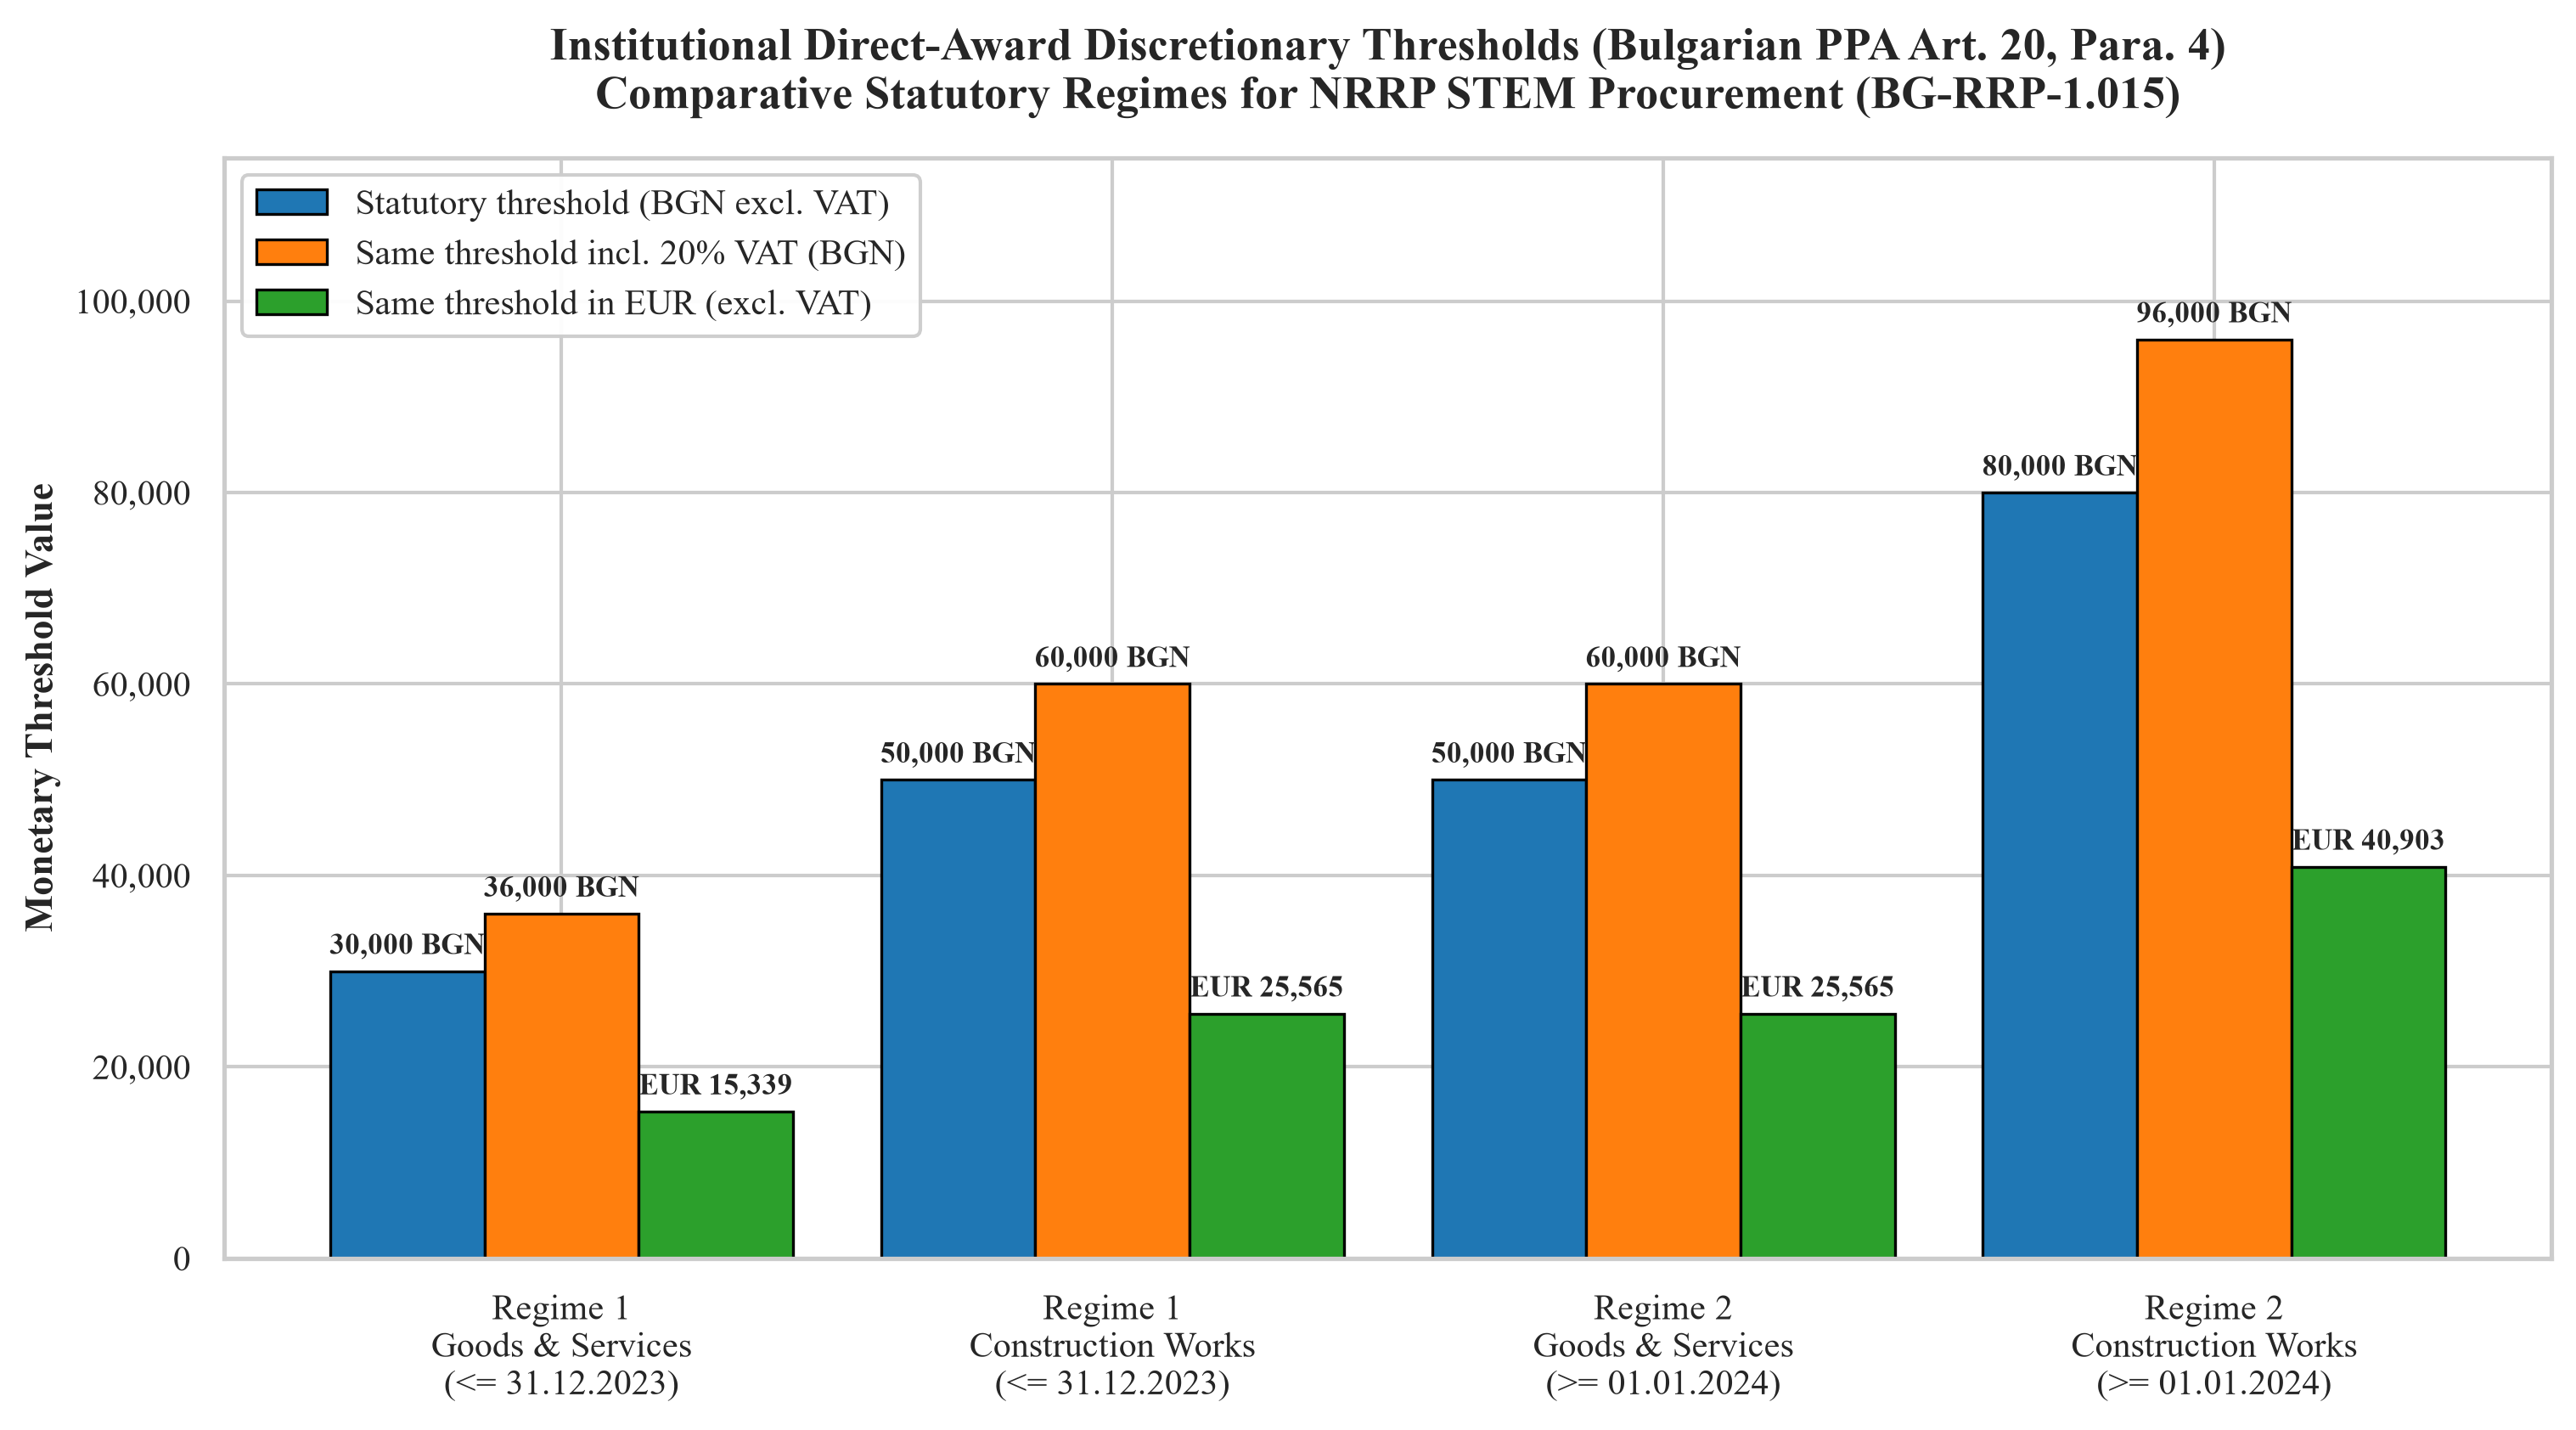

In [4]:
fig1, ax1 = plt.subplots(figsize=(10, 5.5), constrained_layout=True)

categories = [
    "Regime 1\nGoods & Services\n(<= 31.12.2023)",
    "Regime 1\nConstruction Works\n(<= 31.12.2023)",
    "Regime 2\nGoods & Services\n(>= 01.01.2024)",
    "Regime 2\nConstruction Works\n(>= 01.01.2024)",
]

net_bgn = [
    ThresholdConfig.T1_GOODS_SERVICES_NET_BGN,
    ThresholdConfig.T1_WORKS_NET_BGN,
    ThresholdConfig.T2_GOODS_SERVICES_NET_BGN,
    ThresholdConfig.T2_WORKS_NET_BGN,
]
gross_bgn = [v * (1 + ThresholdConfig.VAT_RATE) for v in net_bgn]
net_eur = [v / ThresholdConfig.EUR_BGN for v in net_bgn]

x = np.arange(len(categories))
width = 0.28

rects1 = ax1.bar(x - width, net_bgn, width, label="Statutory threshold (BGN excl. VAT)", color="#1f77b4", edgecolor="black", linewidth=0.8)
rects2 = ax1.bar(x, gross_bgn, width, label="Same threshold incl. 20% VAT (BGN)", color="#ff7f0e", edgecolor="black", linewidth=0.8)
rects3 = ax1.bar(x + width, net_eur, width, label="Same threshold in EUR (excl. VAT)", color="#2ca02c", edgecolor="black", linewidth=0.8)

ax1.set_ylabel("Monetary Threshold Value", fontweight="bold")
ax1.set_title("Institutional Direct-Award Discretionary Thresholds (Bulgarian PPA Art. 20, Para. 4)\nComparative Statutory Regimes for NRRP STEM Procurement (BG-RRP-1.015)", pad=14)
ax1.set_xticks(x)
ax1.set_xticklabels(categories, fontweight="normal")
ax1.legend(loc="upper left", frameon=True, facecolor="white", edgecolor="#cccccc", framealpha=0.95)
ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: f"{int(y):,}"))
ax1.set_ylim(0, 115000)

def autolabel(rects, is_eur=False):
    for rect in rects:
        h = rect.get_height()
        label = f"EUR {h:,.0f}" if is_eur else f"{h:,.0f} BGN"
        ax1.annotate(label,
                    xy=(rect.get_x() + rect.get_width() / 2, h),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha="center", va="bottom", fontsize=8.5, rotation=0, fontweight="bold")

autolabel(rects1)
autolabel(rects2)
autolabel(rects3, is_eur=True)

plt.show()

**Figure 3.1.** Statutory direct-award thresholds for goods and services and for construction works under the two regimes, in net BGN, with their conversions to gross BGN and net EUR.

*Source:* Bulgaria (2016, Art. 20(4)) for contracts signed up to 31 December 2023; Bulgaria (2023, Art. 20(4)) for contracts signed from 1 January 2024.

### 3.2 Excess Mass Below a Discretionary Threshold

**Question.** If a contracting authority may award directly below a threshold, do contract values accumulate just under that threshold?

**Why a density with a counterfactual.** Contract values are expected to follow a smooth distribution. A threshold is a place where the legal consequences change abruptly, so a manipulation of values appears as a break in an otherwise smooth density. Contract values are compared with the density estimated for the case without the threshold (the counterfactual), and the difference just below the threshold is the excess mass, $B = \sum_j (c_j - \hat{c}_j)$, together with the missing mass above it (Palguta and Pertold, 2017).

**How to read.** The dashed blue line is the counterfactual density $\hat{c}(z)$. The solid red line is the observed density $c(z)$ with the bunching pattern. The hatched area is the excess mass $B$. The dotted vertical line is the threshold $T = 50\,000$ BGN net, which applies to construction works before 2024 and to goods and services from 2024.

**What the figure is not.** It is a stylised illustration of the method with illustrative values, not an estimate from the contract data. A concentration below a threshold is a warning sign that calls for an explanation, not proof of a violation.

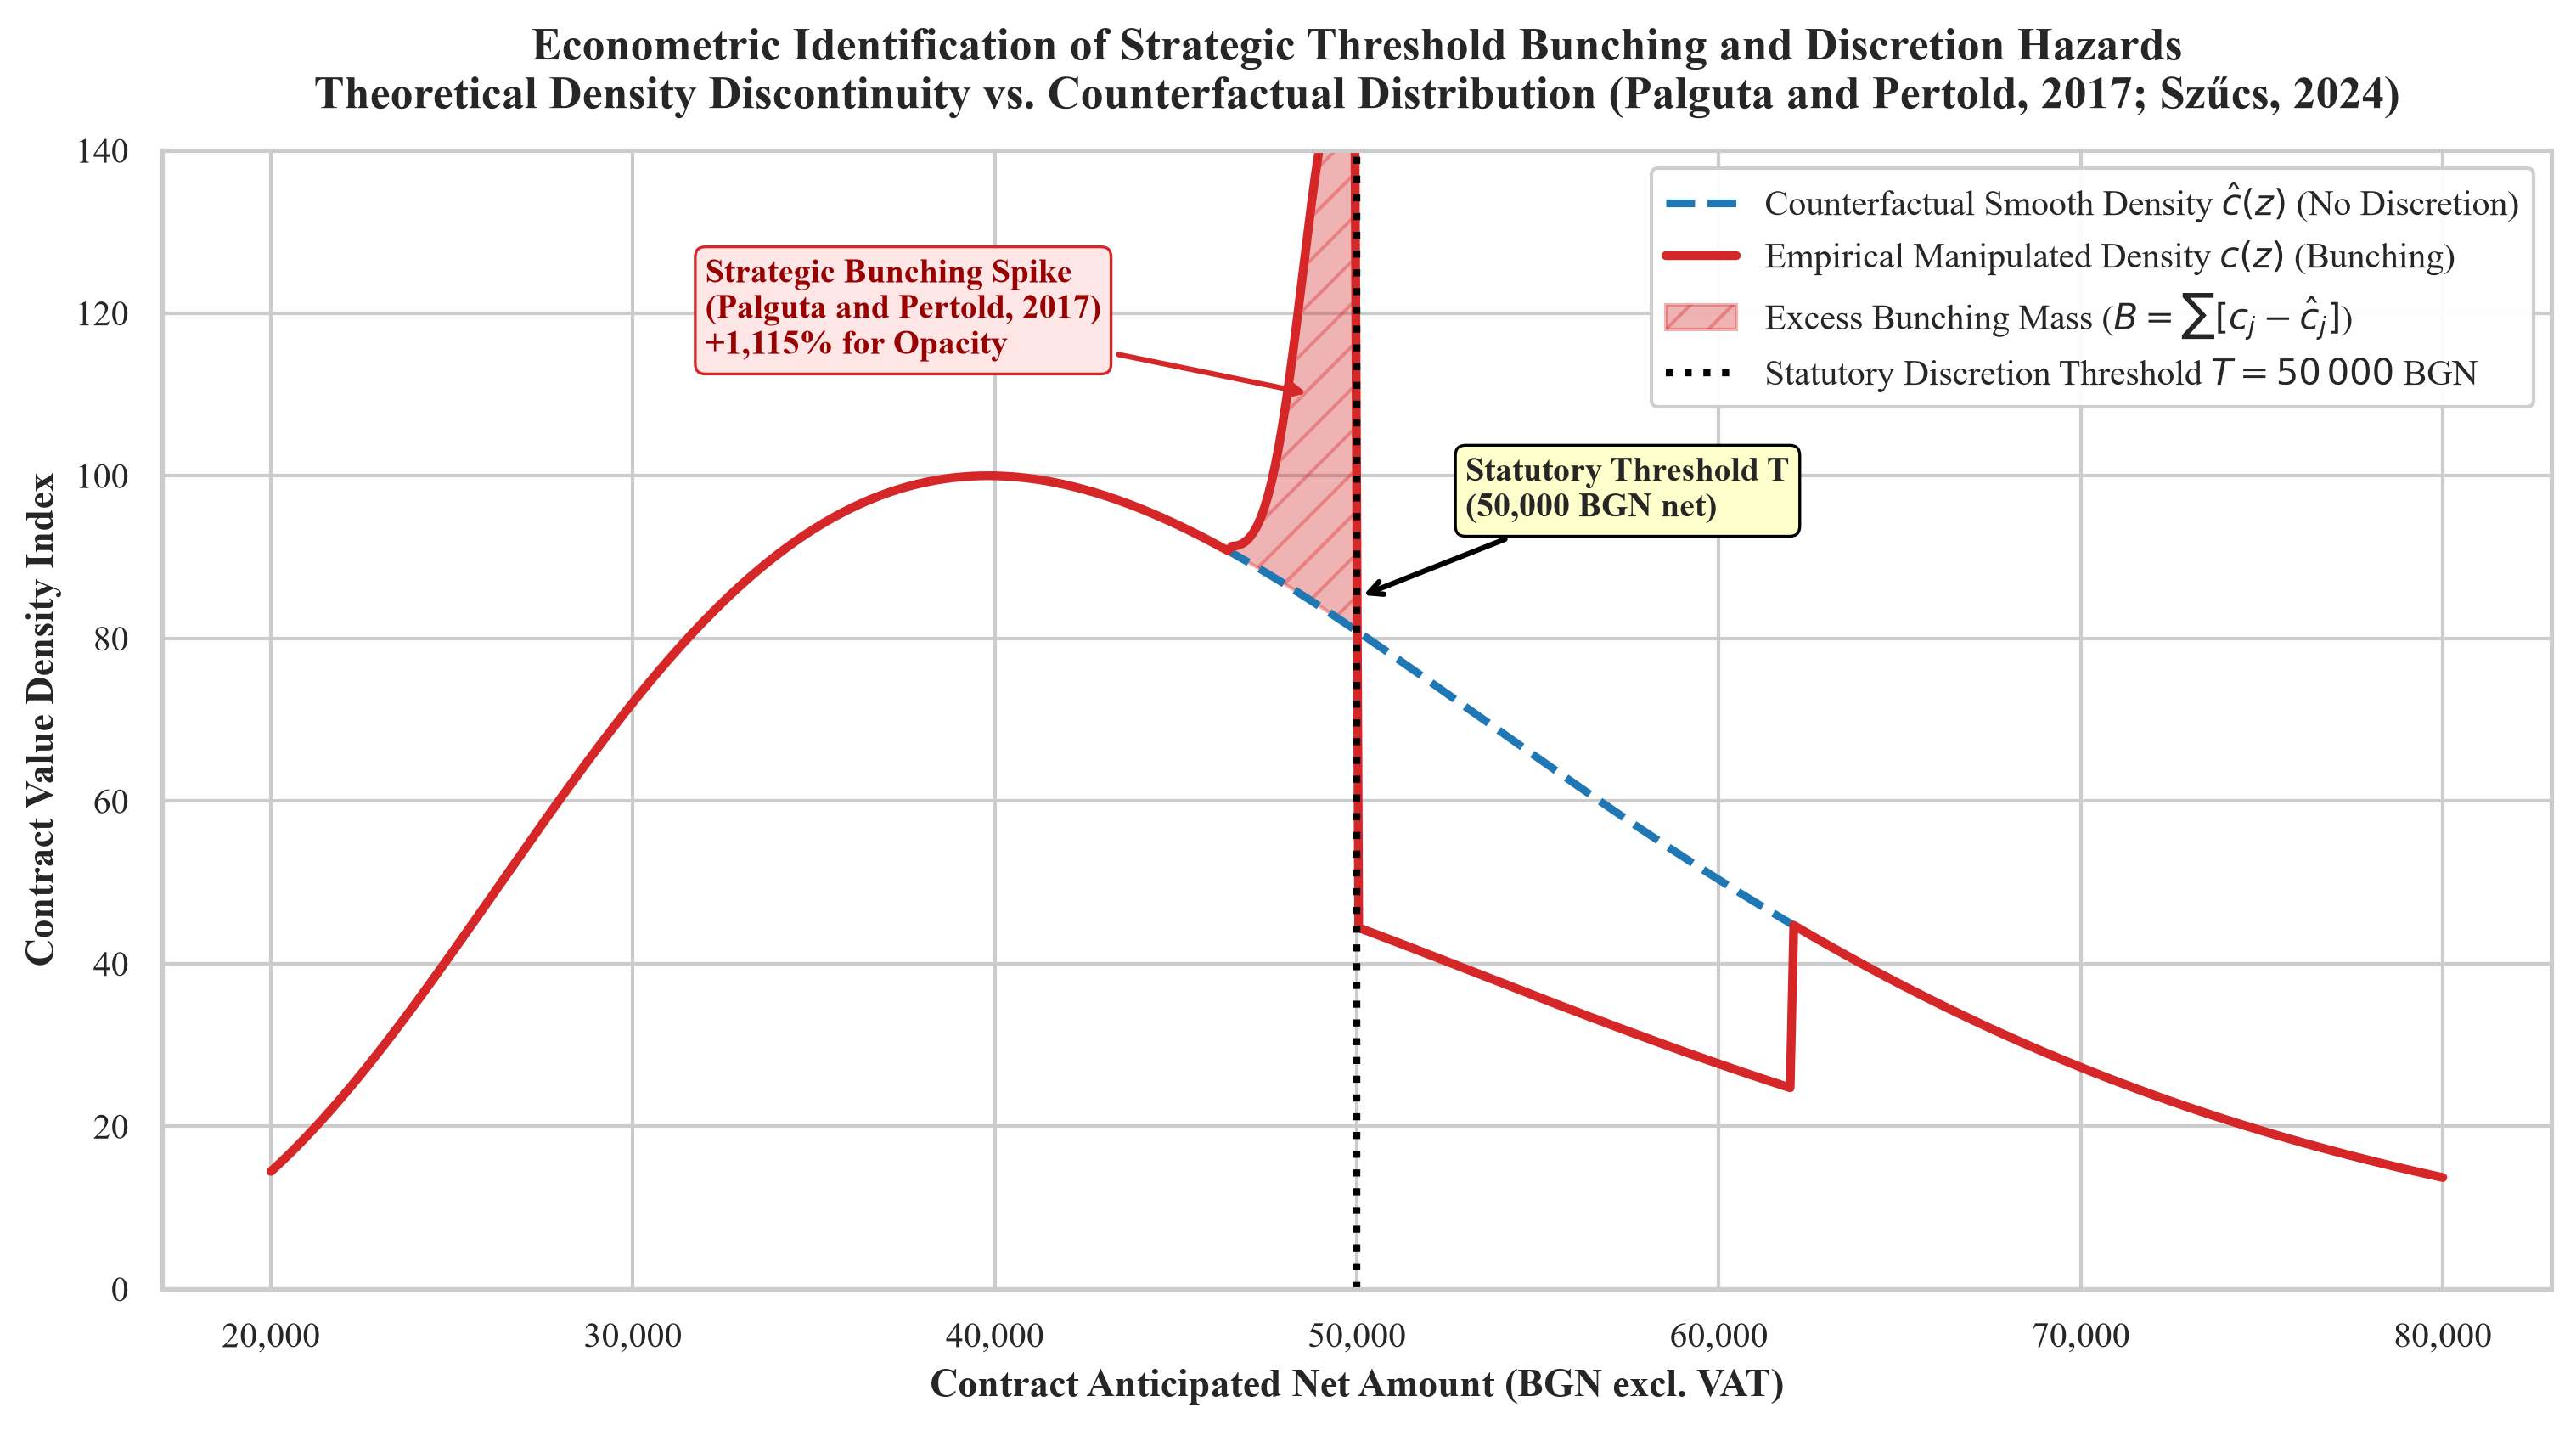

In [5]:
threshold_val = 50000.0  # Regime 1 Works / Regime 2 Goods threshold
v_axis = np.linspace(20000, 80000, 600)

# Counterfactual smooth log-normal distribution (unmanipulated market density)
mu, sigma = np.log(45000), 0.35
cf_density = (1 / (v_axis * sigma * np.sqrt(2 * np.pi))) * np.exp(-((np.log(v_axis) - mu)**2) / (2 * sigma**2))
cf_density = cf_density / np.max(cf_density) * 100.0  # Normalized index

# Empirical manipulated density with strategic bunching spike just below threshold (Palguta and Pertold, 2017)
manipulated_density = cf_density.copy()
above_mask = (v_axis >= threshold_val) & (v_axis <= threshold_val + 12000)
manipulated_density[above_mask] *= 0.55
bunch_mask = (v_axis >= threshold_val - 3500) & (v_axis < threshold_val)
manipulated_density[bunch_mask] += 65.0 * np.exp(-((v_axis[bunch_mask] - (threshold_val - 500))**2) / (2 * (1000**2)))

fig2, ax2 = plt.subplots(figsize=(10, 5.5), constrained_layout=True)

ax2.plot(v_axis, cf_density, color="#1f77b4", linestyle="--", linewidth=2.2, label=r"Counterfactual Smooth Density $\hat{c}(z)$ (No Discretion)")
ax2.plot(v_axis, manipulated_density, color="#d62728", linestyle="-", linewidth=2.5, label=r"Empirical Manipulated Density $c(z)$ (Bunching)")

ax2.fill_between(v_axis[bunch_mask], cf_density[bunch_mask], manipulated_density[bunch_mask],
                 color="#d62728", alpha=0.35, hatch="//", label=r"Excess Bunching Mass ($B = \sum [c_j - \hat{c}_j]$)")

ax2.axvline(threshold_val, color="black", linestyle=":", linewidth=2.0, label=r"Statutory Discretion Threshold $T = 50\,000$ BGN")
ax2.annotate(f"Statutory Threshold T\n({threshold_val:,.0f} BGN net)",
             xy=(threshold_val, 85), xytext=(threshold_val + 3000, 95),
             arrowprops=dict(arrowstyle="->", color="black", lw=1.5),
             fontsize=9.5, fontweight="bold", bbox=dict(boxstyle="round,pad=0.3", fc="#ffffcc", ec="black", lw=0.8))

ax2.annotate("Strategic Bunching Spike\n(Palguta and Pertold, 2017)\n+1,115% for Opacity",
             xy=(threshold_val - 1200, 110), xytext=(threshold_val - 18000, 115),
             arrowprops=dict(arrowstyle="->", color="#d62728", lw=1.5),
             fontsize=9.5, fontweight="bold", color="#990000",
             bbox=dict(boxstyle="round,pad=0.3", fc="#ffe6e6", ec="#d62728", lw=0.8))

ax2.set_xlabel("Contract Anticipated Net Amount (BGN excl. VAT)", fontweight="bold")
ax2.set_ylabel("Contract Value Density Index", fontweight="bold")
ax2.set_title("Econometric Identification of Strategic Threshold Bunching and Discretion Hazards\nTheoretical Density Discontinuity vs. Counterfactual Distribution (Palguta and Pertold, 2017; Szűcs, 2024)", pad=12)
ax2.legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.95)
ax2.set_ylim(0, 140)
ax2.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{int(x):,}"))

plt.show()

**Figure 3.2.** Stylised density of contract values around a discretionary threshold, with the counterfactual density and the excess mass below the threshold (illustrative values).

*Source:* author's illustration based on Palguta and Pertold (2017).

### 3.3 Competition Around the Threshold

**Question.** Does discretion in the award go together with less competition?

**Why a line comparison of bidder numbers.** Discretionary awards go together with fewer competing bidders (Szűcs, 2024). If the contracting authority chooses whom to invite, the average number of bidders below the threshold should be lower than an open procedure would attract at the same contract value. A line plotted against the contract value shows whether such a gap exists and whether it appears exactly at the threshold, which is what separates the effect of the rule from the effect of contract size.

**How to read.** The dashed blue line is the number of bidders expected under an open procedure. The solid green line is the number under discretion, which drops at the threshold. The dotted vertical line is the threshold, as in the previous figure. An average close to one bidder below the threshold means that a single bidder is the typical outcome there.

**What the figure is not.** It is the same kind of stylised illustration with illustrative values and does not use the contract data. The ISUN records name only the winning supplier, so the number of bidders cannot be observed in this study. The figure shows the mechanism that the threshold test of Figure 3.2 detects indirectly.

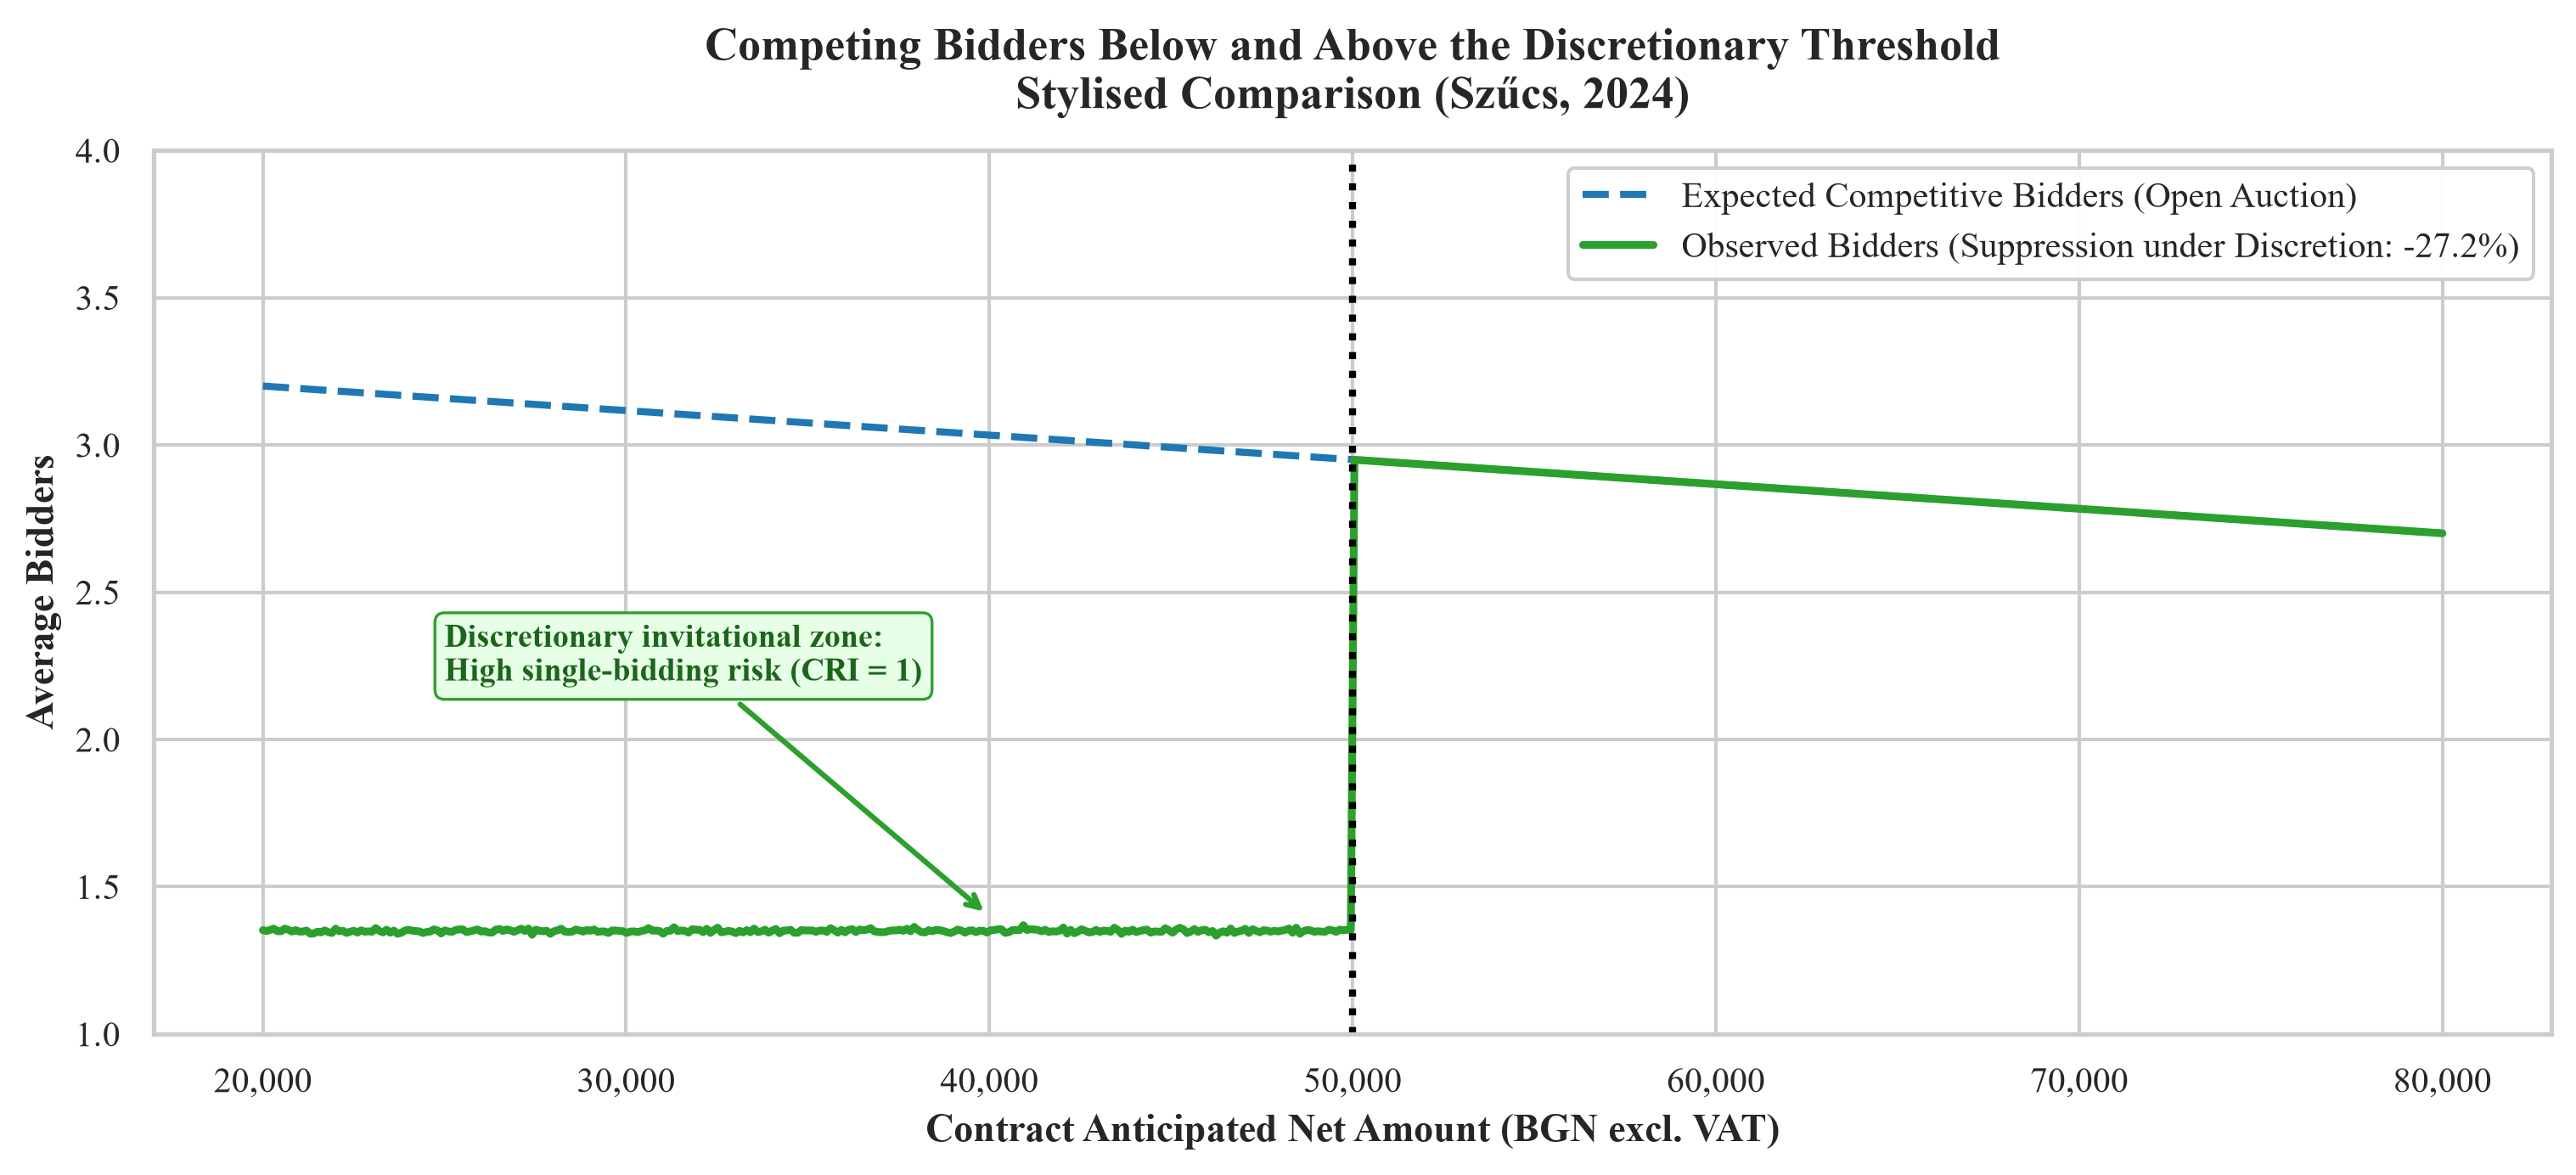

In [6]:
np.random.seed(ModelConfig.SEED)

# Number of competitive bidders (Szűcs, 2024; Palguta and Pertold, 2017)
bidders_cf = 3.2 - 0.5 * ((v_axis - 20000) / 60000)
bidders_obs = np.where(v_axis < threshold_val, 1.35 + 0.1 * np.random.normal(0, 0.05, len(v_axis)), bidders_cf)

fig3, ax3 = plt.subplots(figsize=(10, 4.5), constrained_layout=True)

ax3.plot(v_axis, bidders_cf, color="#1f77b4", linestyle="--", linewidth=2.0, label="Expected Competitive Bidders (Open Auction)")
ax3.plot(v_axis, bidders_obs, color="#2ca02c", linestyle="-", linewidth=2.2, label="Observed Bidders (Suppression under Discretion: -27.2%)")
ax3.axvline(threshold_val, color="black", linestyle=":", linewidth=2.0)

ax3.annotate("Discretionary invitational zone:\nHigh single-bidding risk (CRI = 1)",
             xy=(threshold_val - 10000, 1.4), xytext=(threshold_val - 25000, 2.2),
             arrowprops=dict(arrowstyle="->", color="#2ca02c", lw=1.5),
             fontsize=9.0, fontweight="bold", color="#1b661b",
             bbox=dict(boxstyle="round,pad=0.3", fc="#e6ffe6", ec="#2ca02c", lw=0.8))

ax3.set_xlabel("Contract Anticipated Net Amount (BGN excl. VAT)", fontweight="bold")
ax3.set_ylabel("Average Bidders", fontweight="bold")
ax3.set_title("Competing Bidders Below and Above the Discretionary Threshold\nStylised Comparison (Szűcs, 2024)", pad=12)
ax3.set_ylim(1.0, 4.0)
ax3.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax3.legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.95)

plt.show()

**Figure 3.3.** Stylised average number of competing bidders below and above a discretionary threshold (illustrative values).

*Source:* author's illustration based on Szűcs (2024).

## 4. Problem Formulation and Hypotheses

### 4.1 Institutional Setting and Four-Level Framework

Procedure BG-RRP-1.015 was carried out in a decentralised way. Each of the 2,228 projects was implemented by a school that acted as its own contracting authority under the Public Procurement Act, and the 11,128 contracts were awarded by many small buyers. Schools are not specialised in procurement, so the study asks whether outside actors shape which suppliers they choose. The framework below structures this question into four levels. Levels 2 and 3 are hypotheses that are tested for compatibility with the data. Levels 1 and 4 describe the funding and the available records.

1. **Funding and contracting authority.** Funds of the Recovery and Resilience Plan are coordinated by the Ministry of Education and Science and reach the schools, which award the contracts.
2. **Local and regional influence (hypothesis).** The 28 regional education directorates and the municipal authorities stand in a relation of administrative dependence to school principals. The hypothesis is that this relation is visible in the choice of suppliers within a region or a municipality.
3. **Supplier groups (hypothesis).** Consulting firms ($V_{\text{cons}}$) that prepare projects, suppliers of equipment ($V_{\text{tech}}$) and construction contractors ($V_{\text{civil}}$) may appear together at the same schools. The hypothesis is that consultancy contracts are signed before the supply and works contracts and are associated with the same suppliers.
4. **Audit record.** The records of ISUN 2020 and the audit reports of the State Financial Inspection Agency (ADFI) allow the risk indicators to be compared with the outcome of inspections, for example with penalty acts (*АУАН*) issued to school officials.

A statistical anomaly or a risk indicator is not evidence of a violation.

```mermaid
flowchart TD
    subgraph L1["1. Funding and contracting authority"]
        EU["Recovery and Resilience Plan funds"]
        MON["Ministry of Education and Science<br/>(coordinator)"]
        Schools["Schools<br/>(contracting authorities under the Public Procurement Act)"]
        EU --> MON --> Schools
    end
    subgraph L2["2. Local and regional influence (hypothesis)"]
        RUO["Regional education directorates<br/>(28 regions)"]
        Mayors["Municipal authorities"]
    end
    subgraph L3["3. Supplier groups (hypothesis)"]
        Consultants["Consulting firms V_cons<br/>(project preparation)"]
        Vendors["Equipment suppliers V_tech<br/>Construction contractors V_civil"]
    end
    subgraph L4["4. Audit record (data)"]
        ISUN["ISUN 2020 records<br/>(2,228 projects, 11,128 contracts)"]
        ADFI["ADFI audit reports<br/>(penalty acts to school officials)"]
    end
    RUO -->|administrative dependence| Schools
    Mayors -->|administrative dependence| Schools
    Consultants <-->|possible contact| RUO
    Consultants <-->|possible contact| Mayors
    Consultants <-->|shared suppliers, lift above 1| Vendors
    Consultants -->|contract dated before the supply contract| Schools
    Vendors -->|supply and works contracts| Schools
    Schools -.->|recorded in| ISUN
    Schools -.->|inspected in| ADFI
```

**Figure 4.1.** Four-level framework of the procedure. Levels 2 and 3 are hypotheses of this study, levels 1 and 4 describe funding and records.

*Source:* author's conceptual model.

### 4.2 Four Testable Hypotheses

Each hypothesis is stated so that the data can contradict it.

- **$H_1$ (degree confounding or turnkey groups).** In an uncorrected projection of the buyer-supplier network, suppliers with many buyers share buyers more often than chance implies, because the degrees differ. Under the bipartite configuration model, which fixes the degrees of buyers and suppliers (Saracco et al., 2017), $H_1$ asks whether this effect disappears and whether groups of suppliers remain whose overlap is statistically validated (Tumminello et al., 2011).
- **$H_2$ (consultant-steered bundling).** Contracts of consulting firms precede supply and works contracts at the same school ($t_{\text{cons}} \le t_{\text{supply}}$), and consulting firms and suppliers share schools more often than expected (lift well above 1; Coscia and Neffke, 2017).
- **$H_3$ (regional and municipal concentration).** Validated supplier groups and risk indicators are concentrated across regions and municipalities more than a stratified permutation null model implies (Wachs et al., 2021). The test separates the municipal level from the regional level.
- **$H_4$ (threshold bunching, contracts signed before the project start, and audit outcomes).** (a) Contract values accumulate just below the direct-award thresholds, 30,000 and 50,000 BGN before 2024 and 50,000 and 80,000 BGN from 2024 (Palguta and Pertold, 2017; Szűcs, 2024; Bulgaria, 2016; Bulgaria, 2023). (b) A contract signed before the start date of its project, as recorded in ISUN 2020, is a risk indicator. (c) These indicators are more frequent at schools whose ADFI audit led to a penalty act.

## 5. Mathematical Theory and Propositions

### 5.1 Bipartite Representation and Projection

Let $B = (U, V, E, W)$ be a weighted bipartite graph. $U = \{u_1, \dots, u_{N_U}\}$ is the set of $N_U = 2\,228$ schools and $V = \{v_1, \dots, v_{N_V}\}$ is the set of $N_V = 1\,755$ suppliers, which are divided into three functional subsets:
$$V = V_{\text{cons}} \cup V_{\text{tech}} \cup V_{\text{civil}}$$
The incidence matrix is $B \in \{0, 1\}^{N_U \times N_V}$ with elements $b_{i\alpha} \in \{0, 1\}$. The degrees are
$$k_i = \sum_{\alpha \in V} b_{i\alpha} \quad (\text{contract degree of school } i), \qquad d_\alpha = \sum_{i \in U} b_{i\alpha} \quad (\text{market degree of supplier } \alpha).$$
The one-mode projection onto suppliers is the Gram matrix of co-occurrence counts:
$$O = B^{T} B \in \mathbb{N}^{N_V \times N_V}, \qquad O_{\alpha\beta} = \sum_{i \in U} b_{i\alpha} b_{i\beta}.$$

### 5.2 Statistical Filtering and Null Models

**1. Hypergeometric null model (Tumminello et al., 2011).** If the buyers of two suppliers are drawn at random given the degrees $d_\alpha$ and $d_\beta$, the probability of at least $O_{\alpha\beta}$ shared schools is
$$P_{\text{Hyp}}(X \ge O_{\alpha\beta} \mid N_U, d_\alpha, d_\beta) = \sum_{k = O_{\alpha\beta}}^{\min(d_\alpha, d_\beta)} \frac{\binom{d_\alpha}{k} \binom{N_U - d_\alpha}{d_\beta - k}}{\binom{N_U}{d_\beta}}.$$
The $M = \binom{N_V}{2}$ pair tests are corrected with the Benjamini–Hochberg procedure at the level $\alpha_{\text{FDR}} = 0.01$ (Tumminello et al., 2011; Saracco et al., 2017).

**2. Bipartite configuration model, BiCM (Saracco et al., 2017).** The ensemble that maximises the Shannon entropy while it reproduces the degree sequences of both sets of nodes has the Hamiltonian
$$\mathcal{H}(B) = \sum_{i \in U} \theta_i k_i(B) + \sum_{\alpha \in V} \mu_\alpha d_\alpha(B)$$
and the independent connection probabilities
$$p_{i\alpha} = \frac{x_i y_\alpha}{1 + x_i y_\alpha}, \qquad x_i = e^{-\theta_i}, \quad y_\alpha = e^{-\mu_\alpha}.$$
The parameters $\vec{x}, \vec{y}$ solve the $N_U + N_V$ coupled equations
$$\sum_{\alpha \in V} \frac{x_i y_\alpha}{1 + x_i y_\alpha} = k_i \;\; \forall i \in U, \qquad \sum_{i \in U} \frac{x_i y_\alpha}{1 + x_i y_\alpha} = d_\alpha \;\; \forall \alpha \in V.$$
The co-occurrence $V_{\alpha\beta} = \sum_i b_{i\alpha} b_{i\beta}$ is a sum of independent Bernoulli variables with parameters $\pi_{i} = p_{i\alpha} p_{i\beta}$, so it follows a Poisson-binomial distribution. Its survival function is evaluated exactly with the discrete Fourier transform of the characteristic function,
$$\phi_{\alpha\beta}(t) = \prod_{i=1}^{N_U} \left[ (1 - \pi_i) + \pi_i e^{\mathrm{i} t} \right], \qquad t_l = \frac{2\pi l}{N_U + 1}, \; l = 0, \dots, N_U.$$
The Poisson approximation is acceptable only when Le Cam's inequality gives a small bound (Saracco et al., 2017):
$$\sum_{k} \left| f_{\text{PB}}(k) - f_{\text{Poisson}}(k) \right| < 2 \sum_{i=1}^{N_U} \pi_i^2.$$

**3. Disparity filter on the co-occurrence counts (the baseline described by Coscia and Neffke, 2017).**
$$\alpha_{\alpha\beta} = \left( 1 - \frac{O_{\alpha\beta}}{s_\alpha} \right)^{k_\alpha - 1}, \qquad s_\alpha = \sum_{\beta \ne \alpha} O_{\alpha\beta}, \qquad k_\alpha = \left| \{ \beta \ne \alpha : O_{\alpha\beta} > 0 \} \right|.$$
A link is kept if $\min(\alpha_{\alpha\beta}, \alpha_{\beta\alpha}) < \alpha_{\text{DF}}$.

**4. Noise-corrected backbone (Coscia and Neffke, 2017).** For the weights $N_{ij} = O_{ij}$ with strengths $N_{i\cdot} = \sum_{j \ne i} O_{ij}$, $N_{\cdot j} = \sum_{i \ne j} O_{ij}$ and total $N_{\cdot\cdot} = \sum_i N_{i\cdot}$, the expected weight, the transformed lift and its variance by the delta method are
$$\mathbb{E}[N_{ij}] = \frac{N_{i\cdot} N_{\cdot j}}{N_{\cdot\cdot}}, \qquad \kappa = \frac{N_{\cdot\cdot}}{N_{i\cdot} N_{\cdot j}}, \qquad \tilde{L}_{ij} = \frac{\kappa N_{ij} - 1}{\kappa N_{ij} + 1},$$
$$\mathbb{V}[\tilde{L}_{ij}] = \mathbb{V}[N_{ij}] \left( \frac{2 \left( \kappa + N_{ij} \frac{d\kappa}{dN_{ij}} \right)}{(\kappa N_{ij} + 1)^2} \right)^2, \qquad \frac{d\kappa}{dN_{ij}} = \frac{1}{N_{i\cdot} N_{\cdot j}} - \frac{N_{\cdot\cdot} (N_{i\cdot} + N_{\cdot j})}{(N_{i\cdot} N_{\cdot j})^2}.$$
The variance is $\mathbb{V}[N_{ij}] = N_{\cdot\cdot} P_{ij} (1 - P_{ij})$ with $P_{ij} \sim \text{Beta}(N_{ij} + \alpha, N_{\cdot\cdot} - N_{ij} + \beta)$. The prior is fitted to the hypergeometric moments,
$$\mu = \frac{N_{i\cdot} N_{\cdot j}}{N_{\cdot\cdot}^2}, \quad \sigma^2 = \frac{N_{i\cdot} N_{\cdot j} (N_{\cdot\cdot} - N_{i\cdot}) (N_{\cdot\cdot} - N_{\cdot j})}{N_{\cdot\cdot}^4 (N_{\cdot\cdot} - 1)}, \quad \alpha = \frac{\mu^2}{\sigma^2} (1 - \mu) - \mu, \quad \beta = \mu \left( \frac{(1 - \mu)^2}{\sigma^2} + 1 \right) - 1,$$
and the posterior mean $\mathbb{E}[P_{ij}] = (N_{ij} + \alpha) / (N_{\cdot\cdot} + \alpha + \beta)$ is used. A link is kept if $\tilde{L}_{ij} > \delta \sqrt{\mathbb{V}[\tilde{L}_{ij}]}$, where $\delta = 2.32$ corresponds to $p \approx 0.01$.

**5. Lift for directed association (Coscia and Neffke, 2017).** For a consulting firm $\alpha$ and a supplier $\beta$,
$$\text{Lift}(\alpha, \beta) = \frac{P(\alpha \cap \beta)}{P(\alpha) P(\beta)} = \frac{M_{\text{steer}}(\alpha, \beta) \, N_U}{d_\alpha d_\beta},$$
where $M_{\text{steer}}(\alpha, \beta)$ is the number of schools at which both firms appear and the contract of $\alpha$ is dated no later than the contract of $\beta$.

**6. Modularity and communities (Wachs et al., 2021).** With the validated adjacency matrix $A^{\text{val}}$, total weight $2m$ and resolution $\gamma$,
$$Q = \frac{1}{2m} \sum_{\alpha, \beta} \left[ A^{\text{val}}_{\alpha\beta} - \gamma \frac{d^{\text{val}}_\alpha d^{\text{val}}_\beta}{2m} \right] \delta(c_\alpha, c_\beta).$$

**7. Coherence and exclusivity of a group $G$ (Wachs and Kertész, 2019).** With $l_G$ the set of internal links of $G$ with $O_{\alpha\beta} > 0$ and $m_G = |l_G|$,
$$C_G = \frac{\left( \prod_{l \in l_G} O_l \right)^{1 / m_G}}{\frac{1}{m_G} \sum_{l \in l_G} O_l}, \qquad E_G = \frac{s_{\text{in}}^G}{s_{\text{in}}^G + s_{\text{out}}^G},$$
$$s_{\text{in}}^G = \sum_{\alpha < \beta \in G} O_{\alpha\beta}, \qquad s_{\text{out}}^G = \sum_{\alpha \in G} \sum_{\gamma \notin G} O_{\alpha\gamma}.$$
Both lie in $[0, 1]$. A group with $C_G$ near 1 has uniform internal ties, and a group with $E_G$ near 1 has almost no ties to the rest of the market.

**8. Stratified permutation null model (after Wachs et al., 2021).** Wachs et al. (2021) shuffle the flags within sectors. Here the labels are permuted within regions, so the test statistic $\Delta T$ is compared with its permutation distribution at equal regional composition:
$$p_{\text{strat}} = \frac{1 + \sum_{\pi=1}^{K} \mathbb{I}\left[ \Delta T^{(\pi)} \ge \Delta T^{\text{obs}} \right]}{K + 1}.$$

**9. Weighted $k$-shell decomposition (Wachs et al., 2021).** Nodes are removed iteratively by their strength $s_\alpha = \sum_i W_{i\alpha}$, the total contracted value, which gives the core-periphery position of a supplier without a bias towards the degree.

### 5.3 Indicators on Contract Values

**10. Bunching below a threshold (Palguta and Pertold, 2017; Szűcs, 2024).** The number of contracts $Y_{zt}$ in the value bin $z$ and period $t$ is modelled by Poisson quasi-maximum likelihood with
$$\mathbb{E}[Y_{zt}] = \exp\left( \alpha_z + \alpha_t + \beta_1 \, \text{Below}_z \times \text{Regime2}_t \right), \qquad \%\Delta = \left[ \exp(\beta_1) - 1 \right] \times 100\%,$$
where $\text{Below}_z$ marks the bins just below a threshold and $\text{Regime2}_t$ the period from 1 January 2024. With a counterfactual density $\hat{h}$ and the observed counts $C_j$, the excess mass below the threshold $T$ and the missing mass above it are
$$B = \sum_{j \in [T - \delta, T)} \left( C_j - \hat{h}(z_j) \right), \qquad M_{\text{missing}} = \sum_{j \in [T, T + \delta)} \left( \hat{h}(z_j) - C_j \right).$$

**11. Benford deviation of the spacings (Miller and Nigrini, 2006).** For the normalised spacings $Z$ of the ordered contract values and the mantissas $Y = \log_{10} Z \bmod 1$ with empirical distribution function $F_N$,
$$D_{\text{Benford}} = \sup_{b \in [0, 1)} \left| F_N(b) - b \right|.$$

**12. Same-day splitting index (operationalising the red flag in OECD, 2016).** For the set of contracts $\text{Contracts}(i, t)$ of buyer $i$ with one supplier on day $t$ and the threshold $T$,
$$S_{\text{same-day}}(i, t) = \sum_{k \in \text{Contracts}(i, t)} \mathbb{I}\left[ \text{Value}_k < T \right] \cdot \mathbb{I}\left[ \sum_{k} \text{Value}_k \ge T \right].$$
It counts the contracts below $T$ in a same-day set whose total reaches $T$.

**13. Enrichment of contracts signed before the project start (hypergeometric test after Tumminello et al., 2011).** Among $N_{\text{total}}$ contracts, $K_{\text{predated}}$ are signed before the start date of the project ($\Delta t < 0$). Supplier $\alpha$ has $n_\alpha$ contracts, $k_\alpha$ of them signed before the start, and
$$p_\alpha^{\Delta t} = \sum_{x = k_\alpha}^{\min(n_\alpha, K_{\text{predated}})} \frac{\binom{K_{\text{predated}}}{x} \binom{N_{\text{total}} - K_{\text{predated}}}{n_\alpha - x}}{\binom{N_{\text{total}}}{n_\alpha}}.$$

### 5.4 Propositions

#### Proposition 1: Degree Confounding in Uncorrected Projections

**Statement.** *Assume a sparse regime with $p_{i\alpha} \approx x_i y_\alpha \ll 1$. The expected co-occurrence of two suppliers then satisfies*
$$\mathbb{E}[O_{\alpha\beta}] = \sum_{i \in U} p_{i\alpha} p_{i\beta} \approx y_\alpha y_\beta \sum_{i \in U} x_i^2 = \frac{d_\alpha d_\beta}{N_U} \left( 1 + \frac{\mathrm{Var}(x)}{\bar{x}^2} \right) \ge \frac{d_\alpha d_\beta}{N_U},$$
*with strict inequality whenever the school propensities $x_i$ differ.*

**Proof.**
1. In the sparse regime $p_{i\alpha} = \dfrac{x_i y_\alpha}{1 + x_i y_\alpha} \approx x_i y_\alpha$.
2. The expected degree of supplier $\alpha$ is $d_\alpha = \sum_i p_{i\alpha} \approx y_\alpha \sum_i x_i$, so $y_\alpha \approx d_\alpha / \sum_i x_i$.
3. The expected co-occurrence is $\sum_i p_{i\alpha} p_{i\beta} \approx y_\alpha y_\beta \sum_i x_i^2$.
4. Substituting $y_\alpha$ and $y_\beta$ gives
$$\mathbb{E}[O_{\alpha\beta}] \approx \frac{d_\alpha d_\beta}{N_U} \cdot \frac{\frac{1}{N_U} \sum_i x_i^2}{\left( \frac{1}{N_U} \sum_i x_i \right)^2} = \frac{d_\alpha d_\beta}{N_U} \left( 1 + \frac{\mathrm{Var}(x)}{\bar{x}^2} \right).$$
5. By the Cauchy–Schwarz inequality, $\left( \sum_i x_i \right)^2 \le N_U \sum_i x_i^2$, with equality if and only if all $x_i$ are equal. Hence $\mathrm{Var}(x) \ge 0$ and the factor in step 4 is at least 1. $\blacksquare$

**Consequence.** The urn expectation $d_\alpha d_\beta / N_U$ underestimates the expected overlap when schools differ in activity. Two suppliers with many contracts therefore share schools more often than the urn model predicts, without any coordination. The bipartite configuration model corrects for this.

#### Theorem 1: False Discovery Control of the Benjamini–Hochberg Procedure

**Statement.** *Let $p_{(1)} \le \dots \le p_{(M)}$ be the sorted $p$-values of $M$ hypotheses, of which $m_0$ are true nulls, and let*
$$k^* = \max \left\{ k : p_{(k)} \le \frac{k}{M} \alpha \right\}.$$
*If the hypotheses $H_{(1)}, \dots, H_{(k^*)}$ are rejected and the $p$-values of the true nulls are independent, then*
$$\mathbb{E}[\mathrm{FDP}] = \mathbb{E}\left[ \frac{V}{\max(R, 1)} \right] = \frac{m_0}{M} \alpha \le \alpha,$$
*where $V$ is the number of false rejections and $R = k^*$ the number of all rejections.*

This is the procedure that Tumminello et al. (2011) and Saracco et al. (2017) apply to the pair tests. The pair hypotheses are not independent (Saracco et al., 2017), so the bound is an assumption for the network tests. The Bonferroni level $\alpha / M$ is reported as the conservative alternative (Tumminello et al., 2011). Section 6.2 checks the statement by simulation.

#### Proposition 2: Identification of Bunching and Missing Mass

**Statement.** *Let $f(z)$ be the density of contract values and $T$ a threshold below which the buyer may award directly. Let $h(z)$ be the counterfactual density without discretion, which is smooth on $[T - \delta, T + \delta]$. The excess mass $B$ and the missing mass $M_{\text{missing}}$,*
$$B = \int_{T - \delta}^{T} \left[ f(z) - h(z) \right] dz, \qquad M_{\text{missing}} = \int_{T}^{T + \delta} \left[ h(z) - f(z) \right] dz,$$
*are identified by fitting $h$ to the bins outside the manipulation window (Palguta and Pertold, 2017; Szűcs, 2024).* If contracts only move from just above to just below the threshold, $B = M_{\text{missing}}$. Section 6.7 checks that the estimator recovers a known shift.

#### Theorem 2: Spacings of Ordered Values and Benford's Law

**Statement (Miller and Nigrini, 2006).**
1. *A sequence is Benford in base $B$ if and only if its base-$B$ logarithms are equidistributed modulo 1.*
2. *If $X_1, \dots, X_N$ are drawn from the uniform distribution on $[0, L]$, the normalised spacings $Z_i = (X_{i+1:N} - X_{i:N}) / (L / N)$ converge to independent standard exponential variables as $N \to \infty$.*
3. *The digits of a standard exponential variable are very close to Benford's law. Miller and Nigrini give the maximum discrepancy as lying between $0.029$ and $0.030$.*

**Proof sketch of part 3.** The distribution function of $\log_B \zeta \bmod 1$ for $\zeta \sim \text{Exp}(1)$ is $F_B(b) = \sum_{k \in \mathbb{Z}} \left( e^{-B^k} - e^{-B^{b+k}} \right)$. Poisson summation gives the density
$$F'_B(b) = 1 + 2 \sum_{m=1}^{\infty} \mathrm{Re}\left( e^{-2\pi \mathrm{i} m b} \, \Gamma\left( 1 + \frac{2\pi \mathrm{i} m}{\ln B} \right) \right).$$
Since $|\Gamma(1 + \mathrm{i}x)|^2 = \pi x / \sinh(\pi x)$, the harmonics decay exponentially. For $B = 10$ the first harmonic has amplitude $r_1 \approx 0.0570$ and the second $r_2 \approx 0.0011$, which bounds the deviation from a uniform mantissa. $\blacksquare$

**Use.** A departure of the digits of the spacings from this pattern is a signal that the values are rounded or otherwise regular. It is a risk indicator, not proof of manipulation. Section 6.6 evaluates the series numerically.

## 6. Numerical Verification of the Propositions

Each proposition and method of Section 5 is checked on simulated data with a known structure. The checks do not use the contract data. They show that the code of the later steps reproduces the stated properties, and each ends with an assertion.

### 6.1 Degree Confounding (Proposition 1)

**Question.** Do two suppliers share more schools than the urn expectation $d_\alpha d_\beta / N_U$ when schools differ in activity?

**Why two panels.** Panel A compares the two expected overlaps pair by pair against the product of the supplier degrees. Panel B shows their ratio, which Proposition 1 puts at about $1 + \mathrm{Var}(x)/\bar{x}^2$.

**How to read.** Points above the dashed line in panel A, and above 1 in panel B, are pairs whose BiCM expectation exceeds the urn expectation.

**What the figure is not.** It is a simulation with heavy-tailed propensities of 500 schools and 200 suppliers, not an estimate from the contract data.

In [7]:
def verify_proposition_1(
    num_schools: int = 500,
    num_vendors: int = 200,
    alpha_school: float = 2.2,
    alpha_vendor: float = 1.8,
    seed: int = ModelConfig.SEED,
) -> dict[str, float | bool | np.ndarray]:
    """Compare the BiCM expected co-occurrence with the urn expectation d_a * d_b / N_U.

    With heterogeneous school propensities x_i, the expected co-occurrence
    sum_i p_ia * p_ib exceeds d_a * d_b / N_U (Saracco et al., 2017).
    """
    rng = np.random.default_rng(seed)

    # Heavy-tailed propensities of schools and suppliers
    school_propensity = rng.pareto(a=alpha_school, size=num_schools) + 1.0
    vendor_propensity = rng.pareto(a=alpha_vendor, size=num_vendors) + 1.0
    scale = 0.04 / np.sqrt(np.mean(school_propensity) * np.mean(vendor_propensity))
    x = school_propensity * scale
    y = vendor_propensity * scale

    # BiCM connection probabilities p_ia = x_i y_a / (1 + x_i y_a)
    outer_xy = np.outer(x, y)
    p = outer_xy / (1.0 + outer_xy)
    vendor_degree = p.sum(axis=0)

    expected_bicm = p.T @ p
    expected_urn = np.outer(vendor_degree, vendor_degree) / num_schools

    # Cauchy-Schwarz: sum(x^2) >= (sum x)^2 / N_U
    sum_x_sq = float(np.sum(x**2))
    cs_rhs = float(np.sum(x) ** 2 / num_schools)
    inflation_factor = 1.0 + float(np.var(x) / np.mean(x) ** 2)

    off_diagonal = ~np.eye(num_vendors, dtype=bool)
    ratio = expected_bicm[off_diagonal] / expected_urn[off_diagonal]

    assert sum_x_sq >= cs_rhs, "Cauchy-Schwarz inequality violated."
    assert np.all(ratio >= 1.0 - 1e-9), "Urn expectation exceeds the BiCM expectation for some pair."

    return {
        "num_schools": num_schools,
        "num_vendors": num_vendors,
        "sum_x_sq": sum_x_sq,
        "cs_rhs": cs_rhs,
        "cs_gap": sum_x_sq - cs_rhs,
        "inflation_factor": inflation_factor,
        "mean_ratio": float(np.mean(ratio)),
        "min_ratio": float(np.min(ratio)),
        "vendor_degree": vendor_degree,
        "expected_bicm": expected_bicm,
        "expected_urn": expected_urn,
    }


res_p1 = verify_proposition_1()
print(f"Schools: {res_p1['num_schools']} | Suppliers: {res_p1['num_vendors']}")
print(f"Sum of x_i^2:                      {res_p1['sum_x_sq']:.6f}")
print(f"(Sum of x_i)^2 / N_U:              {res_p1['cs_rhs']:.6f}")
print(f"Cauchy-Schwarz gap:                {res_p1['cs_gap']:.6f}")
print(f"Factor 1 + Var(x) / mean(x)^2:     {res_p1['inflation_factor']:.3f}")
print(f"Mean ratio BiCM / urn expectation: {res_p1['mean_ratio']:.3f}")
print(f"Minimum ratio over all pairs:      {res_p1['min_ratio']:.3f}")

Schools: 500 | Suppliers: 200
Sum of x_i^2:                      1.017613
(Sum of x_i)^2 / N_U:              0.638078
Cauchy-Schwarz gap:                0.379535
Factor 1 + Var(x) / mean(x)^2:     1.595
Mean ratio BiCM / urn expectation: 1.586
Minimum ratio over all pairs:      1.545


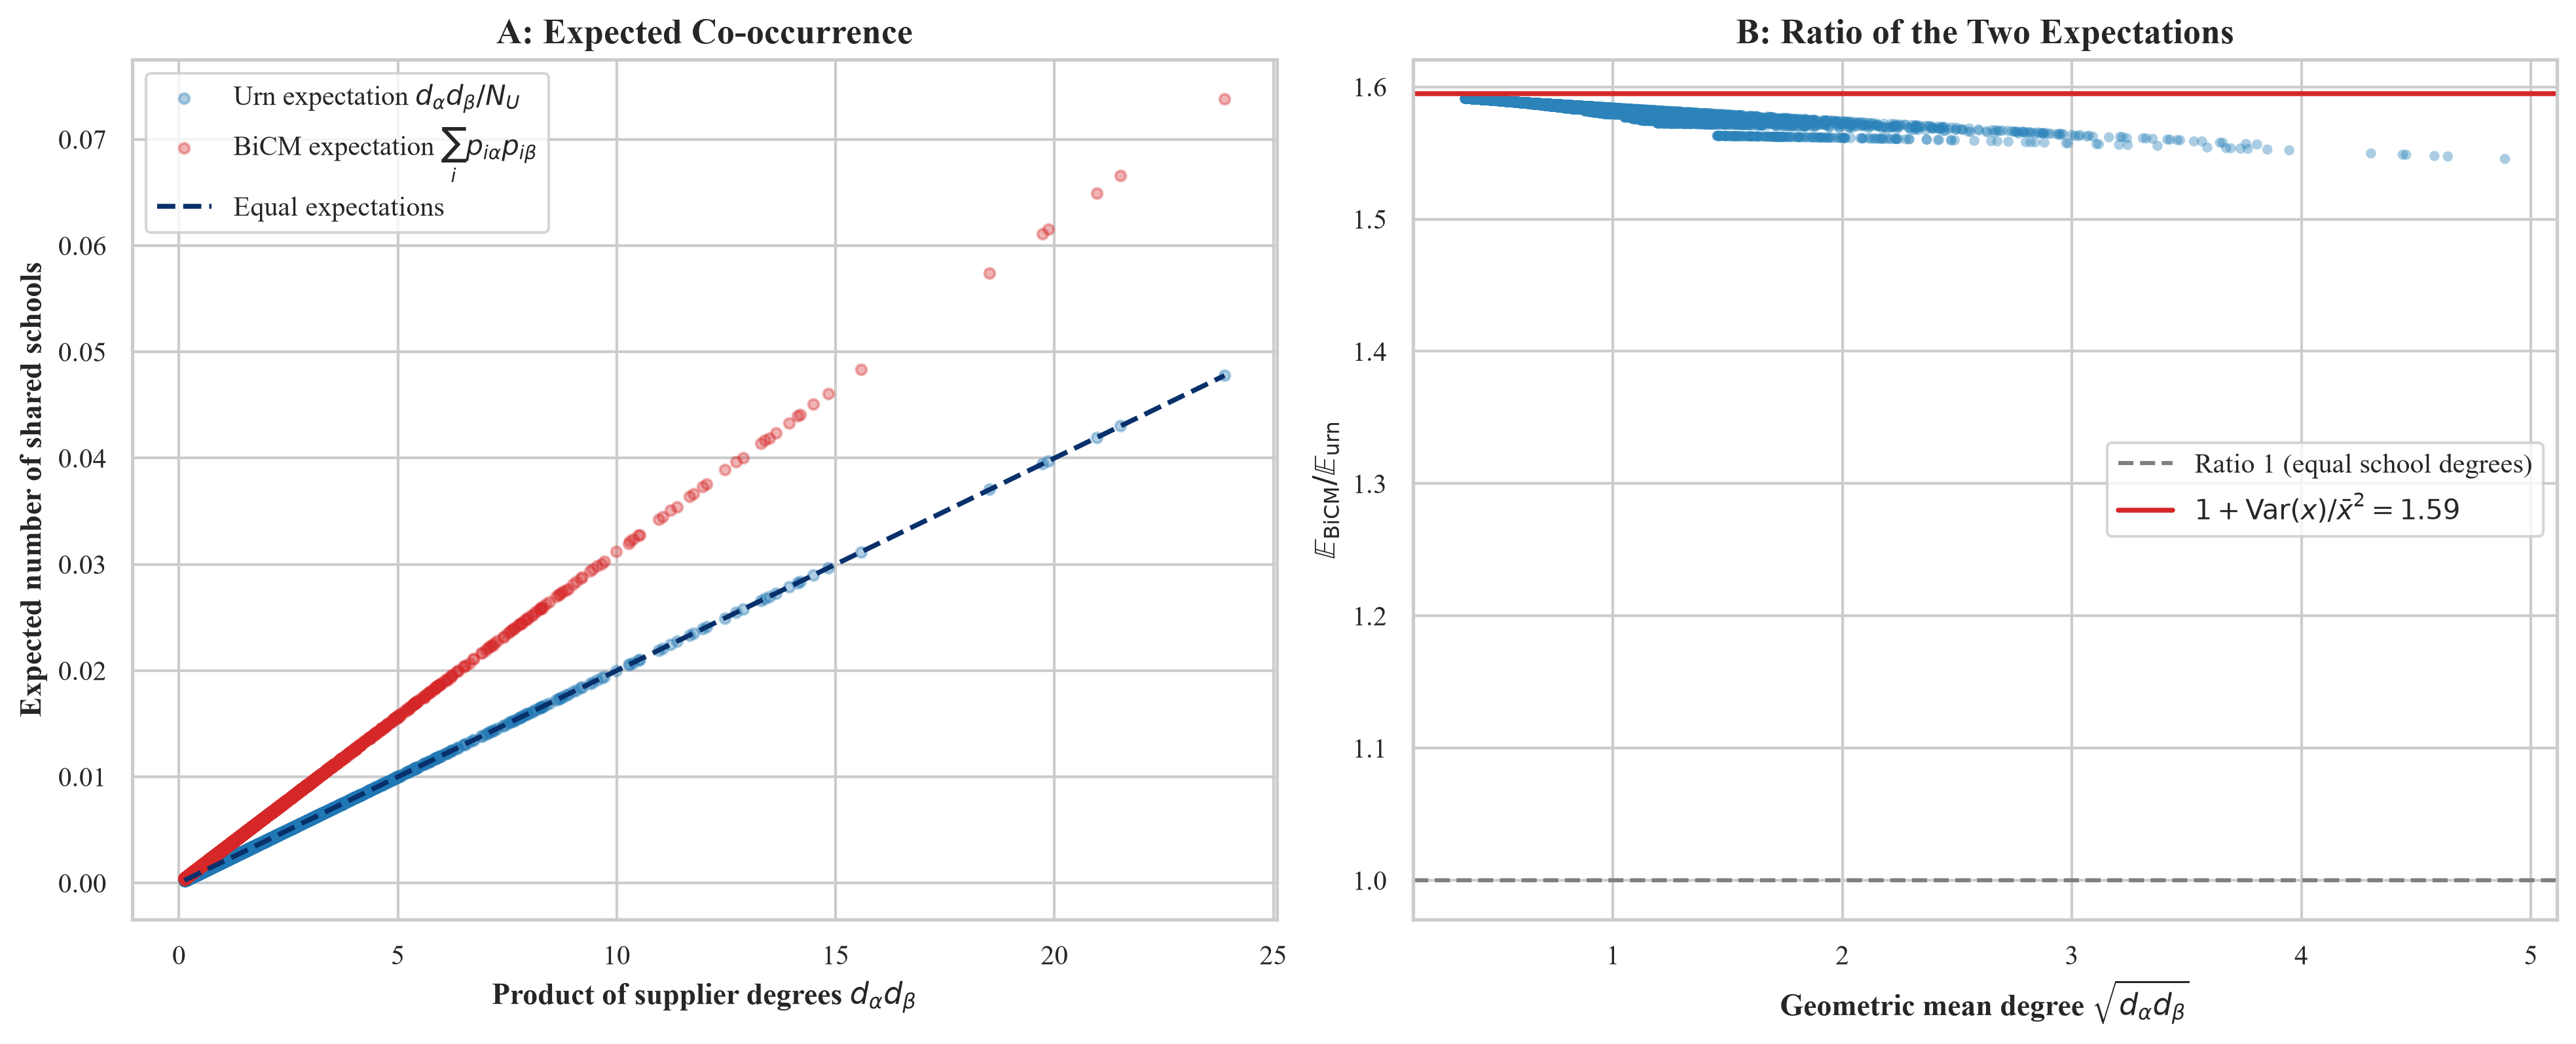

In [8]:
fig61, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2), constrained_layout=True)

degree_product = np.outer(res_p1["vendor_degree"], res_p1["vendor_degree"])
upper = np.triu(np.ones_like(degree_product, dtype=bool), k=1)
x_vals = degree_product[upper]
y_bicm = res_p1["expected_bicm"][upper]
y_urn = res_p1["expected_urn"][upper]
n_schools = res_p1["num_schools"]

ax1.scatter(x_vals, y_urn, alpha=0.35, s=14, color="#1f77b4", label=r"Urn expectation $d_\alpha d_\beta / N_U$")
ax1.scatter(x_vals, y_bicm, alpha=0.35, s=14, color="#d62728", label=r"BiCM expectation $\sum_i p_{i\alpha} p_{i\beta}$")
grid = np.linspace(x_vals.min(), x_vals.max(), 200)
ax1.plot(grid, grid / n_schools, color="#08306b", linestyle="--", linewidth=1.8, label="Equal expectations")
ax1.set_title("A: Expected Co-occurrence")
ax1.set_xlabel(r"Product of supplier degrees $d_\alpha d_\beta$")
ax1.set_ylabel(r"Expected number of shared schools")
ax1.legend(loc="upper left", frameon=True)

ratio = y_bicm / y_urn
ax2.scatter(np.sqrt(x_vals), ratio, alpha=0.4, s=14, color="#2b83ba", edgecolors="none")
ax2.axhline(1.0, color="gray", linestyle="--", linewidth=1.5, label="Ratio 1 (equal school degrees)")
ax2.axhline(res_p1["inflation_factor"], color="#d62728", linewidth=1.8,
            label=rf"$1 + \mathrm{{Var}}(x)/\bar{{x}}^2 = {res_p1['inflation_factor']:.2f}$")
ax2.set_title("B: Ratio of the Two Expectations")
ax2.set_xlabel(r"Geometric mean degree $\sqrt{d_\alpha d_\beta}$")
ax2.set_ylabel(r"$\mathbb{E}_{\mathrm{BiCM}} / \mathbb{E}_{\mathrm{urn}}$")
ax2.legend(loc="center right", frameon=True)

plt.show()

**Figure 6.1.** Expected co-occurrence of supplier pairs under the BiCM and under the urn model (panel A) and the ratio of the two (panel B) in a simulated network.

*Source:* author's simulation based on Saracco et al. (2017).

### 6.2 False Discovery Control (Theorem 1)

**Question.** Does the Benjamini–Hochberg procedure keep the false discovery proportion below the level $\alpha$ when many pair hypotheses are tested?

**Why the sorted $p$-values.** The procedure rejects every hypothesis up to the largest rank at which the sorted $p$-value lies below the line $k\alpha/M$. The plot of the sorted $p$-values against this line shows the cut-off directly.

**How to read.** The green area is between the $p$-values and the BH line up to the cut-off $k^*$ and marks the validated links. Panel B enlarges the region around $k^*$. The printed mean over repeated draws is compared with the bound $(m_0/M)\alpha$.

**What the figure is not.** It is a simulation of 10,000 tests with 80% true nulls, not a test of the supplier pairs.

In [9]:
def verify_theorem_1_fdr(
    num_tests: int = 10000,
    pi_zero: float = 0.80,
    nominal_fdr: float = ModelConfig.ALPHA_FDR,
    replications: int = 200,
    seed: int = ModelConfig.SEED,
) -> dict[str, float | int | bool | np.ndarray]:
    """Simulate the Benjamini-Hochberg procedure on a mixture of true nulls and signals.

    Applied to the pair tests of statistically validated networks by Tumminello et al. (2011)
    and Saracco et al. (2017). The expected false discovery proportion is estimated over
    repeated draws and compared with the bound (m0 / M) * alpha.
    """
    rng = np.random.default_rng(seed)
    m0 = int(num_tests * pi_zero)
    m1 = num_tests - m0
    rank = np.arange(1, num_tests + 1)
    bh_critical = rank / num_tests * nominal_fdr

    fdp = np.empty(replications)
    for r in range(replications):
        p_values = np.concatenate([rng.uniform(0.0, 1.0, size=m0), rng.beta(0.5, 20.0, size=m1)])
        is_null = np.concatenate([np.ones(m0, dtype=bool), np.zeros(m1, dtype=bool)])
        order = np.argsort(p_values)
        passed = np.flatnonzero(p_values[order] <= bh_critical)
        k_star = int(passed[-1]) + 1 if passed.size else 0
        fdp[r] = is_null[order][:k_star].sum() / max(k_star, 1)
        if r == 0:
            first = {
                "sorted_p": p_values[order],
                "k_star": k_star,
                "false_discoveries": int(is_null[order][:k_star].sum()),
                "bonferroni_rejections": int(np.sum(p_values <= nominal_fdr / num_tests)),
            }

    mean_fdp = float(np.mean(fdp))
    bound = m0 / num_tests * nominal_fdr
    assert bool(np.all(np.diff(bh_critical) > 0)), "BH critical values must increase with the rank."
    assert mean_fdp <= nominal_fdr, f"Mean false discovery proportion {mean_fdp:.4f} exceeds alpha."

    return {
        "num_tests": num_tests,
        "m0": m0,
        "m1": m1,
        "nominal_fdr": nominal_fdr,
        "replications": replications,
        "mean_fdp": mean_fdp,
        "bound": bound,
        "bh_critical": bh_critical,
        **first,
    }


res_thm1 = verify_theorem_1_fdr()
print(f"Hypotheses M: {res_thm1['num_tests']} (true nulls {res_thm1['m0']}, signals {res_thm1['m1']})")
print(f"Nominal level alpha:                   {res_thm1['nominal_fdr']:.3f}")
print(f"Bound (m0 / M) * alpha:                {res_thm1['bound']:.4f}")
print(f"Mean false discovery proportion:       {res_thm1['mean_fdp']:.4f} over {res_thm1['replications']} draws")
print(f"First draw: {res_thm1['k_star']} BH rejections, {res_thm1['false_discoveries']} false, "
      f"{res_thm1['bonferroni_rejections']} Bonferroni rejections")

Hypotheses M: 10000 (true nulls 8000, signals 2000)
Nominal level alpha:                   0.010
Bound (m0 / M) * alpha:                0.0080
Mean false discovery proportion:       0.0078 over 200 draws
First draw: 93 BH rejections, 0 false, 14 Bonferroni rejections


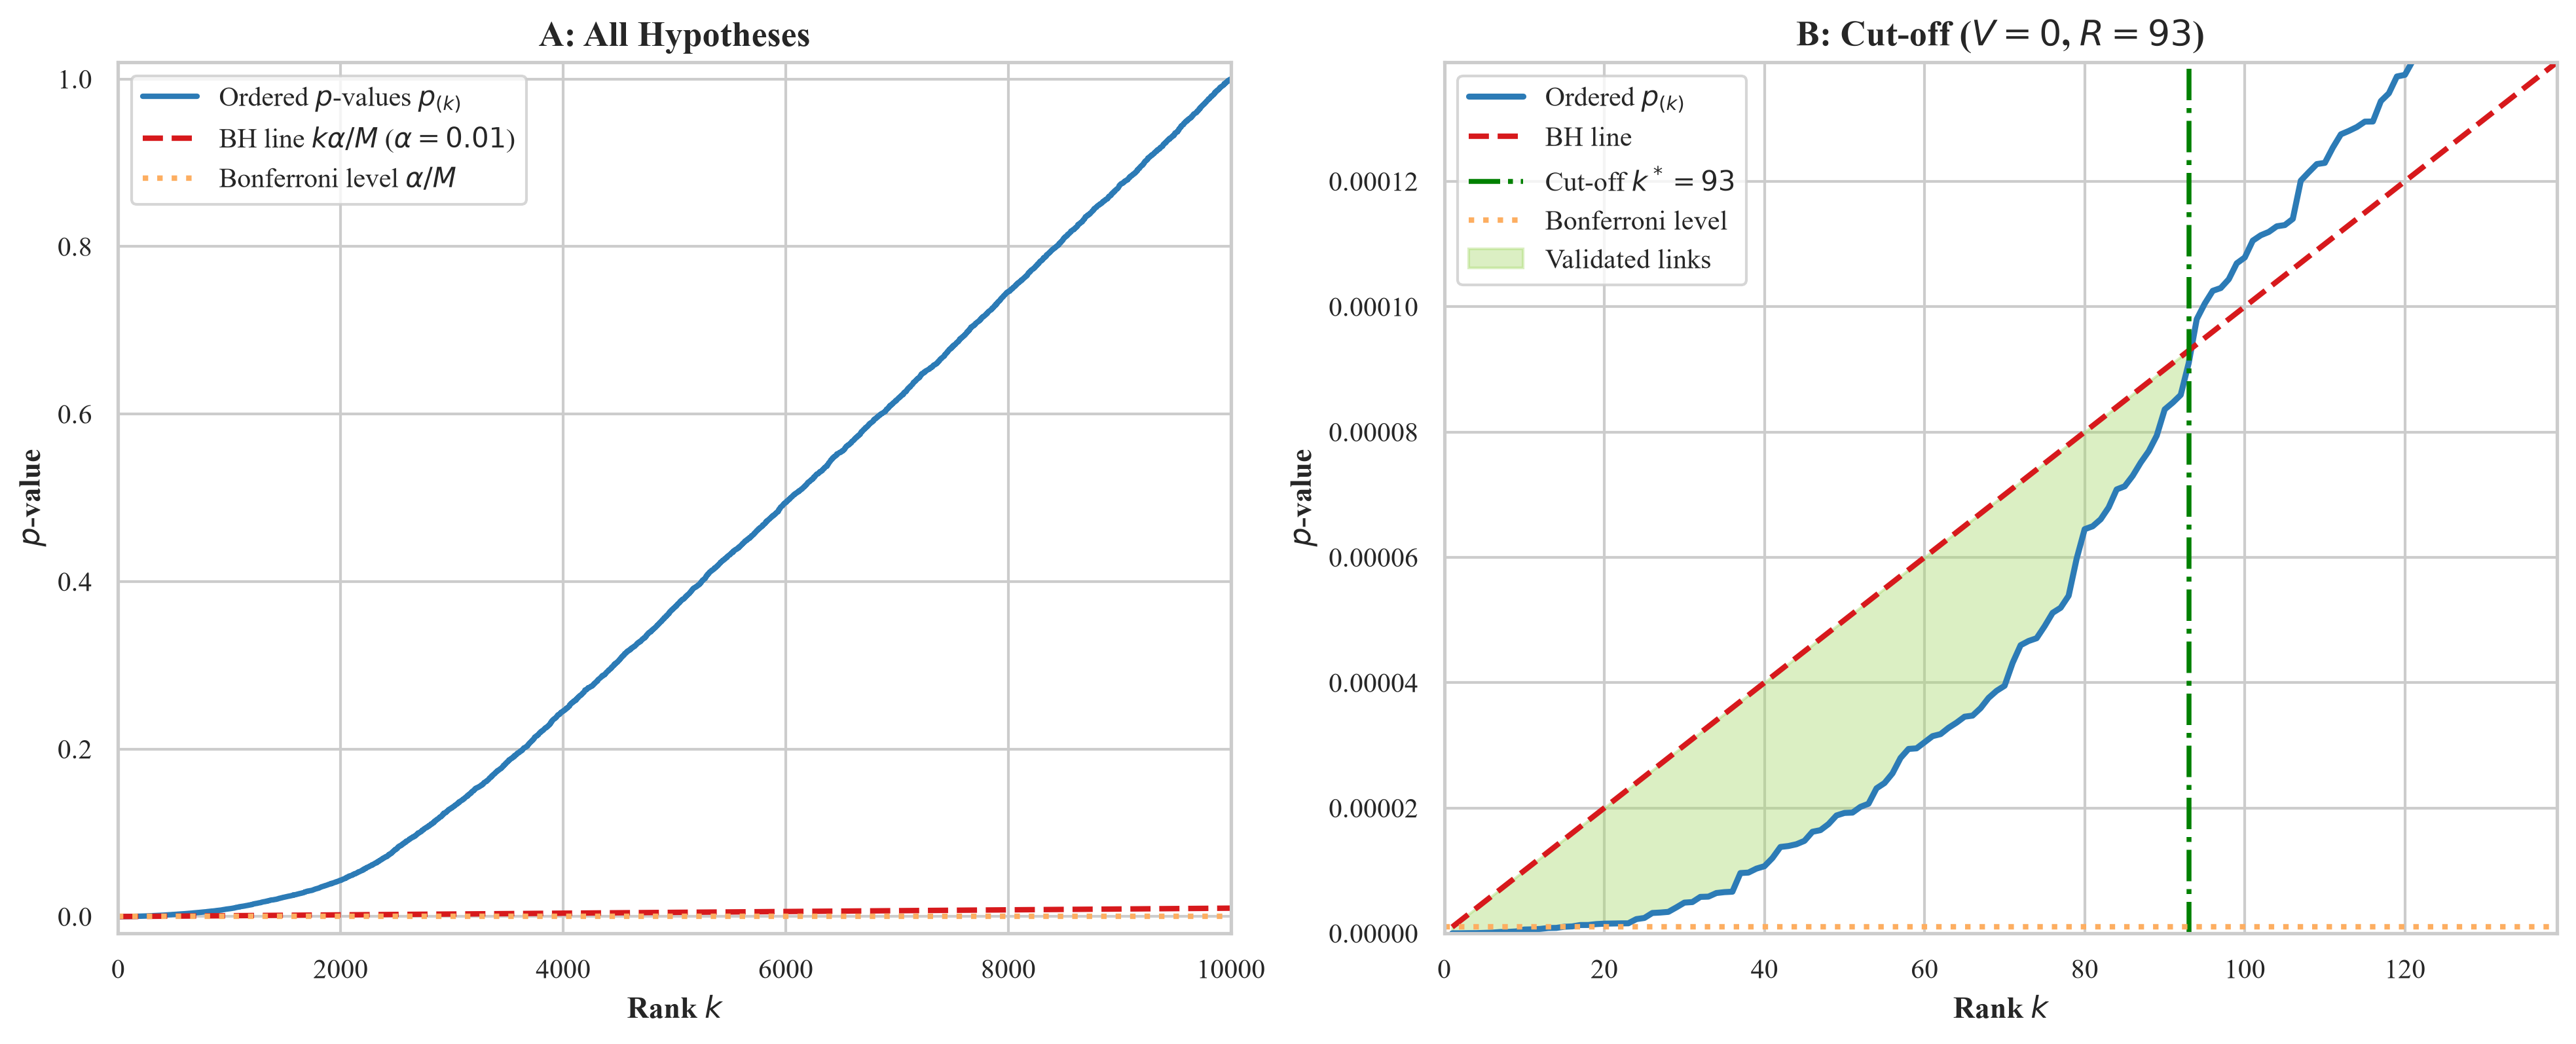

In [10]:
fig62, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2), constrained_layout=True)

sorted_p = res_thm1["sorted_p"]
bh_line = res_thm1["bh_critical"]
k_star = res_thm1["k_star"]
n_tests = res_thm1["num_tests"]
alpha = res_thm1["nominal_fdr"]
rank = np.arange(1, n_tests + 1)

ax1.plot(rank, sorted_p, color="#2c7bb6", linewidth=2.0, label=r"Ordered $p$-values $p_{(k)}$")
ax1.plot(rank, bh_line, color="#d7191c", linestyle="--", linewidth=2.0, label=rf"BH line $k\alpha / M$ ($\alpha = {alpha}$)")
ax1.axhline(alpha / n_tests, color="#fdae61", linestyle=":", linewidth=2.0, label=r"Bonferroni level $\alpha / M$")
ax1.set_title("A: All Hypotheses")
ax1.set_xlabel(r"Rank $k$")
ax1.set_ylabel(r"$p$-value")
ax1.set_xlim(0, n_tests)
ax1.set_ylim(-0.02, 1.02)
ax1.legend(loc="upper left", frameon=True)

zoom = int(k_star * 1.5)
ax2.plot(rank[:zoom], sorted_p[:zoom], color="#2c7bb6", linewidth=2.2, label=r"Ordered $p_{(k)}$")
ax2.plot(rank[:zoom], bh_line[:zoom], color="#d7191c", linestyle="--", linewidth=2.0, label="BH line")
ax2.axvline(k_star, color="green", linestyle="-.", linewidth=1.8, label=rf"Cut-off $k^* = {k_star}$")
ax2.axhline(alpha / n_tests, color="#fdae61", linestyle=":", linewidth=2.0, label="Bonferroni level")
ax2.fill_between(rank[:k_star], sorted_p[:k_star], bh_line[:k_star], color="#a6d96a", alpha=0.4, label="Validated links")
ax2.set_title(rf"B: Cut-off ($V = {res_thm1['false_discoveries']}$, $R = {k_star}$)")
ax2.set_xlabel(r"Rank $k$")
ax2.set_ylabel(r"$p$-value")
ax2.set_xlim(0, zoom)
ax2.set_ylim(0, bh_line[zoom - 1])
ax2.legend(loc="upper left", frameon=True)

plt.show()

**Figure 6.2.** Sorted $p$-values with the Benjamini–Hochberg line and the Bonferroni level for a simulated mixture of true nulls and signals; panel B enlarges the cut-off.

*Source:* author's simulation based on Tumminello et al. (2011) and Saracco et al. (2017).

### 6.3 Exact Poisson-Binomial Distribution

**Question.** Does the discrete Fourier transform of the characteristic function give the exact distribution of the number of shared schools, and how far is the Poisson approximation?

**Check.** The probability mass function from the transform is compared with the successive convolution of the Bernoulli distributions, which is exact. The $\ell_1$ distance to the Poisson distribution is compared with Le Cam's bound $2\sum_i \pi_i^2$ (Saracco et al., 2017).

In [11]:
from scipy.stats import poisson


class PoissonBinomial:
    """Poisson-binomial distribution evaluated by the DFT of its characteristic function.

    Hong's algorithm as used by Saracco et al. (2017) for the exact p-values of shared neighbours.
    """

    def __init__(self, probabilities: np.ndarray) -> None:
        p = np.asarray(probabilities, dtype=np.float64)
        self.p = p[p > 0.0]
        self.n = len(self.p)

    def pmf(self) -> np.ndarray:
        """Probability mass function on 0..n."""
        if self.n == 0:
            return np.array([1.0])
        m = self.n + 1
        omega = 2.0 * np.pi / m
        phase = np.exp(-1j * omega * np.arange(m))
        characteristic = np.prod((1.0 - self.p[:, None]) + self.p[:, None] * phase[None, :], axis=0)
        return np.maximum(np.real(np.fft.ifft(characteristic)), 0.0)

    def sf(self, k: int) -> float:
        """Survival function P(X >= k)."""
        if k <= 0:
            return 1.0
        if k > self.n:
            return 0.0
        return float(np.sum(self.pmf()[k:]))

    def le_cam_bound(self) -> float:
        """Le Cam's bound 2 * sum(p_i^2) on the l1 distance to a Poisson distribution."""
        return float(2.0 * np.sum(self.p**2))

    def poisson_l1_distance(self) -> float:
        """l1 distance between the exact pmf and the Poisson pmf with the same mean."""
        lam = float(np.sum(self.p))
        support = np.arange(self.n + 1)
        inside = np.abs(self.pmf() - poisson.pmf(support, lam)).sum()
        return float(inside + poisson.sf(self.n, lam))


def pmf_by_convolution(probabilities: np.ndarray) -> np.ndarray:
    """Reference pmf by successive convolution of the Bernoulli distributions."""
    pmf = np.array([1.0])
    for p in probabilities:
        pmf = np.convolve(pmf, [1.0 - p, p])
    return pmf


pair_probabilities = np.array([0.02, 0.05, 0.12, 0.08, 0.15, 0.03, 0.01, 0.10, 0.04, 0.07])
pb = PoissonBinomial(pair_probabilities)
pmf_dft = pb.pmf()
pmf_ref = pmf_by_convolution(pair_probabilities)

max_abs_error = float(np.max(np.abs(pmf_dft - pmf_ref)))
l1_to_poisson = pb.poisson_l1_distance()
le_cam = pb.le_cam_bound()

assert max_abs_error < 1e-12, f"DFT-CF differs from the convolution: {max_abs_error}"
assert l1_to_poisson < le_cam, "Le Cam's inequality violated."

print(f"Bernoulli trials:                    {pb.n}")
print(f"Mean / variance:                     {pair_probabilities.sum():.4f} / {(pair_probabilities * (1 - pair_probabilities)).sum():.4f}")
print(f"Max |DFT-CF - convolution|:          {max_abs_error:.2e}")
print(f"l1 distance to Poisson:              {l1_to_poisson:.4f}")
print(f"Le Cam bound 2 * sum(p_i^2):         {le_cam:.4f}")
print(f"Exact P(X >= 3):                     {pb.sf(3):.6f}")

Bernoulli trials:                    10
Mean / variance:                     0.6700 / 0.6063
Max |DFT-CF - convolution|:          6.54e-17
l1 distance to Poisson:              0.0501
Le Cam bound 2 * sum(p_i^2):         0.1274
Exact P(X >= 3):                     0.022912


### 6.4 Noise-Corrected Backbone

**Question.** Does the noise-corrected filter keep a group of suppliers with unusually many shared schools and drop the links that the strength of a hub explains?

**Why a comparison with the disparity filter.** The disparity filter looks at one end node of a link, so a hub tends to keep its links. The noise-corrected filter compares each link with the value expected from the strengths of both end nodes (Coscia and Neffke, 2017).

**How to read.** In panel A each point is a link. The dashed line is the cut-off $\delta = 2.32$, and red points are the links that the noise-corrected filter keeps. Panel B shows how many links of each weight the two filters keep.

**What the figure is not.** It is a simulation of co-occurrence counts with a hub and a planted group, not the supplier network of the programme.

In [12]:
def noise_corrected_backbone(weights: np.ndarray, delta: float = 2.32) -> dict[str, np.ndarray]:
    """Noise-corrected backbone of a weighted network (Coscia and Neffke, 2017).

    A link is kept if the transformed lift exceeds delta standard deviations;
    delta = 2.32 corresponds to p of about 0.01.
    """
    w = np.array(weights, dtype=np.float64)
    np.fill_diagonal(w, 0.0)
    n_out = w.sum(axis=1)
    n_in = w.sum(axis=0)
    n_tot = w.sum()
    if n_tot <= 0:
        raise ValueError("The weight matrix has no links.")

    with np.errstate(divide="ignore", invalid="ignore"):
        prod = np.outer(n_out, n_in)
        kappa = n_tot / prod
        lift = (kappa * w - 1.0) / (kappa * w + 1.0)
        d_kappa = 1.0 / prod - n_tot * (n_out[:, None] + n_in[None, :]) / prod**2

        # Beta prior fitted to the hypergeometric moments, posterior mean of P_ij
        mu = prod / n_tot**2
        var_prior = prod * (n_tot - n_out)[:, None] * (n_tot - n_in)[None, :] / (n_tot**4 * (n_tot - 1.0))
        a = mu**2 / var_prior * (1.0 - mu) - mu
        b = mu * ((1.0 - mu) ** 2 / var_prior + 1.0) - 1.0
        p_post = (w + a) / (n_tot + a + b)

        var_n = n_tot * p_post * (1.0 - p_post)
        var_lift = var_n * (2.0 * (kappa + w * d_kappa) / (kappa * w + 1.0) ** 2) ** 2
        score = lift / np.sqrt(var_lift)

    score[~np.isfinite(score)] = 0.0
    lift[~np.isfinite(lift)] = -1.0
    return {"score": score, "lift": lift, "backbone": (score > delta) & (w > 0)}


def disparity_filter(weights: np.ndarray, alpha: float = 0.05) -> np.ndarray:
    """Disparity filter, the unilateral baseline described by Coscia and Neffke (2017)."""
    w = np.array(weights, dtype=np.float64)
    np.fill_diagonal(w, 0.0)
    degree = np.sum(w > 0, axis=1)
    strength = w.sum(axis=1)
    with np.errstate(divide="ignore", invalid="ignore"):
        share = w / strength[:, None]
        p_value = (1.0 - share) ** np.maximum(degree[:, None] - 1.0, 0.0)
    p_value[np.isnan(p_value)] = 1.0
    return (np.minimum(p_value, p_value.T) < alpha) & (w > 0)


# Synthetic co-occurrence counts: activity-driven ties, a hub (node 0) and a tightly connected group (nodes 10-14)
rng = np.random.default_rng(ModelConfig.SEED)
n_nodes = 80
activity = rng.lognormal(mean=0.0, sigma=0.8, size=n_nodes)
activity[0] *= 8.0
group_nodes = list(range(10, 15))
expected_counts = 0.8 * np.outer(activity, activity)
expected_counts[np.ix_(group_nodes, group_nodes)] += 12.0
upper_counts = np.triu(rng.poisson(expected_counts), k=1)
w_synth = (upper_counts + upper_counts.T).astype(np.float64)

nc_res = noise_corrected_backbone(w_synth)
df_mask = disparity_filter(w_synth)

hub_links = np.zeros_like(df_mask)
hub_links[0, 1:] = True
hub_links[1:, 0] = True
group_links = np.zeros_like(df_mask)
group_links[np.ix_(group_nodes, group_nodes)] = True
np.fill_diagonal(group_links, False)

print(f"Links in the network:                    {int(np.sum(w_synth > 0) / 2)}")
print(f"Links kept by the disparity filter:      {int(np.sum(df_mask) / 2)}")
print(f"Links kept by the noise-corrected filter: {int(np.sum(nc_res['backbone']) / 2)}")
print(f"Hub links kept (disparity / NC):         {int(np.sum(df_mask & hub_links) / 2)} / {int(np.sum(nc_res['backbone'] & hub_links) / 2)} of {int(np.sum(hub_links) / 2)}")
print(f"Group links kept (disparity / NC):       {int(np.sum(df_mask & group_links) / 2)} / {int(np.sum(nc_res['backbone'] & group_links) / 2)} of {int(np.sum(group_links) / 2)}")

Links in the network:                    1822
Links kept by the disparity filter:      108
Links kept by the noise-corrected filter: 245
Hub links kept (disparity / NC):         61 / 6 of 79
Group links kept (disparity / NC):       10 / 10 of 10


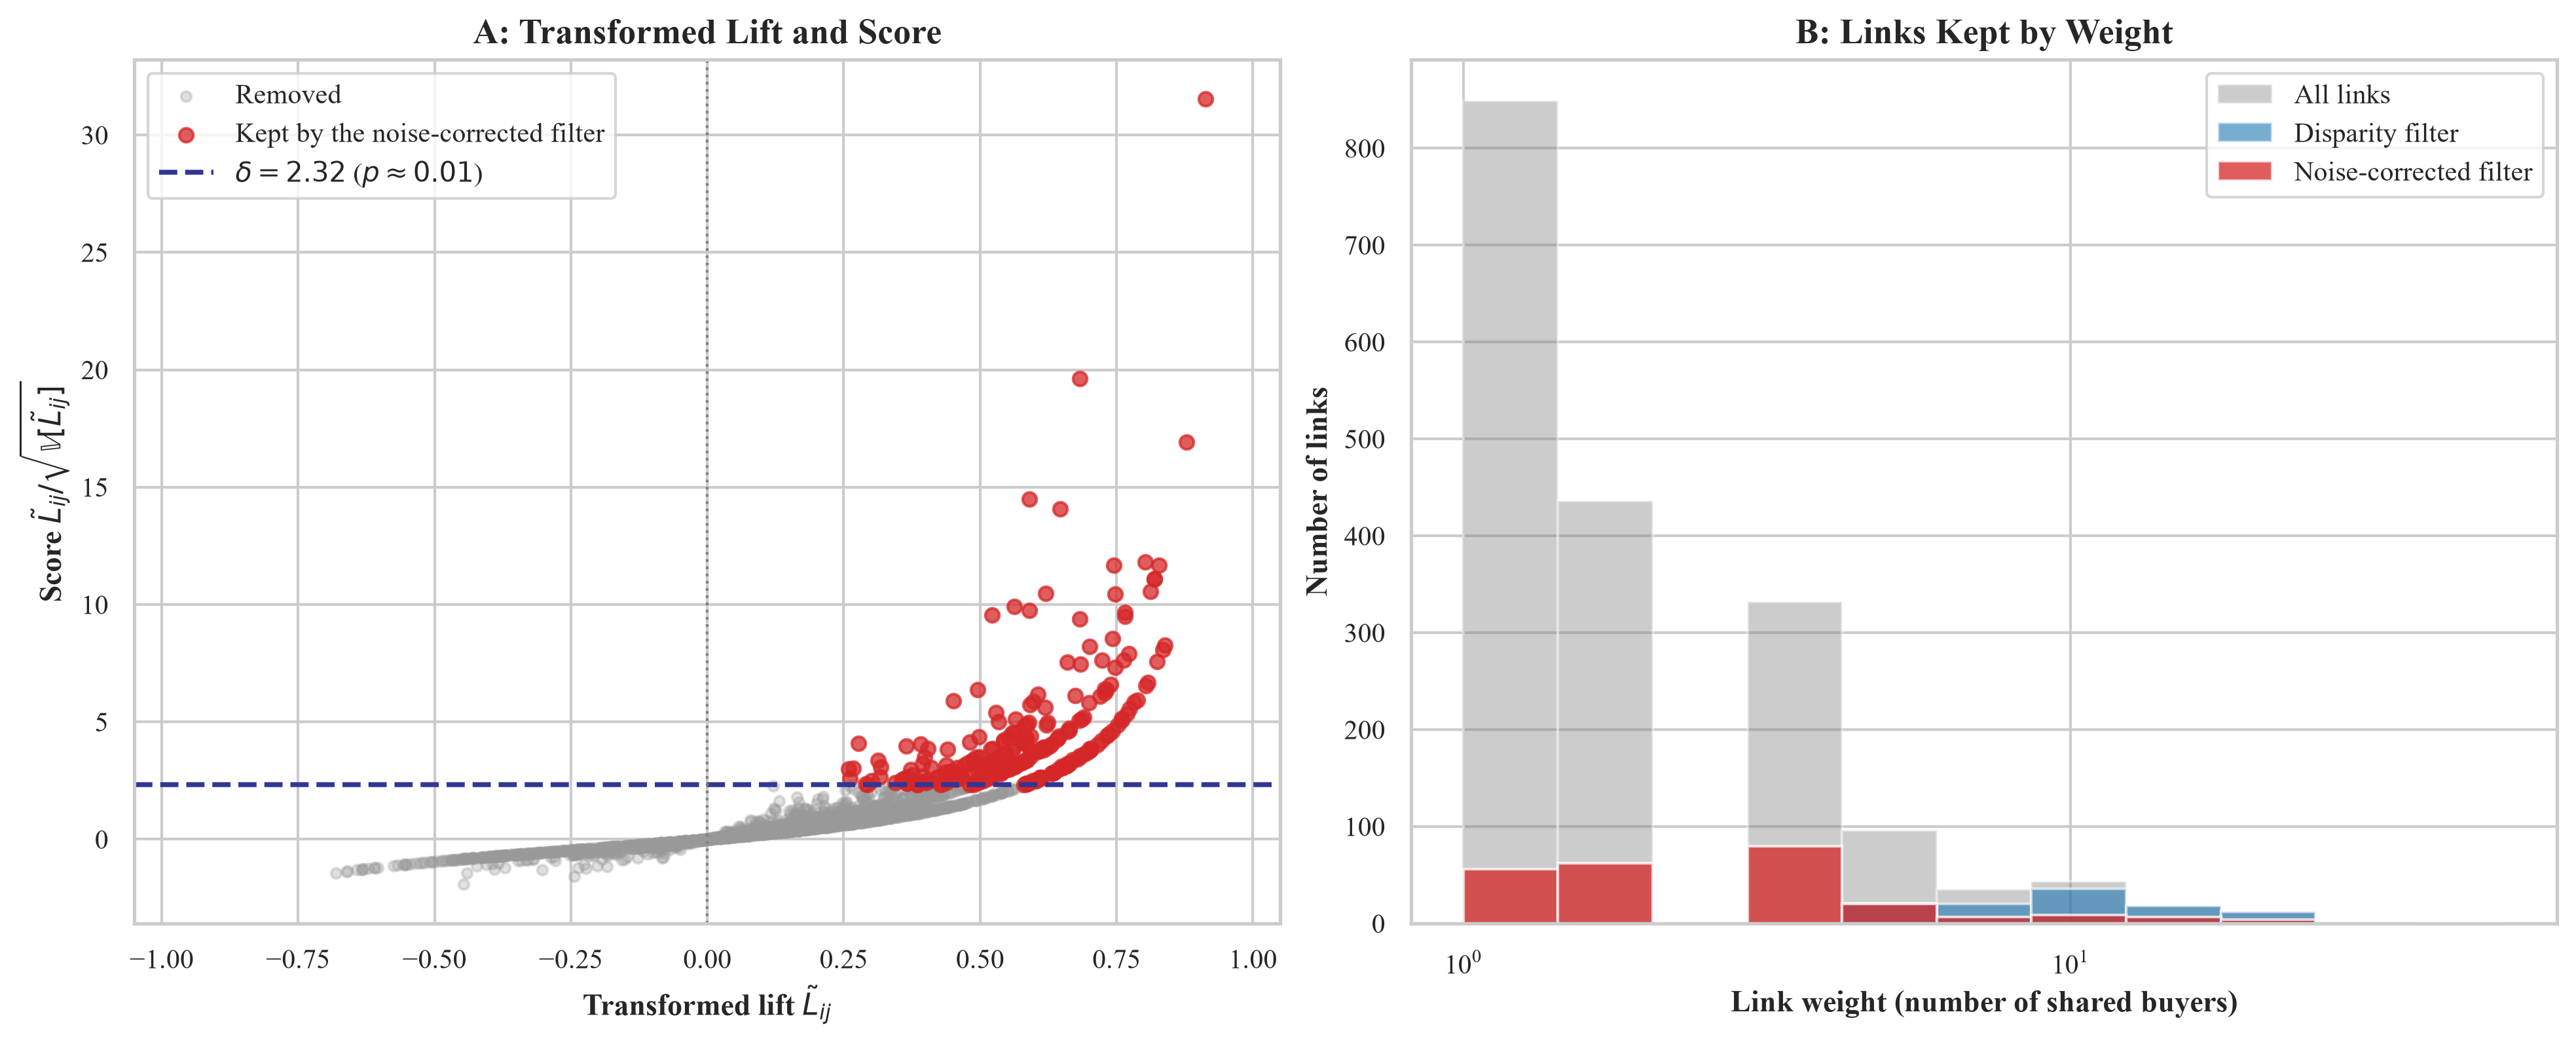

In [13]:
fig63, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2), constrained_layout=True)

upper = np.triu(np.ones_like(w_synth, dtype=bool), k=1)
present = upper & (w_synth > 0)
weights_upper = w_synth[present]
score_upper = nc_res["score"][present]
lift_upper = nc_res["lift"][present]
nc_kept = nc_res["backbone"][present]
df_kept = df_mask[present]

ax1.scatter(lift_upper[~nc_kept], score_upper[~nc_kept], color="#999999", alpha=0.3, s=14, label="Removed")
ax1.scatter(lift_upper[nc_kept], score_upper[nc_kept], color="#d62728", alpha=0.75, s=26, label="Kept by the noise-corrected filter")
ax1.axhline(2.32, color="#313695", linestyle="--", linewidth=1.8, label=r"$\delta = 2.32$ ($p \approx 0.01$)")
ax1.axvline(0.0, color="gray", linestyle=":", linewidth=1.0)
ax1.set_title(r"A: Transformed Lift and Score")
ax1.set_xlabel(r"Transformed lift $\tilde{L}_{ij}$")
ax1.set_ylabel(r"Score $\tilde{L}_{ij} / \sqrt{\mathbb{V}[\tilde{L}_{ij}]}$")
ax1.set_xlim(-1.05, 1.05)
ax1.legend(loc="upper left", frameon=True)

bins = np.logspace(0.0, np.log10(weights_upper.max()), 12)
ax2.hist(weights_upper, bins=bins, alpha=0.4, color="gray", label="All links")
ax2.hist(weights_upper[df_kept], bins=bins, alpha=0.6, color="#1f77b4", label="Disparity filter")
ax2.hist(weights_upper[nc_kept], bins=bins, alpha=0.75, color="#d62728", label="Noise-corrected filter")
ax2.set_xscale("log")
ax2.set_title("B: Links Kept by Weight")
ax2.set_xlabel("Link weight (number of shared buyers)")
ax2.set_ylabel("Number of links")
ax2.legend(loc="upper right", frameon=True)

plt.show()

**Figure 6.3.** Transformed lift and score of the links of a simulated network (panel A) and the links kept by the disparity filter and by the noise-corrected filter by weight (panel B).

*Source:* author's simulation based on Coscia and Neffke (2017).

### 6.5 Coherence and Exclusivity of Groups

**Question.** Do the two group metrics separate a tight group with weak ties to the rest of the market from ordinary groups and from a hub with spokes?

**Why a plane of two metrics.** Coherence measures how uniform the ties inside a group are, and exclusivity measures how closed the group is towards the rest of the market (Wachs and Kertész, 2019). A single metric does not separate the three types of group.

**How to read.** Each blue point is a random group of ordinary participants. The star is the tight group, the square an ordinary group and the triangle a hub with three spokes. The shaded zone is an illustrative screening zone. Its cut-offs are chosen for this figure and are not taken from the source.

**What the figure is not.** It is a simulated market of 60 participants, and a position in the shaded zone is not evidence of collusion.

In [14]:
def group_coherence_exclusivity(weights: np.ndarray, group: list[int]) -> tuple[float, float]:
    """Coherence C_G and exclusivity E_G of a group of nodes (Wachs and Kertész, 2019)."""
    w = np.asarray(weights, dtype=np.float64)
    nodes = sorted(set(group))
    if len(nodes) < 2:
        return 0.0, 0.0

    internal = w[np.ix_(nodes, nodes)][np.triu_indices(len(nodes), k=1)]
    active = internal[internal > 0]
    if active.size == 0:
        return 0.0, 0.0

    coherence = float(np.exp(np.mean(np.log(active))) / np.mean(active))
    outside = np.setdiff1d(np.arange(w.shape[0]), nodes)
    s_in = float(internal.sum())
    s_out = float(w[np.ix_(nodes, outside)].sum())
    return coherence, s_in / (s_in + s_out)


n_market = 60
rng = np.random.default_rng(ModelConfig.SEED)
w_market = np.triu(rng.exponential(scale=2.5, size=(n_market, n_market)), k=1)
w_market = w_market + w_market.T

# Group A: strong, uniform ties inside the group and weak ties to the rest of the market
tight_nodes = [0, 1, 2]
w_market[np.ix_(tight_nodes, tight_nodes)] = 120.0
np.fill_diagonal(w_market, 0.0)
w_market[tight_nodes, 3:] *= 0.02
w_market[3:, tight_nodes] *= 0.02

# Group B: ordinary market participants (no special structure)
open_nodes = [10, 11, 12, 13]

# Group C: one supplier with strong ties to three others that are not tied to each other
hub_nodes = [20, 21, 22, 23]
for spoke in hub_nodes[1:]:
    w_market[20, spoke] = w_market[spoke, 20] = 60.0

c_tight, e_tight = group_coherence_exclusivity(w_market, tight_nodes)
c_open, e_open = group_coherence_exclusivity(w_market, open_nodes)
c_hub, e_hub = group_coherence_exclusivity(w_market, hub_nodes)

print(f"Tight group:   coherence {c_tight:.3f} | exclusivity {e_tight:.3f}")
print(f"Open market:   coherence {c_open:.3f} | exclusivity {e_open:.3f}")
print(f"Hub and spokes: coherence {c_hub:.3f} | exclusivity {e_hub:.3f}")

Tight group:   coherence 1.000 | exclusivity 0.979
Open market:   coherence 0.794 | exclusivity 0.015
Hub and spokes: coherence 0.233 | exclusivity 0.255


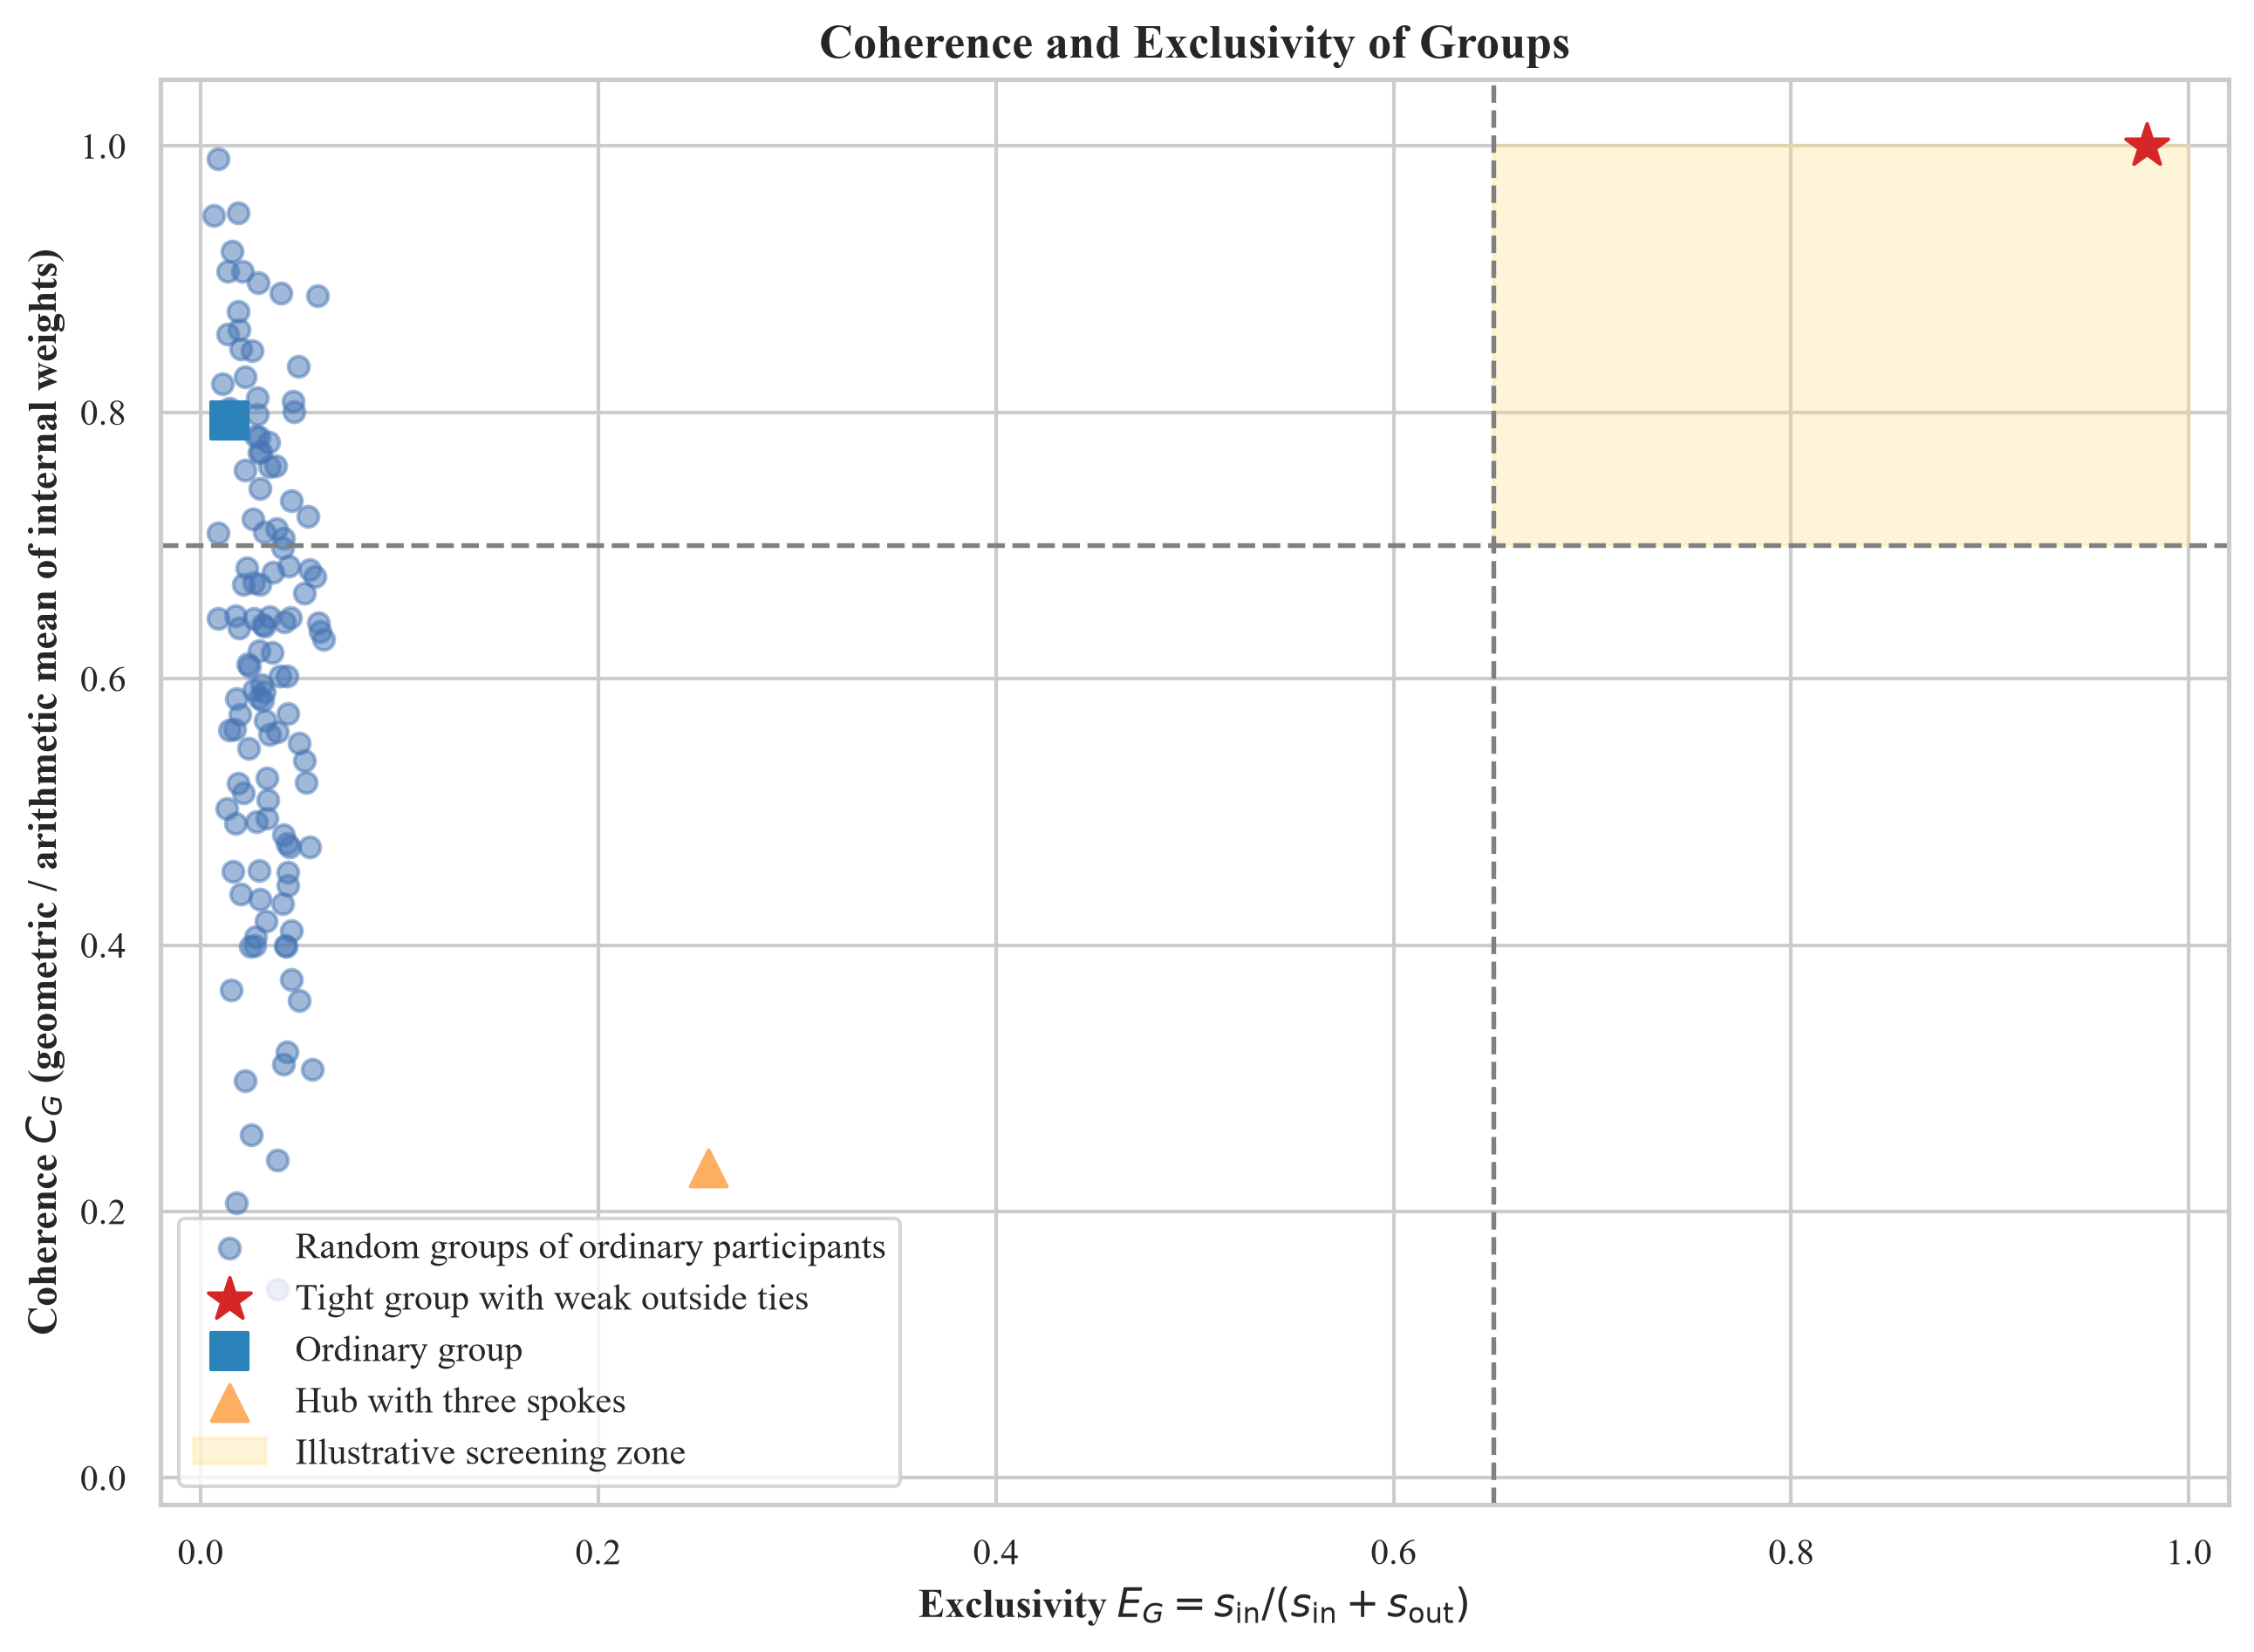

In [15]:
fig64, ax = plt.subplots(figsize=(8.5, 6.2), constrained_layout=True)

rng = np.random.default_rng(ModelConfig.SEED)
pool = np.setdiff1d(np.arange(n_market), tight_nodes + hub_nodes)
random_groups = [group_coherence_exclusivity(w_market, list(rng.choice(pool, size=rng.integers(3, 7), replace=False)))
                 for _ in range(120)]
coh_random, exc_random = zip(*random_groups)

ax.scatter(exc_random, coh_random, color="#4575b4", alpha=0.5, s=32, label="Random groups of ordinary participants")
ax.scatter([e_tight], [c_tight], color="#d62728", s=150, marker="*", zorder=5, label="Tight group with weak outside ties")
ax.scatter([e_open], [c_open], color="#2b83ba", s=100, marker="s", zorder=5, label="Ordinary group")
ax.scatter([e_hub], [c_hub], color="#fdae61", s=100, marker="^", zorder=5, label="Hub with three spokes")
ax.axvline(0.65, color="gray", linestyle="--", linewidth=1.3)
ax.axhline(0.70, color="gray", linestyle="--", linewidth=1.3)
ax.fill_between([0.65, 1.0], 0.70, 1.0, color="#fee090", alpha=0.35, label="Illustrative screening zone")

ax.set_title(r"Coherence and Exclusivity of Groups")
ax.set_xlabel(r"Exclusivity $E_G = s_{\mathrm{in}} / (s_{\mathrm{in}} + s_{\mathrm{out}})$")
ax.set_ylabel(r"Coherence $C_G$ (geometric / arithmetic mean of internal weights)")
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.05)
ax.legend(loc="lower left", frameon=True)

plt.show()

**Figure 6.4.** Coherence $C_G$ and exclusivity $E_G$ of random groups and of three constructed groups in a simulated market.

*Source:* author's simulation based on Wachs and Kertész (2019).

### 6.6 Digits of the Spacings (Theorem 2)

**Question.** Do the spacings of smooth contract values follow the digit pattern of the exponential distribution, and do rounded values depart from it?

**Check.** The deviation of the exponential distribution from Benford's law is evaluated from the series in the proof of Theorem 2. Normalised spacings of 15,000 uniform values are compared with the same values rounded to BGN 10, with the Kolmogorov–Smirnov distance $D$ of the mantissa from the uniform distribution (Miller and Nigrini, 2006).

**How to read.** Panel A gives the first-digit frequencies of the spacings, panel B the distribution function of the mantissa. Smooth values follow the diagonal, and rounded values depart from it because their spacings repeat.

**What the figure is not.** It is a simulation. A departure of real contract values from the diagonal is a risk indicator that calls for an explanation, not proof of manipulation.

In [16]:
from scipy.stats import kstest


def exponential_digit_probabilities(base: float = 10.0, terms: int = 40) -> np.ndarray:
    """First-digit probabilities of a standard exponential variable.

    P(D1 = d) = sum_k [exp(-d * B^k) - exp(-(d + 1) * B^k)] (Miller and Nigrini, 2006).
    """
    k = np.arange(-terms, terms + 1)
    d = np.arange(1, int(base))
    return np.array([np.sum(np.exp(-x * base**k) - np.exp(-(x + 1) * base**k)) for x in d])


def exponential_mantissa_deviation(base: float = 10.0, terms: int = 40, grid: int = 20001) -> float:
    """Supremum of |F(b) - b| for log_B of a standard exponential variable modulo 1."""
    b = np.linspace(0.0, 1.0, grid)
    k = np.arange(-terms, terms + 1)[:, None]
    cdf = np.sum(np.exp(-base**k) - np.exp(-base ** (b[None, :] + k)), axis=0)
    return float(np.max(np.abs(cdf - b)))


def spacing_mantissas(values: np.ndarray, upper: float) -> tuple[np.ndarray, int]:
    """Mantissas log10(Z) mod 1 of the normalised spacings Z of ordered values on [0, upper]."""
    ordered = np.sort(values)
    z = np.diff(ordered) * len(values) / upper
    positive = z[z > 0]
    log_z = np.log10(positive)
    return log_z - np.floor(log_z), int(len(z) - len(positive))


rng = np.random.default_rng(ModelConfig.SEED)
n_values, upper_value = 15000, 100000.0
smooth = rng.uniform(0.0, upper_value, size=n_values)
rounded = np.round(smooth / 10.0) * 10.0

mant_smooth, zeros_smooth = spacing_mantissas(smooth, upper_value)
mant_rounded, zeros_rounded = spacing_mantissas(rounded, upper_value)

digits = np.arange(1, 10)
p_benford = np.log10(1.0 + 1.0 / digits)


def first_digit_frequencies(mantissas: np.ndarray) -> np.ndarray:
    return np.bincount(np.floor(10.0**mantissas).astype(int), minlength=10)[1:10] / len(mantissas)


p_smooth = first_digit_frequencies(mant_smooth)
p_rounded = first_digit_frequencies(mant_rounded)

digit_deviation = float(np.max(np.abs(exponential_digit_probabilities() - p_benford)))
cdf_deviation = exponential_mantissa_deviation()
d_smooth = float(kstest(mant_smooth, "uniform").statistic)
d_rounded = float(kstest(mant_rounded, "uniform").statistic)
sampling_band = 1.36 / np.sqrt(len(mant_smooth))

assert 0.0285 < digit_deviation < 0.030, f"Digit deviation of the exponential distribution outside 0.029-0.030: {digit_deviation:.5f}"
assert d_smooth <= cdf_deviation + sampling_band, "Smooth values deviate by more than the theoretical bound plus sampling error."
assert d_rounded > 3.0 * d_smooth, "Rounded values are not clearly separated from smooth values."

print(f"Exp(1), base 10: largest first-digit deviation from Benford {digit_deviation:.4f}, sup |F(b) - b| {cdf_deviation:.4f}")
print(f"Sampling band (95%) for n = {len(mant_smooth)}:          {sampling_band:.4f}")
print(f"Smooth values:  D = {d_smooth:.4f} | max digit deviation {np.max(np.abs(p_smooth - p_benford)):.4f} | zero spacings {zeros_smooth}")
print(f"Rounded values: D = {d_rounded:.4f} | max digit deviation {np.max(np.abs(p_rounded - p_benford)):.4f} | zero spacings {zeros_rounded}")

Exp(1), base 10: largest first-digit deviation from Benford 0.0286, sup |F(b) - b| 0.0305
Sampling band (95%) for n = 14999:          0.0111
Smooth values:  D = 0.0318 | max digit deviation 0.0249 | zero spacings 0
Rounded values: D = 0.5959 | max digit deviation 0.4709 | zero spacings 7264


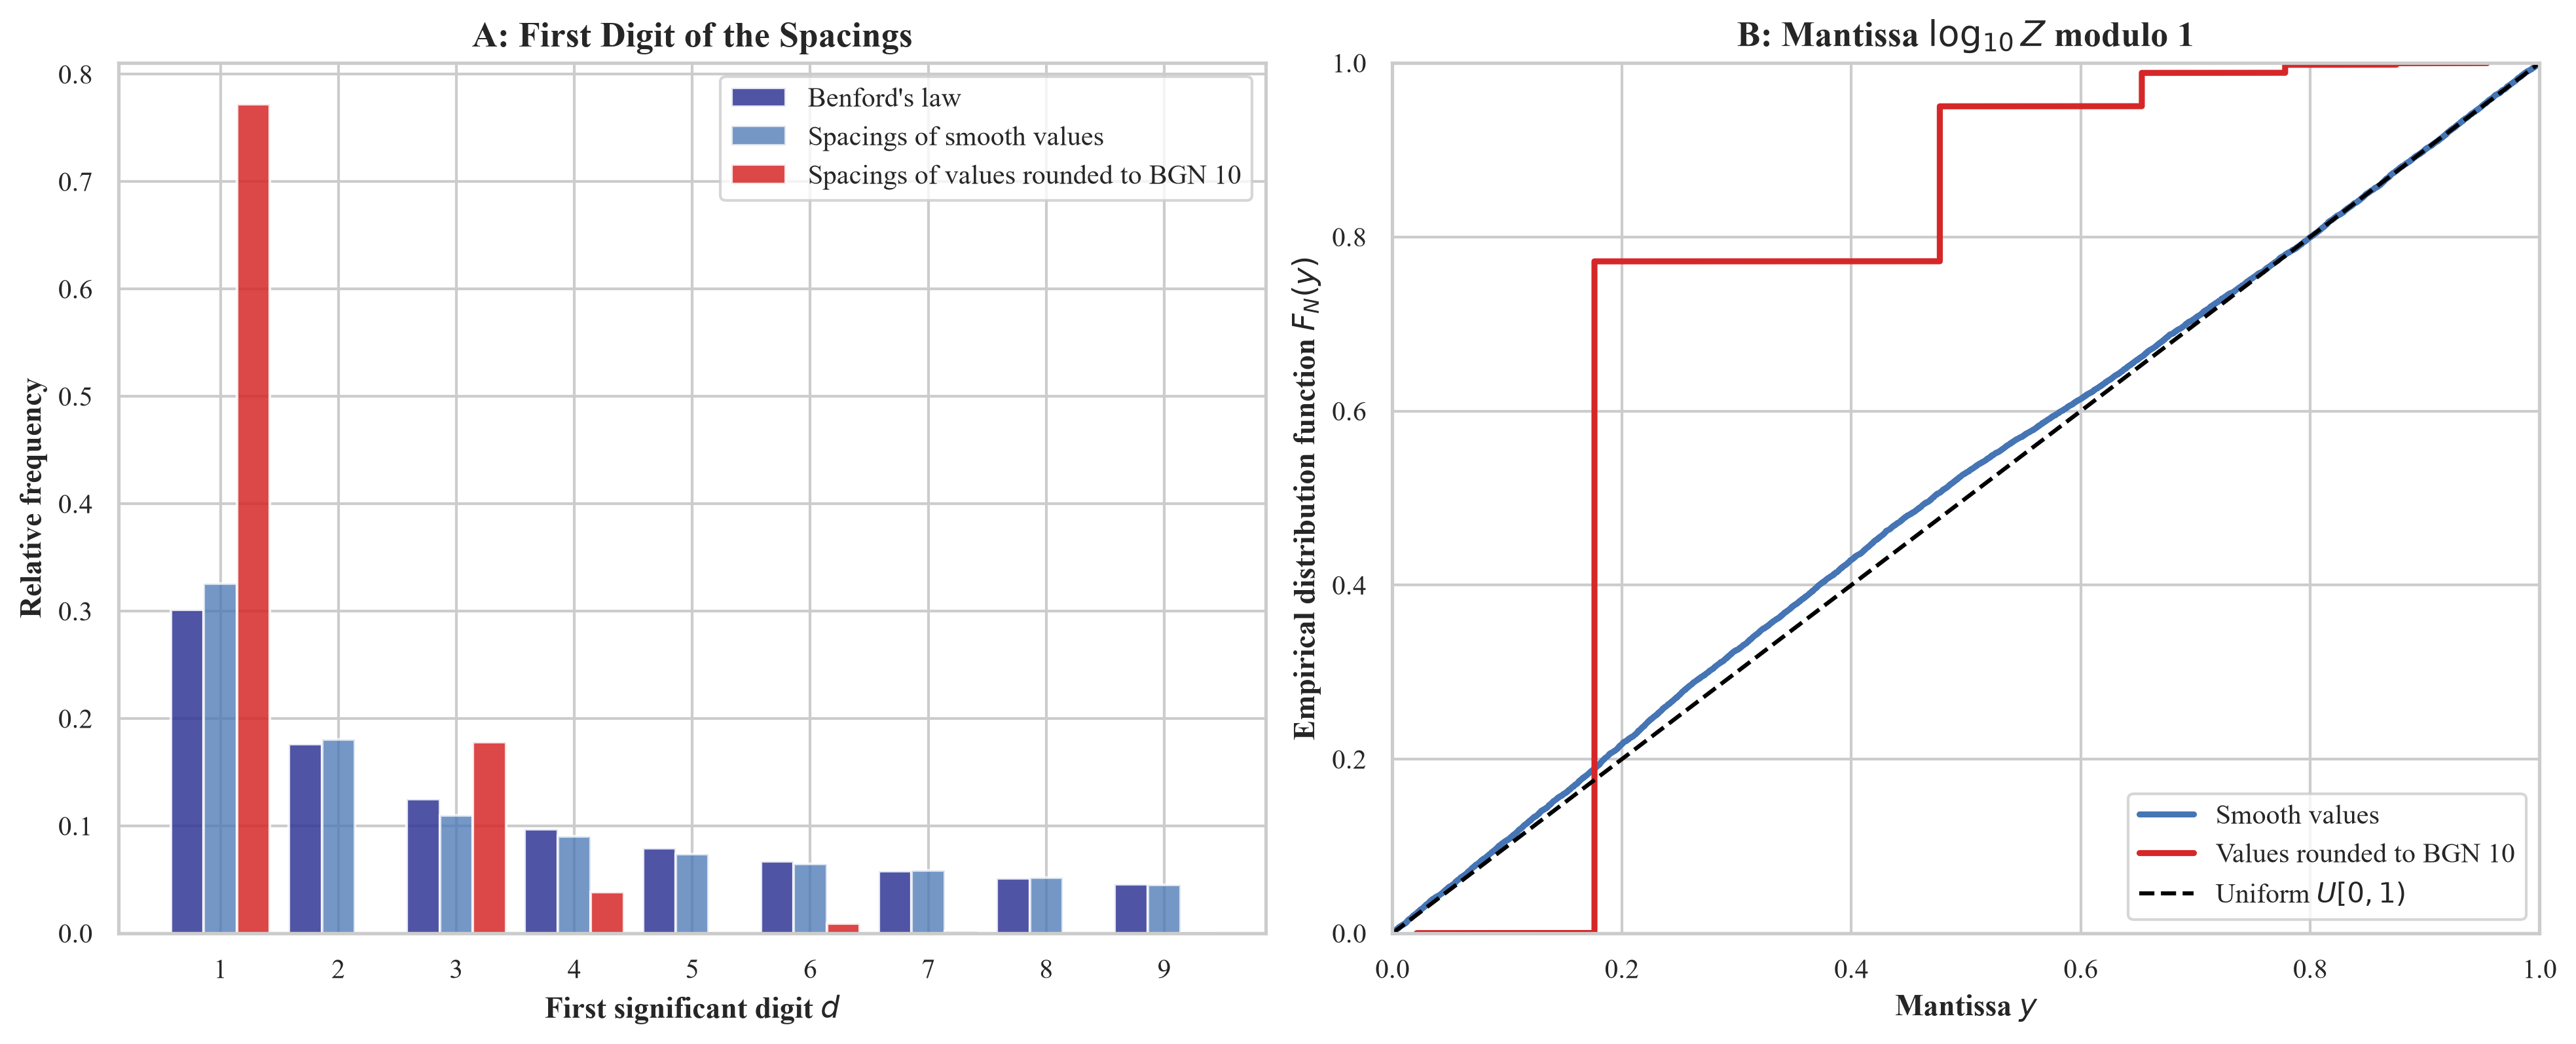

In [17]:
fig65, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2), constrained_layout=True)

width = 0.28
ax1.bar(digits - width, p_benford, width=width, color="#313695", alpha=0.85, label="Benford's law")
ax1.bar(digits, p_smooth, width=width, color="#4575b4", alpha=0.75, label="Spacings of smooth values")
ax1.bar(digits + width, p_rounded, width=width, color="#d62728", alpha=0.85, label="Spacings of values rounded to BGN 10")
ax1.set_title("A: First Digit of the Spacings")
ax1.set_xlabel(r"First significant digit $d$")
ax1.set_ylabel("Relative frequency")
ax1.set_xticks(digits)
ax1.legend(loc="upper right", frameon=True)

for mantissas, color, label in [(mant_smooth, "#4575b4", "Smooth values"), (mant_rounded, "#d62728", "Values rounded to BGN 10")]:
    ordered = np.sort(mantissas)
    ax2.plot(ordered, np.arange(1, len(ordered) + 1) / len(ordered), color=color, linewidth=2.2, label=label)
ax2.plot([0, 1], [0, 1], color="black", linestyle="--", linewidth=1.5, label=r"Uniform $U[0, 1)$")
ax2.set_title(r"B: Mantissa $\log_{10} Z$ modulo 1")
ax2.set_xlabel(r"Mantissa $y$")
ax2.set_ylabel(r"Empirical distribution function $F_N(y)$")
ax2.set_xlim(0, 1)
ax2.set_ylim(0, 1)
ax2.legend(loc="lower right", frameon=True)

plt.show()

**Figure 6.5.** First-digit frequencies (panel A) and mantissa distribution (panel B) of the normalised spacings of simulated smooth values and of the same values rounded to BGN 10.

*Source:* author's simulation based on Miller and Nigrini (2006).

### 6.7 Recovery of a Known Bunching (Proposition 2)

**Question.** Does the polynomial counterfactual recover the number of contracts that were moved below a threshold?

**Check.** Contract values are drawn from a smooth log-normal distribution. Of the contracts between 50,000 and 53,000 BGN, 70% are moved to the interval just below 50,000 BGN. The estimated excess mass below and missing mass above the threshold are compared with the known number of moved contracts (Palguta and Pertold, 2017; Szűcs, 2024).

**How to read.** The red line is the counterfactual fitted to the bins outside the window of 3,000 BGN around the threshold. The orange area is the excess mass and the yellow area the missing mass.

**What the figure is not.** It is a simulation with a known shift, not an estimate from the contract data. The estimator with the Poisson regression of Section 5.3 is applied to the data in a later step.

In [18]:
def bunching_estimator(
    contract_values: np.ndarray,
    threshold: float,
    bin_width: float = 1000.0,
    window: tuple[float, float] = (20000.0, 80000.0),
    delta_below: float = 3000.0,
    delta_above: float = 3000.0,
    degree: int = 4,
) -> dict[str, float | np.ndarray]:
    """Excess and missing mass around a threshold with a polynomial counterfactual.

    The polynomial is fitted to the log counts of the bins outside the manipulation window
    (Palguta and Pertold, 2017; Szűcs, 2024).
    """
    values = contract_values[(contract_values >= window[0]) & (contract_values <= window[1])]
    edges = np.arange(window[0], window[1] + bin_width, bin_width)
    counts, edges = np.histogram(values, bins=edges)
    centers = (edges[:-1] + edges[1:]) / 2.0

    excluded = (centers >= threshold - delta_below) & (centers <= threshold + delta_above)
    z = (centers - threshold) / 10000.0
    coefficients = np.polyfit(z[~excluded], np.log(np.maximum(counts[~excluded], 1.0)), deg=degree)
    counterfactual = np.exp(np.polyval(coefficients, z))

    below = (centers >= threshold - delta_below) & (centers < threshold)
    above = (centers >= threshold) & (centers <= threshold + delta_above)
    excess = float(np.sum(counts[below] - counterfactual[below]))
    missing = float(np.sum(counterfactual[above] - counts[above]))
    height = float(np.exp(np.polyval(coefficients, 0.0)))

    return {
        "centers": centers,
        "observed": counts,
        "counterfactual": counterfactual,
        "threshold": threshold,
        "delta_below": delta_below,
        "delta_above": delta_above,
        "excess_mass": excess,
        "missing_mass": missing,
        "normalized_excess": excess / height,
    }


# Simulated contract values with a known number of contracts moved below the threshold
rng = np.random.default_rng(ModelConfig.SEED)
contracts = rng.lognormal(mean=10.6, sigma=0.55, size=12000)
candidates = np.flatnonzero((contracts >= 50000.0) & (contracts <= 53000.0))
moved = rng.choice(candidates, size=int(len(candidates) * 0.70), replace=False)
contracts[moved] = rng.uniform(48200.0, 49950.0, size=len(moved))

bunch_res = bunching_estimator(contracts, threshold=50000.0)
excess_error = abs(bunch_res["excess_mass"] - len(moved)) / len(moved)
missing_error = abs(bunch_res["missing_mass"] - len(moved)) / len(moved)

assert excess_error < 0.25, f"Excess mass {bunch_res['excess_mass']:.0f} differs from the {len(moved)} moved contracts."
assert missing_error < 0.25, f"Missing mass {bunch_res['missing_mass']:.0f} differs from the {len(moved)} moved contracts."

print(f"Threshold:                       {bunch_res['threshold']:,.0f} BGN excl. VAT")
print(f"Contracts moved below it:        {len(moved)}")
print(f"Estimated excess mass:           {bunch_res['excess_mass']:.1f} (relative error {excess_error:.1%})")
print(f"Estimated missing mass above:    {bunch_res['missing_mass']:.1f} (relative error {missing_error:.1%})")
print(f"Excess mass relative to h(T):    {bunch_res['normalized_excess']:.2f}")

Threshold:                       50,000 BGN excl. VAT
Contracts moved below it:        328
Estimated excess mass:           309.6 (relative error 5.6%)
Estimated missing mass above:    312.9 (relative error 4.6%)
Excess mass relative to h(T):    1.93


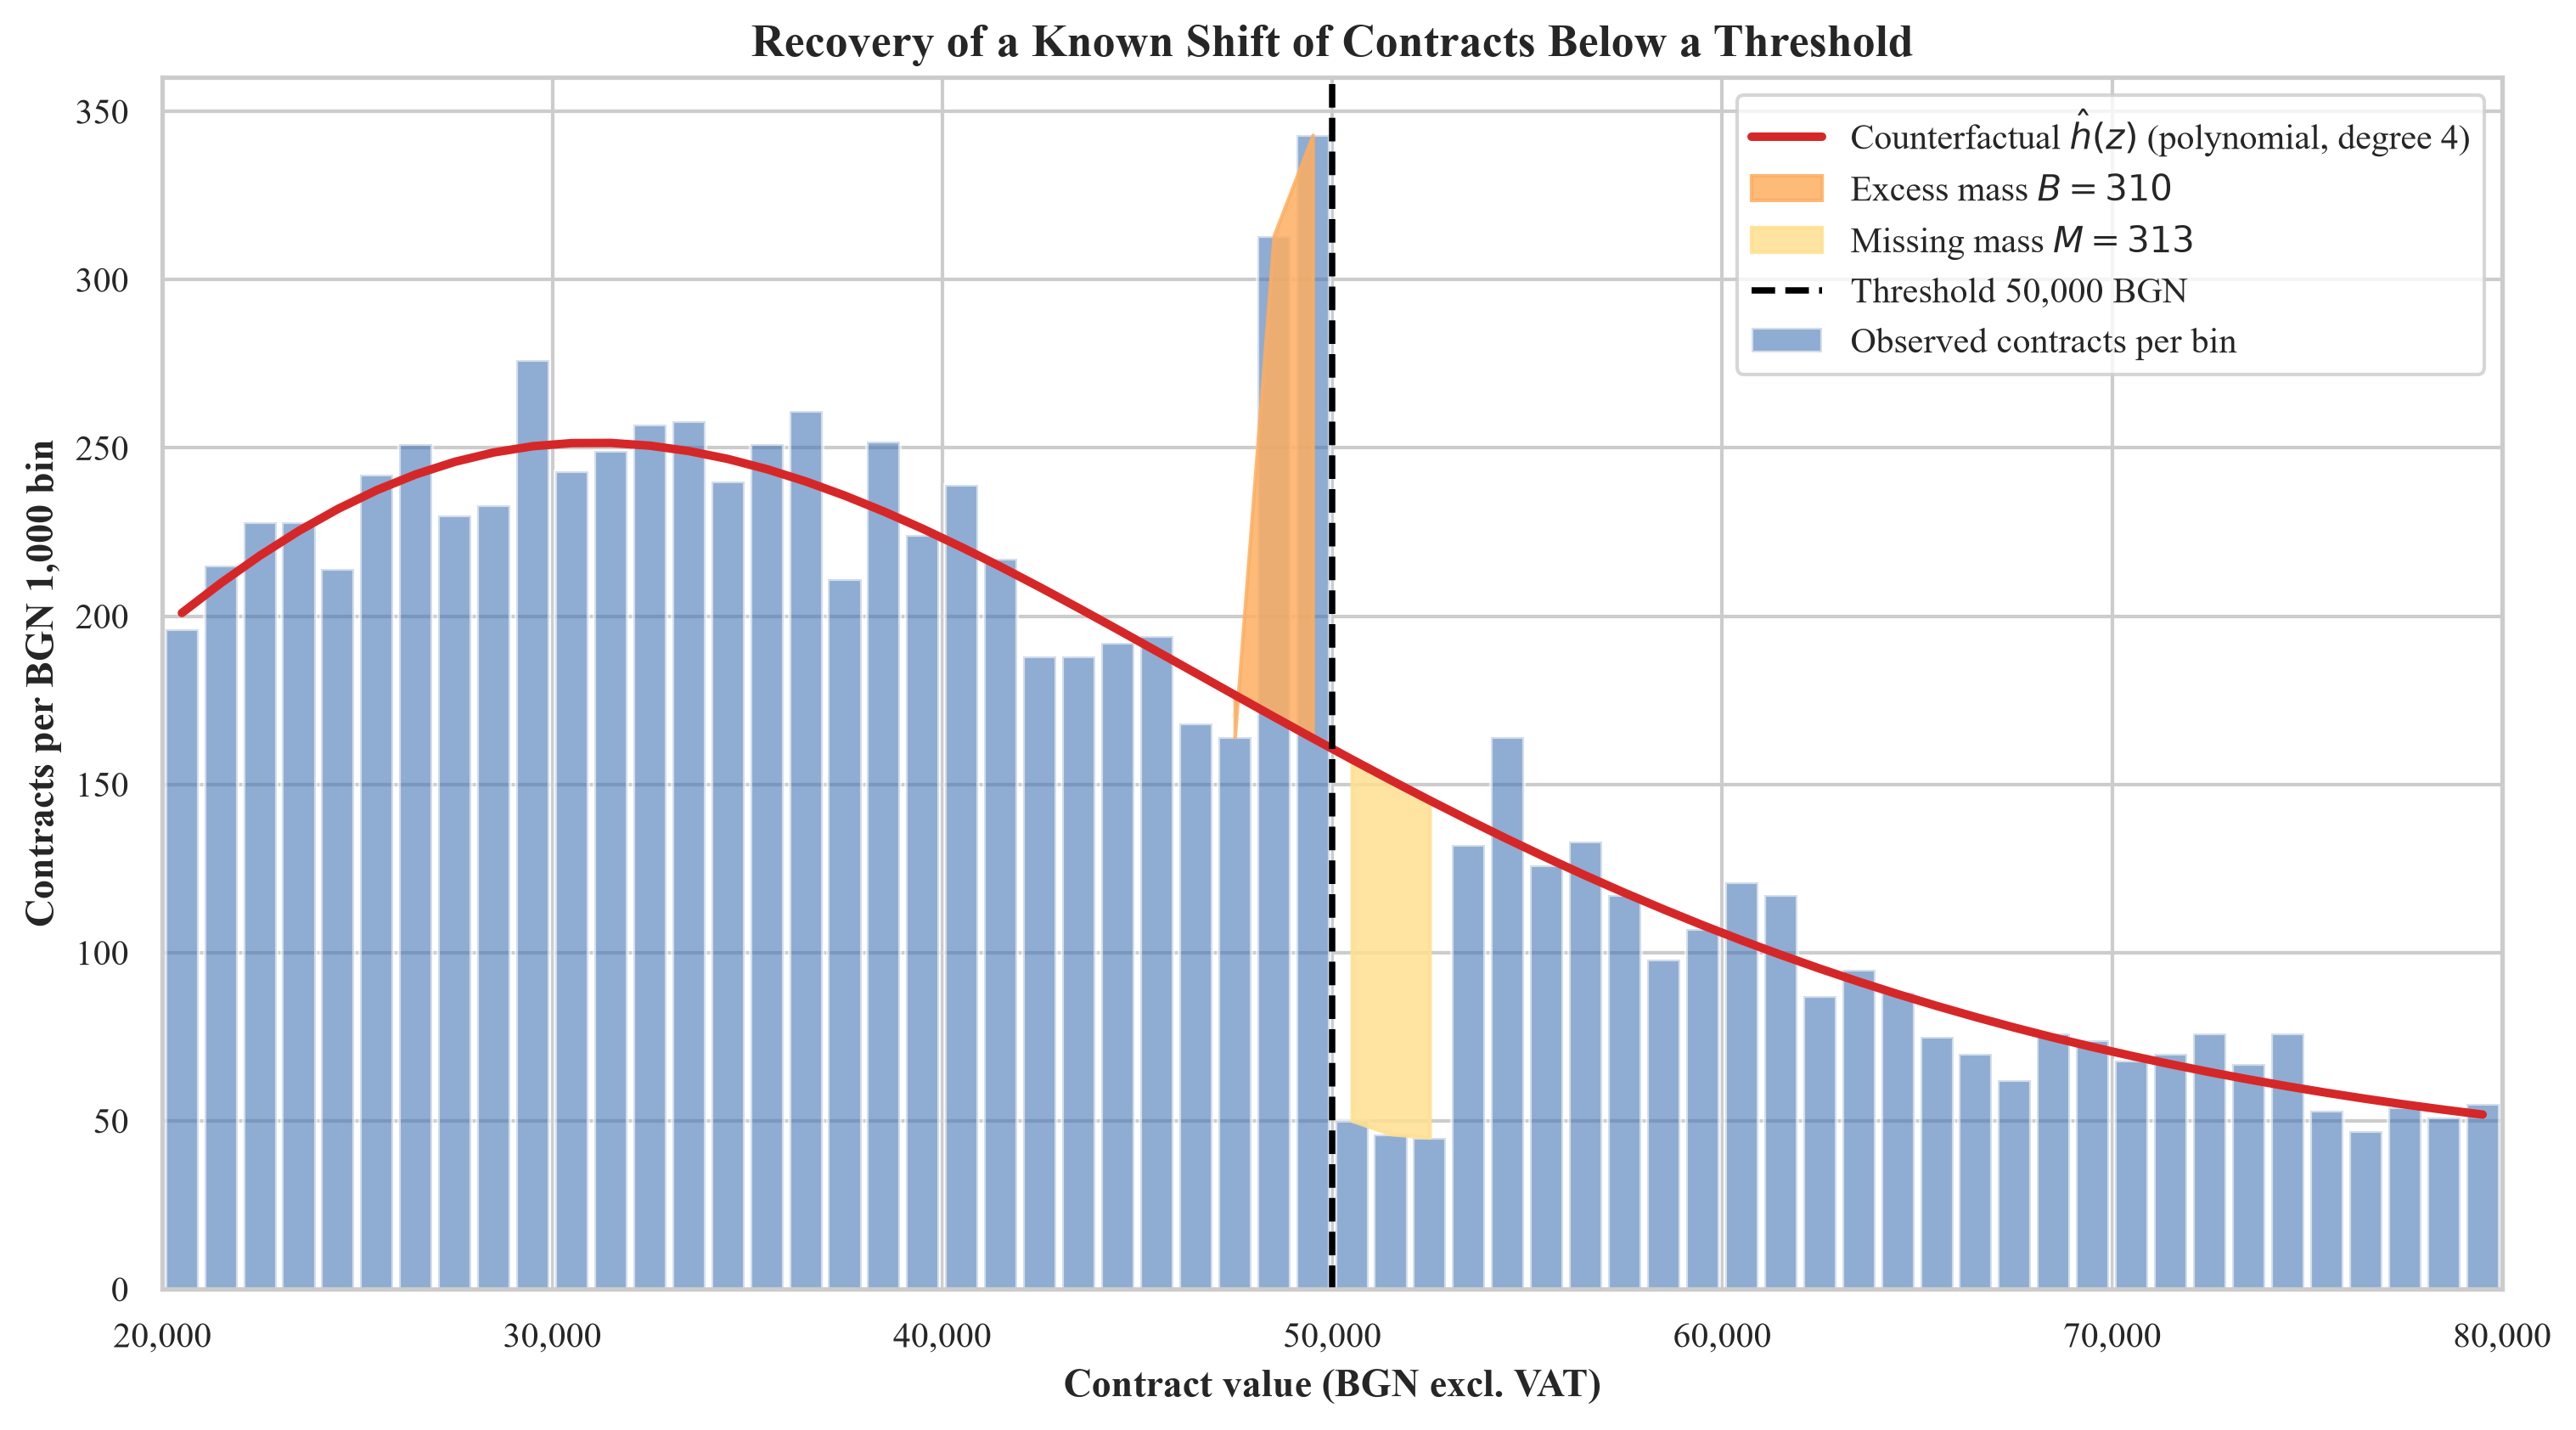

In [19]:
fig66, ax = plt.subplots(figsize=(10, 5.5), constrained_layout=True)

centers = bunch_res["centers"]
observed = bunch_res["observed"]
counterfactual = bunch_res["counterfactual"]
threshold = bunch_res["threshold"]

ax.bar(centers, observed, width=850.0, color="#4575b4", alpha=0.6, edgecolor="white", label="Observed contracts per bin")
ax.plot(centers, counterfactual, color="#d62728", linewidth=2.4, label=r"Counterfactual $\hat{h}(z)$ (polynomial, degree 4)")

below = (centers >= threshold - bunch_res["delta_below"]) & (centers < threshold)
ax.fill_between(centers[below], counterfactual[below], observed[below], color="#fdae61", alpha=0.85,
                label=f"Excess mass $B = {bunch_res['excess_mass']:.0f}$")
above = (centers >= threshold) & (centers <= threshold + bunch_res["delta_above"]) & (observed < counterfactual)
ax.fill_between(centers[above], observed[above], counterfactual[above], color="#fee090", alpha=0.85,
                label=f"Missing mass $M = {bunch_res['missing_mass']:.0f}$")
ax.axvline(threshold, color="black", linestyle="--", linewidth=1.8, label=f"Threshold {threshold:,.0f} BGN")

ax.set_title("Recovery of a Known Shift of Contracts Below a Threshold")
ax.set_xlabel("Contract value (BGN excl. VAT)")
ax.set_ylabel("Contracts per BGN 1,000 bin")
ax.set_xlim(20000, 80000)
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f"{int(v):,}"))
ax.legend(loc="upper right", frameon=True)

plt.show()

**Figure 6.6.** Observed counts, counterfactual density, excess mass below the threshold and missing mass above it for simulated contract values with a known shift.

*Source:* author's simulation based on Palguta and Pertold (2017) and Szűcs (2024).

### 6.8 Summary of the Checks

The assertions below repeat the invariants of the checks above and fail if any of them is violated.

In [20]:
assert res_p1["cs_gap"] > 0.0 and res_p1["min_ratio"] >= 1.0 - 1e-9
print("Proposition 1: Cauchy-Schwarz gap is positive and no pair has a BiCM expectation below the urn expectation.")

assert res_thm1["mean_fdp"] <= res_thm1["nominal_fdr"]
print(f"Theorem 1: mean false discovery proportion {res_thm1['mean_fdp']:.4f} does not exceed alpha = {res_thm1['nominal_fdr']}.")

assert np.isclose(pmf_dft.sum(), 1.0, atol=1e-9) and np.all(pmf_dft >= 0.0)
print("Poisson-binomial: the pmf sums to one, is non-negative and equals the convolution.")

assert np.all(np.abs(nc_res["lift"]) <= 1.0 + 1e-10)
assert np.all(nc_res["backbone"][group_links]), "The noise-corrected filter dropped a link of the tight group."
print("Noise-corrected backbone: the transformed lift lies in [-1, 1] and all links of the tight group are kept.")

assert 0.0 <= c_tight <= 1.0 and 0.0 <= e_tight <= 1.0
assert c_tight > c_hub and e_tight > e_open and e_tight > e_hub
print("Coherence and exclusivity: both lie in [0, 1] and the tight group scores highest on exclusivity and above the hub on coherence.")

assert 0.0285 < digit_deviation < 0.030 and d_rounded > 3.0 * d_smooth
print("Theorem 2: the first-digit deviation of the exponential distribution is 0.029 to three decimals; rounded values are separated from smooth ones.")

assert excess_error < 0.25 and missing_error < 0.25
print("Proposition 2: the estimator recovers the known excess and missing mass within 25%.")

Proposition 1: Cauchy-Schwarz gap is positive and no pair has a BiCM expectation below the urn expectation.
Theorem 1: mean false discovery proportion 0.0078 does not exceed alpha = 0.01.
Poisson-binomial: the pmf sums to one, is non-negative and equals the convolution.
Noise-corrected backbone: the transformed lift lies in [-1, 1] and all links of the tight group are kept.
Coherence and exclusivity: both lie in [0, 1] and the tight group scores highest on exclusivity and above the hub on coherence.
Theorem 2: the first-digit deviation of the exponential distribution is 0.029 to three decimals; rounded values are separated from smooth ones.
Proposition 2: the estimator recovers the known excess and missing mass within 25%.


## 7. Data Ingestion, Register Enrichment and Normalisation of Contract Values

This section describes how the two source files were turned into the tables that all later sections use, and it starts from those tables. The first source is the open-data export of ISUN 2020 (2026), which holds the projects, contracts and organisations of all operational programmes. The second is the register of schools of 29 March 2023, which lists 2,271 institutions and the funds assigned to each of them for the procedure. Both sources were read once, outside the notebook. Procedure BG-RRP-1.015 was kept and the result was stored as working tables in `data/`; the tables derived in this section are written to `data/derived/`. The notebook reads the working tables only, so it runs without the source files.

Four features of the data call for the steps below.

* **No currency and no tax basis.** The schema of the file stores `Amount`, `TotalValue` and `Value` as plain decimal numbers. A value carries no currency and no mark for value added tax. The limits of Section 2 are net of VAT and the study reports amounts in euro, so each value must be converted to euro and to one VAT basis before it is compared with them (Bulgaria, 2016; Bulgaria, 2023). Sections 7.6 and 7.7 do this.
* **One description for all contracts.** All 11,128 contracts carry the same description text, so the object of a contract cannot be read from the data. Section 7.8 therefore infers the role of a supplier from its name.
* **Dates.** A contract has a signature date and a project has a start date. A signature before the start of the project is a risk indicator, which Section 7.9 measures. Timestamps that stand in an order the procedure does not allow are among the red flags that automated screening of procurement files looks for (OECD, 2016).
* **Personal data.** The register file has columns with an address, an e-mail, a telephone number and the name and personal number of the representative, and ISUN lists sole traders and suppliers without a registration number. The columns from `Адрес` onward were dropped when the register was read, the names of such suppliers were replaced by a label, and no personal number is stored. Section 7.10 checks the written tables.

### 7.2 Extraction of the Procedure

The open-data file of ISUN is an XML document of 162 MB, and its schema (an XSD) stores `Amount`, `TotalValue` and `Value` as plain decimal numbers. The file was read once as a stream, element by element, and each element was discarded after it had been read, so memory use did not grow with the size of the file.

* **Projects.** A project belongs to the procedure when its `Id` starts with `BG-RRP-1.015`. For each project the extraction kept the identifier of its beneficiary, the `TotalValue`, the start date (`InitialDate`) and the payments. The payments of a project are the sum of its `ActuallyPaidAmount` values; six projects have none.
* **Contracts.** A contract belongs to the procedure when its `ContractId` starts with the same prefix, and the project of a contract is the part of its identifier before the opening bracket. The extraction kept the identifier of the contract, the identifier of its supplier, the `Amount`, the date of signature and the number of subcontractors. All timestamps of the file are midnight values, so only the date was kept. All 11,128 contracts carry one and the same description, which is therefore not kept.
* **Organisations.** Only the organisations that are the beneficiary of a project or the supplier of a contract were kept, with their registration number (`EntityUin`), name, town, municipality and district.
* **Personal data.** The name of a supplier that is a natural person or a sole trader was replaced by the label `[natural person]` or `[sole trader]`, and its town, municipality and district were left empty. A supplier was treated so when it has no registration number, when its name starts with `Адвокат` or contains `ЕТ` or `Едноличен търговец`, or when it consists of two to four words, the last of which has a surname ending, and contains no legal form such as `ЕООД`, `АД`, `Училище` or `Община`. The names of schools were kept.

The result is three tables of 2,228 projects, 11,128 contracts and 3,973 organisations, stored in `data/isun_projects.csv`, `data/isun_contracts.csv` and `data/isun_entities.csv`. The cell below reads them and fixes the names and paths that the later cells use.

In [21]:
import re
from collections.abc import Sequence

import pandas as pd
from IPython.display import display

ISUN_PROCEDURE: Final[str] = "BG-RRP-1.015"
UNDETERMINED: Final[str] = "undetermined"
VAT_FACTOR: Final[float] = 1.0 + ThresholdConfig.VAT_RATE

WORK_PROJECTS: Final[Path] = PathConfig.DATA_DIR / "isun_projects.csv"
WORK_CONTRACTS: Final[Path] = PathConfig.DATA_DIR / "isun_contracts.csv"
WORK_ENTITIES: Final[Path] = PathConfig.DATA_DIR / "isun_entities.csv"
WORK_REGISTER: Final[Path] = PathConfig.DATA_DIR / "schools_register.csv"
WORK_ROLES: Final[Path] = PathConfig.DATA_DIR / "vendor_roles.csv"
OUT_CONTRACTS: Final[Path] = PathConfig.DERIVED_DIR / "contracts.csv"
OUT_TOTALS: Final[Path] = PathConfig.DERIVED_DIR / "normalized_totals.csv"
OUT_CLASSES: Final[Path] = PathConfig.DERIVED_DIR / "project_classes.csv"

PERSON_LABEL: Final[str] = "[natural person]"
SOLE_TRADER_LABEL: Final[str] = "[sole trader]"


def read_work_csv(path: Path, numeric: Sequence[str] = ()) -> pd.DataFrame:
    """Read a working table as text, so identifiers keep their leading zeros and empty cells stay empty."""
    assert path.is_file(), f"The working table {path} is missing"
    table = pd.read_csv(path, dtype=str, keep_default_na=False, encoding="utf-8")
    for column in numeric:
        table[column] = pd.to_numeric(table[column])
    return table


def write_work_csv(table: pd.DataFrame, path: Path) -> None:
    """Write a working table as UTF-8 CSV."""
    path.parent.mkdir(parents=True, exist_ok=True)
    table.to_csv(path, index=False, encoding="utf-8", lineterminator="\n")


projects = read_work_csv(WORK_PROJECTS, ["total_value", "actually_paid_amount"])
contracts = read_work_csv(WORK_CONTRACTS, ["amount_raw", "subcontractors_count"])
contracts["subcontractors_count"] = contracts["subcontractors_count"].astype(int)
entities = read_work_csv(WORK_ENTITIES)

print(f"{len(projects):,} projects, {len(contracts):,} contracts and {len(entities):,} referenced organisations of procedure {ISUN_PROCEDURE}.")


2,228 projects, 11,128 contracts and 3,973 referenced organisations of procedure BG-RRP-1.015.


### 7.3 Register of Schools

The register assigns funds for the procedure to each of its 2,271 institutions. Column 23, `Общо средства за изграждане на училищна STEM среда в лв. с ДДС`, is the ceiling of the school in leva including VAT, and it is the reference of the currency test in Section 7.6. Columns 9 to 23 are numbers, and the Bulstat is kept as text so that leading zeros remain. The columns from `Адрес` onward were dropped immediately after the register was read, and the table was stored in `data/schools_register.csv`, which the cell below reads.

In [22]:
REG_OBLAST: Final[str] = "Област"
REG_MUNICIPALITY: Final[str] = "Община"
REG_SETTLEMENT: Final[str] = "Населено място"
REG_BULSTAT: Final[str] = "Булстат"
REG_NAME: Final[str] = "Пълно наименование на институция"
REG_FUNDING: Final[str] = "Вид на институцията според финансирането"
REGISTER_KEPT_COLUMNS: Final[int] = 24  # columns 0-23 are stored; from "Адрес" onward the register holds personal data
REGISTER_TEXT_COLUMNS: Final[int] = 9  # columns 0-8 are text, columns 9-23 are numbers


schools_register = read_work_csv(WORK_REGISTER)
for column in schools_register.columns[REGISTER_TEXT_COLUMNS:]:
    schools_register[column] = pd.to_numeric(schools_register[column])

REG_BUDGET: Final[str] = schools_register.columns[23]
assert schools_register.shape[1] == REGISTER_KEPT_COLUMNS
assert schools_register[REG_BULSTAT].is_unique, "Register Bulstat values are not unique"
assert schools_register[REG_BUDGET].notna().all()

print(f"Register read: {len(schools_register):,} institutions, {schools_register.shape[1]} columns kept.")
print(f"Ceiling column: {REG_BUDGET!r}")
print(f"Sum of the ceilings: {schools_register[REG_BUDGET].sum() / ThresholdConfig.EUR_BGN:,.2f} EUR incl. VAT "
      f"({schools_register[REG_BUDGET].sum():,.2f} BGN as stated in the register); "
      f"{schools_register[REG_OBLAST].nunique()} oblasts, {schools_register[REG_MUNICIPALITY].nunique()} municipalities.")
print(schools_register[REG_FUNDING].value_counts().to_string())

Register read: 2,271 institutions, 24 columns kept.
Ceiling column: 'Общо средства за изграждане на училищна STEM среда в лв. с ДДС'
Sum of the ceilings: 273,201,377.42 EUR incl. VAT (534,335,450.00 BGN as stated in the register); 28 oblasts, 264 municipalities.
Вид на институцията според финансирането
Общинско    1976
Държавно     295


### 7.4 Raw Invariants and Data Quality

Ten facts of the extracted data are asserted before anything is transformed. They fix the extraction: a change in a count or in a sum would mean that the file or the code has changed. The sums are those of the values as stored. They mix currencies, which is why Section 7.7 normalises them.

In [23]:
# Identify the school of each project and the supplier of each contract
entity_uin = entities.set_index("entity_id")["uin"]
projects["school_bulstat"] = projects["beneficiary_entity_id"].map(entity_uin)
assert projects["school_bulstat"].notna().all(), "A project beneficiary is missing from the organisation table"

contracts = contracts.merge(projects[["project_id", "project_start"]], on="project_id", how="left")
contracts["delta_t_days"] = (pd.to_datetime(contracts["signature_date"]) - pd.to_datetime(contracts["project_start"])).dt.days

unique_contractors = contracts["vendor_id"].unique()  # the empty identifier of one contract counts as one value
raw_total_amount = float(contracts["amount_raw"].sum())
raw_total_value = float(projects["total_value"].sum())
raw_total_paid = float(projects["actually_paid_amount"].sum())
predated = contracts[contracts["delta_t_days"] < 0]
count_predated_contracts = len(predated)
sum_predated_raw_amount = float(predated["amount_raw"].sum())
register_rows = len(schools_register)
num_oblasts = schools_register[REG_OBLAST].nunique()
isun_register_bulstat_matches = int(projects["school_bulstat"].isin(set(schools_register[REG_BULSTAT])).sum())

assert len(projects) == 2228, f"Expected 2228 projects, got {len(projects)}"
assert len(contracts) == 11128, f"Expected 11128 contracts, got {len(contracts)}"
assert len(unique_contractors) == 1755, f"Expected 1755 contractors, got {len(unique_contractors)}"
assert np.isclose(raw_total_amount, 349191095.71, atol=1e-2), f"Raw Amount mismatch: {raw_total_amount}"
assert np.isclose(raw_total_value, 265849404.90, atol=1e-2), f"Raw TotalValue mismatch: {raw_total_value}"
assert np.isclose(raw_total_paid, 259552753.81, atol=1e-2), f"Raw ActuallyPaidAmount mismatch: {raw_total_paid}"
assert count_predated_contracts == 654, f"Expected 654 contracts signed before project start, got {count_predated_contracts}"
assert np.isclose(sum_predated_raw_amount, 14358203.47, atol=1e-2), f"Predated raw amount mismatch: {sum_predated_raw_amount}"
assert num_oblasts == 28, f"Expected 28 oblasts, got {num_oblasts}"
assert register_rows == 2271, f"Expected 2271 register rows, got {register_rows}"
assert isun_register_bulstat_matches == 2228, f"Expected 2228 Bulstat matches, got {isun_register_bulstat_matches}"

print("All ten raw invariants hold.")
print(f"  projects                      {len(projects):>14,}")
print(f"  contracts                     {len(contracts):>14,}")
print(f"  distinct supplier identifiers {len(unique_contractors):>14,}")
print(f"  sum of Contract/Amount        {raw_total_amount:>17,.2f}")
print(f"  sum of Project/TotalValue     {raw_total_value:>17,.2f}")
print(f"  sum of ActuallyPaidAmount     {raw_total_paid:>17,.2f}")
print(f"  contracts with delta t < 0    {count_predated_contracts:>14,}  (raw amount {sum_predated_raw_amount:,.2f})")
print(f"  register rows / oblasts       {register_rows:>8,} / {num_oblasts}")
print(f"  projects matched by Bulstat   {isun_register_bulstat_matches:>14,}")

All ten raw invariants hold.
  projects                               2,228
  contracts                             11,128
  distinct supplier identifiers          1,755
  sum of Contract/Amount           349,191,095.71
  sum of Project/TotalValue        265,849,404.90
  sum of ActuallyPaidAmount        259,552,753.81
  contracts with delta t < 0               654  (raw amount 14,358,203.47)
  register rows / oblasts          2,271 / 28
  projects matched by Bulstat            2,228


In [24]:
vendor_table = entities[entities["entity_id"].isin(contracts["vendor_id"])]
unregistered_vendor_ids = set(vendor_table.loc[vendor_table["uin"] == "", "entity_id"])
contract_counts = contracts.groupby("project_id").size()
quality_checks = [
    ("Contracts with a value of zero or less", int((contracts["amount_raw"] <= 0).sum()), "contracts"),
    ("Contracts without a supplier identifier", int((contracts["vendor_id"] == "").sum()), "contracts"),
    ("Contracts of suppliers without a registration number", int(contracts["vendor_id"].isin(unregistered_vendor_ids).sum()), "contracts"),
    ("Contracts signed more than five years from the project start", int((contracts["delta_t_days"].abs() > 5 * 365).sum()), "contracts"),
    ("Surplus rows of contract identifiers that occur more than once", int(contracts["contract_id"].duplicated().sum()), "contracts"),
    ("Contract rows identical in every stored field", int(contracts.duplicated(subset=["contract_id", "vendor_id", "amount_raw", "signature_date", "subcontractors_count"], keep=False).sum()), "contracts"),
    ("Projects without any contract", int((~projects["project_id"].isin(contract_counts.index)).sum()), "projects"),
    ("Projects without a payment record", int((projects["actually_paid_amount"] == 0).sum()), "projects"),
    ("Projects with a total value of zero or less", int((projects["total_value"] <= 0).sum()), "projects"),
    ("Schools with two projects", int(projects["beneficiary_entity_id"].duplicated().sum()), "projects"),
]
display(pd.DataFrame(quality_checks, columns=["check", "count", "unit"]).style.hide(axis="index"))

check,count,unit
Contracts with a value of zero or less,13,contracts
Contracts without a supplier identifier,1,contracts
Contracts of suppliers without a registration number,45,contracts
Contracts signed more than five years from the project start,2,contracts
Surplus rows of contract identifiers that occur more than once,454,contracts
Contract rows identical in every stored field,52,contracts
Projects without any contract,5,projects
Projects without a payment record,6,projects
Projects with a total value of zero or less,1,projects
Schools with two projects,1,projects


The table above lists features of the data that later steps must allow for. Nothing has been changed or removed.

* The `contract_id` is not a key. It repeats in 454 surplus rows, and 52 rows are identical in every stored field. Each row is kept as one contract, because the counts of the invariants refer to rows. A join must therefore use the project and the supplier as well as the contract identifier.
* 13 contracts have a value of exactly zero, and one contract has no supplier identifier. 22 suppliers have no registration number.
* Two contracts have a signature date more than five years from the project start, in 2014 and in 2046. A recording error is likely.
* Five projects have no contract, six projects have no payment record and one project has a total value of zero. The last is `BG-RRP-1.015-0449` of the primary school `Aleko Konstantinov` in Dobromir (Ruen municipality), which has neither a contract nor a payment; the register assigns the school a ceiling of 60,600 leva (30,984.29 euro) including VAT. The project is kept, and Section 7.6 leaves it undetermined, as it does every project without a contract.
* One school has two projects: the secondary school `Dimcho Debelyanov` in Burgas (Bulstat 000042533) with `BG-RRP-1.015-1450` and `BG-RRP-1.015-2204`. The shared Bulstat is correct. The register lists the school once, so both projects are matched to the same row and are compared with the same ceiling of 363,600 leva (185,905.73 euro) including VAT in Sections 7.5 and 7.6.

### 7.5 Register Enrichment

Each project is joined to the register by the Bulstat of its school (`EntityUin` in ISUN, `Булстат` in the register). In the register as received, the Bulstat of 2,075 of the 2,228 projects is found. Of these schools, 2,047 lie in the same oblast, municipality and settlement in both files, and the other 28 write the place differently, for example `Добрич-град` and `Добрич`, so the matching Bulstat values are correct. For the other 153 projects the register lists the school under another Bulstat.

The Bulstat of these 153 schools was therefore corrected in the register before it was stored. The school was looked up by its oblast, municipality and settlement among the schools of the register that no Bulstat match had taken. The place was normalised: the case is ignored, the prefix `гр.` or `с.` and a bracketed note are removed, and so is the suffix `-град`. A single school there was the match. Where there were several, the normalised name decided, but only if its similarity was at least 0.6 and at least 0.1 above that of the second best. In a test on the 2,075 matched schools with their Bulstat hidden, this rule found 2,053 of them, all correctly. It found 150 of the 153 schools. The other three were identified by their name and checked by hand: `P. K. Yavorov` in Пловдив, `Ivan Vazov` in Сопот, and the 172nd school `Hristo Botev`, which the register places in Нови Искър and ISUN in София. The old and new Bulstat of the 153 schools, with their names and places in both files, were recorded in a separate correction log. In one row the register still holds a school under its name from before the merger of 15 September 2025, `Hristo Botev` in Съединение, whose successor `Nedyalka Shileva` has another Bulstat and another code NEISPUO. This row has the Bulstat 181446602, the code 1600035 (instead of 1603301) and the name `Sredno uchilishte „Nedyalka Shileva“ – gr. Saedinenie` of the successor, which the Commercial Register confirms. No other cell of the register was changed.

After the correction all 2,228 projects match by their Bulstat. A school without a match would be matched on its name and settlement, after the case, the quotation marks and a trailing town after a dash are removed, and only if the pair is unique in the register. No project needs this step any more. The column `oblast_ruo` holds the oblast of the register, which has 28 values.

The corrected Bulstat values can be checked with the test of Section 7.6: a corrected value should be as likely as an original one to give a total value that falls in one of the four windows. For the 153 corrected schools 89.5% of the total values fall in a window, against 89.6% for the 2,075 others.

In [25]:
def normalise_school_name(name: str) -> str:
    """Lower-case a school name and remove quotation marks and a trailing town after a dash."""
    text = name.lower().replace("ё", "е")
    text = re.sub(r"\s+[-–]\s+(?:гр\.?|с\.?|град|село)?\s*[а-я\- ]+$", "", text)
    text = re.sub(r"[\"„“”'`«»\.,]", " ", text)
    return " ".join(text.split())


def normalise_settlement(name: str) -> str:
    """Lower-case a settlement name and remove the prefix for town or village."""
    return re.sub(r"^(?:гр|с|град|село)\.?\s*", "", name.lower()).strip()


def enrich_projects(project_table: pd.DataFrame, entity_table: pd.DataFrame, register: pd.DataFrame) -> pd.DataFrame:
    """Attach the register data of each school to its project.

    The school is first matched by its Bulstat. A school without a match is matched on the normalised
    name and settlement, but only when that pair is unique in the register. The rest keep the
    municipality and oblast of the ISUN record, and their funding type is undetermined.
    """
    entity_index = entity_table.set_index("entity_id")
    out = project_table.copy()
    by_bulstat = register.set_index(REG_BULSTAT)

    register_keys = register[REG_NAME].map(normalise_school_name) + "|" + register[REG_SETTLEMENT].map(normalise_settlement)
    unique_key = ~register_keys.duplicated(keep=False)
    fallback = pd.Series(register.loc[unique_key, REG_BULSTAT].to_numpy(), index=register_keys[unique_key].to_numpy())
    school_key = (out["beneficiary_entity_id"].map(entity_index["name"]).map(normalise_school_name) + "|"
                  + out["beneficiary_entity_id"].map(entity_index["city"]).map(normalise_settlement))

    direct = out["school_bulstat"].isin(by_bulstat.index)
    via_name = ~direct & school_key.isin(fallback.index)
    out["register_match"] = np.select([direct, via_name], ["bulstat", "name_settlement"], default="none")
    out["register_bulstat"] = np.where(direct, out["school_bulstat"], np.where(via_name, school_key.map(fallback), ""))

    matched = by_bulstat.reindex(out["register_bulstat"]).set_index(out.index)
    found = out["register_match"] != "none"
    oblast_spelling = {name.lower(): name for name in register[REG_OBLAST].unique()}
    isun_oblast = out["beneficiary_entity_id"].map(entity_index["district"]).str.lower().map(oblast_spelling)
    assert isun_oblast.notna().all(), "An ISUN district has no counterpart among the register oblasts"

    out["register_budget_bgn_incl_vat"] = matched[REG_BUDGET].where(found)  # leva, as stated in the register
    out["register_budget_eur_incl_vat"] = out["register_budget_bgn_incl_vat"] / ThresholdConfig.EUR_BGN
    out["municipality"] = matched[REG_MUNICIPALITY].where(found, out["beneficiary_entity_id"].map(entity_index["municipality"]))
    out["oblast_ruo"] = matched[REG_OBLAST].where(found, isun_oblast)
    out["funding_type"] = matched[REG_FUNDING].where(found, UNDETERMINED)
    return out


projects = enrich_projects(projects, entities, schools_register)
assert (projects["register_match"] == "bulstat").sum() == isun_register_bulstat_matches
assert projects["register_bulstat"][projects["register_match"] != "none"].duplicated().sum() == 1, "Expected one school with two projects"

match_summary = projects["register_match"].value_counts().rename_axis("register_match").reset_index(name="projects")
display(match_summary.style.hide(axis="index"))
print(projects.loc[projects["register_match"] != "none", "funding_type"].value_counts().to_string())

register_match,projects
bulstat,2228


funding_type
Общинско    1937
Държавно     291


### 7.6 Currency and VAT Classification

**Question.** In which currency, and with or without VAT, has the value of a project been recorded?

**Rule.** The ceiling of a school in the register is in leva including VAT. If a school records its whole ceiling, the recorded value divided by the ceiling is one of four numbers, given the exchange rate of 1.95583 leva per euro and the VAT rate of 20%:

$$\tau_1 = 1 \ (\text{BGN, incl. VAT}), \qquad \tau_2 = \frac{1}{1.20} \approx 0.8333 \ (\text{BGN, excl. VAT}),$$

$$\tau_3 = \frac{1}{1.95583} \approx 0.5113 \ (\text{EUR, incl. VAT}), \qquad \tau_4 = \frac{1}{1.95583 \times 1.20} \approx 0.4261 \ (\text{EUR, excl. VAT}).$$

For project $i$ let $R_i = \sum_{k \in \text{Contracts}(i)} A_k \,/\, \text{Ceiling}_i$ be the ratio of its contracts and $R_i^{TV} = \text{TotalValue}_i \,/\, \text{Ceiling}_i$ the ratio of its total value. A ratio belongs to class $j$ if $|R - \tau_j| / \tau_j \le 0.03$. The four windows do not overlap, which the code asserts. A project outside all windows, a project without a register ceiling and a project without contracts are undetermined by the ceiling.

**Second step: the payments.** It applies only to the projects that the ceiling leaves undetermined. The payment of a project, $P_i$ (the sum of its `ActuallyPaidAmount`), is in euro, and ISUN records it for the project as a whole and not for each supplier. A project may have been paid less than it contracted, for example when a contract was only partly carried out or is financed from the own funds of the school, so a ratio outside all windows decides nothing. The currency of the contracts follows from $P_i / \sum_k A_k$:

$$P_i \,/\, \textstyle\sum_k A_k \in \{1,\ 1.20\} \Rightarrow \text{EUR}, \qquad P_i \,/\, \textstyle\sum_k A_k \in \{\tfrac{1}{1.95583},\ \tfrac{1.20}{1.95583}\} \Rightarrow \text{BGN},$$

each with the window of $\pm 3\%$, and the currency of the total value follows in the same way from $P_i / \text{TotalValue}_i \in \{1, \tfrac{1}{1.95583}\}$. These four windows do not overlap either. The payment decides the currency only, not the VAT basis.

**Third step: the default.** A project that neither step classifies is taken to be in euro, so that no project is left without a currency. Its basis is recorded as `default`.

**Dates and VAT.** A contract signed from 1 January 2026 is in euro whatever the class of its project, because the lev is no longer in use from that date. An earlier contract takes the currency of its project. The VAT basis of a contract is that of its project and is known only where the ceiling fixes it; the other contracts are assumed to include VAT (Section 7.7).

In [26]:
RATIO_TOLERANCE: Final[float] = 0.03
RATIO_TARGETS: Final[tuple[tuple[float, str, str], ...]] = (
    (1.0, "BGN", "incl_vat"),
    (1.0 / VAT_FACTOR, "BGN", "excl_vat"),
    (1.0 / ThresholdConfig.EUR_BGN, "EUR", "incl_vat"),
    (1.0 / (ThresholdConfig.EUR_BGN * VAT_FACTOR), "EUR", "excl_vat"),
)
CLASS_LABELS: Final[dict[tuple[str, str], str]] = {
    ("BGN", "incl_vat"): "BGN incl. VAT",
    ("BGN", "excl_vat"): "BGN excl. VAT",
    ("EUR", "incl_vat"): "EUR incl. VAT",
    ("EUR", "excl_vat"): "EUR excl. VAT",
    (UNDETERMINED, UNDETERMINED): "undetermined",
}


def classify_ratio(ratio: float) -> tuple[str, str]:
    """Return the currency and VAT basis whose canonical ratio lies within 3% of the observed ratio."""
    if not np.isfinite(ratio) or ratio <= 0.0:
        return UNDETERMINED, UNDETERMINED
    for target, currency, vat_basis in RATIO_TARGETS:
        if abs(ratio - target) / target <= RATIO_TOLERANCE:
            return currency, vat_basis
    return UNDETERMINED, UNDETERMINED


# the four tolerance windows must not overlap, otherwise the rule would depend on the order of the targets
windows = sorted((t * (1 - RATIO_TOLERANCE), t * (1 + RATIO_TOLERANCE)) for t, _, _ in RATIO_TARGETS)
assert all(upper < next_lower for (_, upper), (next_lower, _) in zip(windows, windows[1:]))

contract_sum_raw = contracts.groupby("project_id")["amount_raw"].sum()
projects["contract_sum_raw"] = projects["project_id"].map(contract_sum_raw).fillna(0.0)
ceiling = projects["register_budget_bgn_incl_vat"]
projects["ratio_contracts"] = projects["contract_sum_raw"] / ceiling
projects["ratio_total_value"] = projects["total_value"] / ceiling

for prefix, column in (("contract", "ratio_contracts"), ("total_value", "ratio_total_value")):
    classes = projects[column].map(classify_ratio)
    projects[f"{prefix}_currency"] = classes.str[0]
    projects[f"{prefix}_vat_basis"] = classes.str[1]
    projects[f"{prefix}_class"] = [CLASS_LABELS[pair] for pair in classes]

projects["undetermined_reason"] = np.select(
    [projects["contract_class"] != "undetermined", ceiling.isna(), projects["contract_sum_raw"] <= 0.0],
    ["", "no register ceiling", "no contracts"],
    default="ratio outside all windows",
)

order = ["EUR incl. VAT", "EUR excl. VAT", "BGN incl. VAT", "BGN excl. VAT", "undetermined"]
by_bulstat_only = projects["register_match"] == "bulstat"
class_table = pd.DataFrame({
    "total value, Bulstat matches": projects.loc[by_bulstat_only, "total_value_class"].value_counts(),
    "total value, all matches": projects["total_value_class"].value_counts(),
    "contract sum, Bulstat matches": projects.loc[by_bulstat_only, "contract_class"].value_counts(),
    "contract sum, all matches": projects["contract_class"].value_counts(),
}).reindex(order).fillna(0).astype(int)
display(class_table)

print("Why a project is undetermined (contract sum):")
print(projects.loc[projects["contract_class"] == "undetermined", "undetermined_reason"].value_counts().to_string())

by_match = projects.groupby("register_match")["total_value_class"].apply(lambda s: (s != "undetermined").mean())
print("\nShare of projects whose total value falls in one of the four windows, by type of register match:")
print(by_match.map("{:.1%}".format).to_string())

# second step, only for the projects that the register ceiling leaves undetermined: the payments of the project, which are in euro
# (the payments are made after the introduction of the euro, and the portal shows them in EUR)
PAYMENT_TARGETS_CONTRACTS: Final[tuple[tuple[float, str], ...]] = (
    (1.0, "EUR"),
    (VAT_FACTOR, "EUR"),
    (1.0 / ThresholdConfig.EUR_BGN, "BGN"),
    (VAT_FACTOR / ThresholdConfig.EUR_BGN, "BGN"),
)
PAYMENT_TARGETS_TOTAL_VALUE: Final[tuple[tuple[float, str], ...]] = ((1.0, "EUR"), (1.0 / ThresholdConfig.EUR_BGN, "BGN"))


def classify_payment_ratio(ratio: float, targets: tuple[tuple[float, str], ...]) -> str:
    """Return the currency whose canonical ratio of payments to the recorded value lies within 3% of the observed ratio."""
    if not np.isfinite(ratio) or ratio <= 0.0:
        return UNDETERMINED
    for target, currency in targets:
        if abs(ratio - target) / target <= RATIO_TOLERANCE:
            return currency
    return UNDETERMINED


for targets in (PAYMENT_TARGETS_CONTRACTS, PAYMENT_TARGETS_TOTAL_VALUE):
    payment_windows = sorted((t * (1 - RATIO_TOLERANCE), t * (1 + RATIO_TOLERANCE)) for t, _ in targets)
    assert all(upper < next_lower for (_, upper), (next_lower, _) in zip(payment_windows, payment_windows[1:]))

paid_raw = projects["actually_paid_amount"]
for prefix, recorded in (("contract", projects["contract_sum_raw"]), ("total_value", projects["total_value"])):
    targets = PAYMENT_TARGETS_CONTRACTS if prefix == "contract" else PAYMENT_TARGETS_TOTAL_VALUE
    by_payment = (paid_raw / recorded.where(recorded > 0.0)).map(lambda ratio: classify_payment_ratio(ratio, targets))
    column = f"{prefix}_currency"
    basis = np.select([projects[column] != UNDETERMINED, by_payment != UNDETERMINED], ["ceiling", "payment"], default="default")
    projects[f"{prefix}_currency_basis"] = basis
    projects[column] = np.select([basis == "ceiling", basis == "payment"], [projects[column], by_payment], default="EUR")

basis_table = pd.DataFrame({
    "contract sum": projects["contract_currency_basis"].value_counts(),
    "total value": projects["total_value_currency_basis"].value_counts(),
}).reindex(["ceiling", "payment", "default"]).fillna(0).astype(int)
display(basis_table.rename_axis("basis of the currency"))
print("Currency of the contract sum by basis:")
print(pd.crosstab(projects["contract_currency_basis"], projects["contract_currency"]).to_string())
print("Currency of the total value by basis:")
print(pd.crosstab(projects["total_value_currency_basis"], projects["total_value_currency"]).to_string())

signature_years = pd.to_datetime(contracts["signature_date"]).dt.year
projects_over_years = int((signature_years.groupby(contracts["project_id"]).nunique() > 1).sum())
print(f"\nProjects with contracts signed in more than one calendar year: {projects_over_years:,}.")

,"total value, Bulstat matches","total value, all matches","contract sum, Bulstat matches","contract sum, all matches"
EUR incl. VAT,1968,1968,862,862
EUR excl. VAT,23,23,39,39
BGN incl. VAT,6,6,352,352
BGN excl. VAT,0,0,38,38
undetermined,231,231,937,937


Why a project is undetermined (contract sum):
undetermined_reason
ratio outside all windows    932
no contracts                   5

Share of projects whose total value falls in one of the four windows, by type of register match:
register_match
bulstat    89.6%


,contract sum,total value
basis of the currency,,
ceiling,1291,1997
payment,393,201
default,544,30


Currency of the contract sum by basis:
contract_currency        BGN  EUR
contract_currency_basis          
ceiling                  390  901
default                    0  544
payment                  142  251
Currency of the total value by basis:
total_value_currency        BGN   EUR
total_value_currency_basis           
ceiling                       6  1991
default                       0    30
payment                       0   201

Projects with contracts signed in more than one calendar year: 1,407.


**Why two panels.** Panel A shows the ratio of the total value of a project to its ceiling, and panel B shows the ratio of the contracts to the ceiling. Both use a logarithmic count, because a few classes hold most projects.

**How to read.** A coloured line is a canonical ratio $\tau_j$, and the band around it is the window of $\pm 3\%$. A project counts in a class if its ratio lies inside the band.

**What the figure is not.** It does not show the amounts. A ratio between the bands means only that the rule does not recognise the class of the project.

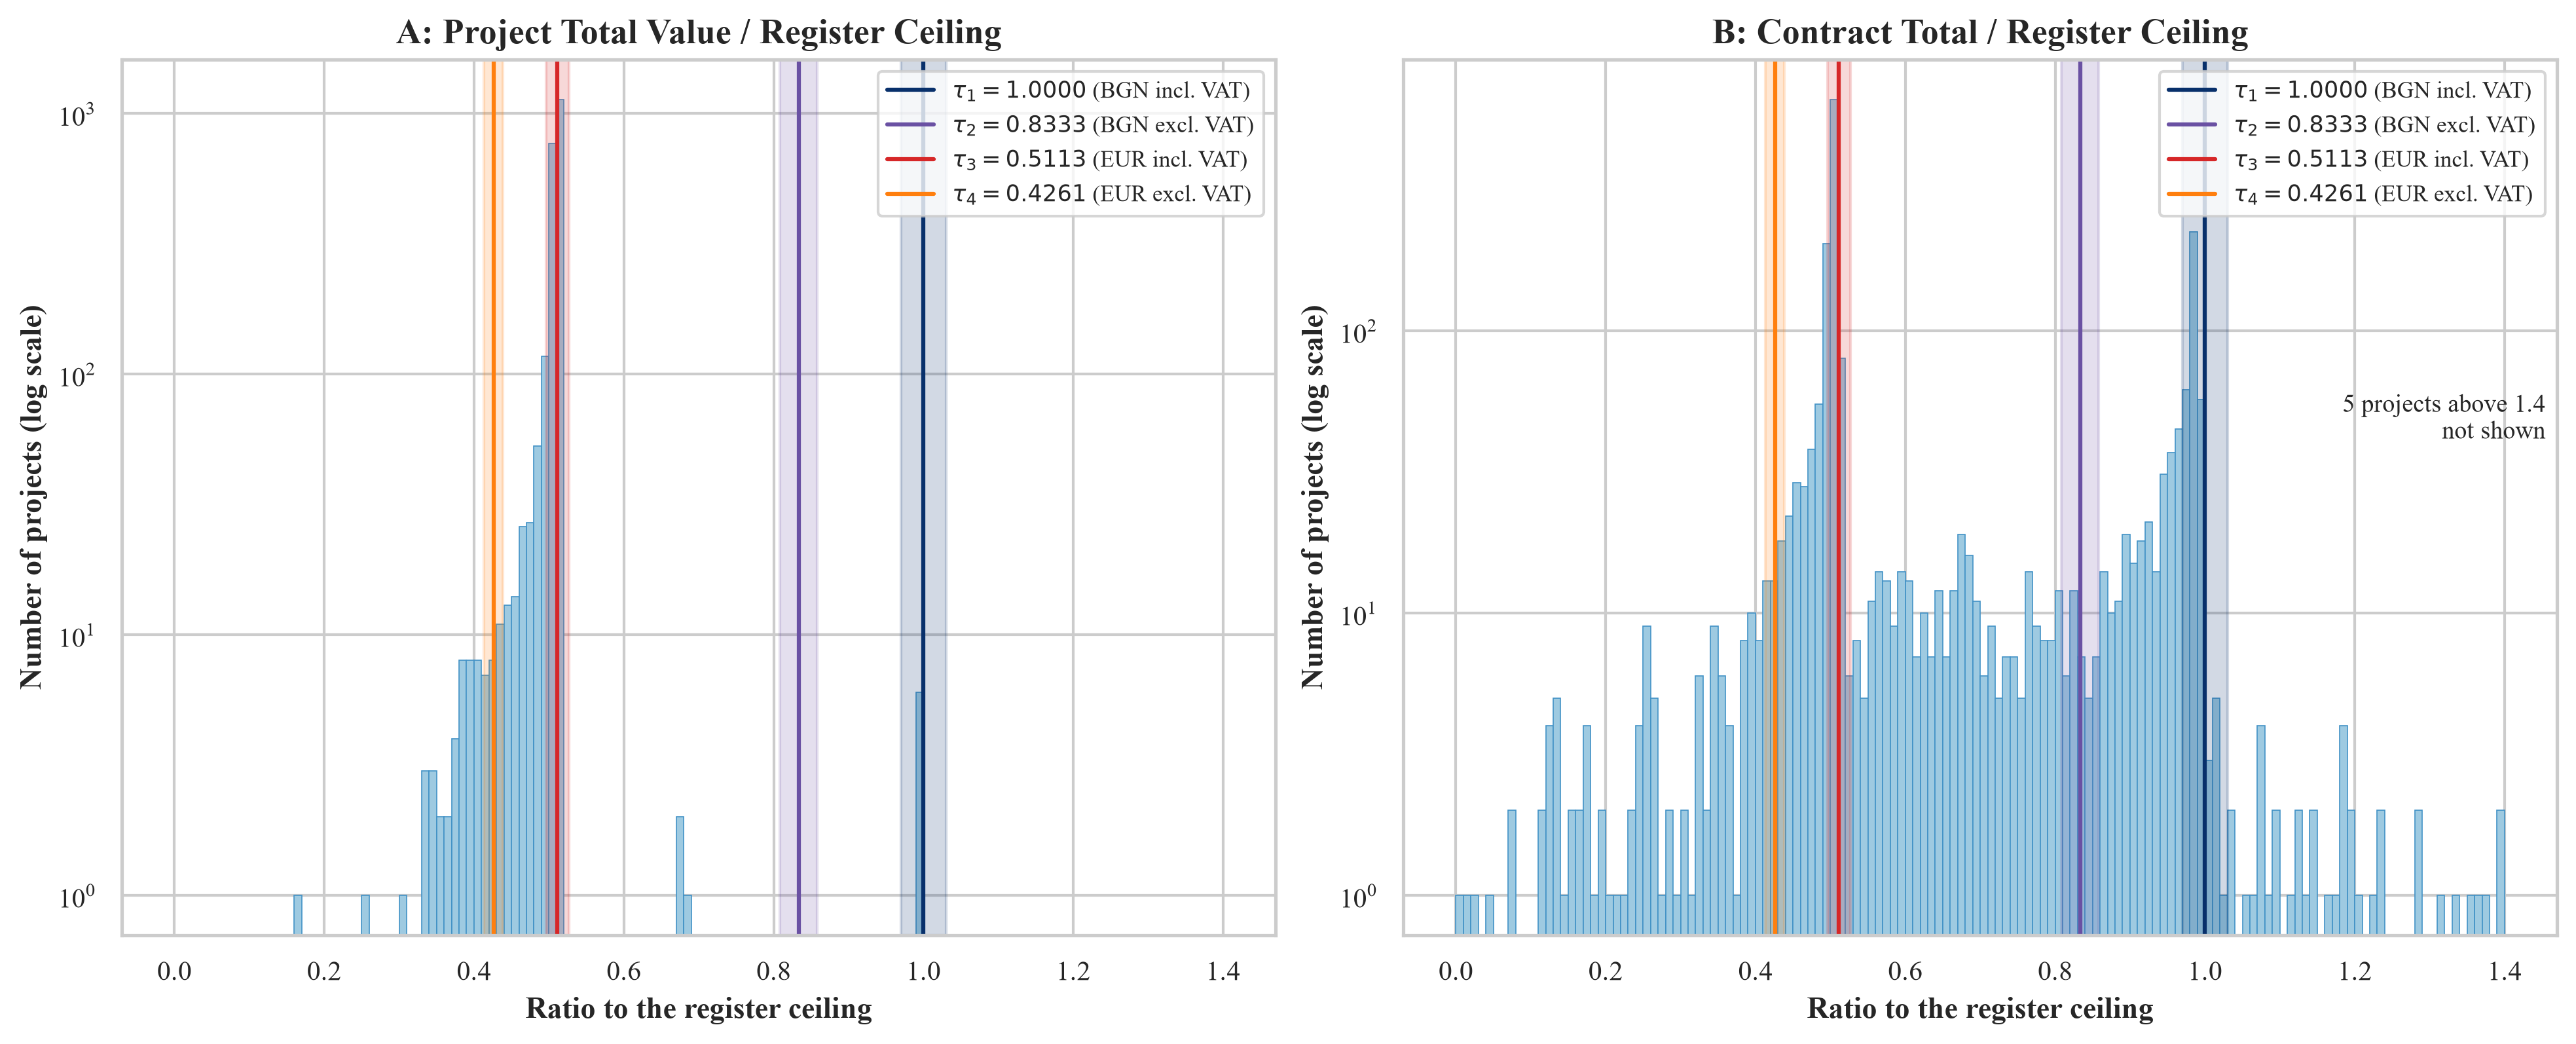

In [27]:
fig71, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2), constrained_layout=True)
bins = np.arange(0.0, 1.41, 0.01)
line_colors = ["#08306b", "#6a51a3", "#d62728", "#ff7f0e"]
tau_names = ["BGN incl. VAT", "BGN excl. VAT", "EUR incl. VAT", "EUR excl. VAT"]
panels = (
    (ax1, "ratio_total_value", "A: Project Total Value / Register Ceiling"),
    (ax2, "ratio_contracts", "B: Contract Total / Register Ceiling"),
)
for ax, column, title in panels:
    values = projects[column].dropna()
    values = values[values > 0.0]
    inside = values[values <= bins[-1]]
    ax.hist(inside, bins=bins, color="#9ecae1", edgecolor="#4292c6", linewidth=0.4)
    for j, ((target, _, _), name, color) in enumerate(zip(RATIO_TARGETS, tau_names, line_colors), start=1):
        ax.axvspan(target * (1 - RATIO_TOLERANCE), target * (1 + RATIO_TOLERANCE), color=color, alpha=0.18)
        ax.axvline(target, color=color, linewidth=1.5, label=rf"$\tau_{j} = {target:.4f}$ ({name})")
    ax.set_yscale("log")
    ax.set_title(title)
    ax.set_xlabel("Ratio to the register ceiling")
    ax.set_ylabel("Number of projects (log scale)")
    if len(values) > len(inside):
        ax.text(0.99, 0.62, f"{len(values) - len(inside)} projects above {bins[-1]:.1f}\nnot shown", transform=ax.transAxes,
                ha="right", va="top", fontsize=9)
    ax.legend(loc="upper right", frameon=True, fontsize=8.5)
plt.show()

**Figure 7.1.** Ratio of the total value of a project (panel A) and of its contracts (panel B) to the ceiling of its school in the register, with the four canonical ratios and their windows.

*Source:* Calculation from ISUN 2020 (2026) and the register of schools.

The total values fall almost entirely in the window of $\tau_3$ (panel A): the total value of a project is mostly stored in euro including VAT. The contract totals are spread more widely (panel B). They gather at $\tau_3$ and $\tau_1$, and many lie between the windows. The data do not say why. A project may be only partly contracted, or its contracts may be recorded in two currencies, since the contracts of many projects were signed in more than one calendar year.

For the 2,228 projects, the total values are classified as 1,968 EUR incl. VAT, 23 EUR excl. VAT and 6 BGN incl. VAT, with 231 undetermined, and the contract totals as 862 EUR incl. VAT, 39 EUR excl. VAT, 352 BGN incl. VAT and 38 BGN excl. VAT, with 937 undetermined.

The six total values in leva show that a stored value need not be in euro even where it is displayed as such. In BG-RRP-1.015-0427 the total value is 251,390.25 against a ceiling of 252,500 leva, and the payment is 128,533.79, which is the total value divided by 1.95583 to the cent. For the 1,291 projects whose contract total the ceiling classifies, the second step is not needed. The payments classify a further 393 projects (142 in leva and 251 in euro) and 201 total values, all of them in euro. The default applies to the remaining 544 projects (2,221 contracts) and to 30 total values. Of the 2,203 contracts signed from 1 January 2026, 159 belong to a project that the ceiling or the payments classify as leva; the date makes them euro contracts.

### 7.7 Normalisation of Contract Values and Allocation of Payments

All amounts are brought to euro, the currency of the study, and to one VAT basis. For a contract with raw value $A_k$ and the currency and VAT basis of Section 7.6:

$$\text{base\_eur}_k = \begin{cases} A_k / 1.95583 & \text{if currency} = \text{BGN} \\ A_k & \text{if currency} = \text{EUR} \end{cases}$$

$$\text{amount\_eur\_incl\_vat}_k = \begin{cases} \text{base\_eur}_k & \text{if incl. VAT} \\ \text{base\_eur}_k \times 1.20 & \text{if excl. VAT} \end{cases} \qquad \text{amount\_eur\_excl\_vat}_k = \begin{cases} \text{base\_eur}_k / 1.20 & \text{if incl. VAT} \\ \text{base\_eur}_k & \text{if excl. VAT} \end{cases}$$

The limits of Section 2 are converted from leva at the fixed rate and compared with $\text{amount\_eur\_excl\_vat}$.

ISUN records payments for the project only. The payment of project $i$ is in euro and takes the VAT basis of its total value. It is allocated to the contracts of the project in proportion to their value including VAT:

$$\text{paid\_alloc}_k = \text{paid\_eur\_incl\_vat}_i \times \frac{\text{amount\_eur\_incl\_vat}_k}{\sum_{m \in \text{Contracts}(i)} \text{amount\_eur\_incl\_vat}_m}$$

Every contract now has a currency. The VAT basis is known only where the ceiling fixes it, so a contract of another project is assumed to include VAT, the class of 93% of the contracts with a known basis (5,438 incl. VAT against 418 excl. VAT). The assumption is recorded: the contracts concerned have the value `undetermined` in the column `vat_basis`. The totals are written to `data/derived/normalized_totals.csv`, and the ratios, classes and the basis of the currency of the projects to `data/derived/project_classes.csv`.

In [28]:
def normalise_amounts(raw: np.ndarray, currency: np.ndarray, vat_basis: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Convert raw values to euro incl. and excl. VAT; an undetermined VAT basis takes the assumed one."""
    assert not (currency == UNDETERMINED).any(), "every value must have a currency"
    vat_basis = np.where(vat_basis == UNDETERMINED, ASSUMED_VAT_BASIS, vat_basis)
    base_eur = np.where(currency == "BGN", raw / ThresholdConfig.EUR_BGN, raw)
    incl_vat = np.where(vat_basis == "incl_vat", base_eur, base_eur * VAT_FACTOR)
    excl_vat = np.where(vat_basis == "incl_vat", base_eur / VAT_FACTOR, base_eur)
    return incl_vat, excl_vat


ASSUMED_VAT_BASIS: Final[str] = "incl_vat"
EURO_FROM: Final[pd.Timestamp] = pd.Timestamp("2026-01-01")

# unit check with a raw value of 100 in the classes BGN incl., BGN excl., EUR incl. and EUR excl. VAT
check_currency = np.array(["BGN", "BGN", "EUR", "EUR"])
check_basis = np.array(["incl_vat", "excl_vat", "incl_vat", "excl_vat"])
check_incl, check_excl = normalise_amounts(np.full(4, 100.0), check_currency, check_basis)
bgn_100_in_eur = 100.0 / ThresholdConfig.EUR_BGN
assert np.allclose(check_incl, [bgn_100_in_eur, bgn_100_in_eur * 1.2, 100.0, 120.0])
assert np.allclose(check_excl, [bgn_100_in_eur / 1.2, bgn_100_in_eur, 100.0 / 1.2, 100.0])

# a contract signed from 1 January 2026 is in euro; an earlier contract takes the currency of its project
project_classes = projects.set_index("project_id")
signed = pd.to_datetime(contracts["signature_date"])
from_2026 = signed >= EURO_FROM
project_currency = contracts["project_id"].map(project_classes["contract_currency"])
contracts["currency"] = np.where(from_2026, "EUR", project_currency)
contracts["currency_basis"] = np.where(from_2026, "date", contracts["project_id"].map(project_classes["contract_currency_basis"]))
contracts["vat_basis"] = contracts["project_id"].map(project_classes["contract_vat_basis"])
print(f"Contracts signed from {EURO_FROM.date()}: {int(from_2026.sum()):,}; the currency of their project was "
      f"EUR for {int((from_2026 & (project_currency == 'EUR')).sum()):,} and BGN for {int((from_2026 & (project_currency == 'BGN')).sum()):,}.")
display(pd.crosstab(contracts["currency_basis"], contracts["currency"]).rename_axis("basis of the currency", columns="currency"))

raw = contracts["amount_raw"].to_numpy()
incl_vat, excl_vat = normalise_amounts(raw, contracts["currency"].to_numpy(), contracts["vat_basis"].to_numpy())
contracts["amount_eur_incl_vat"] = incl_vat
contracts["amount_eur_excl_vat"] = excl_vat

# the payments of a project are in euro; they take the VAT basis of the total value and are spread over the contracts of the project
paid_incl, _ = normalise_amounts(projects["actually_paid_amount"].to_numpy(), np.full(len(projects), "EUR"),
                                 projects["total_value_vat_basis"].to_numpy())
projects["paid_eur_incl_vat"] = paid_incl

contracts["project_contract_total"] = contracts.groupby("project_id")["amount_eur_incl_vat"].transform("sum")
project_paid = contracts["project_id"].map(projects.set_index("project_id")["paid_eur_incl_vat"])
contracts["paid_alloc_eur_incl_vat"] = np.where(
    contracts["project_contract_total"] > 0.0,
    project_paid * contracts["amount_eur_incl_vat"] / contracts["project_contract_total"],
    0.0,
)

vat_assumed = contracts["vat_basis"] == UNDETERMINED
currency_default = contracts["currency_basis"] == "default"
normalized_totals = pd.DataFrame([{
    "total_contracted_eur_incl_vat": round(float(incl_vat.sum()), 2),
    "total_contracted_eur_excl_vat": round(float(excl_vat.sum()), 2),
    "total_disbursed_eur_incl_vat": round(float(projects["paid_eur_incl_vat"].sum()), 2),
    "contracts_currency_by_default": int(currency_default.sum()),
    "contracts_vat_assumed": int(vat_assumed.sum()),
    "vat_assumed_amount_raw": round(float(contracts.loc[vat_assumed, "amount_raw"].sum()), 2),
}])
display(normalized_totals.style.hide(axis="index").format({
    "total_contracted_eur_incl_vat": "{:,.2f}", "total_contracted_eur_excl_vat": "{:,.2f}",
    "total_disbursed_eur_incl_vat": "{:,.2f}", "vat_assumed_amount_raw": "{:,.2f}",
}))

# check, not a scenario: a contract total clearly above the register ceiling is unlikely, since the ceiling is the highest funding
default_projects = projects[(projects["contract_currency_basis"] == "default") & projects["register_budget_eur_incl_vat"].notna()
                            & (projects["contract_sum_raw"] > 0.0)]
limit = default_projects["register_budget_eur_incl_vat"] * (1 + RATIO_TOLERANCE)
display(pd.DataFrame([{
    "projects whose currency is taken by default": len(default_projects),
    "above the ceiling by more than 3% if in EUR": int((default_projects["contract_sum_raw"] > limit).sum()),
    "above the ceiling by more than 3% if in BGN": int((default_projects["contract_sum_raw"] / ThresholdConfig.EUR_BGN > limit).sum()),
}]).style.hide(axis="index"))

# the payments allocated to the contracts add up to the payments of the projects that have a positive contract total
with_contracts = projects["project_id"].isin(contracts.loc[contracts["project_contract_total"] > 0.0, "project_id"])
assert np.isclose(contracts["paid_alloc_eur_incl_vat"].sum(), projects.loc[with_contracts, "paid_eur_incl_vat"].sum())
assert np.allclose(incl_vat, excl_vat * VAT_FACTOR)
print(f"Disbursements of {int((~with_contracts).sum())} projects without a positive contract total are not allocated to any contract: "
      f"{projects.loc[~with_contracts, 'paid_eur_incl_vat'].sum():,.2f} EUR incl. VAT.")

Contracts signed from 2026-01-01: 2,203; the currency of their project was EUR for 2,044 and BGN for 159.


currency,BGN,EUR
basis of the currency,,
ceiling,1722,3444
date,0,2203
default,0,2221
payment,660,878


total_contracted_eur_incl_vat,total_contracted_eur_excl_vat,total_disbursed_eur_incl_vat,contracts_currency_by_default,contracts_vat_assumed,vat_assumed_amount_raw
"288,572,977.97","240,477,481.64","260,077,191.58",2221,5272,"161,123,102.20"


projects whose currency is taken by default,above the ceiling by more than 3% if in EUR,above the ceiling by more than 3% if in BGN
539,414,43


Disbursements of 5 projects without a positive contract total are not allocated to any contract: 0.00 EUR incl. VAT.


The currency of a contract rests on four grounds. The register ceiling classifies 5,166 contracts (46%), the date of signature 2,203 (20%), the payments of the project 1,538 (14%) and the default 2,221 (20%). The default concerns 81 million of the 349 million raw sum. The VAT basis is assumed for 5,272 contracts (47%), whose raw sum is 161 million (46%).

The last table is a check on the default, not a scenario. The ceiling is the highest amount of funding of a school, so a contract total clearly above it is unlikely, although a school may add funds of its own. Of the 539 projects with a default currency, a ceiling and contracts, 414 lie more than 3% above their ceiling if their contracts are in euro, and 43 if they are in leva. The default therefore agrees with the ceiling less well than the alternative, and the value of these contracts rests on a choice that the data do not confirm.

**Question.** Where do the contract values lie relative to the statutory limits, and on what basis was their currency fixed?

**Why one panel.** The contracts are stacked by the basis of their currency, so that the share of the default can be seen at each value.

**How to read.** The vertical lines are the limits of Section 2 by date of signature, converted to euro: 15,339 EUR for goods and services signed up to 31 December 2023, 25,565 EUR for works signed up to that date and for goods and services signed from 1 January 2024, and 40,903 EUR for works signed from that date. Of the 11,128 contracts, 11,055 were signed from 1 January 2024 and 73 before. All values are in euro excluding VAT.

**What the figure is not.** It is not a test for bunching. The limit that applies to a contract depends on its date of signature and on its subject, goods or works, and the subject is not recorded. The 13 contracts with a value of zero are not shown.

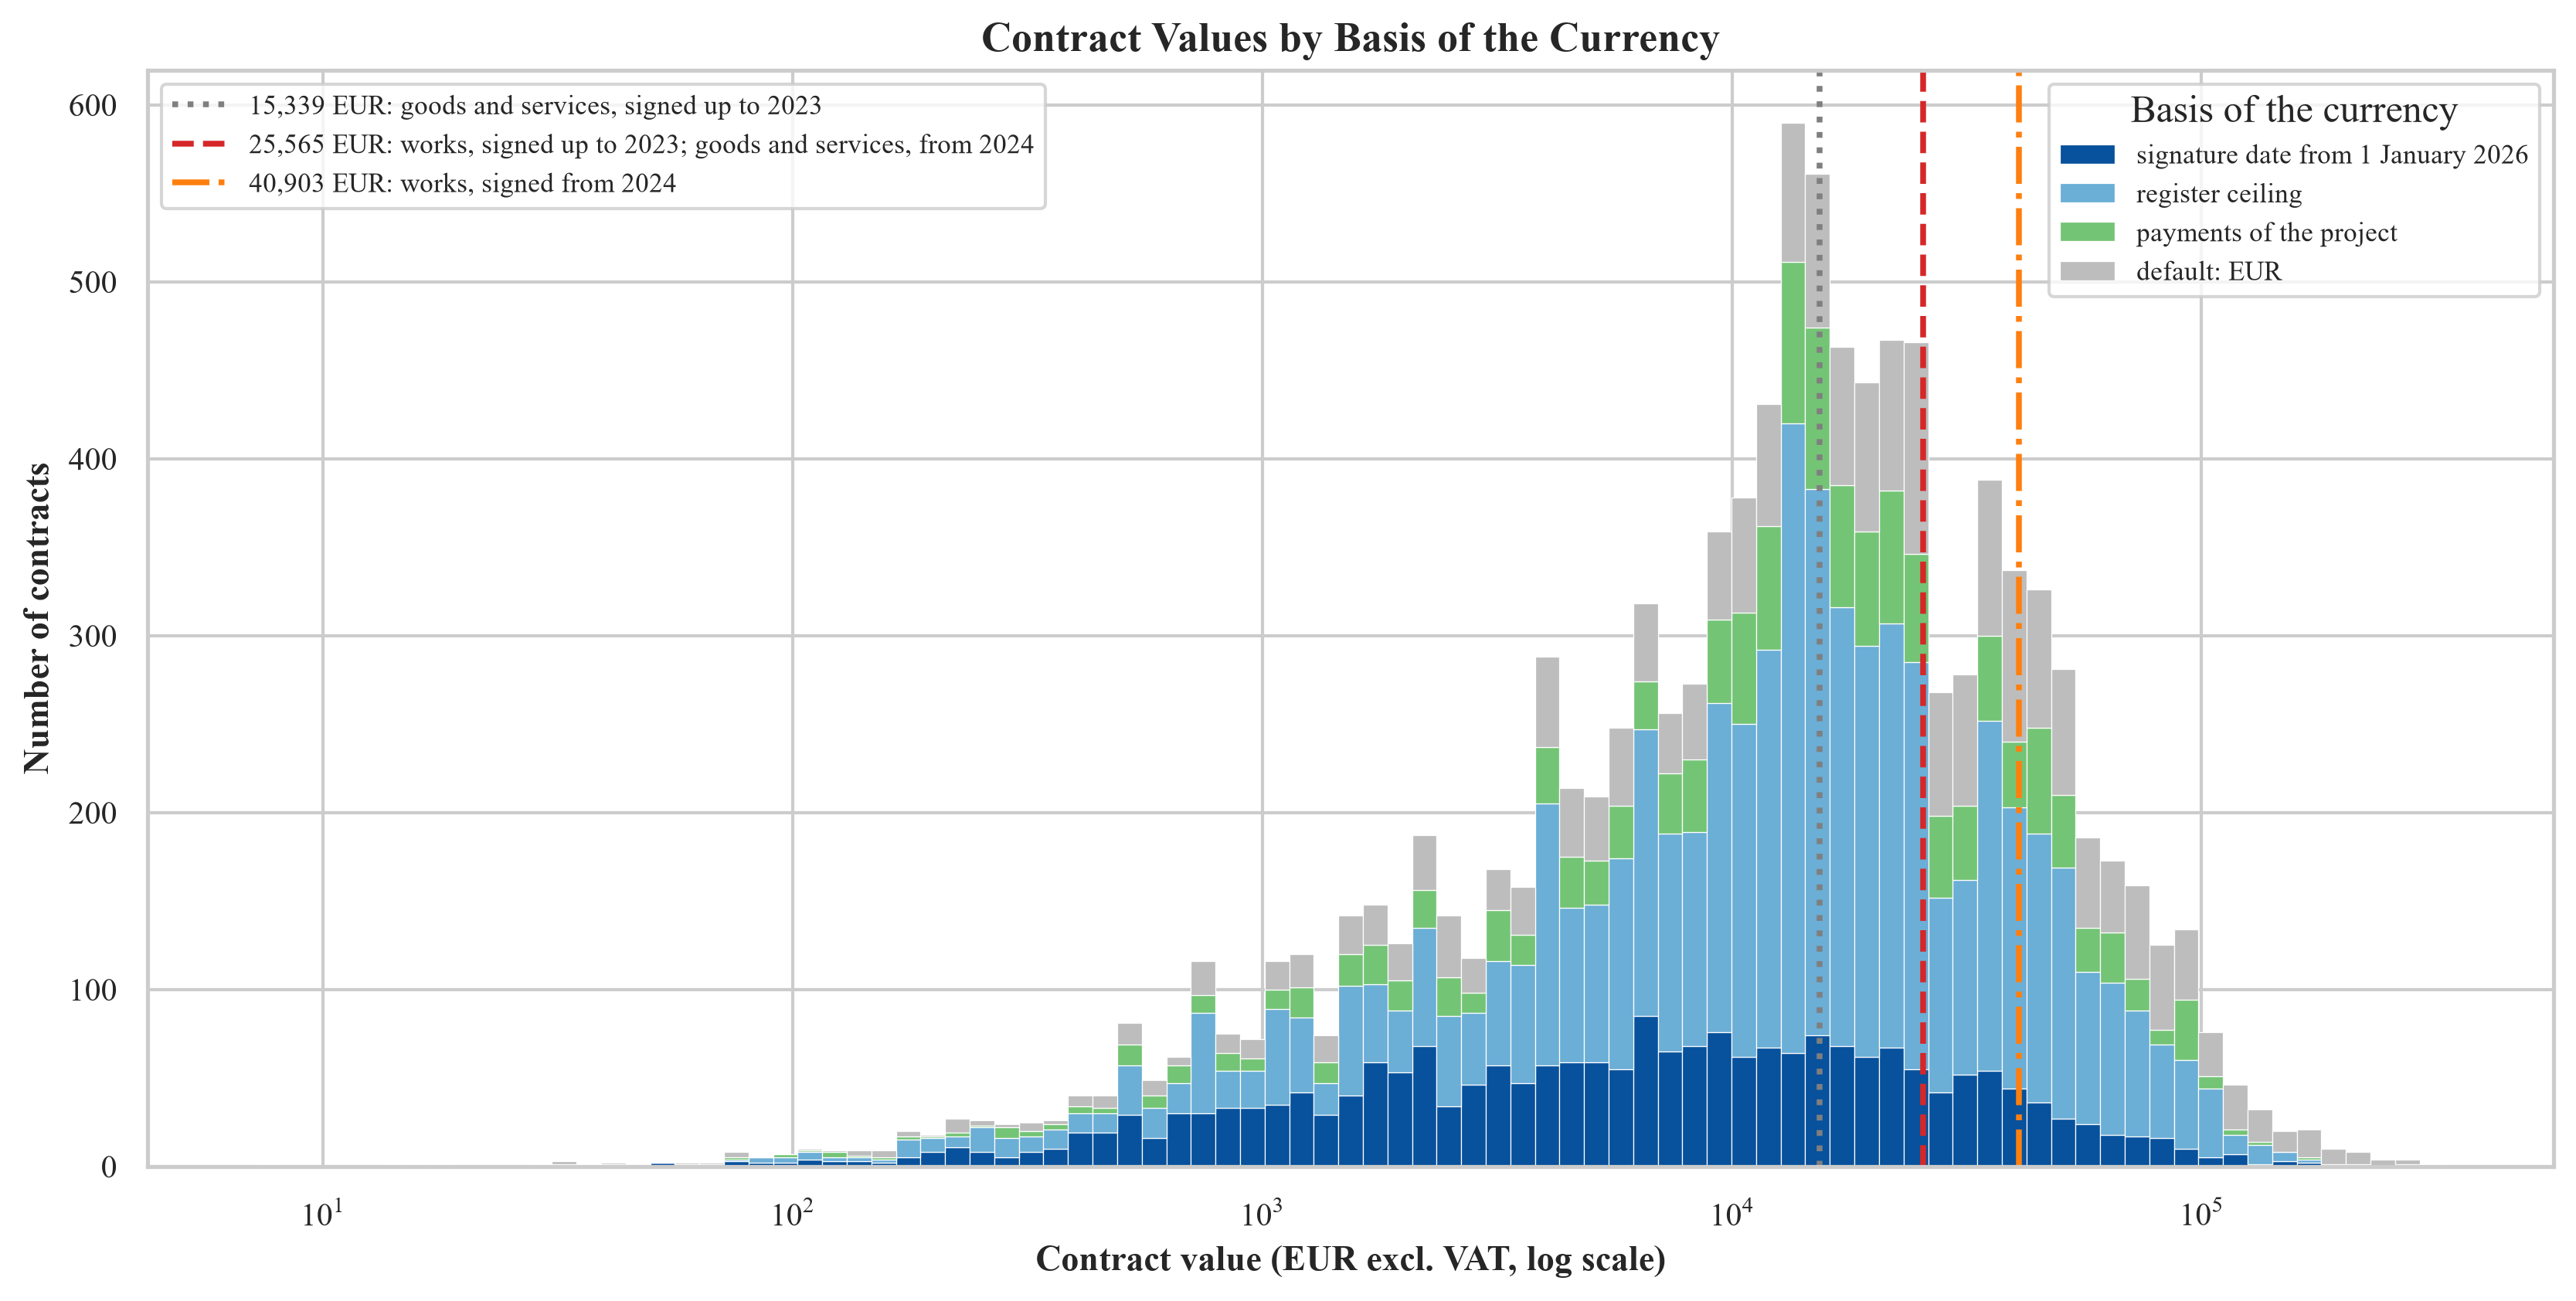

In [29]:
fig72, ax = plt.subplots(figsize=(11, 5.5), constrained_layout=True)
threshold_lines = (
    (ThresholdConfig.T1_GOODS_SERVICES_NET_BGN / ThresholdConfig.EUR_BGN, "#7f7f7f", ":", "goods and services, signed up to 2023"),
    (ThresholdConfig.T1_WORKS_NET_BGN / ThresholdConfig.EUR_BGN, "#d62728", "--", "works, signed up to 2023; goods and services, from 2024"),
    (ThresholdConfig.T2_WORKS_NET_BGN / ThresholdConfig.EUR_BGN, "#ff7f0e", "-.", "works, signed from 2024"),
)
basis_styles = (
    ("date", "#08519c", "signature date from 1 January 2026"),
    ("ceiling", "#6baed6", "register ceiling"),
    ("payment", "#74c476", "payments of the project"),
    ("default", "#bdbdbd", "default: EUR"),
)
positive = contracts[contracts["amount_eur_excl_vat"] > 0.0]
log_bins = np.logspace(np.log10(positive["amount_eur_excl_vat"].min()), np.log10(positive["amount_eur_excl_vat"].max()), 90)
ax.hist([positive.loc[positive["currency_basis"] == key, "amount_eur_excl_vat"] for key, _, _ in basis_styles], bins=log_bins, stacked=True,
        color=[color for _, color, _ in basis_styles], label=[label for _, _, label in basis_styles], edgecolor="white", linewidth=0.3)
basis_legend = ax.legend(title="Basis of the currency", loc="upper right", frameon=True, fontsize=8.5)
ax.add_artist(basis_legend)
limit_lines = [ax.axvline(value, color=color, linestyle=style, linewidth=1.8, label=f"{value:,.0f} EUR: {label}")
               for value, color, style, label in threshold_lines]
ax.legend(handles=limit_lines, loc="upper left", frameon=True, fontsize=8.5)
ax.set_xscale("log")
ax.set_title("Contract Values by Basis of the Currency")
ax.set_xlabel("Contract value (EUR excl. VAT, log scale)")
ax.set_ylabel("Number of contracts")
plt.show()

**Figure 7.2.** Contract values in EUR excluding VAT, by the basis of the currency (signature date, register ceiling, payments of the project or default), with the statutory limits of Section 2 by date of signature, converted to euro.

*Source:* Calculation from ISUN 2020 (2026) and the register of schools; limits from Bulgaria (2016) and Bulgaria (2023).

### 7.8 Functional Roles of Suppliers

Because all contracts carry the same description, the role of a supplier cannot be read from the contract. Each supplier is assigned one of three roles, $V = V_{\text{cons}} \cup V_{\text{tech}} \cup V_{\text{civil}}$. $V_{\text{cons}}$ is consulting, management, supervision and training, $V_{\text{tech}}$ is technology, equipment and software, and $V_{\text{civil}}$ is building work, furnishing and installation. The first rule that applies assigns the role:

1. **Seed table.** 27 suppliers are assigned by hand from their legal name, in `data/vendor_roles.csv`. The table can be read and corrected.
2. **Name stems.** The name of the supplier contains a word that starts with a stem of one of the three lists. A short abbreviation must be a whole word.
3. **Default.** All other suppliers are assigned $V_{\text{tech}}$, because the register requires at least 45% of the STEM funds of a school to be spent on equipment. Suppliers whose names were replaced by a label also fall here.

The roles are inferred from names. They are not checked against any record of what was supplied.

In [30]:
SEED_ROLES: Final[dict[str, str]] = {
    "000885099": "V_tech", "131468980": "V_tech", "175342714": "V_tech", "204660454": "V_tech",
    "201055457": "V_tech", "175063752": "V_tech", "200544954": "V_tech", "104518906": "V_tech",
    "175415627": "V_tech", "130691914": "V_tech", "201437250": "V_tech", "817080126": "V_tech",
    "206368790": "V_tech", "203362451": "V_tech", "832069304": "V_tech", "114600294": "V_tech",
    "128049011": "V_civil", "206175784": "V_civil", "102990274": "V_civil", "205631733": "V_civil",
    "130065898": "V_civil", "825297318": "V_civil",
    "202395053": "V_cons", "203902794": "V_cons", "206547220": "V_cons", "207788103": "V_cons", "131106522": "V_cons",
}
CONSULTING_STEMS: Final[tuple[str, ...]] = (
    "консулт", "мениджмънт", "надзор", "проектиран", "одит", "адвайз", "трейнинг", "обучени",
    "експерт", "семинар", "управлени", "проучван", "просвета", "концепт", "стратег",
)
CIVIL_STEMS: Final[tuple[str, ...]] = (
    "строит", "строй", "билд", "ремонт", "монтаж", "инженеринг", "мебел", "интериор", "дограм", "климати",
    "електромонтаж", "електроинсталац", "конструк", "архитект", "изолаци", "обзавеждан",
)
CIVIL_WORDS: Final[frozenset[str]] = frozenset({"вик", "боя"})
TECH_STEMS: Final[tuple[str, ...]] = (
    "компют", "техноло", "софтуер", "хардуер", "дигитал", "информацион", "телекомуникац", "мреж", "системи",
    "електроник", "мултимеди", "интерактив", "робот", "смарт", "сървър", "принтер", "офис", "панда",
    "йеттел", "виваком", "лаптоп", "таблет", "айти",
)
TECH_WORDS: Final[frozenset[str]] = frozenset({"а1", "it"})
DEFAULT_ROLE: Final[str] = "V_tech"


def classify_vendor(eik: str, name: str) -> tuple[str, str]:
    """Return the functional role of a supplier and the rule that assigned it.

    Rules are applied in this order: the seed table (rule "seed"), name stems for consulting, civil works
    and technology (rule "name_stem") and the default role (rule "default"). Stems must start a word;
    short abbreviations must be whole words.
    """
    if eik in SEED_ROLES:
        return SEED_ROLES[eik], "seed"
    tokens = re.findall(r"\w+", name.lower())
    spaced = f" {' '.join(tokens)} "
    if any(token.startswith(CONSULTING_STEMS) for token in tokens):
        return "V_cons", "name_stem"
    if any(token.startswith(CIVIL_STEMS) for token in tokens) or CIVIL_WORDS.intersection(tokens) or " в и к " in spaced:
        return "V_civil", "name_stem"
    if any(token.startswith(TECH_STEMS) for token in tokens) or TECH_WORDS.intersection(tokens):
        return "V_tech", "name_stem"
    return DEFAULT_ROLE, "default"


vendors = entities[entities["entity_id"].isin(contracts["vendor_id"])].copy()
assigned = [classify_vendor(eik, name) for eik, name in zip(vendors["uin"], vendors["name"])]
vendors["vendor_role"] = [role for role, _ in assigned]
vendors["role_rule"] = [rule for _, rule in assigned]

seed_table = pd.DataFrame({"vendor_eik": list(SEED_ROLES), "role": list(SEED_ROLES.values())})
seed_table["vendor_name"] = seed_table["vendor_eik"].map(vendors.drop_duplicates("uin").set_index("uin")["name"]).fillna("")
seed_table["basis"] = "assessed by the analyst from the legal name"
write_work_csv(seed_table[["vendor_eik", "vendor_name", "role", "basis"]], WORK_ROLES)
assert (seed_table["vendor_name"] != "").all(), "A seed supplier is not among the suppliers of the procedure"

contracts["vendor_eik"] = contracts["vendor_id"].map(entity_uin).fillna("")
contracts["vendor_role"] = contracts["vendor_id"].map(vendors.set_index("entity_id")["vendor_role"]).fillna(DEFAULT_ROLE)
contracts["role_rule"] = contracts["vendor_id"].map(vendors.set_index("entity_id")["role_rule"]).fillna("default")
masked_vendor_ids = set(vendors.loc[vendors["name"].isin([PERSON_LABEL, SOLE_TRADER_LABEL]), "entity_id"])

print(f"Seed table: {len(seed_table)} suppliers, written to {WORK_ROLES.as_posix()}.")
print(f"Suppliers by rule:\n{vendors['role_rule'].value_counts().to_string()}")
print(f"Suppliers whose name is masked (natural persons and sole traders): {len(masked_vendor_ids)}, "
      f"with {int(contracts['vendor_id'].isin(masked_vendor_ids).sum())} contracts; they receive the default role.")
role_table = contracts.pivot_table(index="vendor_role", columns="role_rule", values="contract_id", aggfunc="count", fill_value=0)
role_table["all contracts"] = role_table.sum(axis=1)
role_table["EUR incl. VAT"] = contracts.groupby("vendor_role")["amount_eur_incl_vat"].sum()
display(role_table.style.format({"EUR incl. VAT": "{:,.0f}"}))

Seed table: 27 suppliers, written to data/vendor_roles.csv.
Suppliers by rule:
role_rule
default      1313
name_stem     414
seed           27
Suppliers whose name is masked (natural persons and sole traders): 87, with 154 contracts; they receive the default role.


role_rule,default,name_stem,seed,all contracts,EUR incl. VAT
vendor_role,,,,,
V_civil,0,817,860,1677,"42,254,458"
V_cons,0,179,798,977,"20,053,297"
V_tech,3958,400,4116,8474,"226,265,223"


Of the 1,754 identified suppliers, 27 are assigned by the seed table, 414 by name stems and 1,313 by the default. The seed table covers 5,774 contracts (52%), the stems 1,396 (13%) and the default 3,958 (36%), all of them as $V_{\text{tech}}$. Nearly half of the $V_{\text{tech}}$ contracts (47%) therefore rest on the default, whereas $V_{\text{civil}}$ and $V_{\text{cons}}$ are assigned only by the seed and the stems.

**Question.** How much of the role assignment rests on a rule that reads the name, and how much on the default?

**Why two panels.** Panel A counts contracts and panel B sums their value, each by role. The colour shows the rule that assigned the role.

**How to read.** A tall grey part means that most of the contracts of that role were assigned by the default. Only the seed and the stems give a reason for a role.

**What the figure is not.** It does not show whether a role is correct.

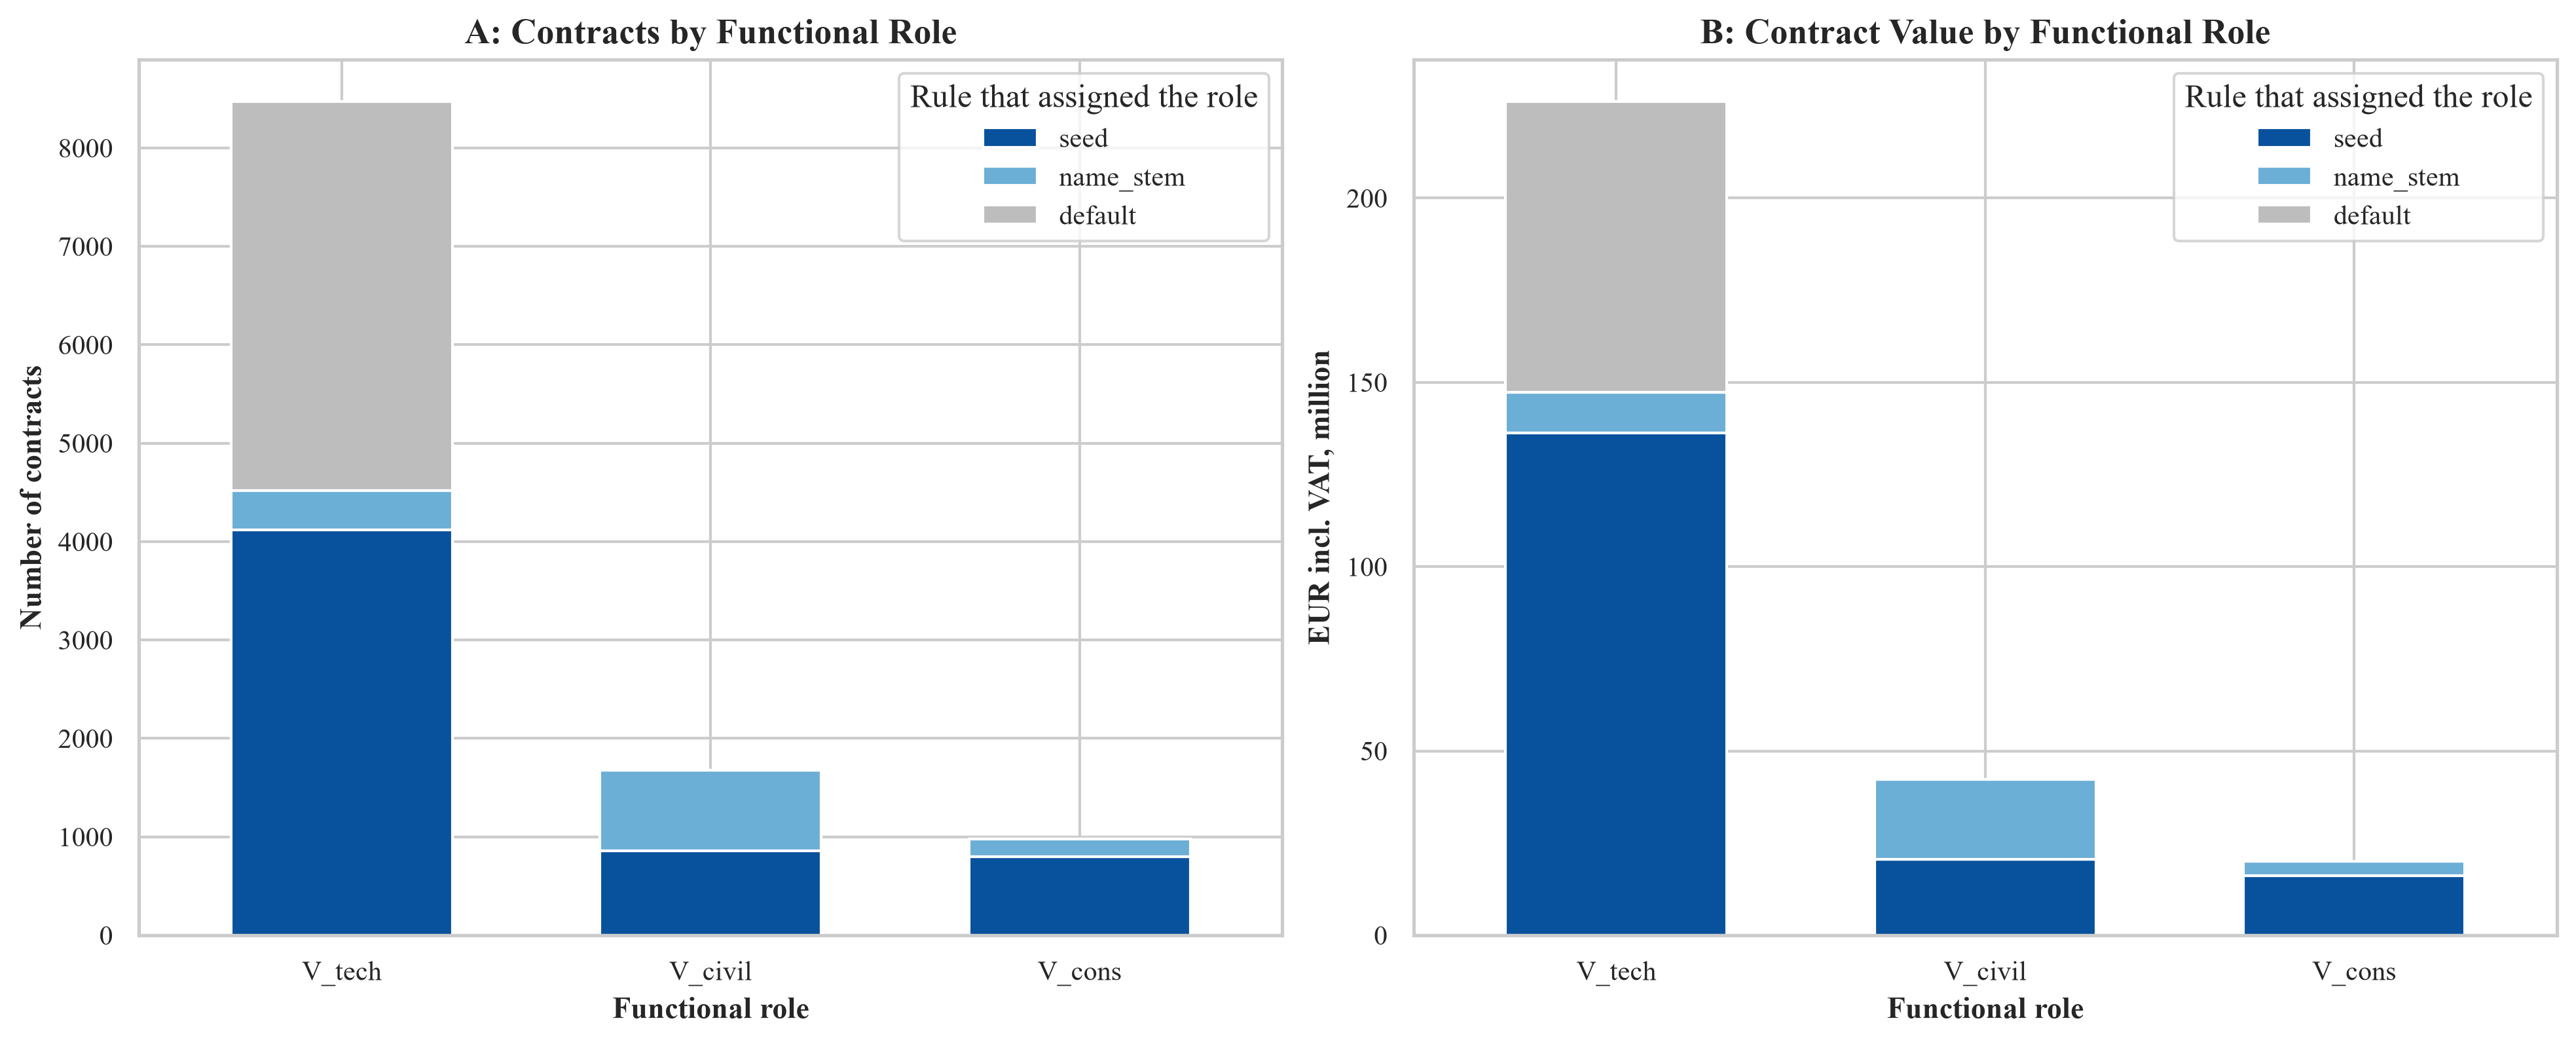

In [31]:
fig73, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2), constrained_layout=True)
rule_colors = {"seed": "#08519c", "name_stem": "#6baed6", "default": "#bdbdbd"}
role_order = ["V_tech", "V_civil", "V_cons"]
counts = contracts.pivot_table(index="vendor_role", columns="role_rule", values="contract_id", aggfunc="count", fill_value=0)
volume = contracts.pivot_table(index="vendor_role", columns="role_rule", values="amount_eur_incl_vat", aggfunc="sum", fill_value=0.0) / 1e6
for ax, table, title, ylabel in (
    (ax1, counts, "A: Contracts by Functional Role", "Number of contracts"),
    (ax2, volume, "B: Contract Value by Functional Role", "EUR incl. VAT, million"),
):
    table = table.reindex(index=role_order, columns=list(rule_colors)).fillna(0.0)
    table.plot(kind="bar", stacked=True, ax=ax, color=list(rule_colors.values()), width=0.6, edgecolor="white")
    ax.set_title(title)
    ax.set_xlabel("Functional role")
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=0)
    ax.legend(title="Rule that assigned the role", loc="upper right", frameon=True)
plt.show()

**Figure 7.3.** Number (panel A) and value (panel B) of contracts by functional role of the supplier, split by the rule that assigned the role.

*Source:* Calculation from ISUN 2020 (2026).

### 7.9 Contract Timing

For contract $k$ of project $i$, the timing difference is

$$\Delta t_k = t^{\text{signature}}_k - t^{\text{start}}_i,$$

where $t^{\text{signature}}_k$ is the `SignatureDate` of the contract and $t^{\text{start}}_i$ the `InitialDate` of the project. A contract with $\Delta t_k < 0$ was signed before the project start recorded in ISUN. This is a risk indicator and not a finding. The start date of a project need not be the date from which a school may commit funds, and a date may be recorded wrongly.

In [32]:
signature_year = pd.to_datetime(contracts["signature_date"]).dt.year
predated = contracts[contracts["delta_t_days"] < 0]
regime_1 = pd.to_datetime(contracts["signature_date"]) <= pd.Timestamp(ThresholdConfig.REGIME_1_CUTOFF)
print(f"Contracts with delta t < 0: {len(predated):,} of {len(contracts):,} ({len(predated) / len(contracts):.1%}); "
      f"raw amount {predated['amount_raw'].sum():,.2f}, {predated['amount_eur_incl_vat'].sum():,.2f} EUR incl. VAT.")
print(f"Median delta t of these contracts: {predated['delta_t_days'].median():.0f} days; "
      f"the earliest project start is {projects['project_start'].min()}.")
print(f"Contracts signed under regime 1 (on or before {ThresholdConfig.REGIME_1_CUTOFF}): {int(regime_1.sum())}, "
      f"of which with delta t < 0: {int((regime_1 & (contracts['delta_t_days'] < 0)).sum())}.")
display(predated.groupby(signature_year[predated.index]).size().rename("contracts with delta t < 0").rename_axis("year of signature").to_frame())

top = (predated.groupby("vendor_id").agg(vendor_eik=("vendor_eik", "first"), contracts=("contract_id", "count"),
                                           raw_amount=("amount_raw", "sum")).sort_values("contracts", ascending=False).head(5))
top["supplier"] = top.index.map(entities.set_index("entity_id")["name"])
top["share of contracts with delta t < 0"] = top["contracts"] / len(predated)
display(top.reset_index(drop=True)[["vendor_eik", "supplier", "contracts", "share of contracts with delta t < 0", "raw_amount"]]
        .style.hide(axis="index").format({"share of contracts with delta t < 0": "{:.1%}", "raw_amount": "{:,.2f}"}))

Contracts with delta t < 0: 654 of 11,128 (5.9%); raw amount 14,358,203.47, 11,151,352.29 EUR incl. VAT.
Median delta t of these contracts: -59 days; the earliest project start is 2024-02-23.
Contracts signed under regime 1 (on or before 2023-12-31): 73, of which with delta t < 0: 73.


,contracts with delta t < 0
year of signature,
2014,1
2022,2
2023,70
2024,581


vendor_eik,supplier,contracts,share of contracts with delta t < 0,raw_amount
131468980,",,А1 България“ ЕАД",368,56.3%,"6,500,260.66"
201055457,БАЛИСТИК СЕЛ ЕООД,85,13.0%,"3,100,878.37"
207788103,СКУУЛ КОНСУЛТИНГ ЕООД,47,7.2%,"85,231.16"
203902794,ДЖЕЙ ЕНД ДЖИ ГЛОБАЛ СЪРВИСЕС ЕООД,23,3.5%,"438,311.14"
201463957,ЕНЕРДЖИ СПЕД ЕООД,11,1.7%,"210,557.15"


All 73 contracts signed in 2023 or earlier are among the contracts with $\Delta t < 0$, because the earliest project starts in February 2024. The last table shows the five suppliers with the most contracts of this kind. A high count can follow from the number of schools that a supplier serves, and it says nothing by itself about the supplier.

**Question.** How are the signature dates distributed relative to the start of the project?

**How to read.** The red line is the project start. The shaded area to its left holds the contracts signed before it.

**What the figure is not.** It does not show whether a signature before the start was allowed. It shows the dates as recorded, including the few that are probably wrong.

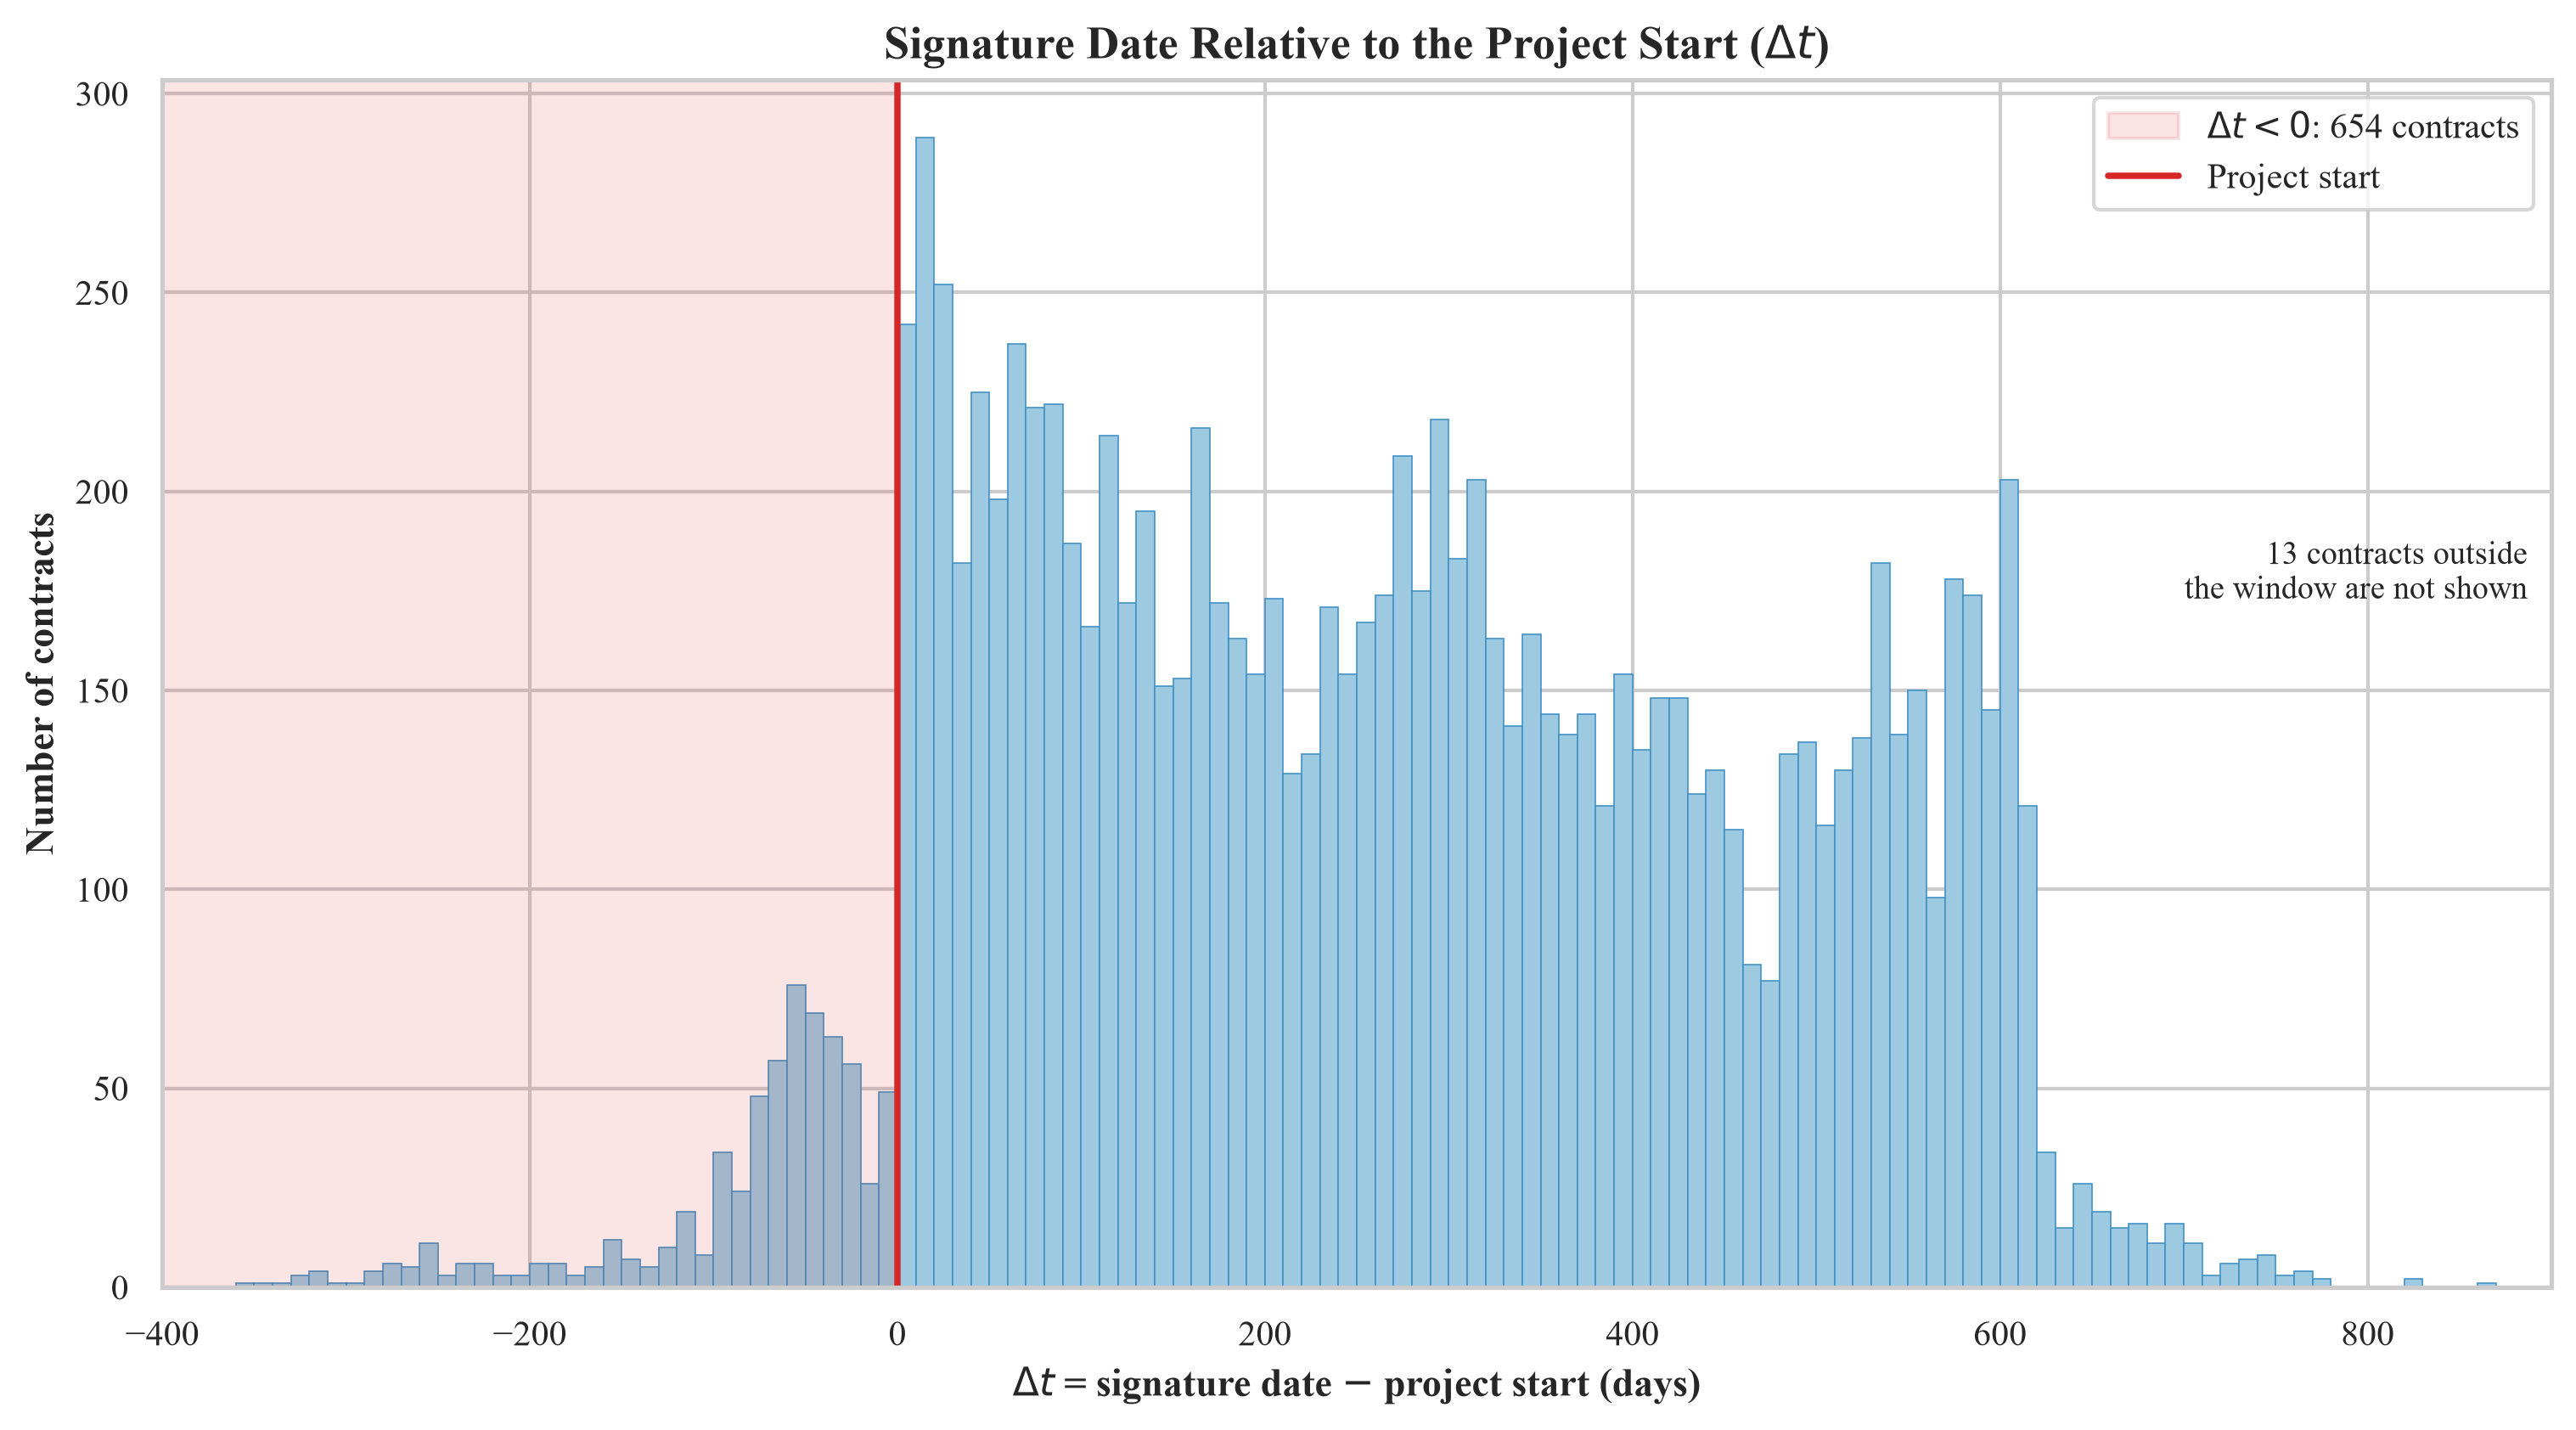

In [33]:
fig74, ax = plt.subplots(figsize=(10, 5.5), constrained_layout=True)
window = (-400, 900)
delta = contracts["delta_t_days"]
shown = delta[(delta >= window[0]) & (delta <= window[1])]
ax.hist(shown, bins=np.arange(window[0], window[1] + 10, 10), color="#9ecae1", edgecolor="#4292c6", linewidth=0.4)
ax.axvspan(window[0], 0, color="#d62728", alpha=0.12, label=rf"$\Delta t < 0$: {len(predated):,} contracts")
ax.axvline(0, color="#d62728", linewidth=1.8, label="Project start")
ax.set_xlim(window)
ax.set_title(r"Signature Date Relative to the Project Start ($\Delta t$)")
ax.set_xlabel(r"$\Delta t$ = signature date $-$ project start (days)")
ax.set_ylabel("Number of contracts")
ax.text(0.99, 0.62, f"{len(delta) - len(shown)} contracts outside\nthe window are not shown", transform=ax.transAxes,
        ha="right", va="top", fontsize=9)
ax.legend(loc="upper right", frameon=True)
plt.show()

**Figure 7.4.** Distribution of the timing difference $\Delta t$ between the signature date of a contract and the start of its project.

*Source:* Calculation from ISUN 2020 (2026).

### 7.10 Contract Table and Privacy Check

`data/derived/contracts.csv` has one row per contract and 20 columns. Every monetary column carries the currency and the VAT basis in its name. `data/derived/normalized_totals.csv` has one row, and `data/derived/project_classes.csv` holds the ratios and the classes of the 2,228 projects.

The last step reads every table written so far and asserts that it contains none of the personal data columns of the register, no ten-digit number, which is the length of a personal identification number, and no name of a sole trader.

In [34]:
CONTRACT_COLUMNS: Final[list[str]] = [
    "contract_id", "project_id", "school_bulstat", "vendor_id", "vendor_eik", "signature_date", "project_start",
    "delta_t_days", "amount_raw", "currency", "currency_basis", "vat_basis", "amount_eur_incl_vat", "amount_eur_excl_vat",
    "paid_alloc_eur_incl_vat", "vendor_role", "subcontractors_count", "municipality", "oblast_ruo", "funding_type",
]
PROJECT_CLASS_COLUMNS: Final[list[str]] = [
    "project_id", "school_bulstat", "register_match", "register_budget_eur_incl_vat", "contract_sum_raw", "ratio_contracts",
    "contract_currency", "contract_currency_basis", "contract_vat_basis", "undetermined_reason", "ratio_total_value",
    "total_value_currency", "total_value_currency_basis", "total_value_vat_basis", "paid_eur_incl_vat",
]

school_columns = projects.set_index("project_id")[["school_bulstat", "municipality", "oblast_ruo", "funding_type"]]
for column in school_columns.columns:
    contracts[column] = contracts["project_id"].map(school_columns[column])

contracts_export = contracts[CONTRACT_COLUMNS].copy()
assert list(contracts_export.columns) == CONTRACT_COLUMNS and contracts_export.shape == (11128, 20)
assert contracts_export.drop(columns=["paid_alloc_eur_incl_vat"]).notna().all().all()
write_work_csv(contracts_export, OUT_CONTRACTS)
write_work_csv(normalized_totals, OUT_TOTALS)
write_work_csv(projects[PROJECT_CLASS_COLUMNS], OUT_CLASSES)

# privacy check of every table written so far
FORBIDDEN_HEADERS: Final[set[str]] = {"Адрес", "Емайл", "Телефон", "Представляващ", "ЕГН на представляващ"}
written = sorted(PathConfig.DATA_DIR.glob("*.csv")) + sorted(PathConfig.DERIVED_DIR.glob("*.csv"))
for path in written:
    table = read_work_csv(path)
    assert not FORBIDDEN_HEADERS.intersection(table.columns), f"{path} contains a personal data column"
    for column in table.columns:
        assert not table[column].str.fullmatch(r"\d{10}").any(), f"{path}: column {column!r} holds a ten-digit number"
entity_names = read_work_csv(WORK_ENTITIES)["name"]
assert not entity_names.str.contains(r"(?<!\w)ЕТ(?!\w)|Адвокат").any(), "A sole trader or lawyer name was written"
print(f"Privacy check passed for {len(written)} tables: no personal data columns, no ten-digit numbers, no sole trader names.")
print("Tables written:")
for path in written:
    print(f"  {path.as_posix():<42} {len(read_work_csv(path)):>7,} rows")

Privacy check passed for 14 tables: no personal data columns, no ten-digit numbers, no sole trader names.
Tables written:
  data/adfi_classification.csv                 1,824 rows
  data/adfi_firms.csv                          1,361 rows
  data/adfi_transcript_features.csv              560 rows
  data/isun_contracts.csv                     11,128 rows
  data/isun_entities.csv                       3,973 rows
  data/isun_projects.csv                       2,228 rows
  data/schools_register.csv                    2,271 rows
  data/vendor_roles.csv                           27 rows
  data/derived/adfi_matches.csv                1,546 rows
  data/derived/consultant_steering.csv           701 rows
  data/derived/contracts.csv                  11,128 rows
  data/derived/normalized_totals.csv               1 rows
  data/derived/project_classes.csv             2,228 rows
  data/derived/validated_edges.csv             8,049 rows


### 7.11 Summary of the Checks

The assertions below repeat the main invariants of this section and fail if any of them is violated.

In [35]:
assert len(projects) == 2228 and len(contracts) == 11128 and len(entities) >= 1754
print("Counts: 2,228 projects and 11,128 contracts; every project and supplier has an organisation record, except one blank supplier identifier.")

assert np.isclose(contracts["amount_raw"].sum(), raw_total_amount)
assert np.isclose(contracts["paid_alloc_eur_incl_vat"].sum(), projects.loc[with_contracts, "paid_eur_incl_vat"].sum())
print("Totals: raw contract values and allocated payments are unchanged by the normalisation.")

assert set(projects["contract_currency"]) <= {"BGN", "EUR"} and set(projects["total_value_currency"]) <= {"BGN", "EUR"}
assert set(contracts["currency"]) <= {"BGN", "EUR"}
assert set(contracts["vendor_role"]) <= {"V_cons", "V_tech", "V_civil"}
print("Classes: every project and every contract has a currency, and every contract has one of the three functional roles.")

assert (contracts["delta_t_days"] < 0).sum() == 654
print("Timing: 654 contracts have a signature date before the project start.")

Counts: 2,228 projects and 11,128 contracts; every project and supplier has an organisation record, except one blank supplier identifier.
Totals: raw contract values and allocated payments are unchanged by the normalisation.
Classes: every project and every contract has a currency, and every contract has one of the three functional roles.
Timing: 654 contracts have a signature date before the project start.


## 8. ADFI Inspection Reports: Classification, Matching and Validation

The State Financial Inspection Agency (ADFI) inspects public procurement in schools and publishes its reports (ADFI, 2026). This section turns the published reports into tables for the later sections, where they serve as an independent check of the network results: which schools were audited, what the inspectors found and which firms the reports name.

**Two sources.** The first is the text of 560 reports, published from August 2024 to October 2026, one Markdown file for each report. The second is a classification of the findings of these reports. It was prepared from the text of the reports with the help of a language model (Claude, Anthropic), following written rules: a finding is classified by the action of the contracting authority, not by the article of the law that it violates. This section does not repeat the classification. It checks it, links it to the schools of the procedure and adds what the text of the reports gives.

**The text is used with care.** The text of the reports was recognised by machine and contains errors, and ADFI has removed the names of persons from it. For this reason only countable features are taken from the text (the identification number of the school, the inspectorate, counts of mentions and the names of firms), and no text is stored.

**Source files.** The reports and the classification are read once, in this section, from the source copies in `data/raw/`, and the results are stored as working tables in `data/`. When the working tables exist, the section reads them instead, so that it also runs without the source files.

**Selective labelling.** ADFI does not inspect schools at random. Let $A_i = 1$ if school $i$ was audited and $V_i = 1$ if it has a violation. Only $Y_i = V_i \times A_i$ is observed, so that

$$P(Y_i = 1 \mid X_i) = P(V_i = 1 \mid X_i) \times P(A_i = 1 \mid V_i = 1, X_i).$$

A school that was not audited is unlabelled. It is not a compliant school, and the later sections do not treat it as one.

### 8.1 Source Tables and Invariants

**Unit of the table.** A row of the classification is a pair of a finding and a class: a finding that carries several classes has several rows. A finding is either a violation or a conclusion of the inspector that there is no violation. The outcome is stored with an English label: `violation_with_act` (the report states an act for the violation), `violation_without_act` (the inspector describes a violation, but the text has no act for it) and `no_violation` (the inspector checked the action and stated that there is no violation).

**What is kept.** The working table `data/adfi_classification.csv` keeps the school, the report, the date of publication, the outcome, the number of the act, the law and the provisions, and the section, index and class of the classifier. The verbatim excerpts of the reports and the addressee of the requirement are not kept.

**Invariants.** The cell asserts 1,824 rows, 479 schools and 488 reports, and that a report belongs to one school. The 1,824 rows are 1,373 findings: 739 with an act, 45 without an act and 589 conclusions that there is no violation. The other 72 of the 560 reports have no row, because they hold neither a finding nor a conclusion that the classifier could assign to a class.

In [36]:
from collections import Counter
import xml.etree.ElementTree as ET

import xmlschema

WORK_ADFI_CLASSES: Final[Path] = PathConfig.DATA_DIR / "adfi_classification.csv"
WORK_ADFI_REPORTS: Final[Path] = PathConfig.DATA_DIR / "adfi_transcript_features.csv"
WORK_ADFI_FIRMS: Final[Path] = PathConfig.DATA_DIR / "adfi_firms.csv"
OUT_ADFI_XML: Final[Path] = PathConfig.DATA_DIR / "adfi_validation.xml"
OUT_ADFI_XSD: Final[Path] = PathConfig.DATA_DIR / "adfi_validation.xsd"
OUT_ADFI_MATCHES: Final[Path] = PathConfig.DERIVED_DIR / "adfi_matches.csv"

# source column -> working column; the verbatim columns and the addressee of the requirement are not kept
ADFI_CLASS_COLUMNS: Final[dict[str, str]] = {
    "№": "finding_no", "Училище": "school_name", "Относителен път": "report_id", "Публикуван": "published",
    "Страници": "pages", "Изход": "outcome", "Акт": "act", "Състояние на акта": "act_state", "Закон": "law",
    "Разпоредби": "provisions", "Раздел": "section", "Индекс": "class_index", "Клас": "class_name",
    "Откъде е основата": "basis_source", "Увереност": "confidence",
}
ADFI_OUTCOMES: Final[dict[str, str]] = {
    "нарушение с акт": "violation_with_act",
    "нарушение без акт": "violation_without_act",
    "няма нарушение": "no_violation",
}
VIOLATION_OUTCOMES: Final[tuple[str, str]] = ("violation_with_act", "violation_without_act")


def load_adfi_classification() -> pd.DataFrame:
    """Read the working table of the classification and create it from the source file when it is missing."""
    if WORK_ADFI_CLASSES.is_file():
        return read_work_csv(WORK_ADFI_CLASSES)
    source = pd.read_csv(PathConfig.RAW_ADFI_CLASSIFICATION, sep=";", encoding="utf-8-sig", dtype=str, keep_default_na=False)
    table = source[list(ADFI_CLASS_COLUMNS)].rename(columns=ADFI_CLASS_COLUMNS)
    table["report_id"] = table["report_id"].str.replace("\\", "/", regex=False).str.replace(r"^00\. АДФИ/", "", regex=True)
    table["outcome"] = table["outcome"].map(ADFI_OUTCOMES)
    assert table["outcome"].notna().all(), "An outcome of the classification has no English label"
    write_work_csv(table, WORK_ADFI_CLASSES)
    return table


adfi_class = load_adfi_classification()
assert len(adfi_class) == 1824, f"Expected 1824 classification rows, got {len(adfi_class)}"
assert adfi_class["school_name"].nunique() == 479, f"Expected 479 audited schools, got {adfi_class['school_name'].nunique()}"
assert adfi_class["report_id"].nunique() == 488, f"Expected 488 classified reports, got {adfi_class['report_id'].nunique()}"
assert adfi_class.groupby("report_id")["school_name"].nunique().max() == 1, "A report belongs to more than one school"

findings = adfi_class.drop_duplicates("finding_no")
assert findings["outcome"].value_counts().to_dict() == {"violation_with_act": 739, "no_violation": 589, "violation_without_act": 45}
print(f"{len(adfi_class):,} classification rows, {adfi_class['school_name'].nunique()} schools, {adfi_class['report_id'].nunique()} reports, "
      f"{len(findings):,} findings (a finding has one row for each of its classes).")
print(findings["outcome"].value_counts().rename_axis("outcome").reset_index(name="findings").to_string(index=False))

1,824 classification rows, 479 schools, 488 reports, 1,373 findings (a finding has one row for each of its classes).
              outcome  findings
   violation_with_act       739
         no_violation       589
violation_without_act        45


### 8.2 Checksum of the Identification Number

**Question.** Is a nine-digit number that a report states next to a label such as `ЕИК` a genuine identification number of an institution?

**Rule.** For a number $d_1 d_2 \dots d_9$ the ninth digit is a check digit. With the weights $w = (1, 2, \dots, 8)$ let

$$S = \sum_{j=1}^{8} d_j \times j, \qquad R = S \bmod 11.$$

If $R < 10$, then $d_9 = R$. If $R = 10$, a second sum with the weights $w' = (3, 4, \dots, 10)$ is used:

$$S' = \sum_{j=1}^{8} d_j \times (j + 2), \qquad R' = S' \bmod 11, \qquad d_9 = \begin{cases} R', & R' < 10 \\ 0, & R' = 10. \end{cases}$$

**Test.** The checksum is tested on the register of schools and not on numbers that the code itself produced. Every nine-digit Bulstat of the register must pass, among them those that need the second weight vector; 25 numbers drawn from the register with a wrong ninth digit must fail; and a number computed by hand (000043717: $S = 95$, $R = 7$, $d_9 = 7$) must pass. Two values of the register have thirteen digits and are not tested.

**What it does not show.** A number that passes the check need not belong to the school: a misread number passes with a probability of about one in ten. The checksum removes most misreadings, and the matching in Section 8.4 uses the register as a second check.

In [37]:
CHECKSUM_WEIGHTS_1: Final[tuple[int, ...]] = (1, 2, 3, 4, 5, 6, 7, 8)
CHECKSUM_WEIGHTS_2: Final[tuple[int, ...]] = (3, 4, 5, 6, 7, 8, 9, 10)


def validate_bulstat_checksum(code: str) -> bool:
    """Check the ninth digit of a nine-digit Bulstat with the two-stage weighted sum modulo 11."""
    if not (isinstance(code, str) and len(code) == 9 and code.isascii() and code.isdigit()):
        return False
    digits = [int(char) for char in code]
    remainder = sum(d * w for d, w in zip(digits[:8], CHECKSUM_WEIGHTS_1)) % 11
    if remainder < 10:
        return digits[8] == remainder
    remainder = sum(d * w for d, w in zip(digits[:8], CHECKSUM_WEIGHTS_2)) % 11
    return digits[8] == (remainder if remainder < 10 else 0)


register_codes = schools_register[REG_BULSTAT]
register_nine = register_codes[register_codes.str.fullmatch(r"\d{9}")]  # two codes of the register are longer than nine digits
register_valid = register_nine[register_nine.map(validate_bulstat_checksum)]
assert len(register_valid) == len(register_nine), "A nine-digit Bulstat of the register fails the checksum"
second_stage = [code for code in register_valid
                if sum(int(d) * w for d, w in zip(code[:8], CHECKSUM_WEIGHTS_1)) % 11 == 10]

test_valid = register_valid.sample(25, random_state=ModelConfig.SEED).tolist()
test_tampered = [code[:8] + str((int(code[8]) + 5) % 10) for code in test_valid]  # a wrong ninth digit
assert validate_bulstat_checksum("000043717"), "Hand-computed vector: S = 95, 95 mod 11 = 7"
assert all(validate_bulstat_checksum(code) for code in test_valid)
assert not any(validate_bulstat_checksum(code) for code in test_tampered)
assert not validate_bulstat_checksum("12345678") and not validate_bulstat_checksum("12345678a") and not validate_bulstat_checksum("")
assert second_stage, "No register code exercises the second weight vector"

stem_bulstats: Final[frozenset[str]] = frozenset(projects["school_bulstat"])
assert len(stem_bulstats) == 2227 and stem_bulstats <= set(register_codes), "Expected 2,227 beneficiaries, all of them in the register"
print(f"All {len(register_valid):,} nine-digit Bulstat values of the register ({len(register_codes):,} institutions) pass the checksum; "
      f"{len(second_stage)} of them need the second weight vector.")
print(f"{len(test_valid)} valid vectors accepted, {len(test_tampered)} tampered vectors rejected; "
      f"{len(stem_bulstats):,} beneficiary schools of the procedure.")

All 2,269 nine-digit Bulstat values of the register (2,271 institutions) pass the checksum; 213 of them need the second weight vector.
25 valid vectors accepted, 25 tampered vectors rejected; 2,227 beneficiary schools of the procedure.


### 8.3 Features of the Reports

**Which files are reports.** The directory holds 564 Markdown files. A file is a report when it lies in a folder `year/month`; these are 560 files. The other four are the classifier, the instructions and two court decisions.

**Features.** The cell reads each report once and keeps only the following for it. The text itself is not kept.

* **Identification number of the school** (`school_eik`): the first nine-digit number that follows a label (`БУЛСТАТ`, `ЕИК` or `идентификационен код`) and passes the checksum of Section 8.2. The column `eik_candidates` counts the different numbers of this kind in the report. Where a report has more than one, the first is taken. Where it has none, the number is missing or was misread, and the school is matched by its name (Section 8.4).
* **Inspectorate** (`inspectorate`): the code in the name of the file, `ДИД`, a number and two letters. Latin letters that look like Cyrillic ones are converted.
* **Counts of mentions:** of an act for an administrative violation (`n_act_mentions`), of the director, the chief accountant and the mayor (`n_director`, `n_chief_accountant`, `n_mayor`), and of the STEM environment or of procedure BG-RRP (`n_stem`). A count is the number of times that a word occurs. It does not say who was sanctioned.
* **Firms:** a name in quotation marks followed by a legal form (`ЕООД`, `ООД`, `АД`, `ДЗЗД`, `СД`, `КД`). A sole trader is not taken. A name that ends like a surname is dropped, because it may name a person, and so is a name of more than 60 characters or with a comma, which is a piece of a sentence. A Bulstat is searched within 150 characters after the name, and only a few are found. Names that the machine reading has cut short stay as they are, so the list of firms is approximate.

The features are stored in `data/adfi_transcript_features.csv` (one row for each report) and the firms in `data/adfi_firms.csv`.

In [38]:
LATIN_LOOKALIKES: Final[dict[int, int]] = str.maketrans("ABCEHKMOPTXaceopx", "АВСЕНКМОРТХасеорх")  # Latin letters typed in file names
RE_REPORT_PATH: Final[re.Pattern[str]] = re.compile(r"\d{4}/\d{2}/[^/]+\.md")
RE_FILE_CODE: Final[re.Pattern[str]] = re.compile(r"(ДИД\d+)-([А-Я]{2})-\d+")
RE_EIK: Final[re.Pattern[str]] = re.compile(r"(?:БУЛСТАТ|ЕИК|идентификационен\s+код)[^0-9]{0,40}(\d{9})(?!\d)", re.IGNORECASE)
RE_ACT: Final[re.Pattern[str]] = re.compile(r"АУАН|акт\w*\s+за\s+установяване\s+на\s+административн\w*\s+нарушени\w*", re.IGNORECASE)
RE_DIRECTOR: Final[re.Pattern[str]] = re.compile(r"\bдиректор\w*", re.IGNORECASE)
RE_ACCOUNTANT: Final[re.Pattern[str]] = re.compile(r"\bглавн\w*\s+счетоводител\w*", re.IGNORECASE)
RE_MAYOR: Final[re.Pattern[str]] = re.compile(r"\bкмет\w*", re.IGNORECASE)
RE_STEM: Final[re.Pattern[str]] = re.compile(r"\b(?:STEM|СТЕМ)\b|BG-RRP", re.IGNORECASE)
RE_FIRM: Final[re.Pattern[str]] = re.compile(
    r"(?:,,|[„\"“”«])([^„\"“”«»\n,;]{3,60}?)[“\"”»]\s*(ЕООД|ООД|ДЗЗД|АД|СД|КД)(?![А-Яа-я])")
NOT_A_FIRM: Final[tuple[str, ...]] = ("училище", "гимназия", "община", "министерство", "агенция", "инспекция", "дирекция")
RE_PERSON_NAME: Final[re.Pattern[str]] = re.compile(r"[А-Я]+(?: [А-Я]+){1,2}(?:ОВ|ЕВ|ОВА|ЕВА|ИН|ИНА|СКИ|СКА)")  # a name that ends like a surname
FIRM_EIK_WINDOW: Final[int] = 150  # characters after the name in which the Bulstat of a firm is searched


def report_features(text: str) -> tuple[dict[str, object], list[dict[str, str]]]:
    """Extract the countable features and the firms of the text of one report; no text is kept."""
    codes = [code for code in dict.fromkeys(RE_EIK.findall(text)) if validate_bulstat_checksum(code)]
    features: dict[str, object] = {
        "school_eik": codes[0] if codes else "",
        "eik_candidates": len(codes),
        "n_act_mentions": len(RE_ACT.findall(text)),
        "n_director": len(RE_DIRECTOR.findall(text)),
        "n_chief_accountant": len(RE_ACCOUNTANT.findall(text)),
        "n_mayor": len(RE_MAYOR.findall(text)),
        "n_stem": len(RE_STEM.findall(text)),
    }
    firms: dict[str, dict[str, str]] = {}
    for match in RE_FIRM.finditer(text):
        name = " ".join(match.group(1).split()).upper()
        if any(word in name.lower() for word in NOT_A_FIRM) or RE_PERSON_NAME.fullmatch(name) or name in firms:
            continue
        nearby = [code for code in RE_EIK.findall(text[match.end():match.end() + FIRM_EIK_WINDOW])
                  if validate_bulstat_checksum(code) and code != features["school_eik"]]
        firms[name] = {"firm_name": name, "legal_form": match.group(2), "firm_eik": nearby[0] if nearby else ""}
    return features, list(firms.values())


def build_report_tables() -> tuple[pd.DataFrame, pd.DataFrame]:
    """Read every report under the ADFI directory and return the feature table and the firm table."""
    feature_rows: list[dict[str, object]] = []
    firm_rows: list[dict[str, str]] = []
    for path in sorted(PathConfig.RAW_ADFI_DIR.rglob("*.md")):
        report_id = path.relative_to(PathConfig.RAW_ADFI_DIR).as_posix()
        if not RE_REPORT_PATH.fullmatch(report_id):
            continue  # the classifier, the instructions and the court decisions are not reports
        features, firms = report_features(path.read_text(encoding="utf-8", errors="replace"))
        code = RE_FILE_CODE.search(path.name.translate(LATIN_LOOKALIKES))
        feature_rows.append({"report_id": report_id, "inspectorate": f"{code.group(1)}-{code.group(2)}" if code else "",
                             "published_month": report_id[:7], **features, "n_firms": len(firms)})
        firm_rows.extend({"report_id": report_id, **firm} for firm in firms)
    return pd.DataFrame(feature_rows), pd.DataFrame(firm_rows)


COUNT_COLUMNS: Final[list[str]] = ["eik_candidates", "n_act_mentions", "n_director", "n_chief_accountant", "n_mayor", "n_stem", "n_firms"]
tables_exist = WORK_ADFI_REPORTS.is_file() and WORK_ADFI_FIRMS.is_file()
if tables_exist:
    report_table = read_work_csv(WORK_ADFI_REPORTS)
    firm_table = read_work_csv(WORK_ADFI_FIRMS)
else:
    report_table, firm_table = build_report_tables()
report_table[COUNT_COLUMNS] = report_table[COUNT_COLUMNS].astype(int)
assert len(report_table) == 560 and report_table["report_id"].is_unique, "Expected 560 reports"
assert set(adfi_class["report_id"]) <= set(report_table["report_id"]), "A classified report has no features"
assert (report_table["inspectorate"] != "").all(), "A file name carries no inspectorate code"
if not tables_exist:
    write_work_csv(report_table, WORK_ADFI_REPORTS)
    write_work_csv(firm_table, WORK_ADFI_FIRMS)

print(f"{len(report_table)} reports, {int((report_table['school_eik'] != '').sum())} with a Bulstat that passes the checksum "
      f"({int((report_table['eik_candidates'] > 1).sum())} with more than one), {len(firm_table):,} firm citations, "
      f"{report_table['inspectorate'].nunique()} inspectorates.")
print(report_table[COUNT_COLUMNS].describe().loc[["mean", "50%", "max"]].round(1).to_string())

560 reports, 372 with a Bulstat that passes the checksum (30 with more than one), 1,361 firm citations, 31 inspectorates.
      eik_candidates  n_act_mentions  n_director  n_chief_accountant  n_mayor  n_stem  n_firms
mean             0.8             1.0        18.9                 0.2      0.1    21.2      2.4
50%              1.0             1.0        16.0                 0.0      0.0    19.0      1.0
max              9.0            11.0       328.0                 8.0      2.0    98.0     34.0


### 8.4 Matching the Audited Schools to the Register

**Question.** Which of the 479 audited schools are beneficiaries of procedure BG-RRP-1.015?

**Stage 1: the identification number.** The reports of a school state a Bulstat. It is accepted when it is in the register and no other number of the register competes for the same school.

**Stage 2: the name and the settlement.** The label of a school in the classification gives its type, a name and its settlement. The school is matched to the school of the register in the same settlement whose name shares at least half of the distinctive words, measured by

$$J = \frac{|W \cap W'|}{|W \cup W'|} \ge 0.5,$$

where $W$ and $W'$ are the words of the two names without the words that name a type of school. The match is accepted when one school has the highest score, or when schools with equal scores are told apart by their type. Otherwise the school stays unresolved.

**Check of stage 2.** Stage 2 is applied to the schools that stage 1 resolves, and its result is compared with the number of stage 1. The cell reports the share of agreement.

**Result.** The table gives the schools by the stage that resolved them and how many of them are among the 2,227 beneficiaries of the procedure in ISUN.

In [39]:
SCHOOL_TYPE_WORDS: Final[frozenset[str]] = frozenset({
    "училище", "основно", "средно", "начално", "първо", "второ", "трето", "четвърто", "пето", "гимназия", "профилирана",
    "професионална", "обединено", "спортно", "помощно", "специално", "национална", "езикова", "математическа",
    "природоматематическа", "хуманитарна", "художествена", "музикална", "техническа", "с", "и", "на", "за",
})
RE_LABEL_SETTLEMENT: Final[re.Pattern[str]] = re.compile(r"(?:^|[\s,–-])(гр\.|с\.|град|село)\s*([^,]+)")
NAME_OVERLAP_MINIMUM: Final[float] = 0.5  # share of distinctive name words that the two names must have in common


def find_settlement(label: str) -> re.Match[str] | None:
    """Return the last town or village that a school label names, for example after a comma or a dash."""
    found = list(RE_LABEL_SETTLEMENT.finditer(label))
    return found[-1] if found else None


def school_label_parts(label: str) -> tuple[frozenset[str], frozenset[str], str]:
    """Split an ADFI school label into its distinctive words, its type words and its normalised settlement."""
    found = find_settlement(label)
    settlement = normalise_settlement(found.group(2)) if found else ""
    words = normalise_school_name(label[:found.start()] if found else label).split()
    return (frozenset(w for w in words if w not in SCHOOL_TYPE_WORDS and len(w) > 2),
            frozenset(w for w in words if w in SCHOOL_TYPE_WORDS and len(w) > 2), settlement)


register_parts = schools_register[REG_NAME].map(school_label_parts)
register_parts = pd.DataFrame({"bulstat": schools_register[REG_BULSTAT],
                               "words": [p[0] for p in register_parts], "types": [p[1] for p in register_parts],
                               "settlement": schools_register[REG_SETTLEMENT].map(normalise_settlement)})
register_by_settlement = {key: group for key, group in register_parts.groupby("settlement")}


def match_school_by_name(label: str) -> str:
    """Return the Bulstat of the one register school with the same settlement and a similar name, or an empty string."""
    words, types, settlement = school_label_parts(label)
    candidates = register_by_settlement.get(settlement)
    if candidates is None or not words:
        return ""
    scores = candidates["words"].map(lambda other: len(words & other) / len(words | other) if other else 0.0)
    best = scores[scores >= NAME_OVERLAP_MINIMUM]
    if best.empty:
        return ""
    best = best[best == best.max()]
    if len(best) > 1:  # equal names in one settlement are told apart by the type of the school, if the label states it
        same_type = best[[candidates.loc[i, "types"] == types for i in best.index]]
        best = same_type if len(same_type) == 1 else best
    return candidates.loc[best.index[0], "bulstat"] if len(best) == 1 else ""


# Stage 1: the Bulstat that the reports of a school state, accepted when it is in the register and no other register code competes
report_codes = report_table.set_index("report_id")["school_eik"]
register_set: Final[frozenset[str]] = frozenset(schools_register[REG_BULSTAT])
school_rows: list[dict[str, str]] = []
for school, group in adfi_class.groupby("school_name"):
    codes = Counter(code for code in report_codes.reindex(group["report_id"].unique()) if code)
    in_register = [code for code in codes if code in register_set]
    school_rows.append({"school_name": school, "stage1": in_register[0] if len(in_register) == 1 else "",
                        "stated_codes": len(codes), "in_register_codes": len(in_register)})
adfi_schools = pd.DataFrame(school_rows)

# Stage 2: the name and the settlement, for the schools that stage 1 leaves open
adfi_schools["stage2"] = adfi_schools["school_name"].map(match_school_by_name)
agree_pool = adfi_schools[(adfi_schools["stage1"] != "") & (adfi_schools["stage2"] != "")]
stage2_agreement = (agree_pool["stage1"] == agree_pool["stage2"]).mean()

adfi_schools["school_eik"] = np.where(adfi_schools["stage1"] != "", adfi_schools["stage1"], adfi_schools["stage2"])
adfi_schools["match_stage"] = np.select([adfi_schools["stage1"] != "", adfi_schools["stage2"] != ""], ["bulstat", "name_settlement"], default="none")
adfi_schools["in_stem"] = adfi_schools["school_eik"].isin(stem_bulstats)
assert adfi_schools["school_name"].is_unique and len(adfi_schools) == 479

stage_summary = (adfi_schools.groupby("match_stage")
                 .agg(schools=("school_name", "size"), beneficiaries_of_procedure=("in_stem", "sum")).reset_index())
display(stage_summary.style.hide(axis="index"))
print(f"Stage 2 applied to the {len(agree_pool)} schools that stage 1 also resolves: it gives the same Bulstat for "
      f"{stage2_agreement:.1%} of them ({int((agree_pool['stage1'] == agree_pool['stage2']).sum())} of {len(agree_pool)}).")
print(f"Audited schools that are beneficiaries of the procedure: {int(adfi_schools['in_stem'].sum())} of {len(stem_bulstats):,}.")

match_stage,schools,beneficiaries_of_procedure
bulstat,304,302
name_settlement,160,160
none,15,0


Stage 2 applied to the 272 schools that stage 1 also resolves: it gives the same Bulstat for 98.9% of them (269 of 272).
Audited schools that are beneficiaries of the procedure: 462 of 2,227.


### 8.5 Firms in the Reports

**Question.** Which firms do the reports name, and in what context?

**Rule.** The context belongs to the report. A citation is in the context `violation` when its report has at least one violation finding in the classification, and in the context `mentioned` otherwise. A firm is in `firms_violation` when it has a citation in the first context. A firm with citations in the second context only is in `firms_mentioned only`, and a firm with citations of both kinds is counted in both groups.

**What the context means.** A report with a violation finding names a firm somewhere in its text, and the violation may concern a different supplier or a different part of the procurement. The context `violation` therefore means 'named in a report with a violation finding'. It is a risk indicator and not a finding about the firm (OECD, 2016).

In [40]:
violation_reports: Final[frozenset[str]] = frozenset(adfi_class.loc[adfi_class["outcome"].isin(VIOLATION_OUTCOMES), "report_id"])
firm_table["context"] = np.where(firm_table["report_id"].isin(violation_reports), "violation", "mentioned")

firms_violation = set(firm_table.loc[firm_table["context"] == "violation", "firm_name"])
firms_mentioned = set(firm_table.loc[firm_table["context"] == "mentioned", "firm_name"])
firms_both = firms_violation & firms_mentioned
firm_summary = pd.DataFrame({
    "group": ["firms_violation", "firms_mentioned only", "in both contexts"],
    "firms": [len(firms_violation), len(firms_mentioned - firms_violation), len(firms_both)],
})
display(firm_summary.style.hide(axis="index"))
print(f"{len(firm_table):,} citations of {firm_table['firm_name'].nunique()} firms in {firm_table['report_id'].nunique()} reports; "
      f"{int((firm_table['context'] == 'violation').sum()):,} citations are in a report with at least one violation finding.")

group,firms
firms_violation,508
firms_mentioned only,106
in both contexts,90


1,361 citations of 614 firms in 375 reports; 1,011 citations are in a report with at least one violation finding.


### 8.6 XML Document and Schema

**Question.** Are the extracted data well-formed and of the intended types?

**Document.** The reports are stored once more as an XML document, `data/adfi_validation.xml`, with one element for each report: the file, the Bulstat and name of the school, the inspectorate code, the provisions cited in its violation findings, the strongest outcome, the role that the report mentions most often, the STEM flag and the firms with their context. The strongest outcome is the first that applies in the order violation with an act, violation without an act, no violation, not classified. The role is the one with the highest count (`director`, `chief_accountant`, `mayor` or `none`); it counts mentions, not sanctions.

**Schema.** The XML Schema `data/adfi_validation.xsd` fixes the types: a Bulstat is nine digits or empty, an inspectorate code has the form `ДИД`, a number and two letters, and the outcome, the role and the context come from fixed lists. The cell validates the document with `xmlschema`. A copy of the document with a Bulstat of five digits must be rejected, which shows that the schema does not accept everything.

**Summary table.** `data/derived/adfi_matches.csv` has one row for each report and firm, and one row for a report without a firm.

In [41]:
OUTCOME_RANK: Final[dict[str, int]] = {"violation_with_act": 0, "violation_without_act": 1, "no_violation": 2, "not_classified": 3}
ROLE_COLUMNS: Final[dict[str, str]] = {"n_director": "director", "n_chief_accountant": "chief_accountant", "n_mayor": "mayor"}

ADFI_XSD: Final[str] = """<?xml version="1.0" encoding="UTF-8"?>
<xs:schema xmlns:xs="http://www.w3.org/2001/XMLSchema" elementFormDefault="qualified">
  <xs:simpleType name="Bulstat">
    <xs:restriction base="xs:string"><xs:pattern value="([0-9]{9})?"/></xs:restriction>
  </xs:simpleType>
  <xs:simpleType name="InspectorateCode">
    <xs:restriction base="xs:string"><xs:pattern value="ДИД[0-9]+-[А-Я]{2}"/></xs:restriction>
  </xs:simpleType>
  <xs:simpleType name="Outcome">
    <xs:restriction base="xs:string">
      <xs:enumeration value="violation_with_act"/><xs:enumeration value="violation_without_act"/>
      <xs:enumeration value="no_violation"/><xs:enumeration value="not_classified"/>
    </xs:restriction>
  </xs:simpleType>
  <xs:simpleType name="Role">
    <xs:restriction base="xs:string">
      <xs:enumeration value="director"/><xs:enumeration value="chief_accountant"/>
      <xs:enumeration value="mayor"/><xs:enumeration value="none"/>
    </xs:restriction>
  </xs:simpleType>
  <xs:simpleType name="Context">
    <xs:restriction base="xs:string"><xs:enumeration value="violation"/><xs:enumeration value="mentioned"/></xs:restriction>
  </xs:simpleType>
  <xs:element name="adfi_reports">
    <xs:complexType>
      <xs:sequence>
        <xs:element name="report" minOccurs="0" maxOccurs="unbounded">
          <xs:complexType>
            <xs:sequence>
              <xs:element name="report_file" type="xs:string"/>
              <xs:element name="school_eik" type="Bulstat"/>
              <xs:element name="school_name" type="xs:string"/>
              <xs:element name="did_code" type="InspectorateCode"/>
              <xs:element name="legal_articles" type="xs:string"/>
              <xs:element name="outcome" type="Outcome"/>
              <xs:element name="most_mentioned_role" type="Role"/>
              <xs:element name="stem_flag" type="xs:boolean"/>
              <xs:element name="firms">
                <xs:complexType>
                  <xs:sequence>
                    <xs:element name="firm" minOccurs="0" maxOccurs="unbounded">
                      <xs:complexType>
                        <xs:sequence>
                          <xs:element name="name" type="xs:string"/>
                          <xs:element name="eik" type="Bulstat"/>
                          <xs:element name="context" type="Context"/>
                        </xs:sequence>
                      </xs:complexType>
                    </xs:element>
                  </xs:sequence>
                </xs:complexType>
              </xs:element>
            </xs:sequence>
          </xs:complexType>
        </xs:element>
      </xs:sequence>
    </xs:complexType>
  </xs:element>
</xs:schema>
"""


def strongest_outcome(outcomes: pd.Series) -> str:
    """Return the outcome of a report that weighs most: a finding with an act, then one without, then no violation."""
    return min(outcomes, key=OUTCOME_RANK.__getitem__)


def most_mentioned_role(row: pd.Series) -> str:
    """Return the role that a report names most often, or 'none'; this counts mentions, not sanctions."""
    counts = {role: int(row[column]) for column, role in ROLE_COLUMNS.items()}
    top = max(counts, key=counts.__getitem__)
    return top if counts[top] > 0 else "none"


# one row for each report: the strongest outcome, the provisions of its violation findings and the school it concerns
class_by_report = adfi_class.groupby("report_id")
report_outcome = class_by_report["outcome"].agg(strongest_outcome)
report_school = class_by_report["school_name"].first()
violation_rows = adfi_class[adfi_class["outcome"].isin(VIOLATION_OUTCOMES)].drop_duplicates(["finding_no"])
report_articles = violation_rows.groupby("report_id")["provisions"].agg(
    lambda s: "; ".join(dict.fromkeys(p.strip() for cell in s for p in cell.split(";") if p.strip())))

adfi_reports = report_table.copy()
adfi_reports["school_name"] = adfi_reports["report_id"].map(report_school).fillna("")
adfi_reports["outcome"] = adfi_reports["report_id"].map(report_outcome).fillna("not_classified")
adfi_reports["legal_articles"] = adfi_reports["report_id"].map(report_articles).fillna("")
adfi_reports["most_mentioned_role"] = adfi_reports.apply(most_mentioned_role, axis=1)
adfi_reports["stem_flag"] = adfi_reports["n_stem"] > 0

by_school = adfi_schools.set_index("school_name")
classified = adfi_reports["school_name"] != ""
adfi_reports["school_eik"] = np.where(classified, adfi_reports["school_name"].map(by_school["school_eik"]).fillna(""),
                                      adfi_reports["school_eik"].where(adfi_reports["school_eik"].isin(register_set), ""))
adfi_reports["match_stage"] = np.where(classified, adfi_reports["school_name"].map(by_school["match_stage"]).fillna("none"),
                                       np.where(adfi_reports["school_eik"] != "", "bulstat", "none"))
register_names = schools_register.set_index(REG_BULSTAT)[REG_NAME]
adfi_reports["school_name"] = np.where(adfi_reports["school_name"] != "", adfi_reports["school_name"],
                                       adfi_reports["school_eik"].map(register_names).fillna(""))
adfi_reports["school_in_stem"] = adfi_reports["school_eik"].isin(stem_bulstats)

# the XML document: one element for each report
xml_root = ET.Element("adfi_reports")
firms_by_report = {key: group for key, group in firm_table.groupby("report_id")}
for row in adfi_reports.itertuples(index=False):
    report = ET.SubElement(xml_root, "report")
    for tag, value in (("report_file", row.report_id), ("school_eik", row.school_eik), ("school_name", row.school_name),
                       ("did_code", row.inspectorate), ("legal_articles", row.legal_articles), ("outcome", row.outcome),
                       ("most_mentioned_role", row.most_mentioned_role), ("stem_flag", str(row.stem_flag).lower())):
        ET.SubElement(report, tag).text = value
    firms_element = ET.SubElement(report, "firms")
    if row.report_id in firms_by_report:
        for firm in firms_by_report[row.report_id].itertuples(index=False):
            firm_element = ET.SubElement(firms_element, "firm")
            for tag, value in (("name", firm.firm_name), ("eik", firm.firm_eik), ("context", firm.context)):
                ET.SubElement(firm_element, tag).text = value
ET.indent(xml_root)
OUT_ADFI_XSD.write_text(ADFI_XSD, encoding="utf-8", newline="\n")
ET.ElementTree(xml_root).write(OUT_ADFI_XML, encoding="utf-8", xml_declaration=True)

adfi_schema = xmlschema.XMLSchema(str(OUT_ADFI_XSD))
adfi_schema.validate(str(OUT_ADFI_XML))
spoiled = ET.fromstring(ET.tostring(xml_root, encoding="unicode"))
spoiled.find("report/school_eik").text = "12345"  # a negative control: the schema must reject this document
assert adfi_schema.is_valid(ET.tostring(xml_root, encoding="unicode")) and not adfi_schema.is_valid(ET.tostring(spoiled, encoding="unicode"))

# the summary table of the matched inspections: one row for each report and firm
adfi_matches = adfi_reports.merge(firm_table[["report_id", "firm_eik", "firm_name", "context"]], on="report_id", how="left")
adfi_matches["firm_context"] = adfi_matches.pop("context").fillna("")
adfi_matches[["firm_eik", "firm_name"]] = adfi_matches[["firm_eik", "firm_name"]].fillna("")
MATCH_COLUMNS: Final[list[str]] = ["report_id", "school_eik", "school_name", "inspectorate", "legal_articles", "outcome",
                                   "most_mentioned_role", "stem_flag", "firm_eik", "firm_name", "firm_context", "match_stage", "school_in_stem"]
write_work_csv(adfi_matches[MATCH_COLUMNS].rename(columns={"report_id": "report_file", "inspectorate": "did_code"}), OUT_ADFI_MATCHES)

print(f"XML valid against the schema: {len(xml_root)} reports, {len(firm_table):,} firm elements; the spoiled copy was rejected.")
print(f"Summary table: {len(adfi_matches):,} rows, {int((adfi_matches['school_eik'] != '').sum()):,} with a school Bulstat.")
print(adfi_reports["outcome"].value_counts().rename_axis("outcome").reset_index(name="reports").to_string(index=False))

XML valid against the schema: 560 reports, 1,361 firm elements; the spoiled copy was rejected.
Summary table: 1,546 rows, 1,432 with a school Bulstat.
              outcome  reports
   violation_with_act      403
         no_violation       78
       not_classified       72
violation_without_act        7


### 8.7 Reference Quantities

The five quantities below are reported and not asserted, because they depend on the matching and on the machine reading of the reports. A reference figure gives about 171 audited schools among the beneficiaries of the procedure. The cell reports the number that the data give.

In [42]:
REFERENCE_OVERLAP: Final[int] = 171  # approximate reference figure; reported, not asserted
RE_ART_20_21: Final[re.Pattern[str]] = re.compile(r"чл\. 2[01](?!\d)[^;]*от ЗОП")
RE_ART_13_ZFUKPS: Final[re.Pattern[str]] = re.compile(r"чл\. 13(?!\d)[^;]*от ЗФУКПС")

audited_in_procedure = adfi_schools[adfi_schools["in_stem"]]
print(f"1. Overlap. {len(audited_in_procedure)} of the {len(adfi_schools)} audited schools are beneficiaries of the procedure "
      f"({len(audited_in_procedure) / len(stem_bulstats):.1%} of its {len(stem_bulstats):,} schools); a reference figure gives about {REFERENCE_OVERLAP}.")
by_stage = audited_in_procedure["match_stage"].value_counts()
print(f"   By stage: {by_stage.get('bulstat', 0)} by Bulstat, {by_stage.get('name_settlement', 0)} by name and settlement; "
      f"{int((adfi_schools['match_stage'] == 'none').sum())} audited schools remain unresolved.")

with_act = findings[findings["outcome"] == "violation_with_act"]
art_20_21 = with_act[with_act["provisions"].str.contains(RE_ART_20_21)]
art_13 = with_act[with_act["provisions"].str.contains(RE_ART_13_ZFUKPS)]


def distinct_acts(table: pd.DataFrame) -> int:
    """Count the act numbers that the classification states for a set of findings."""
    return table.loc[table["act"] != "", "act"].nunique()


print(f"2. Findings with an act (АУАН): {len(with_act)} findings and {distinct_acts(with_act)} distinct act numbers in all; "
      f"{len(art_20_21)} findings ({distinct_acts(art_20_21)} acts) cite Art. 20 or 21 PPA, "
      f"{len(art_13)} findings ({distinct_acts(art_13)} acts) cite Art. 13 of the Public Sector Financial Management and Control Act.")

stem_reports = int((adfi_reports["stem_flag"]).sum())
stem_with_violation = int((adfi_reports["stem_flag"] & adfi_reports["report_id"].isin(violation_reports)).sum())
print(f"3. STEM. {stem_reports} of the {len(adfi_reports)} reports name the STEM environment or procedure BG-RRP "
      f"({stem_with_violation} of them with a violation finding); {len(adfi_reports) - stem_reports} reports do not.")

print(f"4. Firms. {len(firms_violation)} firms are cited in a report with a violation finding, "
      f"{len(firms_mentioned - firms_violation)} only in reports without one, {len(firms_both)} in both kinds.")

school_violation = adfi_class.assign(violation=adfi_class["outcome"].isin(VIOLATION_OUTCOMES)).groupby("school_name")["violation"].any()
labelled = adfi_schools.assign(violation=adfi_schools["school_name"].map(school_violation))
print(f"5. Selective labelling. Only {len(audited_in_procedure)} of {len(stem_bulstats):,} beneficiaries were audited; "
      f"{int(labelled.loc[labelled['in_stem'], 'violation'].sum())} of them have at least one violation finding. "
      f"The other {len(stem_bulstats) - len(audited_in_procedure):,} schools are unlabelled, not compliant.")

1. Overlap. 462 of the 479 audited schools are beneficiaries of the procedure (20.7% of its 2,227 schools); a reference figure gives about 171.
   By stage: 302 by Bulstat, 160 by name and settlement; 15 audited schools remain unresolved.
2. Findings with an act (АУАН): 739 findings and 644 distinct act numbers in all; 18 findings (14 acts) cite Art. 20 or 21 PPA, 42 findings (41 acts) cite Art. 13 of the Public Sector Financial Management and Control Act.
3. STEM. 481 of the 560 reports name the STEM environment or procedure BG-RRP (381 of them with a violation finding); 79 reports do not.
4. Firms. 508 firms are cited in a report with a violation finding, 106 only in reports without one, 90 in both kinds.
5. Selective labelling. Only 462 of 2,227 beneficiaries were audited; 387 of them have at least one violation finding. The other 1,765 schools are unlabelled, not compliant.


**Reading the quantities.** The observed overlap is higher than the reference of about 171. The matching was not changed to approach that figure, and the reference is not reproduced. The counts of acts are counts of findings with a readable act number, since the classification states one act for each finding and some act numbers cannot be read. Articles 20 and 21 of the Public Procurement Act (Bulgaria, 2016) concern the thresholds for the choice of the procedure and the estimation of the value of a procurement. Only 462 of the 2,227 beneficiaries were audited, so that the other 1,765 are unlabelled and not compliant.

### 8.8 Figures

Each figure shows the reports or the classified rows of ADFI. The inspected procurements are not a random sample of the procurements of the schools, so the figures describe the reports and not the behaviour of all schools.

**Question.** How many of the 560 reports contain a violation finding?

**How to read.** Each bar is a number of reports, classed by the strongest outcome recorded for the report. Orange bars are reports with a violation finding, light bars are reports without one.

**What the figure is not.** A violation finding is the finding of an inspector on one procurement. It is not a judgement of a court, and the share of reports with a finding says nothing about the share of schools with a violation, because the schools were not chosen at random.

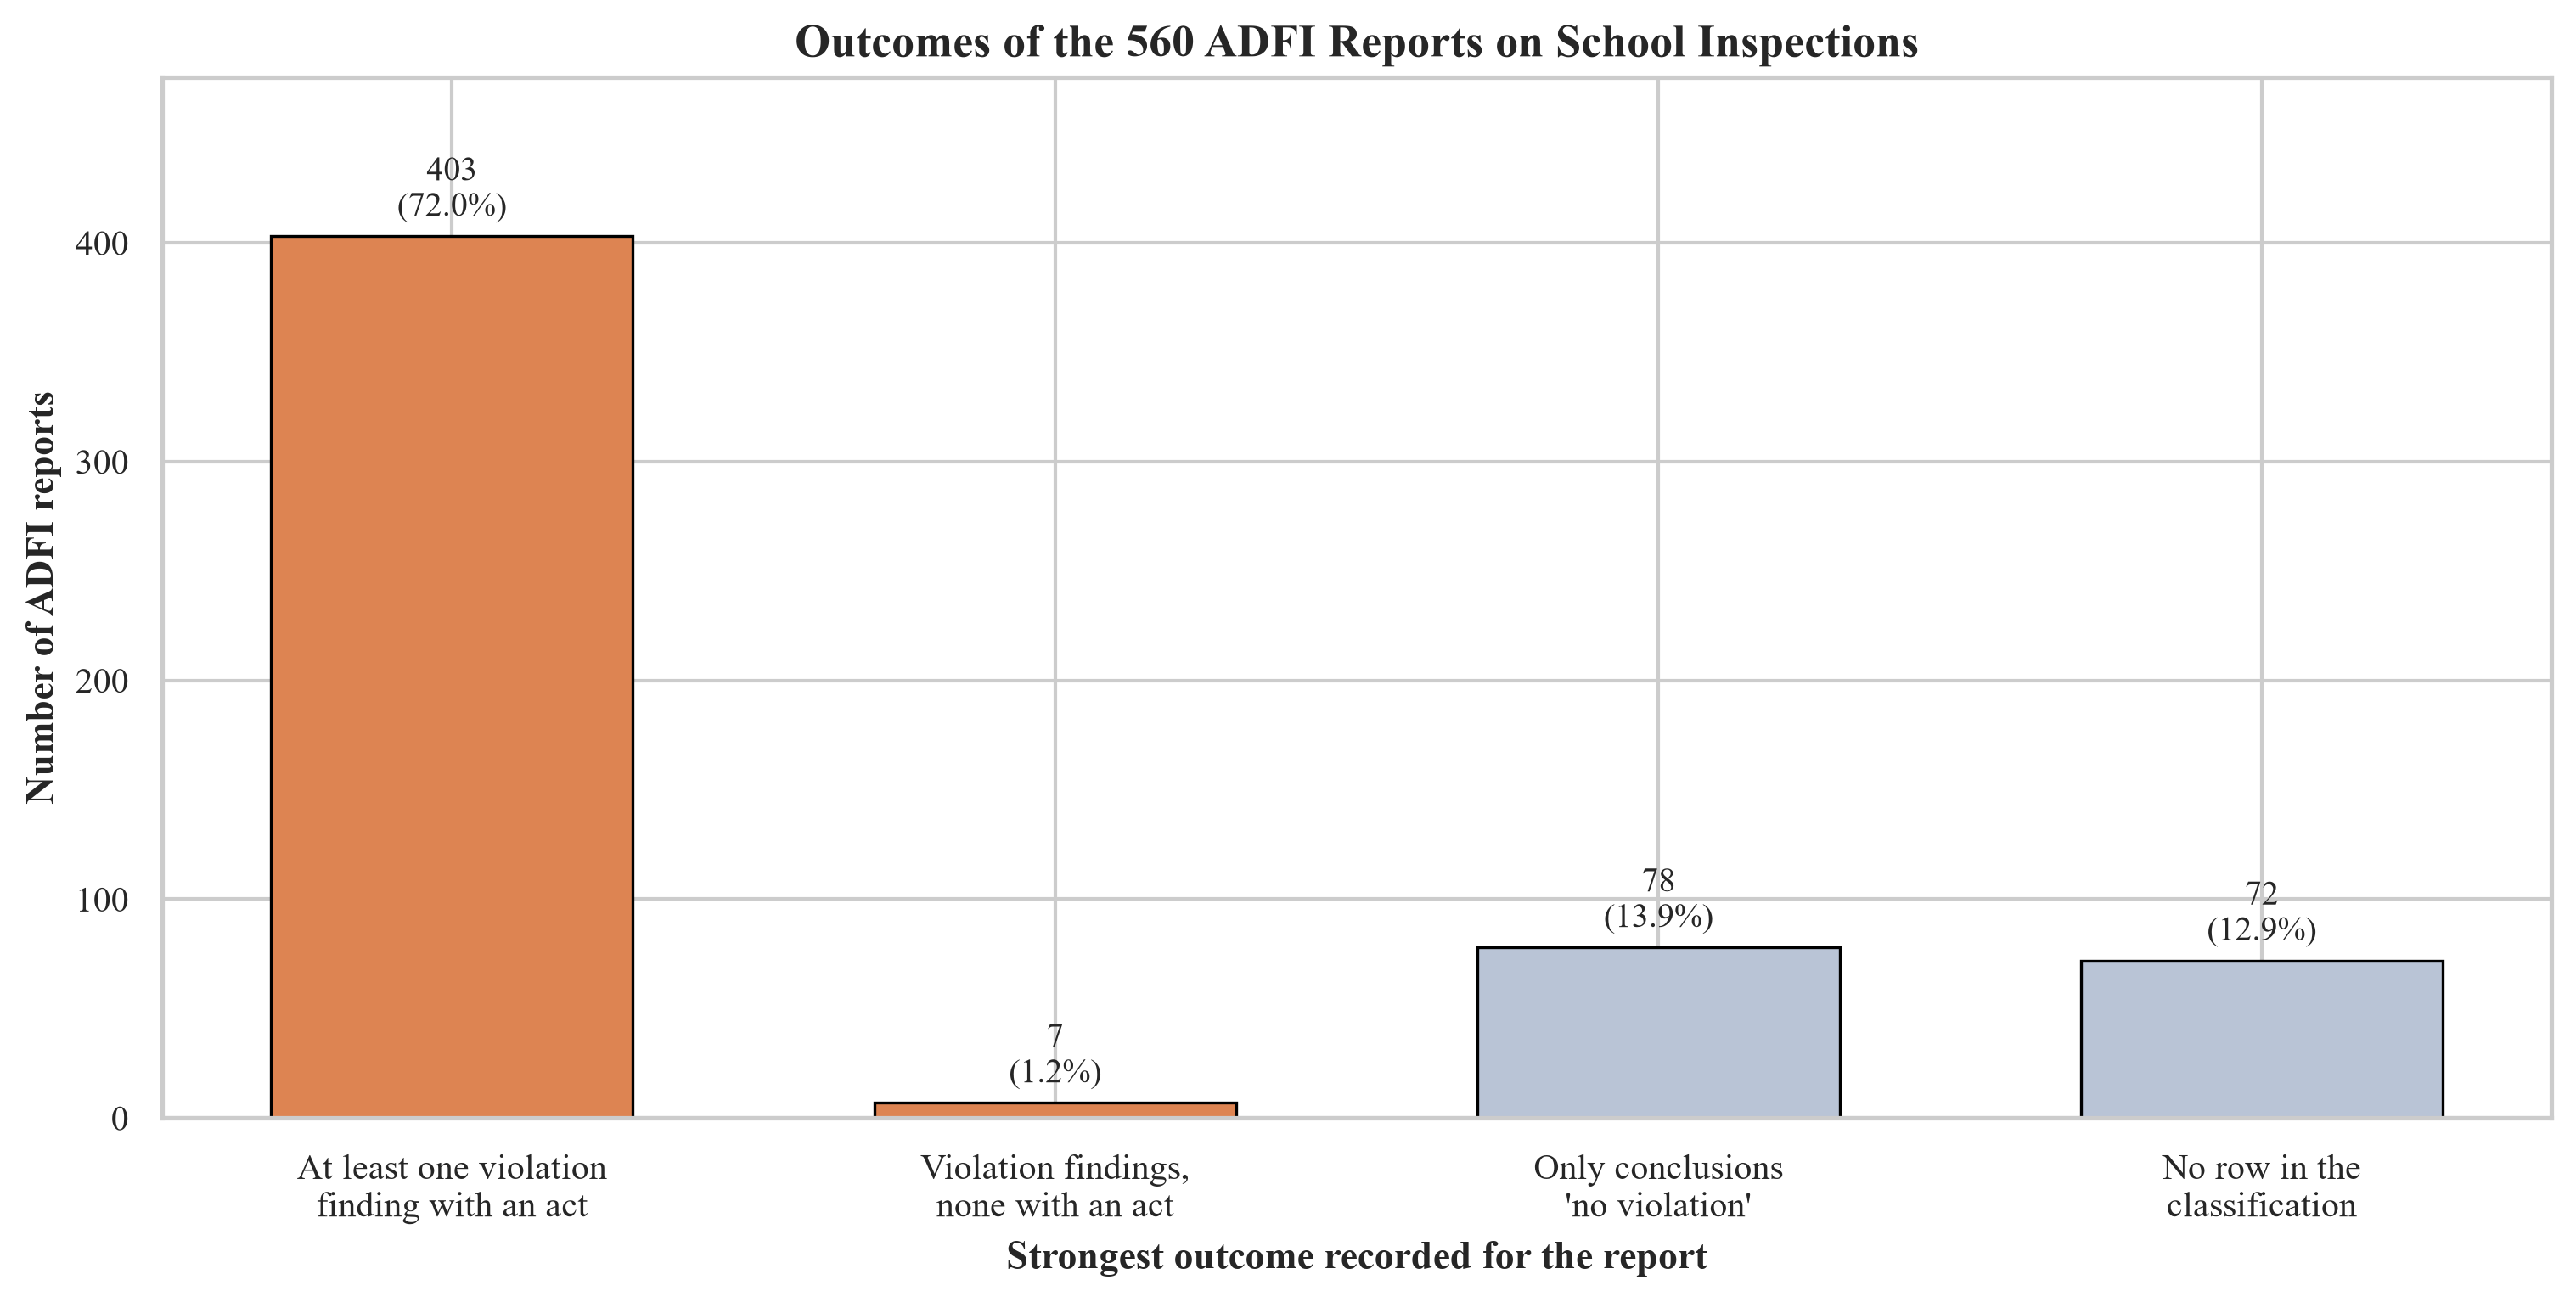

In [43]:
OUTCOME_LABELS: Final[dict[str, str]] = {
    "violation_with_act": "At least one violation\nfinding with an act",
    "violation_without_act": "Violation findings,\nnone with an act",
    "no_violation": "Only conclusions\n'no violation'",
    "not_classified": "No row in the\nclassification",
}
outcome_counts = adfi_reports["outcome"].value_counts().reindex(list(OUTCOME_LABELS))
assert outcome_counts.sum() == 560

fig_8_1, ax_8_1 = plt.subplots(figsize=(10, 5), constrained_layout=True)
bars = ax_8_1.bar(list(OUTCOME_LABELS.values()), outcome_counts.to_numpy(), color=["#dd8452", "#dd8452", "#b9c4d6", "#b9c4d6"], edgecolor="black", linewidth=0.8, width=0.6)
ax_8_1.bar_label(bars, labels=[f"{n:,}\n({n / outcome_counts.sum():.1%})" for n in outcome_counts], padding=3, fontsize=9.5)
ax_8_1.set_ylabel("Number of ADFI reports")
ax_8_1.set_xlabel("Strongest outcome recorded for the report")
ax_8_1.set_title("Outcomes of the 560 ADFI Reports on School Inspections")
ax_8_1.set_ylim(0, outcome_counts.max() * 1.18)
ax_8_1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: f"{int(y):,}"))
plt.show()

**Figure 8.1.** Number of ADFI reports by the strongest outcome recorded for the report: a violation finding with an act, a violation finding without an act, only conclusions that there is no violation, and no row in the classification.

*Source:* Calculation from ADFI (2026) and the classification of its reports.

**Question.** Which parts of a procurement do the findings concern?

**How to read.** The classifier has 11 sections. A bar is the number of classified rows, that is, pairs of a finding and a class, in a section. Orange bars are violation findings and light bars are conclusions of the inspector that there is no violation.

**What the figure is not.** A finding with several classes is counted once for each class. The rows count how often the inspectors examined and classified an action, not how often it was violated in all procurements.

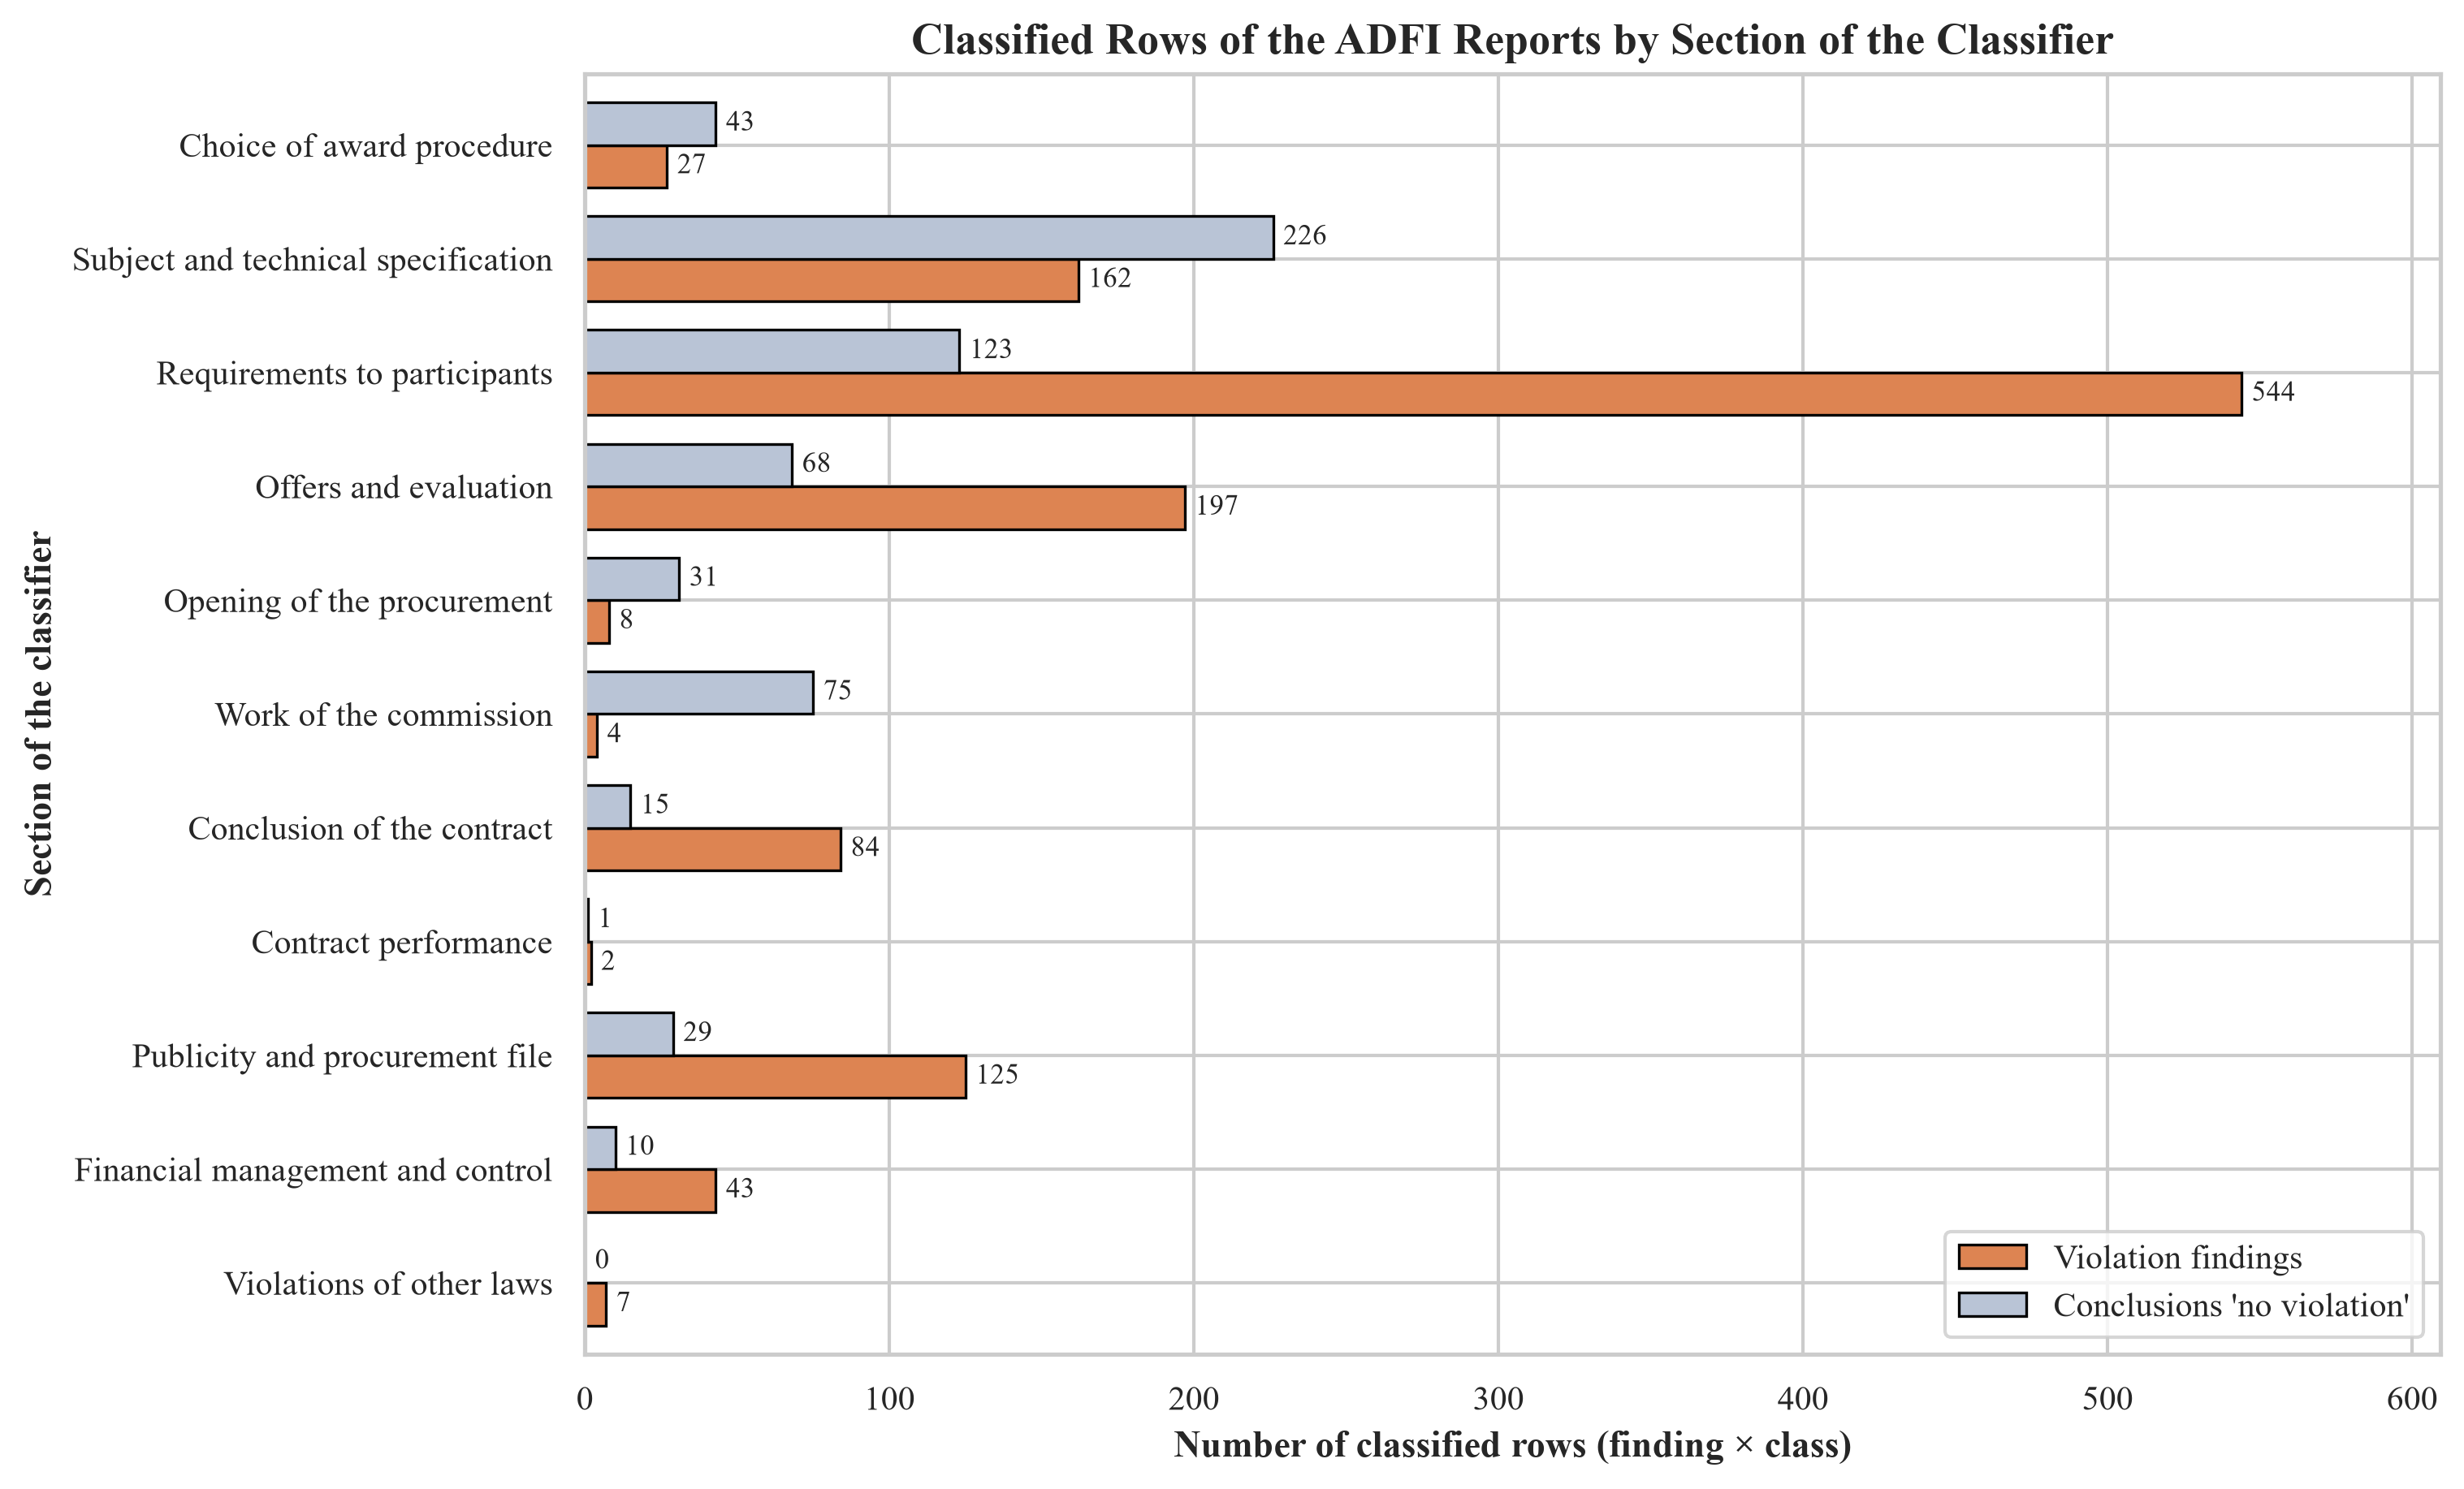

In [44]:
SECTION_LABELS: Final[dict[str, str]] = {
    "1": "Choice of award procedure", "2": "Subject and technical specification", "3": "Requirements to participants",
    "4": "Offers and evaluation", "5": "Opening of the procurement", "6": "Work of the commission",
    "7": "Conclusion of the contract", "8": "Contract performance", "9": "Publicity and procurement file",
    "10": "Financial management and control", "11": "Violations of other laws",
}
section_key = adfi_class["section"].str.split(".").str[0]
section_counts = (adfi_class.assign(section_label=section_key.map(SECTION_LABELS),
                                    kind=np.where(adfi_class["outcome"].isin(VIOLATION_OUTCOMES), "Violation findings", "Conclusions 'no violation'"))
                  .groupby(["section_label", "kind"]).size().unstack(fill_value=0).reindex(list(SECTION_LABELS.values())))
section_counts = section_counts[["Violation findings", "Conclusions 'no violation'"]]
assert section_counts.to_numpy().sum() == len(adfi_class)

fig_8_2, ax_8_2 = plt.subplots(figsize=(10, 6), constrained_layout=True)
section_counts.iloc[::-1].plot.barh(ax=ax_8_2, color=["#dd8452", "#b9c4d6"], edgecolor="black", linewidth=0.8, width=0.75)
for container in ax_8_2.containers:
    ax_8_2.bar_label(container, padding=3, fontsize=8.5)
ax_8_2.set_xlabel("Number of classified rows (finding × class)")
ax_8_2.set_ylabel("Section of the classifier")
ax_8_2.set_title("Classified Rows of the ADFI Reports by Section of the Classifier")
ax_8_2.set_xlim(0, section_counts.to_numpy().max() * 1.12)
ax_8_2.legend(title=None, loc="lower right", frameon=True, facecolor="white", edgecolor="#cccccc")
plt.show()

**Figure 8.2.** Number of classified rows of the ADFI reports by section of the classifier, for violation findings and for conclusions that there is no violation.

*Source:* Calculation from ADFI (2026) and the classification of its reports.

**Question.** In which provinces are the schools of the reports?

**How to read.** Each bar is a province, that is, one of the 28 oblasts of the register of schools; the names are transliterated. The bar is the number of reports on schools of that province. The orange part is the number of reports with at least one violation finding, the light part is the rest. Only the reports whose school is resolved to the register are counted (Section 8.4), which is the case for most of the 560 reports.

**What the figure is not.** The figure shows where the audited schools are, not where violations are more frequent. The number of reports of a province depends on how many schools it has and how many of them ADFI inspected.

518 of the 560 reports belong to a school that is resolved to the register; they lie in 28 of the 28 provinces.


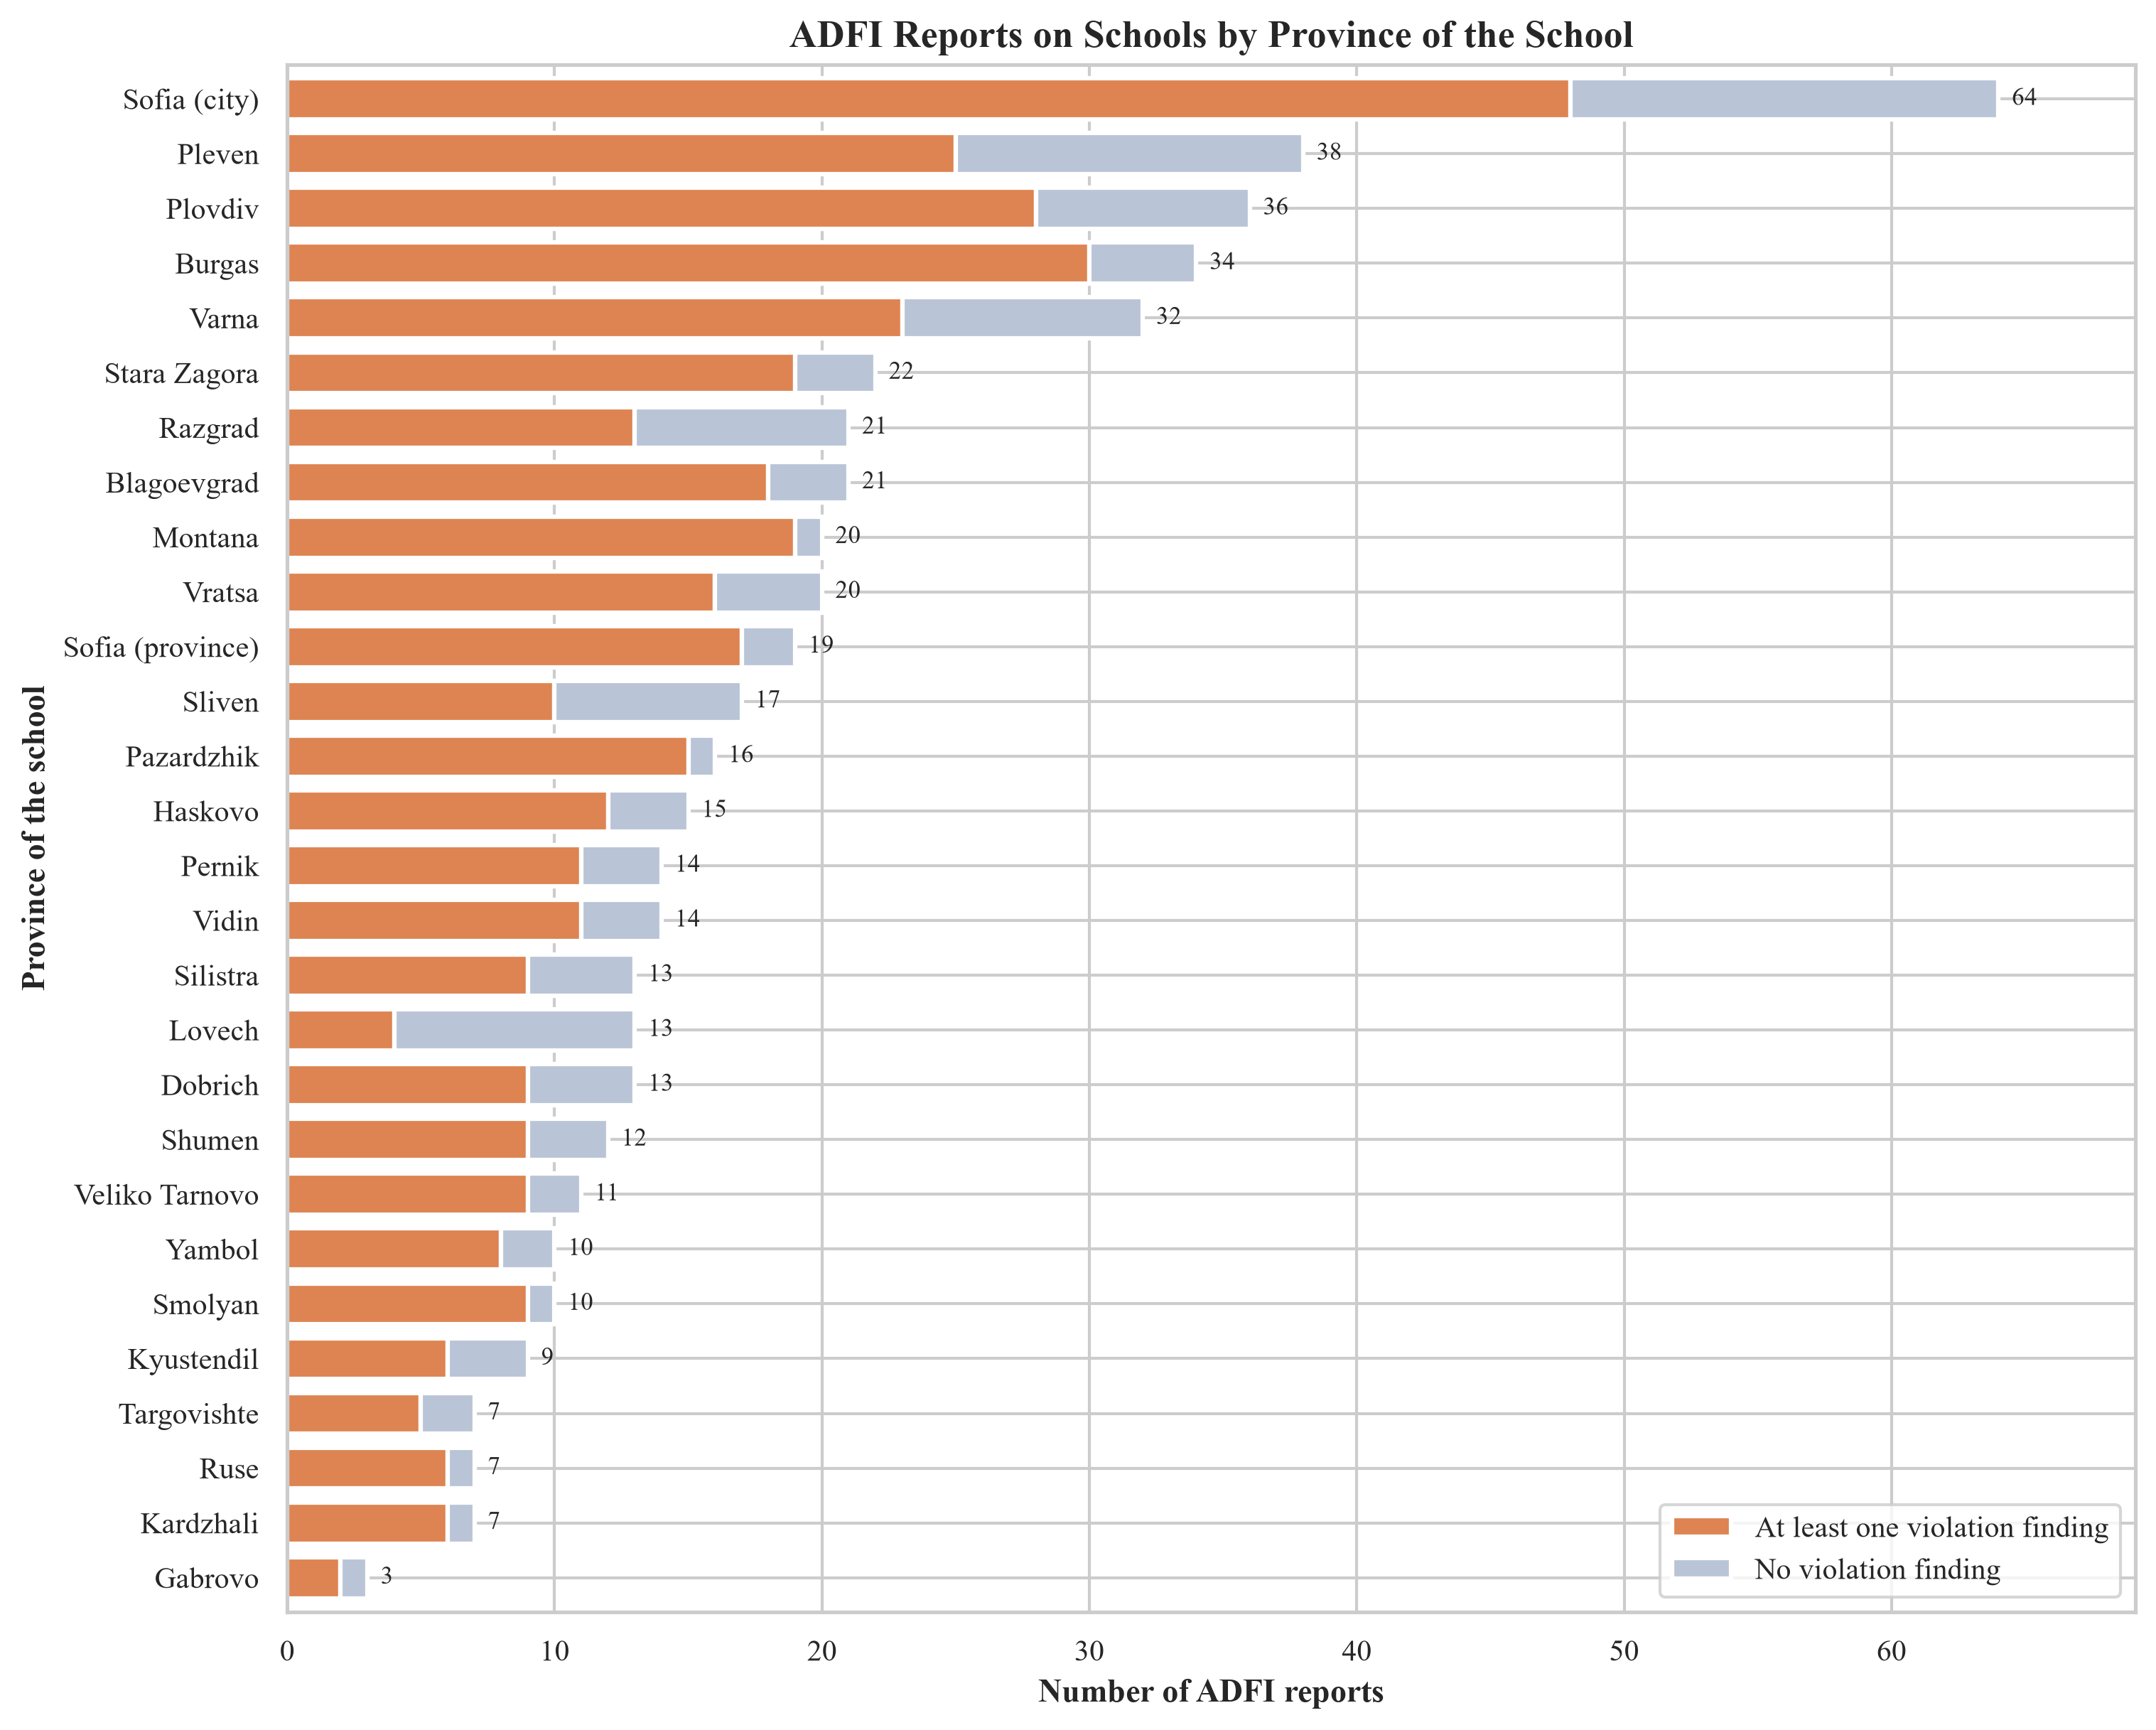

In [45]:
PROVINCE_NAMES: Final[dict[str, str]] = {  # the 28 oblasts of the register, transliterated by the Streamlined System
    "Благоевград": "Blagoevgrad", "Бургас": "Burgas", "Варна": "Varna", "Велико Търново": "Veliko Tarnovo", "Видин": "Vidin",
    "Враца": "Vratsa", "Габрово": "Gabrovo", "Добрич": "Dobrich", "Кърджали": "Kardzhali", "Кюстендил": "Kyustendil",
    "Ловеч": "Lovech", "Монтана": "Montana", "Пазарджик": "Pazardzhik", "Перник": "Pernik", "Плевен": "Pleven",
    "Пловдив": "Plovdiv", "Разград": "Razgrad", "Русе": "Ruse", "Силистра": "Silistra", "Сливен": "Sliven",
    "Смолян": "Smolyan", "София-град": "Sofia (city)", "София-област": "Sofia (province)", "Стара Загора": "Stara Zagora",
    "Търговище": "Targovishte", "Хасково": "Haskovo", "Шумен": "Shumen", "Ямбол": "Yambol",
}
assert set(schools_register[REG_OBLAST]) == set(PROVINCE_NAMES), "A province of the register has no Latin name"
report_province = adfi_reports["school_eik"].map(schools_register.set_index(REG_BULSTAT)[REG_OBLAST]).map(PROVINCE_NAMES)  # empty for a school that is not resolved
province_counts = (adfi_reports.assign(province=report_province, kind=np.where(adfi_reports["report_id"].isin(violation_reports),
                                                                        "At least one violation finding", "No violation finding"))
                 .dropna(subset=["province"]).groupby(["province", "kind"]).size().unstack(fill_value=0)
                 .reindex(columns=["At least one violation finding", "No violation finding"], fill_value=0))
province_counts = province_counts.loc[province_counts.sum(axis=1).sort_values().index]
print(f"{int(province_counts.to_numpy().sum())} of the {len(adfi_reports)} reports belong to a school that is resolved to the register; "
      f"they lie in {len(province_counts)} of the {len(PROVINCE_NAMES)} provinces.")

fig_8_3, ax_8_3 = plt.subplots(figsize=(10, 8), constrained_layout=True)
province_counts.plot.barh(ax=ax_8_3, stacked=True, color=["#dd8452", "#b9c4d6"], edgecolor="white", linewidth=1.5, width=0.75)
for index, total in enumerate(province_counts.sum(axis=1)):
    ax_8_3.text(total + 0.5, index, f"{total}", va="center", fontsize=8.5)
ax_8_3.set_xlabel("Number of ADFI reports")
ax_8_3.set_ylabel("Province of the school")
ax_8_3.set_title("ADFI Reports on Schools by Province of the School")
ax_8_3.set_xlim(0, province_counts.sum(axis=1).max() * 1.08)
ax_8_3.legend(title=None, loc="lower right", frameon=True, facecolor="white", edgecolor="#cccccc")
plt.show()

**Figure 8.3.** Number of ADFI reports by province of the school, with and without a violation finding.

*Source:* Calculation from ADFI (2026), the classification of its reports and the register of schools.

### 8.9 Privacy and Summary of the Checks

The cell below checks the tables of this section for personal data and repeats the main invariants of the section. It fails if one of them is violated.

In [46]:
adfi_written = sorted(PathConfig.DATA_DIR.glob("adfi_*.csv")) + [OUT_ADFI_MATCHES]
for path in adfi_written:
    table = read_work_csv(path)
    assert not FORBIDDEN_HEADERS.intersection(table.columns), f"{path} contains a personal data column"
    for column in table.columns:
        assert not table[column].str.fullmatch(r"\d{10}").any(), f"{path}: column {column!r} holds a ten-digit number"
assert not firm_table["legal_form"].eq("ЕТ").any() and not firm_table["firm_name"].str.contains(r"(?<!\w)ЕТ(?!\w)|Адвокат").any()
assert not {"Основа (дословно)", "Извод (дословно)", "Основа", "Извод"}.intersection(adfi_class.columns)
print(f"Privacy check passed for {len(adfi_written)} tables: no personal data columns, no ten-digit numbers, no sole traders, no verbatim text.")
print("Tables written:")
for path in adfi_written + [OUT_ADFI_XML, OUT_ADFI_XSD]:
    print(f"  {path.as_posix():<42} {path.stat().st_size / 1024:>9,.0f} KB")

assert len(adfi_class) == 1824 and adfi_class["school_name"].nunique() == 479 and adfi_class["report_id"].nunique() == 488
print("Classification: 1,824 rows, 479 schools and 488 reports, as in the source.")

assert len(report_table) == 560 and report_table["report_id"].is_unique and len(adfi_schema.to_dict(str(OUT_ADFI_XML))["report"]) == 560
print("Reports: 560 reports, each with an inspectorate code, and an XML document that the schema accepts.")

assert all(validate_bulstat_checksum(code) for code in adfi_schools.loc[adfi_schools["match_stage"] == "bulstat", "school_eik"])
assert adfi_schools.loc[adfi_schools["match_stage"] != "none", "school_eik"].isin(register_set).all()
stage_counts = adfi_schools["match_stage"].value_counts()
assert (stage_counts["bulstat"], stage_counts["name_settlement"], stage_counts["none"]) == (304, 160, 15)
assert len(agree_pool) == 272 and int((agree_pool["stage1"] == agree_pool["stage2"]).sum()) == 269
print("Matching: every school resolved by Bulstat has a Bulstat that passes the checksum, and every resolved school is in the register.")
print("Stages: 304 schools by Bulstat, 160 by name and settlement, 15 unresolved; stage 2 agrees with stage 1 for 269 of 272 schools.")

assert len(audited_in_procedure) == 462 and int(report_table["n_stem"].gt(0).sum()) == 481
print("Overlap: 462 audited schools are beneficiaries of the procedure; 481 of the 560 reports name the STEM environment or procedure BG-RRP.")

Privacy check passed for 4 tables: no personal data columns, no ten-digit numbers, no sole traders, no verbatim text.
Tables written:
  data/adfi_classification.csv                     955 KB
  data/adfi_firms.csv                               86 KB
  data/adfi_transcript_features.csv                 41 KB
  data/derived/adfi_matches.csv                    478 KB
  data/adfi_validation.xml                         471 KB
  data/adfi_validation.xsd                           3 KB
Classification: 1,824 rows, 479 schools and 488 reports, as in the source.


Reports: 560 reports, each with an inspectorate code, and an XML document that the schema accepts.
Matching: every school resolved by Bulstat has a Bulstat that passes the checksum, and every resolved school is in the register.
Stages: 304 schools by Bulstat, 160 by name and settlement, 15 unresolved; stage 2 agrees with stage 1 for 269 of 272 schools.
Overlap: 462 audited schools are beneficiaries of the procedure; 481 of the 560 reports name the STEM environment or procedure BG-RRP.


## 9. Bipartite Market, Co-occurrence Projections and Consultant Steering

The purchases of the schools form a network with two kinds of nodes: the schools that buy and the suppliers that sell (Wachs and Kertész, 2019; Wachs, Fazekas and Kertész, 2021). This section turns the contract table of Section 7 into sparse matrices, projects them onto the suppliers, and computes two sets of indicators: whether a consultant signs before the suppliers of the same school, and how closely the neighbours of a supplier are linked to each other.

**Inputs.** The section reads only working tables: `data/derived/contracts.csv`, `data/isun_projects.csv` and `data/isun_entities.csv`. No source file is opened. Values are in EUR excluding VAT (`amount_eur_excl_vat`), the currency and VAT basis of Section 7.7.

**Rows and columns.** A row is a project, and the notebook calls it a school: the 2,223 projects with a contract belong to 2,222 different school Bulstat values, so a project and a school coincide except for one school. A column is a supplier, identified by its identifier in the open data.

**Outputs.** `data/cache/bipartite_matrices.npz` holds the matrices and is not kept in Git. `data/derived/consultant_steering.csv` holds one row for each pair of a consultant and a supplier.

**Neutral reading.** A link, a ratio or a $p$-value in this section is a statistical indicator of risk. It is not evidence of an agreement, and it does not name a violation.

### 9.1 Sparse Bipartite Matrices

**Definition.** Let $U$ be the $N_U$ schools and $V$ the $N_V$ suppliers. The binary matrix $B \in \{0, 1\}^{N_U \times N_V}$ and the weighted matrix $W \in \mathbb{R}_{\ge 0}^{N_U \times N_V}$ are

$$B_{i\alpha} = \begin{cases} 1, & \text{if school } i \text{ awarded at least one contract to supplier } \alpha \\ 0, & \text{otherwise,} \end{cases} \qquad W_{i\alpha} = \sum_{k \in \text{Contracts}(i, \alpha)} \text{amount\_eur\_excl\_vat}_k.$$

The degree of school $i$ is $k_i = \sum_\alpha B_{i\alpha}$ and the degree of supplier $\alpha$ is $d_\alpha = \sum_i B_{i\alpha}$. Both matrices are stored in the compressed sparse row format, so that only the filled cells use memory.

**Two features of the data.** Five projects have no contract and are empty rows. One contract has no supplier identifier in the open data; it is one column of its own, with the default role of Section 7.8, and the section keeps it so that the matrix has one column for every distinct identifier. Its effect on the results is small, because it has one school.

**Check.** The cell asserts the shape $2\,228 \times 1\,755$ for $B$ and $W$, the same number of filled cells in both, and that $W$ holds the whole contracted value of the table.

In [47]:
from dataclasses import dataclass

import networkx as nx
from scipy import sparse

OUT_STEERING: Final[Path] = PathConfig.DERIVED_DIR / "consultant_steering.csv"
OUT_MATRICES: Final[Path] = PathConfig.CACHE_DIR / "bipartite_matrices.npz"
UNIDENTIFIED_LABEL: Final[str] = "[unidentified supplier]"


@dataclass(frozen=True)
class BipartiteMatrices:
    """Sparse matrices of the market of schools (rows) and suppliers (columns).

    `binary` is B, with 1 where a school awarded at least one contract to a supplier. `value` is W, the sum of the
    contract values between the two (Saracco et al., 2017; Wachs and Kertész, 2019).
    """
    binary: sparse.csr_matrix
    value: sparse.csr_matrix
    school_ids: np.ndarray
    vendor_ids: np.ndarray


def build_bipartite_matrices(contract_table: pd.DataFrame, project_ids: Sequence[str], value_column: str) -> BipartiteMatrices:
    """Build B and W from the contract table.

    Rows are the projects, one for each school, and columns are the suppliers, both sorted by identifier. A supplier
    with no identifier in the open data is one column of its own. Duplicate pairs are summed in W and counted once in B.
    """
    school_ids = np.array(sorted(project_ids))
    vendor_ids = np.array(sorted(contract_table["vendor_id"].unique()))
    rows = np.searchsorted(school_ids, contract_table["project_id"].to_numpy())
    columns = np.searchsorted(vendor_ids, contract_table["vendor_id"].to_numpy())
    assert (school_ids[rows] == contract_table["project_id"].to_numpy()).all(), "A contract belongs to an unknown project"
    shape = (len(school_ids), len(vendor_ids))
    value = sparse.coo_matrix((contract_table[value_column].to_numpy(dtype=np.float64), (rows, columns)), shape=shape).tocsr()
    binary = sparse.coo_matrix((np.ones(len(rows), dtype=np.int32), (rows, columns)), shape=shape).tocsr()
    binary.data[:] = 1
    return BipartiteMatrices(binary, value, school_ids, vendor_ids)


matrix_contracts = read_work_csv(OUT_CONTRACTS, ["amount_eur_excl_vat"])
matrix_projects = read_work_csv(WORK_PROJECTS)["project_id"]
matrix_entities = read_work_csv(WORK_ENTITIES).set_index("entity_id")

market = build_bipartite_matrices(matrix_contracts, matrix_projects, "amount_eur_excl_vat")
B, W = market.binary, market.value
N_U, N_V = B.shape
school_degree = np.asarray(B.sum(axis=1)).ravel()
vendor_degree = np.asarray(B.sum(axis=0)).ravel()

vendor_table = pd.DataFrame({"vendor_id": market.vendor_ids})
vendor_table["vendor_name"] = vendor_table["vendor_id"].map(matrix_entities["name"]).fillna("")
vendor_table.loc[vendor_table["vendor_id"] == "", "vendor_name"] = UNIDENTIFIED_LABEL
first_row = matrix_contracts.drop_duplicates("vendor_id").set_index("vendor_id")
vendor_table["vendor_eik"] = vendor_table["vendor_id"].map(first_row["vendor_eik"])
vendor_table["vendor_role"] = vendor_table["vendor_id"].map(first_row["vendor_role"])

assert B.shape == (2228, 1755), f"Expected shape (2228, 1755), got {B.shape}"
assert W.shape == (2228, 1755), f"Expected shape (2228, 1755), got {W.shape}"
assert B.nnz == W.nnz and set(np.unique(B.data)) == {1}
assert np.isclose(W.sum(), matrix_contracts["amount_eur_excl_vat"].sum())

print(f"B and W: {N_U:,} schools (projects) by {N_V:,} suppliers; {B.nnz:,} school-supplier pairs from {len(matrix_contracts):,} contracts; "
      f"density {B.nnz / (N_U * N_V):.4%}.")
print(f"Total contracted value in W: {W.sum():,.2f} EUR excluding VAT.")
unidentified = vendor_table["vendor_id"].eq("").to_numpy()
print(f"The {int((school_degree == 0).sum())} projects without a contract are empty rows; {int(unidentified.sum())} column holds "
      f"the contract with no supplier identifier (degree {int(vendor_degree[unidentified][0])}).")

B and W: 2,228 schools (projects) by 1,755 suppliers; 7,229 school-supplier pairs from 11,128 contracts; density 0.1849%.
Total contracted value in W: 240,477,481.64 EUR excluding VAT.
The 5 projects without a contract are empty rows; 1 column holds the contract with no supplier identifier (degree 1).


### 9.2 Projections onto the Suppliers

**Question.** How many schools do two suppliers share, and how much do they contract in them?

**Projections.** The co-occurrence matrix counts the schools that contracted both suppliers, the weighted product sums the products of their values, and $S$ sums the values that the two suppliers have in the schools they share (the edge weight of a network drawing). The Jaccard similarity is the share of the schools of either supplier that they have in common.

$$O = B^{T} B, \qquad W^{\text{proj}} = W^{T} W, \qquad S = W^{T} B + B^{T} W, \qquad J_{\alpha\beta} = \frac{O_{\alpha\beta}}{d_\alpha + d_\beta - O_{\alpha\beta}}.$$

**Properties.** Since $B$ is binary, $O_{\alpha\alpha} = d_\alpha$, so the diagonal of $O$ is the degree of the suppliers, and $O$ is symmetric because $O^{T} = (B^T B)^T = O$. The off-diagonal entry $O_{\alpha\beta}$ is the number of schools that contracted both.

**Check.** The cell asserts the shape $1\,755 \times 1\,755$, the diagonal, the symmetry of $O$, $W^{\text{proj}}$ and $S$, and compares $S$ and $J$ with a direct sum over the shared schools of the pair with the largest overlap.

**What the projection does not show.** $O$ is not corrected for the degree of the suppliers. A supplier with hundreds of schools meets most other suppliers by chance, and two small suppliers that share all their few schools look weak in $O$ (Tumminello et al., 2011; Saracco et al., 2017). The comparisons of this section are therefore made between suppliers of a similar kind.

In [48]:
def jaccard_matrix(co_occurrence: sparse.csr_matrix, degree: np.ndarray) -> sparse.csr_matrix:
    """Jaccard similarity J = O / (d_a + d_b - O) of the school sets of two suppliers, for the pairs with O > 0."""
    coo = co_occurrence.tocoo()
    union = degree[coo.row] + degree[coo.col] - coo.data
    return sparse.csr_matrix((coo.data / union, (coo.row, coo.col)), shape=co_occurrence.shape)


O = (B.T @ B).tocsr()
W_proj = (W.T @ W).tocsr()
S = (W.T @ B + B.T @ W).tocsr()
J = jaccard_matrix(O, vendor_degree)

assert O.shape == (1755, 1755), f"Expected shape (1755, 1755), got {O.shape}"
assert np.array_equal(O.diagonal(), vendor_degree), "Gram matrix diagonal does not match vendor degree vector!"
assert (O != O.T).nnz == 0, "Gram matrix O is not symmetric!"
assert (W_proj != W_proj.T).nnz == 0 and abs(S - S.T).max() == 0.0
assert np.allclose(J.diagonal(), 1.0) and J.data.min() > 0.0 and J.data.max() <= 1.0 + 1e-12

# S and J agree with a direct sum over the shared schools for a pair of suppliers with many of them
pair_a, pair_b = np.unravel_index(np.argmax(np.triu(O.toarray(), k=1)), O.shape)
shared_mask = B[:, pair_a].multiply(B[:, pair_b]).toarray().ravel().astype(bool)
direct_value = float(W[shared_mask][:, [pair_a, pair_b]].sum())
assert np.isclose(S[pair_a, pair_b], direct_value)
assert np.isclose(J[pair_a, pair_b], shared_mask.sum() / (vendor_degree[pair_a] + vendor_degree[pair_b] - shared_mask.sum()))

print(f"O = B'B: {O.shape[0]:,} by {O.shape[1]:,}, {O.nnz:,} non-zero entries ({O.nnz - N_V:,} off the diagonal, {(O.nnz - N_V) // 2:,} supplier pairs).")
print(f"Checks passed: diag(O) equals the supplier degrees, O is symmetric, and S and J agree with a direct sum over the {int(shared_mask.sum())} "
      f"schools shared by the pair with the largest overlap.")
print(f"W'W: {W_proj.nnz:,} and S: {S.nnz:,} non-zero entries; largest off-diagonal Jaccard similarity {np.max(J.data[J.tocoo().row != J.tocoo().col]):.4f}.")

O = B'B: 1,755 by 1,755, 17,853 non-zero entries (16,098 off the diagonal, 8,049 supplier pairs).
Checks passed: diag(O) equals the supplier degrees, O is symmetric, and S and J agree with a direct sum over the 133 schools shared by the pair with the largest overlap.
W'W: 17,813 and S: 17,851 non-zero entries; largest off-diagonal Jaccard similarity 1.0000.


### 9.3 Reference Quantities

The degrees of the two largest suppliers, the density of $O$ and the distribution of the degrees are reported against the figures that were used to design the section. They are not asserted, because they depend on the contract table of Section 7.

In [49]:
REFERENCE_DEGREES: Final[dict[str, int]] = {"000885099": 581, "131468980": 298}  # reported, not asserted
LATIN_LETTERS: Final[dict[str, str]] = {
    "а": "a", "б": "b", "в": "v", "г": "g", "д": "d", "е": "e", "ж": "zh", "з": "z", "и": "i", "й": "y", "к": "k", "л": "l",
    "м": "m", "н": "n", "о": "o", "п": "p", "р": "r", "с": "s", "т": "t", "у": "u", "ф": "f", "х": "h", "ц": "ts", "ч": "ch",
    "ш": "sh", "щ": "sht", "ъ": "a", "ь": "y", "ю": "yu", "я": "ya",
}
LEGAL_FORMS: Final[re.Pattern[str]] = re.compile(r"\b(Eood|Ood|Ead|Ad|Dzzd|Sd|Kd)\b")


def transliterate(text: str) -> str:
    """Transliterate Bulgarian text into Latin letters by the Streamlined System and remove quotation marks."""
    text = re.sub(r'[„“”"]|,,', "", text).strip()
    shout = text.isupper()  # a name in capitals is returned in title case
    latin = "".join(
        (LATIN_LETTERS[ch.lower()].capitalize() if ch.isupper() else LATIN_LETTERS[ch]) if ch.lower() in LATIN_LETTERS else ch
        for ch in (text.lower() if shout else text)
    )
    return LEGAL_FORMS.sub(lambda match: match.group(0).upper(), latin.title() if shout else latin)


vendor_table["label"] = [UNIDENTIFIED_LABEL.strip("[]").capitalize() if name == UNIDENTIFIED_LABEL else transliterate(name) for name in vendor_table["vendor_name"]]


def vendor_position(eik: str) -> int:
    """Column of the supplier with an identification number; the number must belong to exactly one supplier."""
    positions = np.flatnonzero((vendor_table["vendor_eik"] == eik).to_numpy())
    assert len(positions) == 1, f"The number {eik} belongs to {len(positions)} suppliers"
    return int(positions[0])


for eik, reference in REFERENCE_DEGREES.items():
    print(f"Degree of {vendor_table.at[vendor_position(eik), 'label']} ({eik}): {vendor_degree[vendor_position(eik)]} schools (reference {reference}).")
print(f"Density of O: {O.nnz / N_V ** 2:.4%} with {O.nnz:,} non-zero entries.")
print(f"School degree k: mean {school_degree.mean():.2f}, median {np.median(school_degree):.0f}, maximum {school_degree.max()}. "
      f"Supplier degree d: median {np.median(vendor_degree):.0f}, maximum {vendor_degree.max()}; "
      f"{int((vendor_degree == 1).sum()):,} of the {N_V:,} suppliers serve one school only.")

Degree of Kooperatsiya Panda (000885099): 581 schools (reference 581).
Degree of A1 Balgariya EAD (131468980): 298 schools (reference 298).
Density of O: 0.5796% with 17,853 non-zero entries.
School degree k: mean 3.24, median 3, maximum 21. Supplier degree d: median 1, maximum 581; 1,190 of the 1,755 suppliers serve one school only.


### 9.4 Consultant Precedence, Lift and a Permutation Test

**Question.** Does a consultant sign with a school before the suppliers of the same school more often than chance would give?

**Hypothesis.** A consultant who prepares the documents of a procurement is engaged before the supplier is selected (OECD, 2016). For a pair of a consultant $\alpha \in V_{\text{cons}}$ and a supplier $\beta \in V_{\text{tech}} \cup V_{\text{civil}}$, let $t(i, \alpha)$ be the earliest signature date of school $i$ with $\alpha$. Then

$$M(\alpha, \beta) = \sum_{i=1}^{N_U} B_{i\alpha} B_{i\beta} \, \mathbb{I}\bigl[ t(i, \alpha) \le t(i, \beta) \bigr], \qquad \text{Lift}(\alpha, \beta) = \frac{M(\alpha, \beta) \, N_U}{d_\alpha \, d_\beta}.$$

The lift compares $M$ with the count that independent placement of the two suppliers in the $N_U$ schools would give, as in the bilateral measure of Coscia and Neffke (2017), here adapted to the order of dates. A signature on the same day counts as precedence; the cell reports how many comparisons are ties.

**Null model.** The bipartite graph is held fixed. In each of 1,000 permutations the signature dates of every school are permuted among its suppliers, which keeps $k_i$ and $d_\alpha$ and removes only the order. The $p$-value of a pair is

$$p_{\alpha\beta} = \frac{1 + \sum_{\pi=1}^{R} \mathbb{I}\bigl[ M^{\pi}(\alpha, \beta) \ge M(\alpha, \beta) \bigr]}{R + 1}, \qquad R = 1\,000.$$

**Multiple tests.** The table has one row for each pair, so the $p$-values are also adjusted by the Benjamini–Hochberg procedure (column `q_value_bh`), at the level $\alpha = 0.01$ of the notebook.

**Output.** `data/derived/consultant_steering.csv` has the eight columns `consultant_eik`, `consultant_name`, `vendor_eik`, `vendor_name`, `shared_schools`, `precedence_count`, `empirical_lift` and `p_value_null`, and two more: `precedence_rate` and `q_value_bh`. The names of sole traders and persons are masked in the open data of Section 7.

In [50]:
def benjamini_hochberg(p_values: np.ndarray) -> np.ndarray:
    """Adjusted p-values (q-values) of the Benjamini-Hochberg procedure."""
    count = len(p_values)
    order = np.argsort(p_values)
    scaled = p_values[order] * count / np.arange(1, count + 1)
    adjusted = np.minimum(np.minimum.accumulate(scaled[::-1])[::-1], 1.0)
    q_values = np.empty(count)
    q_values[order] = adjusted
    return q_values


def first_signature_days(contract_table: pd.DataFrame, school_ids: np.ndarray, vendor_ids: np.ndarray) -> pd.DataFrame:
    """Earliest signature date of each school-supplier pair, in days, ordered by school (Coscia and Neffke, 2017)."""
    days = (pd.to_datetime(contract_table["signature_date"]) - pd.Timestamp("1970-01-01")).dt.days
    pairs = (contract_table.assign(day=days.to_numpy())
             .groupby(["project_id", "vendor_id"], as_index=False).agg(day=("day", "min"), role=("vendor_role", "first")))
    pairs["school"] = np.searchsorted(school_ids, pairs["project_id"].to_numpy())
    pairs["vendor"] = np.searchsorted(vendor_ids, pairs["vendor_id"].to_numpy())
    return pairs.sort_values(["school", "vendor"]).reset_index(drop=True)[["school", "vendor", "day", "role"]]


def consultant_steering(first_days: pd.DataFrame, permutations: int, seed: int) -> pd.DataFrame:
    """Precedence of consultants before suppliers within schools, with a within-school permutation null.

    For a consultant a and a supplier b, M(a, b) counts the schools that contracted both and where the consultant
    signed no later than the supplier. The null permutes the signature dates among the suppliers of each school and
    leaves the bipartite graph unchanged. The p-value is (1 + #{M_perm >= M}) / (R + 1).
    """
    consultants = first_days[first_days["role"] == "V_cons"].reset_index(names="row")
    suppliers = first_days[first_days["role"].isin(["V_tech", "V_civil"])].reset_index(names="row")
    triples = consultants.merge(suppliers, on="school", suffixes=("_c", "_s"))
    codes = triples.groupby(["vendor_c", "vendor_s"]).ngroup().to_numpy()
    pairs = triples.groupby(["vendor_c", "vendor_s"], as_index=False).size().rename(columns={"size": "shared_schools"})
    row_c, row_s = triples["row_c"].to_numpy(), triples["row_s"].to_numpy()
    days, school = first_days["day"].to_numpy(), first_days["school"].to_numpy()
    size = len(pairs)

    pairs["precedence_count"] = np.bincount(codes, weights=days[row_c] <= days[row_s], minlength=size).astype(int)
    pairs["tied_schools"] = np.bincount(codes, weights=days[row_c] == days[row_s], minlength=size).astype(int)
    generator = np.random.default_rng(seed)
    at_least_as_large = np.zeros(size, dtype=np.int64)
    null_total = np.zeros(size)
    for _ in range(permutations):
        order = np.lexsort((generator.random(len(first_days)), school))  # the rows of a school are contiguous
        shuffled = days[order]
        permuted = np.bincount(codes, weights=shuffled[row_c] <= shuffled[row_s], minlength=size)
        at_least_as_large += permuted >= pairs["precedence_count"].to_numpy()
        null_total += permuted
    pairs["null_mean_precedence"] = null_total / permutations
    pairs["p_value_null"] = (1 + at_least_as_large) / (permutations + 1)
    pairs["q_value_bh"] = benjamini_hochberg(pairs["p_value_null"].to_numpy())
    return pairs


first_days = first_signature_days(matrix_contracts, market.school_ids, market.vendor_ids)
assert len(first_days) == B.nnz and first_days["school"].is_monotonic_increasing
steering = consultant_steering(first_days, ModelConfig.N_STRATIFIED_PERMUTATIONS, ModelConfig.SEED)

# the number of schools with both suppliers is the entry of O, and the precedence count cannot exceed it
assert (np.asarray(O[steering["vendor_c"].to_numpy(), steering["vendor_s"].to_numpy()]).ravel() == steering["shared_schools"].to_numpy()).all()
assert (steering["precedence_count"] <= steering["shared_schools"]).all() and steering["p_value_null"].between(0, 1).all()

steering["consultant_eik"] = vendor_table["vendor_eik"].to_numpy()[steering["vendor_c"]]
steering["consultant_name"] = vendor_table["vendor_name"].to_numpy()[steering["vendor_c"]]
steering["vendor_eik"] = vendor_table["vendor_eik"].to_numpy()[steering["vendor_s"]]
steering["vendor_name"] = vendor_table["vendor_name"].to_numpy()[steering["vendor_s"]]
steering["empirical_lift"] = (steering["precedence_count"] * N_U
                              / (vendor_degree[steering["vendor_c"]] * vendor_degree[steering["vendor_s"]]))
steering["precedence_rate"] = steering["precedence_count"] / steering["shared_schools"]
steering = steering.sort_values(["shared_schools", "precedence_count", "consultant_eik", "vendor_eik"],
                                ascending=[False, False, True, True], kind="mergesort").reset_index(drop=True)

STEERING_COLUMNS: Final[list[str]] = ["consultant_eik", "consultant_name", "vendor_eik", "vendor_name", "shared_schools", "precedence_count",
                                      "precedence_rate", "empirical_lift", "p_value_null", "q_value_bh"]
write_work_csv(steering[STEERING_COLUMNS].round({"precedence_rate": 4, "empirical_lift": 4, "p_value_null": 6, "q_value_bh": 6}), OUT_STEERING)

n_pairs = len(steering)
print(f"{len(first_days):,} school-supplier pairs have a signature date; {int((first_days['role'] == 'V_cons').sum())} of them are consultants.")
print(f"{n_pairs} consultant-supplier pairs share at least one school, in {int(steering['shared_schools'].sum()):,} school-level comparisons; "
      f"{int(steering['tied_schools'].sum())} comparisons are ties (the same day), which count as precedence.")
print(f"Precedence rate: {steering['precedence_count'].sum() / steering['shared_schools'].sum():.1%} observed, "
      f"{steering['null_mean_precedence'].sum() / steering['shared_schools'].sum():.1%} on average over {ModelConfig.N_STRATIFIED_PERMUTATIONS:,} permutations.")
print(f"Smallest possible p-value: {1 / (ModelConfig.N_STRATIFIED_PERMUTATIONS + 1):.6f}. "
      f"Pairs with p < 0.05: {int((steering['p_value_null'] < 0.05).sum())}, with p < 0.01: {int((steering['p_value_null'] < 0.01).sum())}; "
      f"after the Benjamini-Hochberg adjustment, q < {ModelConfig.ALPHA_FDR}: {int((steering['q_value_bh'] < ModelConfig.ALPHA_FDR).sum())} of {n_pairs}.")
print(f"Pairs with p < 0.01 and at least 10 preceded schools: {int(((steering['p_value_null'] < 0.01) & (steering['precedence_count'] >= 10)).sum())}.")
display(steering.head(8)[["consultant_name", "vendor_name", "shared_schools", "precedence_count", "empirical_lift", "p_value_null", "q_value_bh"]]
        .style.format({"empirical_lift": "{:.2f}", "p_value_null": "{:.4f}", "q_value_bh": "{:.3f}"}))

7,229 school-supplier pairs have a signature date; 681 of them are consultants.
701 consultant-supplier pairs share at least one school, in 1,839 school-level comparisons; 167 comparisons are ties (the same day), which count as precedence.
Precedence rate: 49.2% observed, 54.2% on average over 1,000 permutations.
Smallest possible p-value: 0.000999. Pairs with p < 0.05: 13, with p < 0.01: 5; after the Benjamini-Hochberg adjustment, q < 0.01: 0 of 701.
Pairs with p < 0.01 and at least 10 preceded schools: 5.


,consultant_name,vendor_name,shared_schools,precedence_count,empirical_lift,p_value_null,q_value_bh
0,СКУУЛ КОНСУЛТИНГ ЕООД,КАН УЧТЕХСПОРТ БЪЛГАРИЯ ООД,108,104,4.41,0.0010,0.280
1,ЕВРОКЛАС-КОНСУЛТ ЕООД,КАН УЧТЕХСПОРТ БЪЛГАРИЯ ООД,106,30,1.32,1.0000,1.000
2,ДЖЕЙ ЕНД ДЖИ ГЛОБАЛ СЪРВИСЕС ЕООД,Спектър Лимитлес ЕООД,76,60,20.22,0.0480,1.000
3,ДЖЕЙ ЕНД ДЖИ ЕДЮКЕЙШЪН ЕООД,Спектър Лимитлес ЕООД,62,35,14.23,0.9011,1.000
4,ДЖЕЙ ЕНД ДЖИ ГЛОБАЛ СЪРВИСЕС ЕООД,Аксес Саунд ЕООД,56,49,21.44,0.0020,0.280
5,ДЖЕЙ ЕНД ДЖИ ЕДЮКЕЙШЪН ЕООД,Аксес Саунд ЕООД,44,30,15.84,0.2188,1.000
6,ПРОСВЕТА-СОФИЯ АД,КАН УЧТЕХСПОРТ БЪЛГАРИЯ ООД,33,2,0.10,1.0000,1.000
7,ПРОСВЕТА-СОФИЯ АД,Кооперация Панда,29,9,0.28,0.9910,1.000


**Reading the result.** The consultants sign no later than the supplier in a smaller share of the school-level comparisons than the null gives on average. Ties count as precedence, so that even random dates give more than half. The consultants as a group are therefore not systematically first. A few pairs stand out: 13 pairs have $p < 0.05$ and 5 pairs $p < 0.01$, but no pair has $q < 0.01$; the smallest $q$ is 0.28. The pair with the most shared schools has a high rate of precedence (104 of 108 schools), but the other consultant of the regional group signed first with the same supplier in only 30 of 106 schools.

**A limit of the test.** With $R = 1\,000$ the smallest possible $p$-value is $1/1\,001$. For 701 tests the Benjamini–Hochberg rule needs $p \le 0.01 / 701$ for the smallest value, which needs at least about 70,100 permutations. The adjustment therefore cannot reject any pair at this number of permutations, and the 5 pairs are indicators of risk to be examined further, not confirmed channels.

**Large lifts.** The lift is large for pairs of small suppliers, because $d_\alpha d_\beta$ is small. A pair with one school each has a lift of $N_U = 2\,228$ if the consultant signed first. The figure shows this, and the pairs with 10 or more shared schools are the ones that carry weight.

### 9.5 Local Clustering and the Overlap of Suppliers

**Question.** Are the neighbours of a supplier linked to each other?

**Clustering.** Let $A_{\alpha\beta} = 1$ if $O_{\alpha\beta} > 0$ and $\alpha \ne \beta$, and let $k_\alpha$ be the number of neighbours of $\alpha$ in the projection. The local clustering coefficient is the share of pairs of neighbours that are themselves neighbours (Wachs and Kertész, 2019):

$$C_\alpha = \frac{(A^{3})_{\alpha\alpha}}{k_\alpha (k_\alpha - 1)}, \qquad C_\alpha = 0 \text{ if } k_\alpha < 2.$$

The cell computes $C_\alpha$ with sparse products and asserts that it equals the value of `networkx` for every supplier.

**Two kinds of supplier.** The cell compares the two largest suppliers, whose schools are spread over the country, with a group of three suppliers in one region: two consultants and a supplier of furnishing. The second kind has high overlap of schools, measured by $J$.

**What it does not show.** $C_\alpha$ depends on the degree. A supplier with one school has neighbours that are all in that school, so that $C_\alpha = 1$; the mean over all suppliers is high for this reason. The comparison is meaningful between suppliers of a similar size. A high overlap says that two suppliers work in nearly the same schools. This has several explanations, such as the same region or the same adviser, and it is not evidence of an agreement.

In [51]:
def local_clustering(co_occurrence: sparse.csr_matrix) -> tuple[sparse.csr_matrix, np.ndarray, np.ndarray]:
    """Projected adjacency A, its degrees and the local clustering coefficient C = (A^3)_aa / (k (k - 1)).

    C is the share of pairs of neighbours of a supplier that are neighbours of each other (Wachs and Kertész, 2019).
    It is 0 for a supplier with fewer than two neighbours.
    """
    adjacency = co_occurrence.astype(np.float64)
    adjacency.setdiag(0)
    adjacency.eliminate_zeros()
    adjacency.data[:] = 1.0
    projected_degree = np.asarray(adjacency.sum(axis=1)).ravel()
    closed_walks = np.asarray((adjacency @ adjacency).multiply(adjacency).sum(axis=1)).ravel()
    pairs_of_neighbours = projected_degree * (projected_degree - 1)
    clustering = np.divide(closed_walks, pairs_of_neighbours, out=np.zeros(adjacency.shape[0]), where=pairs_of_neighbours > 0)
    return adjacency.tocsr(), projected_degree, clustering


A, projected_degree, clustering = local_clustering(O)
reference_graph = nx.from_scipy_sparse_array(A)
clustering_by_node = nx.clustering(reference_graph)
networkx_clustering = np.array([clustering_by_node[node] for node in range(N_V)])
assert np.allclose(clustering, networkx_clustering), "The sparse clustering differs from networkx"

REFERENCE_CLUSTERING: Final[dict[str, float]] = {  # reported, not asserted
    "000885099": 0.0149, "131468980": 0.0194, "207788103": 0.1344, "202395053": 0.1307, "128049011": 0.0243,
}
GROUP_EIKS: Final[tuple[str, str, str]] = ("207788103", "202395053", "128049011")
LOW_CLUSTERING: Final[float] = 0.05  # separates the two kinds of neighbourhood in the table below

asymmetry = pd.DataFrame([{
    "supplier": vendor_table.at[vendor_position(eik), "label"], "eik": eik, "role": vendor_table.at[vendor_position(eik), "vendor_role"],
    "schools d": int(vendor_degree[vendor_position(eik)]), "neighbours k": int(projected_degree[vendor_position(eik)]),
    "C": clustering[vendor_position(eik)], "C reference": reference,
    "neighbourhood": "low clustering (star-like)" if clustering[vendor_position(eik)] < LOW_CLUSTERING else "high clustering (dense)",
} for eik, reference in REFERENCE_CLUSTERING.items()])
display(asymmetry.style.format({"C": "{:.4f}", "C reference": "{:.4f}"}).hide(axis="index"))

group_a, group_b, group_c = (vendor_position(eik) for eik in GROUP_EIKS)
group_pairs = pd.DataFrame([{
    "pair": f"{vendor_table.at[i, 'label']} and {vendor_table.at[j, 'label']}", "shared schools": int(O[i, j]), "J": J[i, j],
} for i, j in ((group_a, group_b), (group_a, group_c), (group_b, group_c))])
display(group_pairs.style.format({"J": "{:.4f}"}).hide(axis="index"))
three_way = int(B[:, group_a].multiply(B[:, group_b]).multiply(B[:, group_c]).sum())
print(f"The three suppliers of the regional group appear together in {three_way} schools.")
print(f"Mean local clustering of all suppliers with at least two neighbours: {clustering[projected_degree > 1].mean():.4f}; "
      f"median {np.median(clustering[projected_degree > 1]):.4f}. The sparse values agree with networkx for all {N_V:,} suppliers.")

supplier,eik,role,schools d,neighbours k,C,C reference,neighbourhood
Kooperatsiya Panda,000885099,V_tech,581,621,0.0149,0.0149,low clustering (star-like)
A1 Balgariya EAD,131468980,V_tech,298,316,0.0194,0.0194,low clustering (star-like)
Skuul Konsulting EOOD,207788103,V_cons,148,74,0.1344,0.1344,high clustering (dense)
Evroklas-Konsult EOOD,202395053,V_cons,143,74,0.1307,0.1307,high clustering (dense)
Kan Uchtehsport Balgariya OOD,128049011,V_civil,355,427,0.0243,0.0243,low clustering (star-like)


pair,shared schools,J
Skuul Konsulting EOOD and Evroklas-Konsult EOOD,133,0.8418
Skuul Konsulting EOOD and Kan Uchtehsport Balgariya OOD,108,0.2734
Evroklas-Konsult EOOD and Kan Uchtehsport Balgariya OOD,106,0.2704


The three suppliers of the regional group appear together in 103 schools.
Mean local clustering of all suppliers with at least two neighbours: 0.8520; median 1.0000. The sparse values agree with networkx for all 1,755 suppliers.


**Reading the table.** The two largest suppliers, with 581 and 298 schools, have a clustering of about 0.015 and 0.019: their neighbours are mostly strangers to each other, as in a star. The two consultants of the regional group have 148 and 143 schools and a clustering of about 0.13, and they share 133 schools, a Jaccard similarity of 0.84. The supplier of furnishing of the group has 355 schools and a clustering of 0.024. The values match the reference values of the design of this section to four decimals.

### 9.6 Storing the Matrices

The matrices are written in the format of the sparse rows, as arrays: `B_data`, `B_indices`, `B_indptr` and `B_shape`; the same three arrays for $W$ and for $O$; and `node_ids`, which holds the project identifiers followed by the supplier identifiers. The cell reads the file back and asserts that $B$, $W$ and $O$ are identical to the matrices in memory.

In [52]:
node_ids = np.concatenate([market.school_ids, market.vendor_ids])
arrays = {
    "B_data": B.data, "B_indices": B.indices, "B_indptr": B.indptr, "B_shape": np.array(B.shape),
    "W_data": W.data, "W_indices": W.indices, "W_indptr": W.indptr,
    "O_data": O.data, "O_indices": O.indices, "O_indptr": O.indptr, "node_ids": node_ids,
}
OUT_MATRICES.parent.mkdir(parents=True, exist_ok=True)
np.savez_compressed(OUT_MATRICES, **arrays)

stored = np.load(OUT_MATRICES, allow_pickle=False)
shape = tuple(int(n) for n in stored["B_shape"])
B_back = sparse.csr_matrix((stored["B_data"], stored["B_indices"], stored["B_indptr"]), shape=shape)
W_back = sparse.csr_matrix((stored["W_data"], stored["W_indices"], stored["W_indptr"]), shape=shape)
O_back = sparse.csr_matrix((stored["O_data"], stored["O_indices"], stored["O_indptr"]), shape=(shape[1], shape[1]))
assert (B_back != B).nnz == 0 and abs(W_back - W).max() == 0.0 and (O_back != O).nnz == 0
assert len(stored["node_ids"]) == shape[0] + shape[1]
print(f"{OUT_MATRICES.as_posix()}: {OUT_MATRICES.stat().st_size / 1024:,.0f} KB, read back identical (B, W and O).")
print(f"{OUT_STEERING.as_posix()}: {len(steering):,} consultant-supplier pairs.")

data/cache/bipartite_matrices.npz: 156 KB, read back identical (B, W and O).
data/derived/consultant_steering.csv: 701 consultant-supplier pairs.


### 9.7 Figures

The figures describe the market of the procedure BG-RRP-1.015 as it appears in the contracts of ISUN. They do not describe other procurement of the schools. The names of the suppliers are transliterated into Latin letters.

**Question.** How are the contracts spread over schools and over suppliers?

**Why two panels.** Panel A counts the schools by the number of suppliers they used, and panel B counts the suppliers by the number of schools they served, on logarithmic axes because a few suppliers serve very many schools.

**How to read.** In panel B a point at the top left is a very common situation (a supplier with one school), and a point at the bottom right is a supplier with many schools. The three suppliers with the most schools are marked.

**What the figure is not.** The degree is the number of schools, not the value of the contracts, and a large supplier is not a risk in itself.

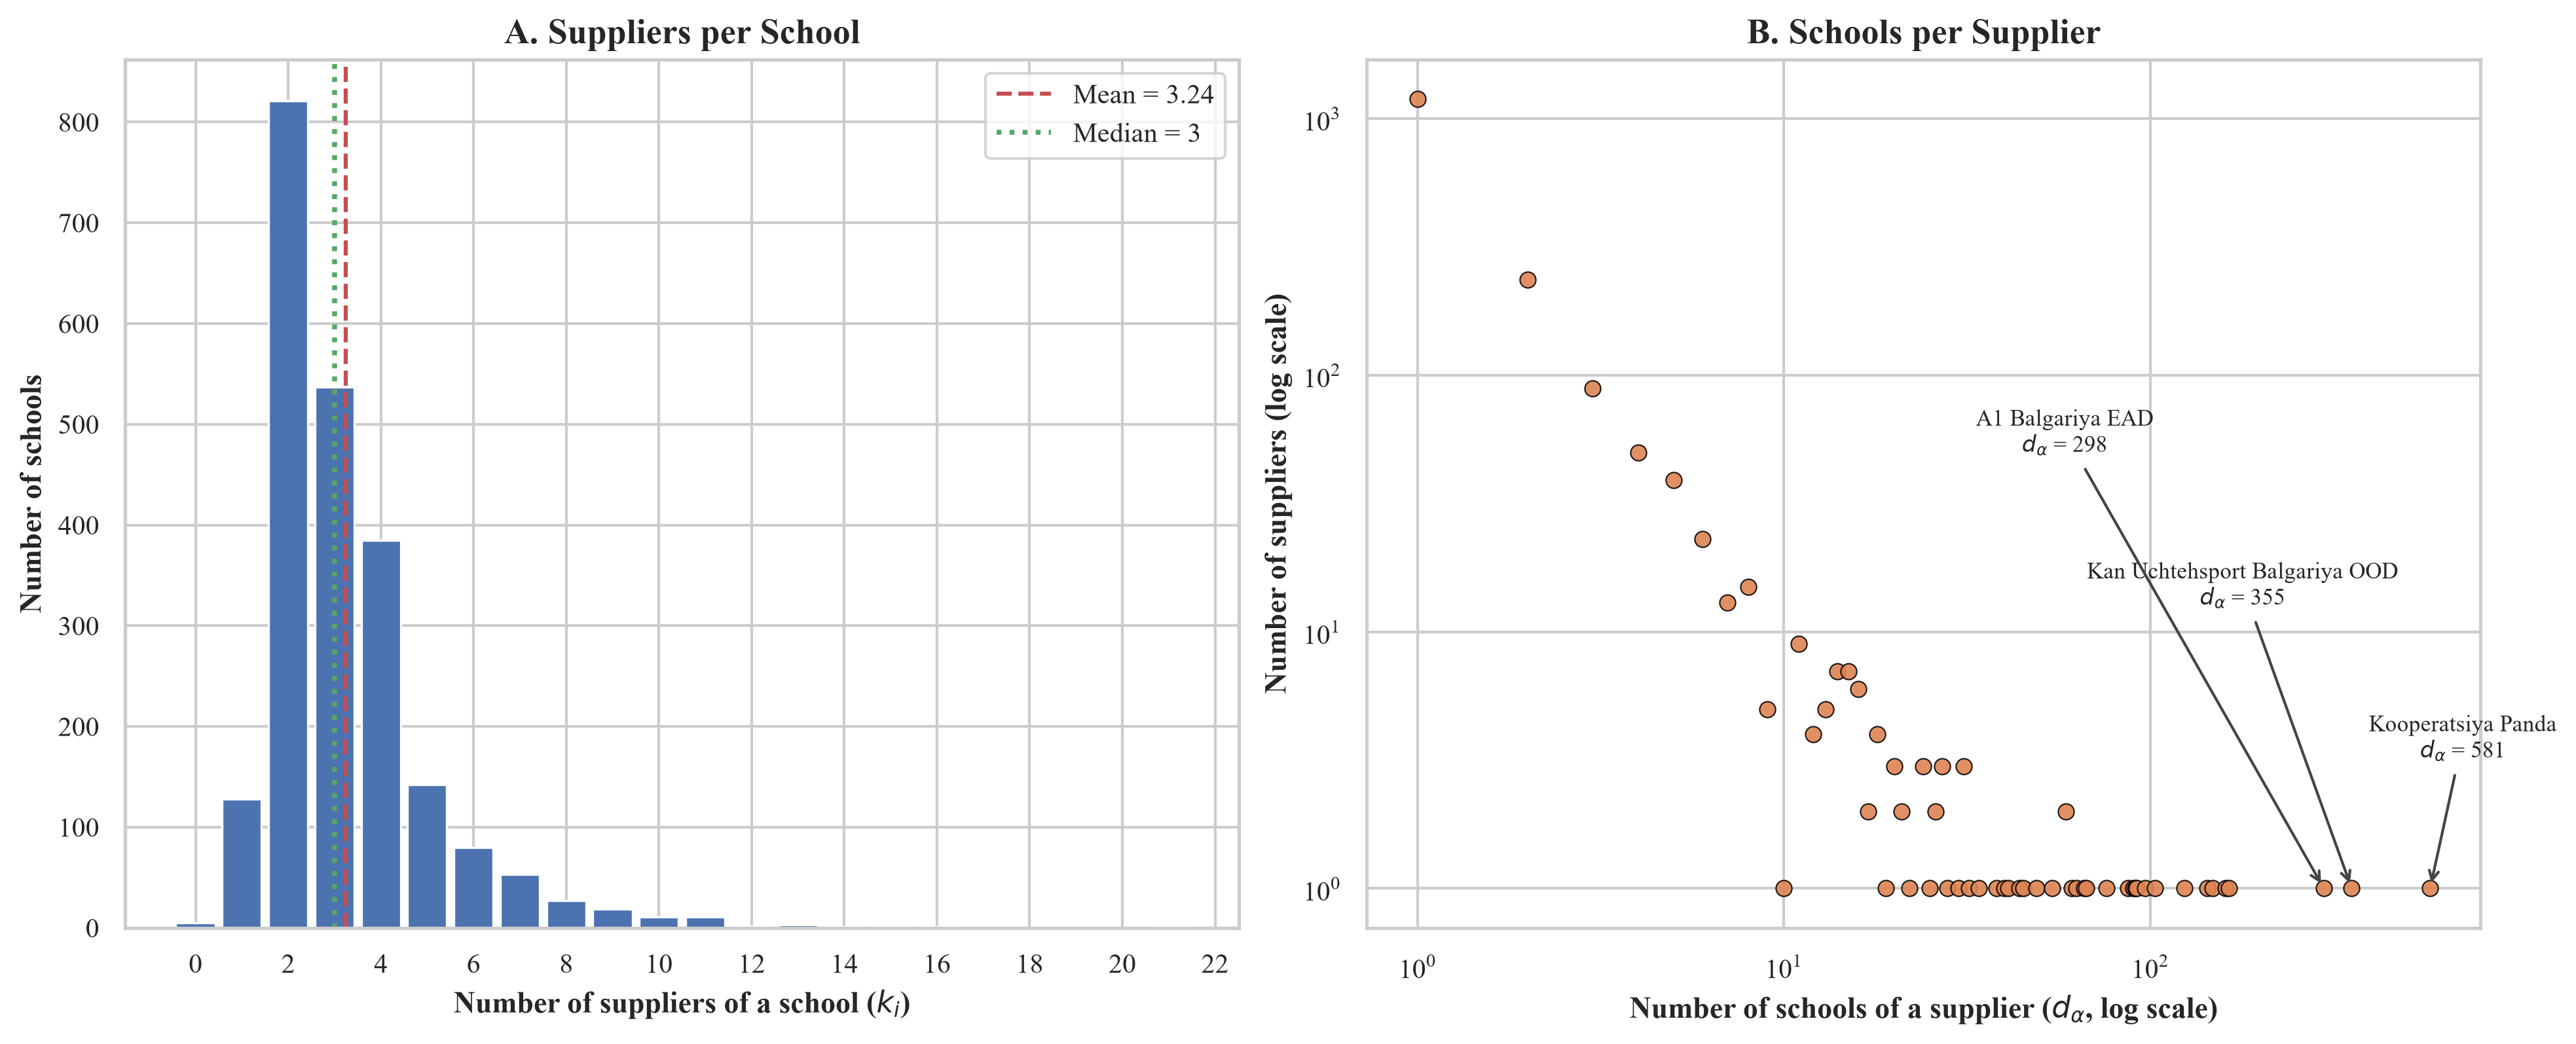

In [53]:
SCHOOL_COLOR: Final[str] = "#4c72b0"
VENDOR_COLOR: Final[str] = "#dd8452"
panda_position, a1_position, kan_position = (vendor_position(eik) for eik in ("000885099", "131468980", "128049011"))

fig_9_1, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(13, 5.2), constrained_layout=True)

school_counts = pd.Series(school_degree).value_counts().sort_index()
ax_a.bar(school_counts.index, school_counts.to_numpy(), color=SCHOOL_COLOR, edgecolor="white", linewidth=0.8, width=0.85)
ax_a.axvline(school_degree.mean(), color="#c44e52", linestyle="--", linewidth=1.5, label=f"Mean = {school_degree.mean():.2f}")
ax_a.axvline(np.median(school_degree), color="#55a868", linestyle=":", linewidth=1.8, label=f"Median = {np.median(school_degree):.0f}")
ax_a.set_xlabel("Number of suppliers of a school ($k_i$)")
ax_a.set_ylabel("Number of schools")
ax_a.set_title("A. Suppliers per School")
ax_a.xaxis.set_major_locator(ticker.MultipleLocator(2))
ax_a.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="#cccccc")

vendor_counts = pd.Series(vendor_degree[vendor_degree > 0]).value_counts().sort_index()
ax_b.scatter(vendor_counts.index, vendor_counts.to_numpy(), color=VENDOR_COLOR, edgecolor="black", linewidth=0.5, s=34, alpha=0.9)
ax_b.set_xscale("log")
ax_b.set_yscale("log")
ax_b.set_xlabel("Number of schools of a supplier ($d_\\alpha$, log scale)")
ax_b.set_ylabel("Number of suppliers (log scale)")
ax_b.set_title("B. Schools per Supplier")
for position, offset in ((panda_position, (12, 48)), (kan_position, (-40, 104)), (a1_position, (-95, 160))):
    ax_b.annotate(f"{vendor_table.at[position, 'label']}\n$d_\\alpha$ = {vendor_degree[position]}", xy=(vendor_degree[position], 1),
                  xytext=offset, textcoords="offset points", fontsize=8.5, ha="center",
                  arrowprops=dict(arrowstyle="->", color="#444444", linewidth=1.0))
plt.show()

**Figure 9.1.** Degree distributions of the bipartite market: number of schools by the number of their suppliers (panel A) and number of suppliers by the number of their schools (panel B, logarithmic axes).

*Source:* Calculation from ISUN 2020 (2026).

**Question.** How sparse is the matrix, and how concentrated is the market among suppliers?

**Why two panels.** Panel A shows the filled cells of $B$ with schools and suppliers ranked by degree. Panel B shows two Lorenz curves: the share of the school-supplier links and the share of the contracted value that the suppliers hold, from the smallest supplier to the largest.

**How to read.** The further a curve lies below the diagonal, the more the market is concentrated. The Gini coefficient is 0 for equal shares and approaches 1 when one supplier holds everything. The dot marks the top 1% of suppliers.

**What the figure is not.** Concentration among suppliers of equipment is expected where a few distributors serve many schools. The figure does not say that a market is uncompetitive.

The 18 suppliers with the most schools (top 1%) hold 38.8% of the school-supplier links; the 18 with the largest contracted value hold 54.2% of it. Gini: 0.703 for links, 0.882 for value.


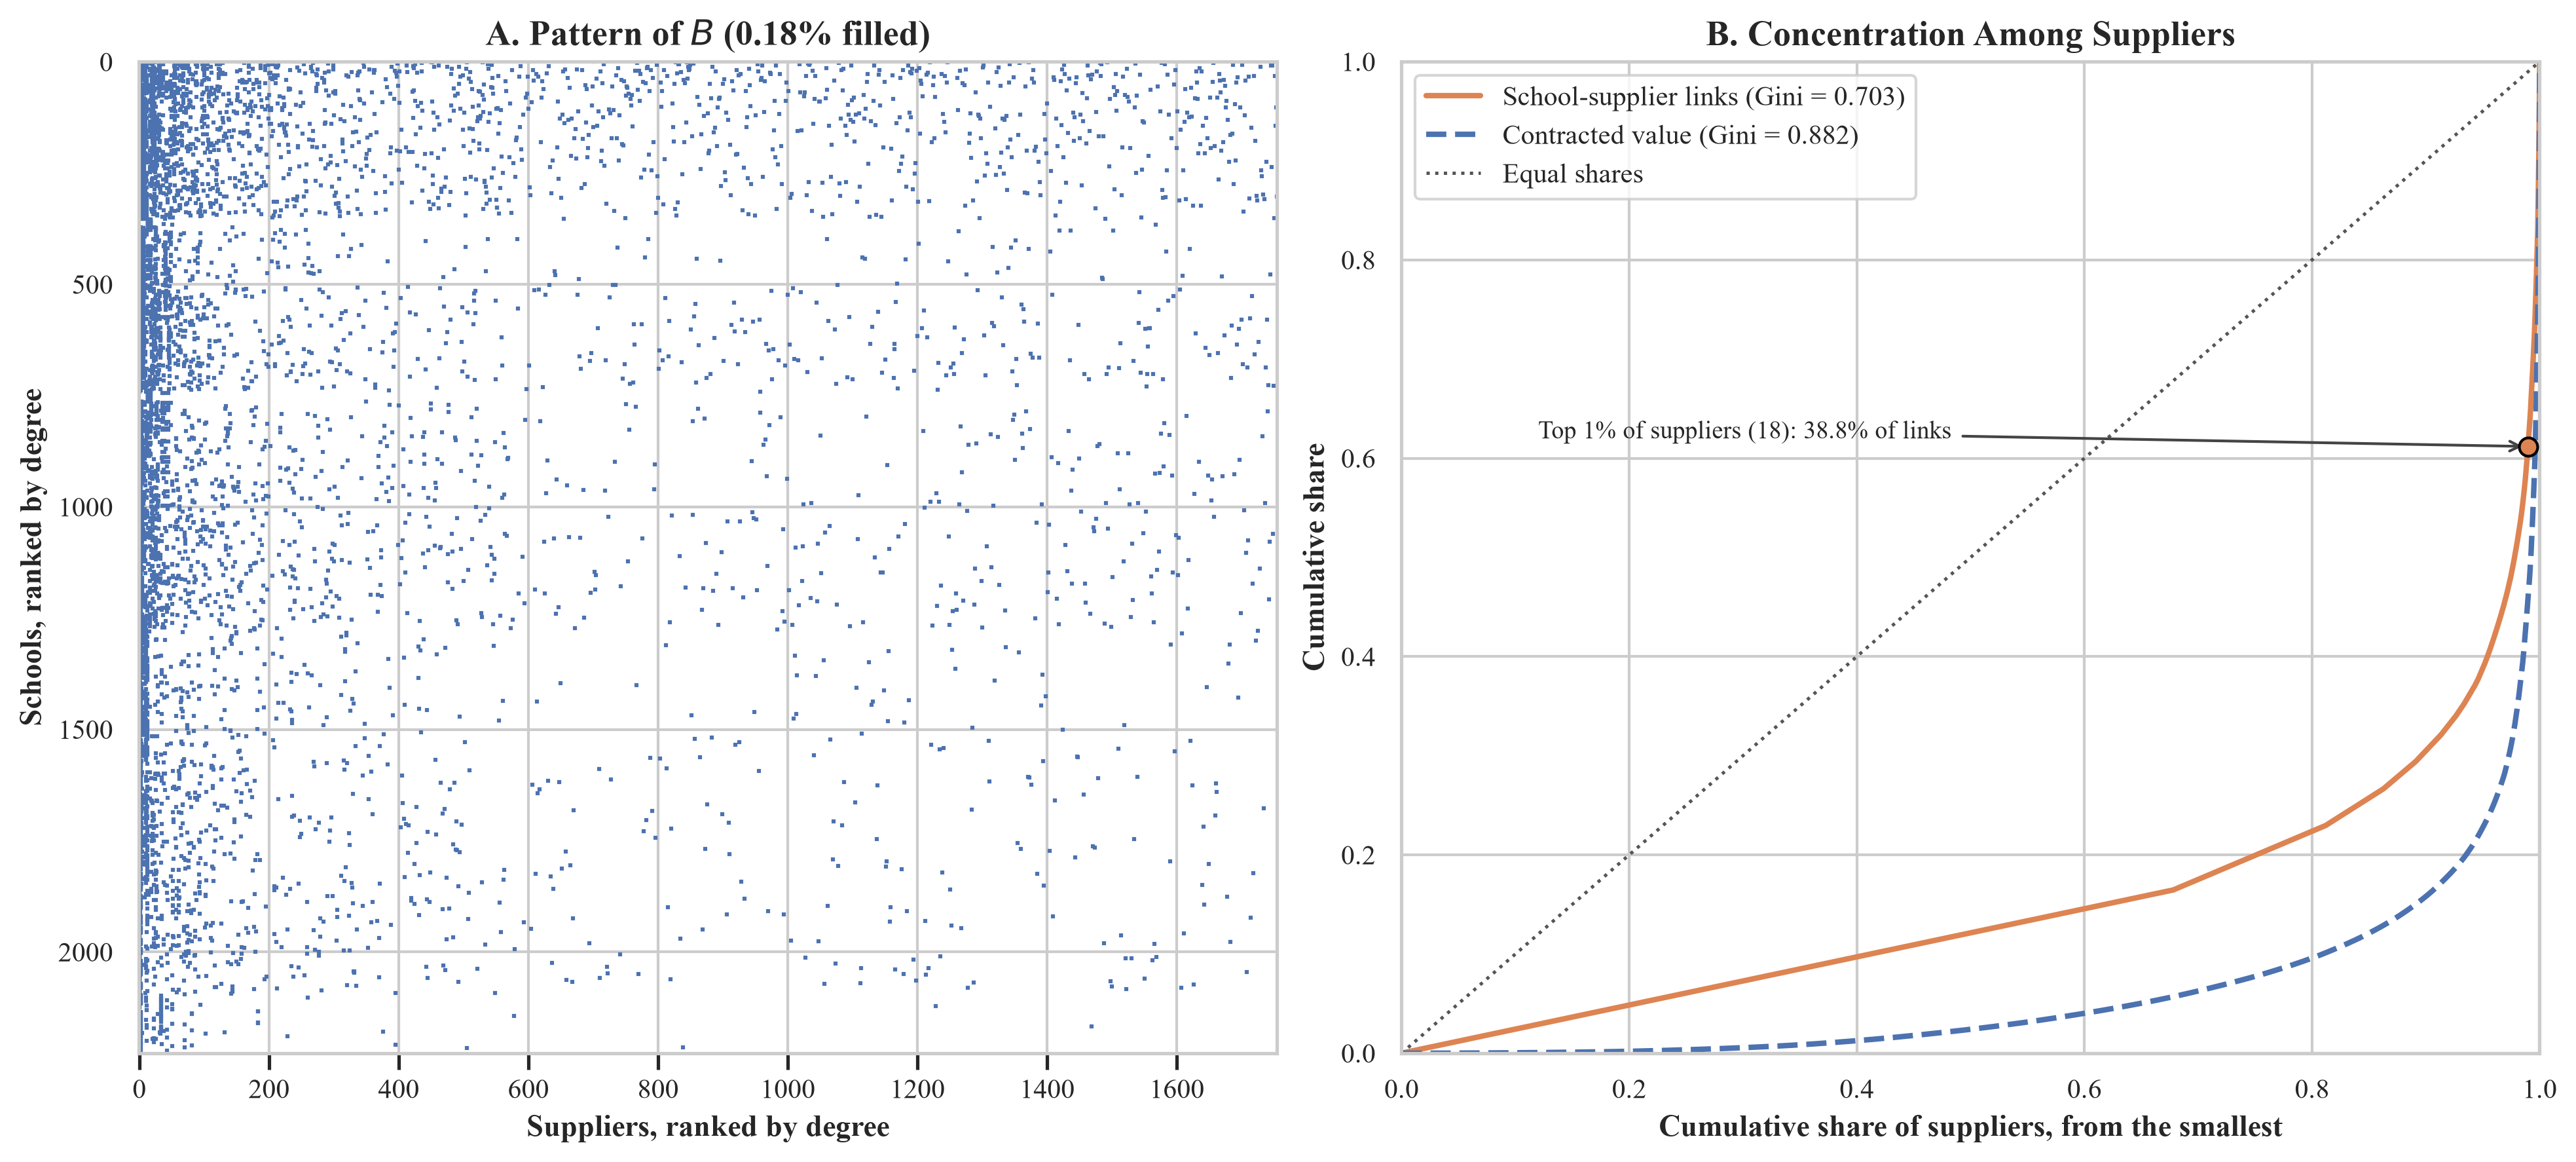

In [54]:
def gini(values: np.ndarray) -> float:
    """Gini coefficient of a non-negative vector."""
    ordered = np.sort(values)
    ranks = np.arange(1, len(ordered) + 1)
    return float(2.0 * (ranks * ordered).sum() / (len(ordered) * ordered.sum()) - (len(ordered) + 1) / len(ordered))


vendor_value = np.asarray(W.sum(axis=0)).ravel()
top_vendors = int(np.ceil(0.01 * N_V))
top_share_links = np.sort(vendor_degree)[::-1][:top_vendors].sum() / vendor_degree.sum()
top_share_value = np.sort(vendor_value)[::-1][:top_vendors].sum() / vendor_value.sum()
print(f"The {top_vendors} suppliers with the most schools (top 1%) hold {top_share_links:.1%} of the school-supplier links; "
      f"the {top_vendors} with the largest contracted value hold {top_share_value:.1%} of it. Gini: {gini(vendor_degree.astype(float)):.3f} for links, "
      f"{gini(vendor_value):.3f} for value.")

fig_9_2, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(13, 5.8), constrained_layout=True)

school_order = np.argsort(-school_degree, kind="stable")
vendor_order = np.argsort(-vendor_degree, kind="stable")
ax_a.spy(B[school_order][:, vendor_order], markersize=0.5, color=SCHOOL_COLOR, aspect="auto", origin="upper")
ax_a.set_xlabel("Suppliers, ranked by degree")
ax_a.set_ylabel("Schools, ranked by degree")
ax_a.set_title(f"A. Pattern of $B$ ({B.nnz / (N_U * N_V):.2%} filled)")
ax_a.xaxis.set_label_position("bottom")
ax_a.xaxis.tick_bottom()

for values, color, style, label in (
    (vendor_degree.astype(float), VENDOR_COLOR, "-", f"School-supplier links (Gini = {gini(vendor_degree.astype(float)):.3f})"),
    (vendor_value, SCHOOL_COLOR, "--", f"Contracted value (Gini = {gini(vendor_value):.3f})"),
):
    ordered = np.sort(values)
    ax_b.plot(np.linspace(0, 1, N_V + 1), np.concatenate([[0.0], np.cumsum(ordered) / ordered.sum()]), color=color, linestyle=style, linewidth=2.0, label=label)
ax_b.plot([0, 1], [0, 1], color="#555555", linestyle=":", linewidth=1.2, label="Equal shares")
ax_b.scatter([1 - top_vendors / N_V], [1 - top_share_links], color=VENDOR_COLOR, edgecolor="black", s=45, zorder=5)
ax_b.annotate(f"Top 1% of suppliers ({top_vendors}): {top_share_links:.1%} of links", xy=(1 - top_vendors / N_V, 1 - top_share_links),
              xytext=(0.12, 0.62), fontsize=9, arrowprops=dict(arrowstyle="->", color="#444444", linewidth=1.0))
ax_b.set_xlabel("Cumulative share of suppliers, from the smallest")
ax_b.set_ylabel("Cumulative share")
ax_b.set_title("B. Concentration Among Suppliers")
ax_b.legend(loc="upper left", frameon=True, facecolor="white", edgecolor="#cccccc")
ax_b.set_xlim(0, 1)
ax_b.set_ylim(0, 1)
plt.show()

**Figure 9.2.** Sparsity pattern of the matrix $B$ with rows and columns ranked by degree (panel A) and Lorenz curves of the school-supplier links and of the contracted value among suppliers (panel B).

*Source:* Calculation from ISUN 2020 (2026).

**Question.** For which pairs of a consultant and a supplier is the precedence higher than the permutation null allows?

**How to read.** Each point is a pair. The horizontal axis is the number of schools that contracted both, the vertical axis is the lift on a logarithmic scale, and the dashed line is a lift of 1. The colour shows the $p$-value of the permutation test. Only pairs with at least one school where the consultant signed first can be shown on a logarithmic axis.

**What the figure is not.** A small $p$-value is not a finding of a violation. No pair keeps its significance after the adjustment for the 701 tests, and the lift of pairs with few schools is unstable.

319 of the 701 pairs have at least one preceded school and appear on the logarithmic axis; 27 of them share at least 10 schools.


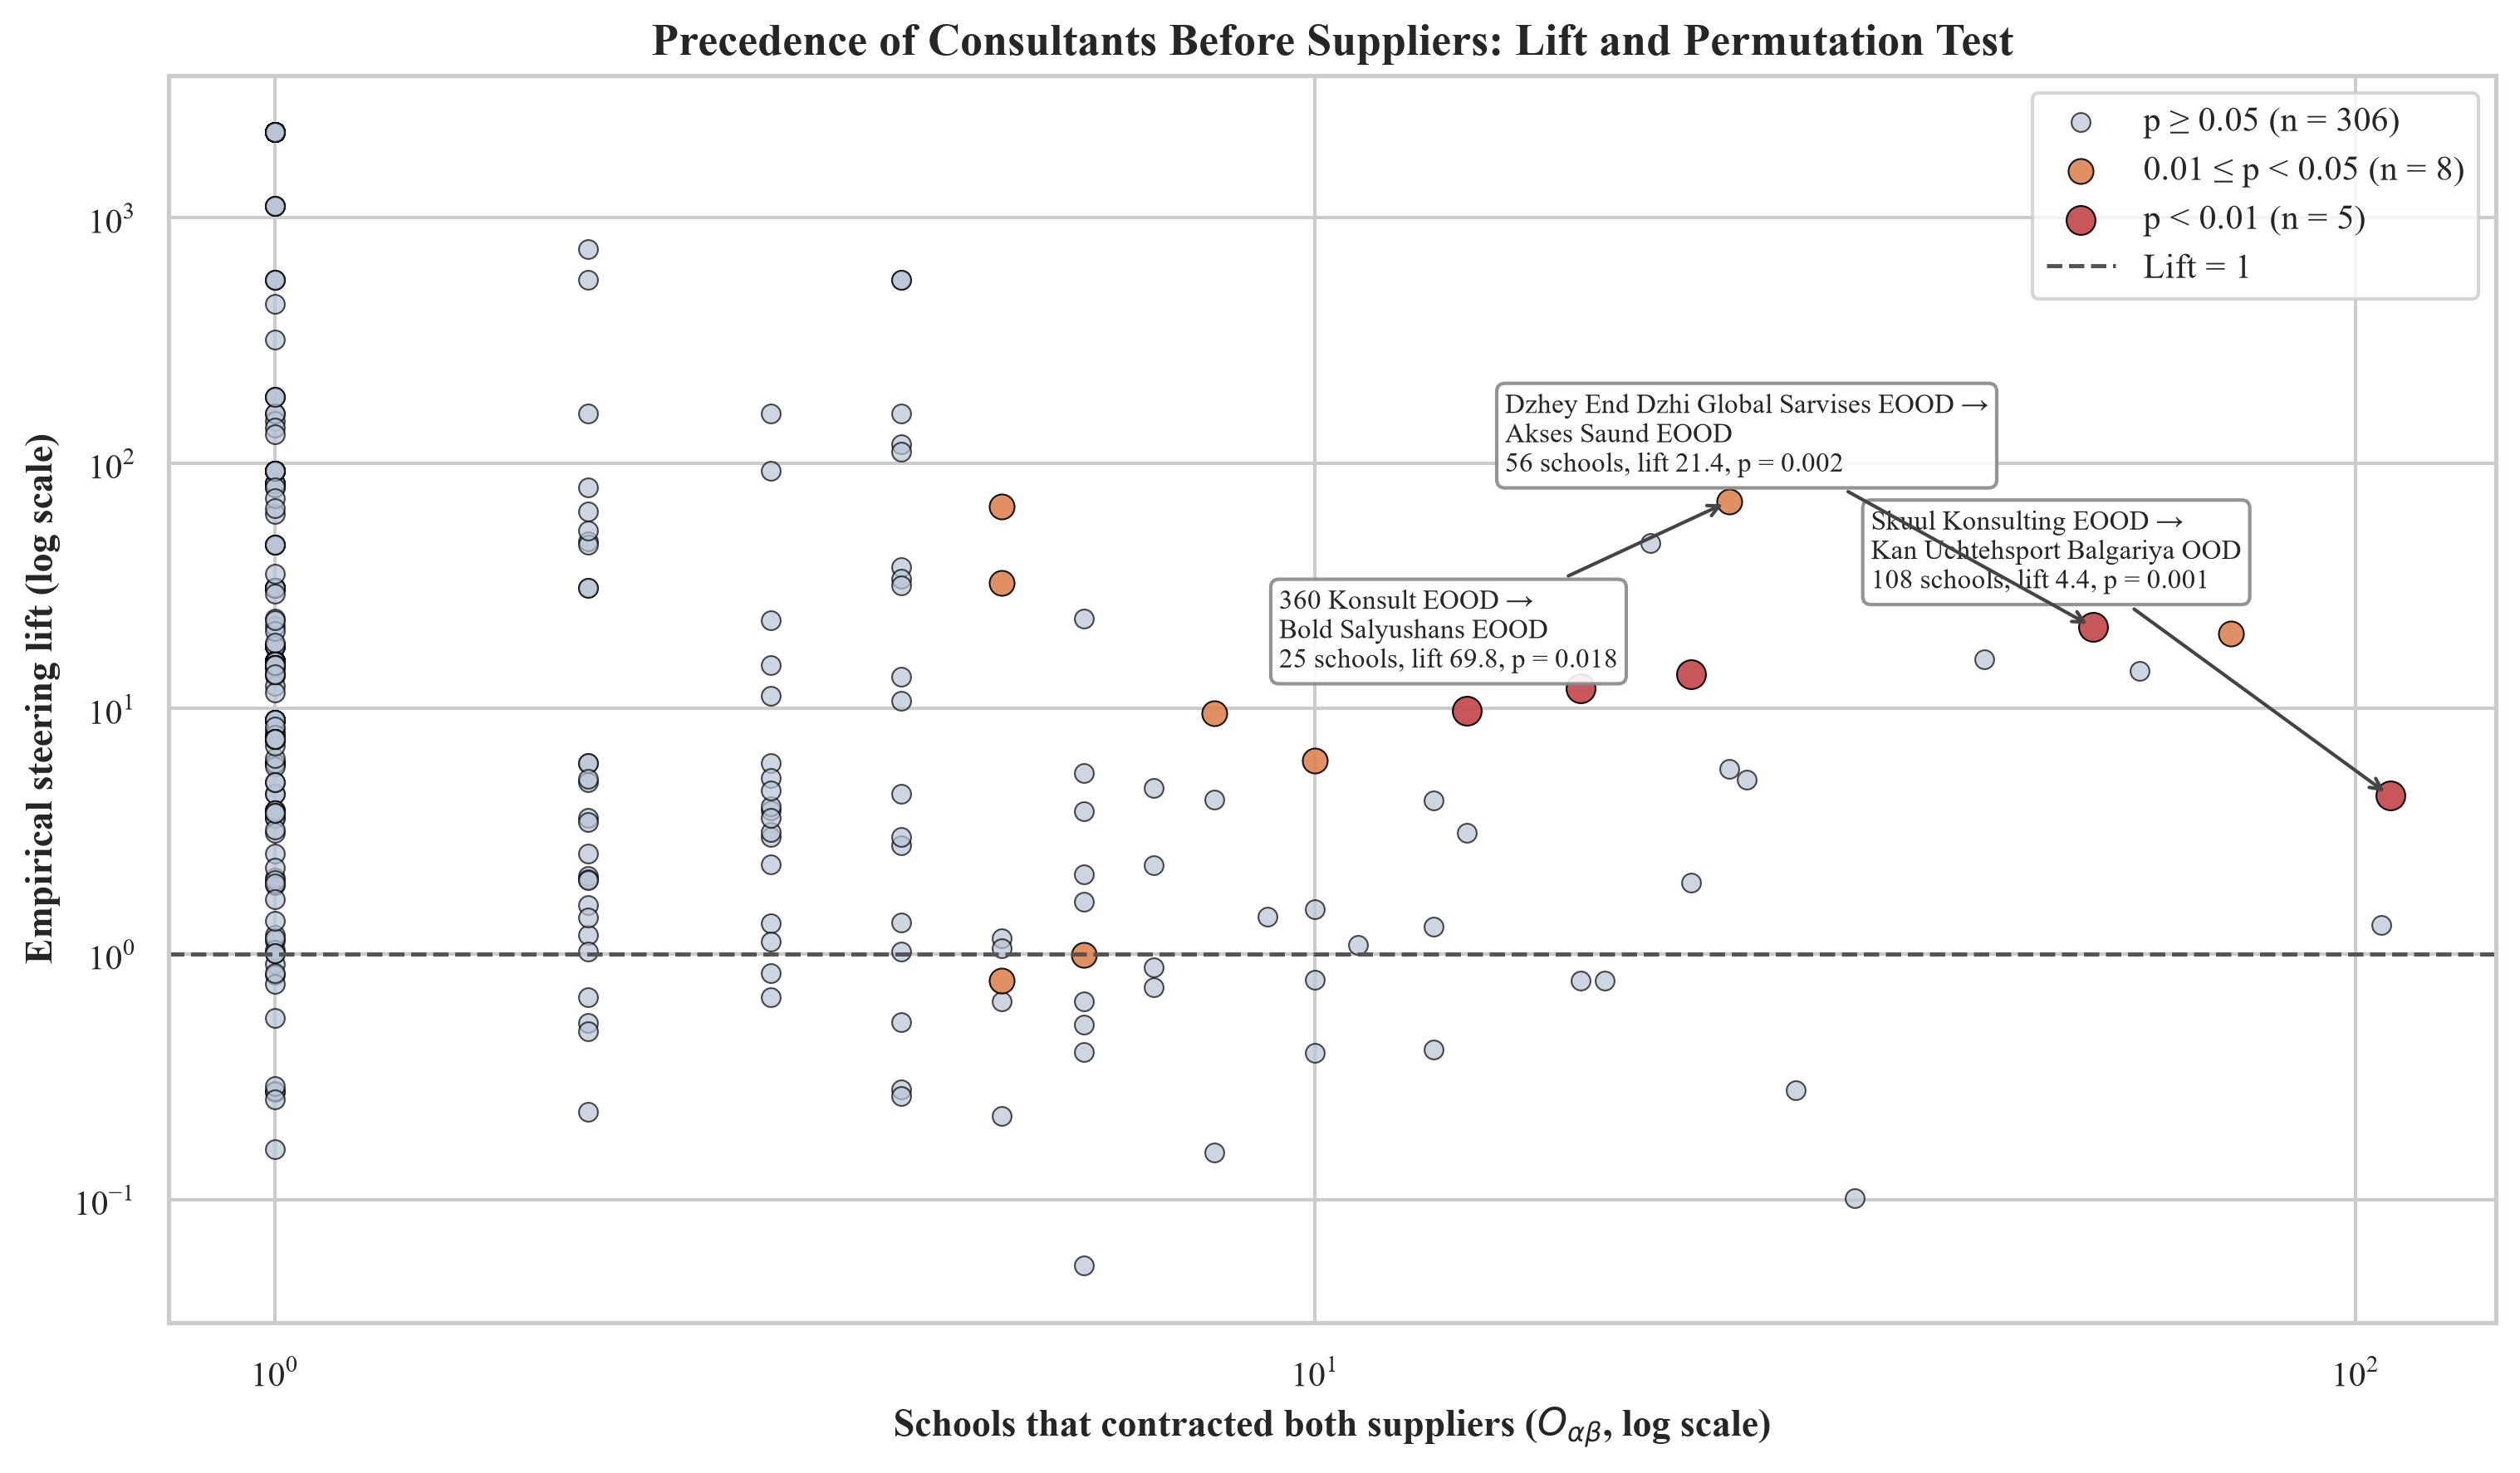

In [55]:
drawn = steering[steering["precedence_count"] > 0]
print(f"{len(drawn)} of the {n_pairs} pairs have at least one preceded school and appear on the logarithmic axis; "
      f"{int((drawn['shared_schools'] >= 10).sum())} of them share at least 10 schools.")

fig_9_3, ax_9_3 = plt.subplots(figsize=(10, 5.8), constrained_layout=True)
tiers = (
    (drawn["p_value_null"] >= 0.05, "#b9c4d6", 30, 0.7, "p ≥ 0.05"),
    ((drawn["p_value_null"] < 0.05) & (drawn["p_value_null"] >= 0.01), "#dd8452", 52, 0.9, "0.01 ≤ p < 0.05"),
    (drawn["p_value_null"] < 0.01, "#c44e52", 70, 0.95, "p < 0.01"),
)
for mask, color, size, alpha, label in tiers:
    ax_9_3.scatter(drawn.loc[mask, "shared_schools"], drawn.loc[mask, "empirical_lift"], color=color, s=size, alpha=alpha,
                   edgecolor="black", linewidth=0.5, label=f"{label} (n = {int(mask.sum())})")
ax_9_3.axhline(1.0, color="#555555", linestyle="--", linewidth=1.2, label="Lift = 1")
ax_9_3.set_xscale("log")
ax_9_3.set_yscale("log")
ax_9_3.set_xlabel("Schools that contracted both suppliers ($O_{\\alpha\\beta}$, log scale)")
ax_9_3.set_ylabel("Empirical steering lift (log scale)")
ax_9_3.set_title("Precedence of Consultants Before Suppliers: Lift and Permutation Test")

for (consultant_eik, supplier_eik), offset in ((("207788103", "128049011"), (-150, 60)), (("203902794", "206368790"), (-170, 45)), (("202214115", "207816289"), (-130, -48))):
    row = steering[(steering["consultant_eik"] == consultant_eik) & (steering["vendor_eik"] == supplier_eik)]
    assert len(row) == 1, "A pair named in the figure is not in the steering table"
    row = row.iloc[0]
    ax_9_3.annotate(f"{transliterate(row['consultant_name'])} →\n{transliterate(row['vendor_name'])}\n{row['shared_schools']} schools, lift {row['empirical_lift']:.1f}, p = {row['p_value_null']:.3f}",
                    xy=(row["shared_schools"], row["empirical_lift"]), xytext=offset, textcoords="offset points", fontsize=8,
                    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="#888888", alpha=0.9),
                    arrowprops=dict(arrowstyle="->", color="#444444", linewidth=1.0))
ax_9_3.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="#cccccc")
plt.show()

**Figure 9.3.** Empirical steering lift against the number of shared schools for pairs of a consultant and a supplier, coloured by the $p$-value of the within-school permutation test with 1,000 permutations.

*Source:* Calculation from ISUN 2020 (2026).

**Question.** Do the neighbours of a large supplier link to each other, as the neighbours of a regional group do?

**Why two panels.** Panel A shows the largest supplier and the 12 suppliers with which it shares most schools; panel B shows the regional group of three suppliers and a fourth supplier of furnishing.

**How to read.** The width of a link is the number of shared schools, and the number is written at a link in panel B and in brackets at a node in panel A. The colour of a node is the role of the supplier of Section 7.8.

**What the figure is not.** Panel A shows only 12 of the neighbours of the largest supplier, so that the lines among them are a small part of its neighbourhood. The figure shows overlap of schools and does not show an agreement.

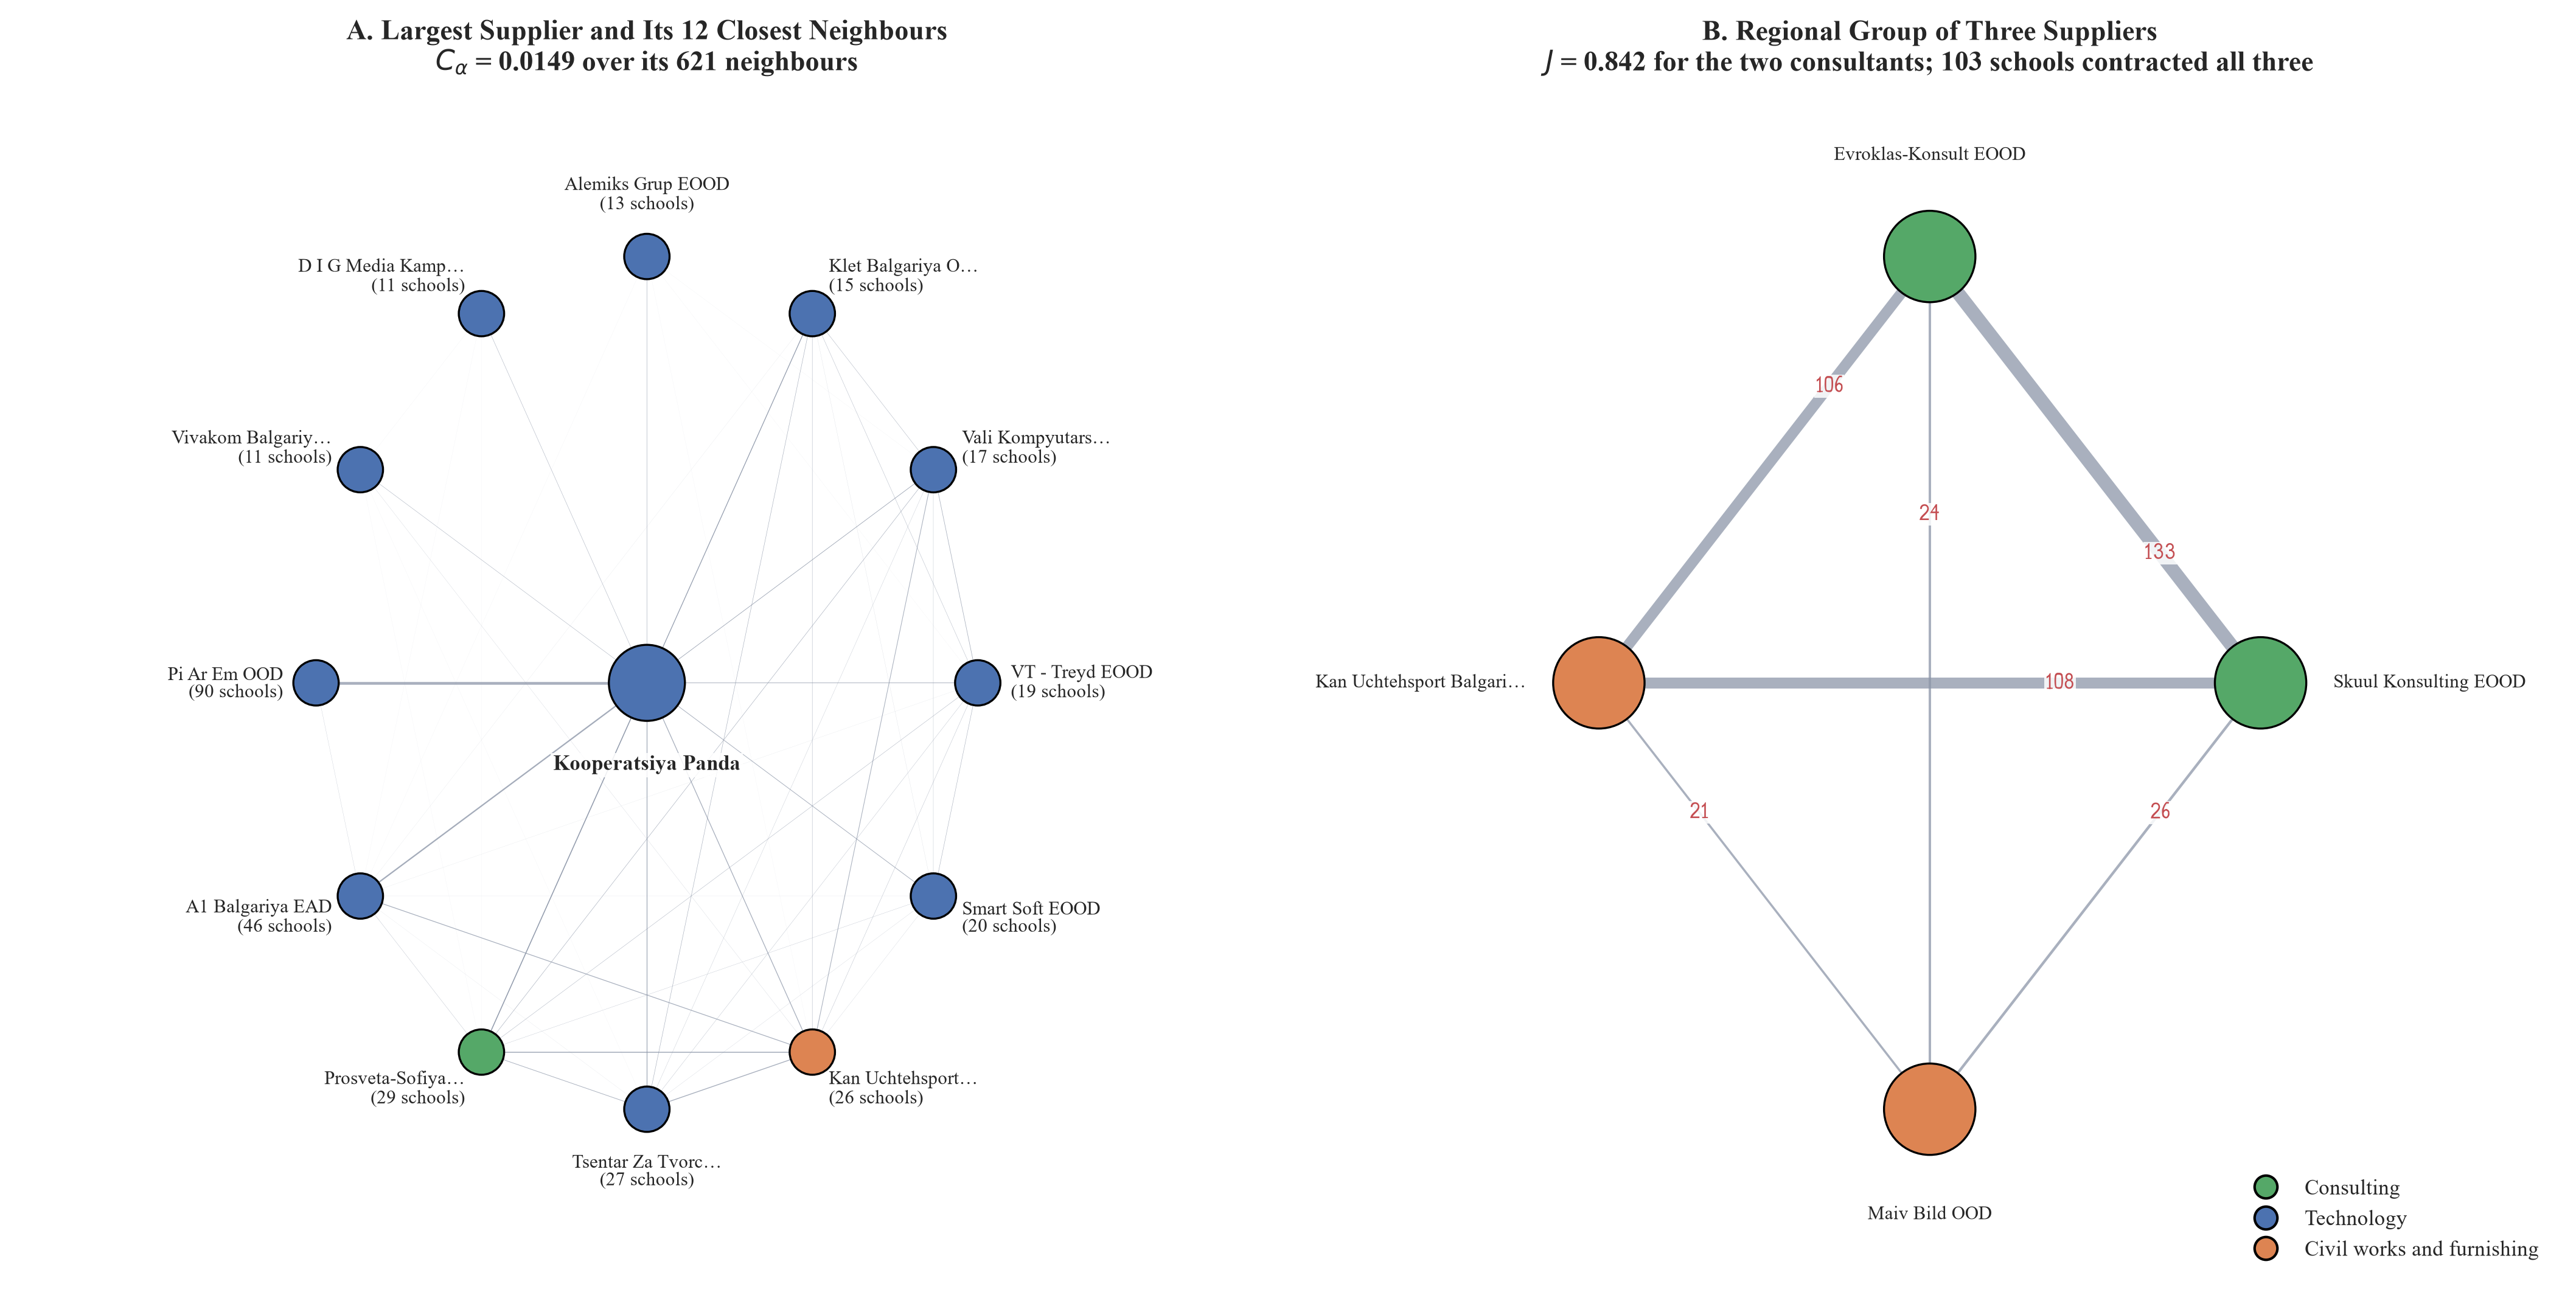

In [56]:
ROLE_COLORS: Final[dict[str, str]] = {"V_cons": "#55a868", "V_tech": "#4c72b0", "V_civil": "#dd8452"}
ROLE_NAMES: Final[dict[str, str]] = {"V_cons": "Consulting", "V_tech": "Technology", "V_civil": "Civil works and furnishing"}
EGO_NEIGHBOURS: Final[int] = 12


def short_label(position: int, width: int = 24) -> str:
    """Latin label of a supplier, shortened for a node."""
    label = vendor_table.at[position, "label"]
    return label if len(label) <= width else label[: width - 1].rstrip() + "…"


def draw_network(ax: plt.Axes, graph: nx.Graph, positions: dict[int, np.ndarray], node_size: dict[int, float], title: str, edge_scale: float, label_radius: float) -> None:
    """Draw suppliers as nodes coloured by role, with a link width proportional to the shared schools and the label outside the ring."""
    outer_radius = max(float(np.hypot(*position)) for position in positions.values())
    positions = {node: np.asarray(position) / outer_radius for node, position in positions.items()}  # the ring has radius 1
    nx.draw_networkx_edges(graph, positions, ax=ax, width=[edge_scale * graph[u][v]["shared"] for u, v in graph.edges()],
                           edge_color="#8c96a8", alpha=0.75)
    nx.draw_networkx_nodes(graph, positions, ax=ax, node_color=[ROLE_COLORS[vendor_table.at[n, "vendor_role"]] for n in graph.nodes()],
                           node_size=[node_size[n] for n in graph.nodes()], edgecolors="black", linewidths=0.8)
    for node, (x, y) in positions.items():
        if np.hypot(x, y) < 0.1:  # the centre of a star
            ax.text(x, y - 0.17, graph.nodes[node]["text"], ha="center", va="top", fontsize=8.5, fontweight="bold", bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.0))
            continue
        ax.text(label_radius * x, label_radius * y, graph.nodes[node]["text"], fontsize=7.5, linespacing=1.1,
                ha="left" if x > 0.15 else "right" if x < -0.15 else "center",
                va="bottom" if y > 0.9 else "top" if y < -0.9 else "center")
    ax.set_title(title, fontsize=11)
    ax.set_xlim(-1.9, 1.9)
    ax.set_ylim(-1.4, 1.4)
    ax.set_axis_off()


fig_9_4, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)

# Panel A: the suppliers that share most schools with the largest supplier
neighbours = [int(n) for n in np.argsort(-O[panda_position].toarray().ravel(), kind="stable") if n != panda_position][:EGO_NEIGHBOURS]
ego = nx.Graph()
ego.add_node(panda_position, text=short_label(panda_position))
for neighbour in neighbours:
    ego.add_node(neighbour, text=f"{short_label(neighbour, 17)}\n({int(O[panda_position, neighbour])} schools)")
    ego.add_edge(panda_position, neighbour, shared=int(O[panda_position, neighbour]))
for index, first in enumerate(neighbours):
    for second in neighbours[index + 1:]:
        if O[first, second] > 0:
            ego.add_edge(first, second, shared=int(O[first, second]))
draw_network(ax_a, ego, nx.shell_layout(ego, nlist=[[panda_position], neighbours]), {n: 900 if n == panda_position else 320 for n in ego.nodes()},
             f"A. Largest Supplier and Its {EGO_NEIGHBOURS} Closest Neighbours\n"
             f"$C_\\alpha$ = {clustering[panda_position]:.4f} over its {int(projected_degree[panda_position])} neighbours", 0.012, 1.1)

# Panel B: the regional group of three suppliers and a fourth supplier of the same schools
fourth_position = vendor_position("204968092")
group = nx.Graph()
members = [group_a, group_b, group_c, fourth_position]
for member in members:
    group.add_node(member, text=short_label(member, 24))
for index, first in enumerate(members):
    for second in members[index + 1:]:
        if O[first, second] > 0:
            group.add_edge(first, second, shared=int(O[first, second]))
group_layout = nx.circular_layout(group)
draw_network(ax_b, group, group_layout, {n: 1300 for n in group.nodes()},
             f"B. Regional Group of Three Suppliers\n$J$ = {J[group_a, group_b]:.3f} for the two consultants; "
             f"{three_way} schools contracted all three", 0.04, 1.22)
nx.draw_networkx_edge_labels(group, group_layout, ax=ax_b, edge_labels={(u, v): str(group[u][v]["shared"]) for u, v in group.edges()},
                             label_pos=0.3, font_size=8.5, font_color="#c44e52", rotate=False,
                             bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=0.4))
ax_b.legend(handles=[plt.Line2D([], [], marker="o", linestyle="", markerfacecolor=ROLE_COLORS[role], markeredgecolor="black", markersize=9,
                                label=ROLE_NAMES[role]) for role in ROLE_COLORS], loc="lower right", ncol=1, frameon=False, fontsize=8.5)
plt.show()

**Figure 9.4.** Neighbourhood of the supplier with the most schools (panel A) and regional group of three suppliers with a fourth supplier of the same schools (panel B), with links weighted by the number of shared schools.

*Source:* Calculation from ISUN 2020 (2026).

**Question.** Which of the leading suppliers work in the same schools?

**How to read.** The cell is the Jaccard similarity of the two suppliers: the share of the schools of either supplier that both served. It is 1 on the diagonal and 0 where the two never share a school.

**What the figure is not.** Twelve suppliers are a selection. The leading national suppliers share few schools with each other because each serves schools all over the country, and a high value shows an overlap and does not show an agreement.

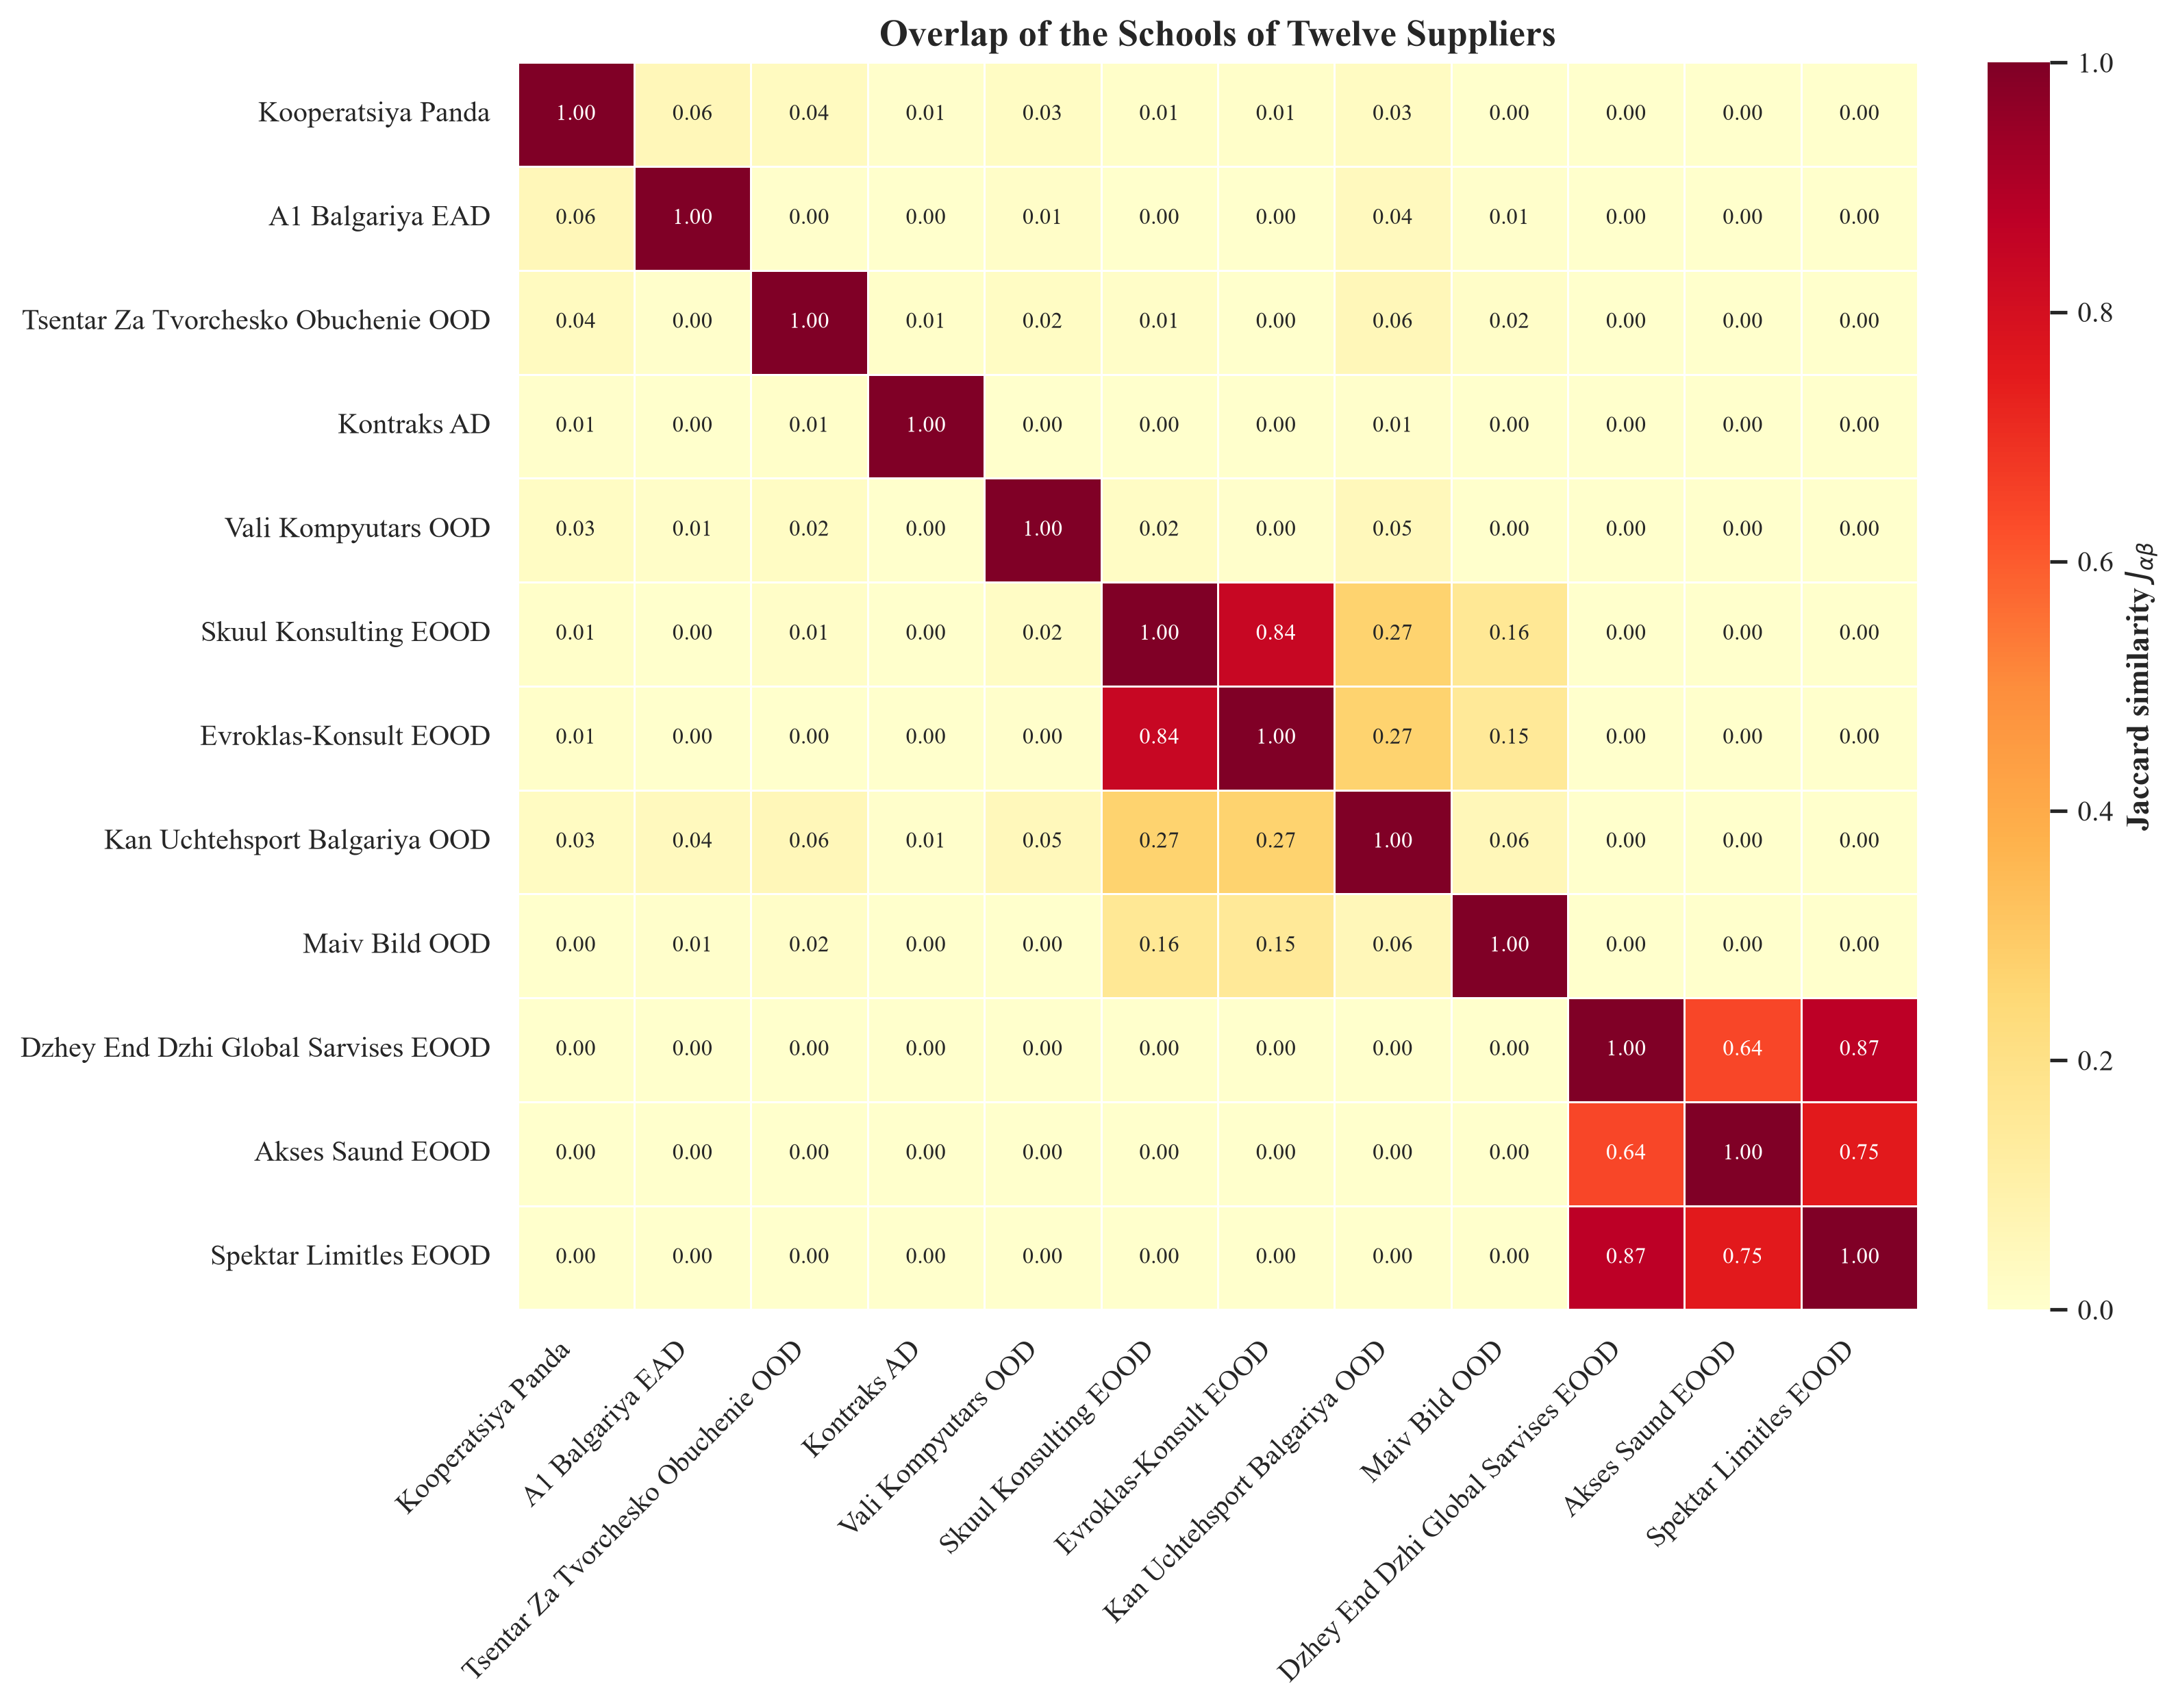

In [57]:
HEATMAP_EIKS: Final[tuple[str, ...]] = (
    "000885099", "131468980", "175342714", "175415627", "104518906", "207788103",
    "202395053", "128049011", "204968092", "203902794", "206368790", "205631733",
)
heatmap_positions = [vendor_position(eik) for eik in HEATMAP_EIKS]
heatmap_labels = [vendor_table.at[position, "label"] for position in heatmap_positions]
similarity = J[heatmap_positions][:, heatmap_positions].toarray()

fig_9_5, ax_9_5 = plt.subplots(figsize=(10.5, 8.2), constrained_layout=True)
sns.heatmap(similarity, xticklabels=heatmap_labels, yticklabels=heatmap_labels, cmap="YlOrRd", vmin=0.0, vmax=1.0, annot=True, fmt=".2f",
            annot_kws={"fontsize": 8}, linewidths=0.6, linecolor="white", cbar_kws={"label": "Jaccard similarity $J_{\\alpha\\beta}$"}, ax=ax_9_5)
ax_9_5.set_title("Overlap of the Schools of Twelve Suppliers")
ax_9_5.tick_params(axis="x", labelrotation=45)
plt.setp(ax_9_5.get_xticklabels(), ha="right")
ax_9_5.tick_params(axis="y", labelrotation=0)
plt.show()

**Figure 9.5.** Jaccard similarity of the sets of schools of twelve suppliers: the largest national suppliers, the regional group of Figure 9.4 and further consulting and technology suppliers.

*Source:* Calculation from ISUN 2020 (2026).

### 9.8 Privacy and Summary of the Checks

The cell below checks the steering table for personal data and repeats the main invariants of the section. It fails if one of them is violated.

In [58]:
steering_table = read_work_csv(OUT_STEERING)
assert not FORBIDDEN_HEADERS.intersection(steering_table.columns), f"{OUT_STEERING} contains a personal data column"
for column in steering_table.columns:
    assert not steering_table[column].str.fullmatch(r"\d{10}").any(), f"{OUT_STEERING}: column {column!r} holds a ten-digit number"
assert not steering_table[["consultant_name", "vendor_name"]].stack().str.contains(r"(?<!\w)ЕТ(?!\w)|Адвокат").any()
assert list(steering_table.columns) == STEERING_COLUMNS and len(steering_table) == n_pairs
print(f"Privacy check passed for {OUT_STEERING.as_posix()}: no personal data columns, no ten-digit numbers, no sole trader names.")

assert B.shape == (2228, 1755) and W.shape == (2228, 1755) and O.shape == (1755, 1755)
assert np.array_equal(O.diagonal(), vendor_degree) and (O != O.T).nnz == 0
print("Matrices: B and W are 2,228 by 1,755 and O is 1,755 by 1,755; the diagonal of O is the supplier degrees and O is symmetric.")

assert B.nnz == 7229 and int(O.nnz) == 17853
assert abs(float(W.sum()) - float(matrix_contracts["amount_eur_excl_vat"].sum())) < 1e-6
print("Counts: 7,229 school-supplier pairs and 17,853 non-zero entries of O; W holds the whole contracted value.")

assert ModelConfig.N_STRATIFIED_PERMUTATIONS == 1000 and steering["p_value_null"].min() >= 1 / 1001
assert np.allclose(clustering, networkx_clustering) and three_way == 103
print("Steering and clustering: 1,000 permutations (smallest p-value 1/1,001); the clustering coefficients agree with networkx; "
      "103 schools contracted all three suppliers of the regional group.")

Privacy check passed for data/derived/consultant_steering.csv: no personal data columns, no ten-digit numbers, no sole trader names.
Matrices: B and W are 2,228 by 1,755 and O is 1,755 by 1,755; the diagonal of O is the supplier degrees and O is symmetric.
Counts: 7,229 school-supplier pairs and 17,853 non-zero entries of O; W holds the whole contracted value.
Steering and clustering: 1,000 permutations (smallest p-value 1/1,001); the clustering coefficients agree with networkx; 103 schools contracted all three suppliers of the regional group.


## 10. Statistical Backbones of the Supplier Network: SVN, BiCM and Noise-Corrected Filters

The projection of Section 9 links two suppliers whenever they share a school, and it links 8,049 pairs of the 1,539,135 possible. Most of these links are expected: a supplier with hundreds of schools meets many others by chance. This section asks which links are more frequent than chance allows when the chance is defined in a stated way, and it compares six rules for keeping a link (Tumminello et al., 2011; Saracco et al., 2017; Coscia and Neffke, 2017).

**The six rules.**

| Rule | Keeps a link if | Takes into account |
| :--- | :--- | :--- |
| Naive overlap | $O_{\alpha\beta} \ge 1$ | nothing |
| Jaccard similarity | $J_{\alpha\beta} \ge \tau$ | the sizes of the two supplier sets |
| Disparity filter | $\min(\alpha_{\alpha\beta}, \alpha_{\beta\alpha}) < \alpha_{\text{DF}}$ | the strength of one end at a time |
| Noise-corrected backbone | $\tilde{L}_{\alpha\beta} > \delta \sqrt{\mathbb{V}[\tilde{L}_{\alpha\beta}]}$ | the strength of both ends |
| Hypergeometric SVN | Benjamini–Hochberg on $P(X \ge O_{\alpha\beta})$ | the degrees $d_\alpha$ and $d_\beta$ |
| Bipartite configuration model (BiCM) | Benjamini–Hochberg on the Poisson-binomial tail | the degrees of all suppliers **and** of all schools |

**Hypothesis $H_1$ (degree confounding).** If the shared schools of a pair are explained by how many contracts the two suppliers and the schools have, a rule that conditions on the degrees of both sets should remove the links of the largest suppliers and keep the links that exceed what the degrees explain. The section reports what the data show, and it does not assume the answer.

**Inputs.** The section uses the matrices $B$ and $O$ of Section 9 and the supplier table of Section 7.8. It opens no source file.

**Outputs.** `data/derived/validated_edges.csv` holds one row for each of the 8,049 pairs with a shared school. `data/cache/bicm_solution.npz` holds the parameters of the BiCM and is not kept in Git.

**Neutral reading.** A link that survives a test is a statistically unusual overlap of schools. It is an indicator of risk for examination, and it is not evidence of an agreement or of a violation. Names in the figures are transliterated into Latin letters.

### 10.1 Hypergeometric Statistically Validated Network

**Null model.** For suppliers $\alpha$ and $\beta$ with degrees $d_\alpha$ and $d_\beta$, suppose that $\beta$ draws its $d_\beta$ schools at random from the $N_U$ schools without replacement and independently of $\alpha$. The number of shared schools $X$ is hypergeometric, and the $p$-value of an observed overlap is

$$p^{\text{Hyp}}_{\alpha\beta} = P(X \ge O_{\alpha\beta}) = \sum_{k = O_{\alpha\beta}}^{\min(d_\alpha, d_\beta)} \frac{\binom{d_\alpha}{k} \binom{N_U - d_\alpha}{d_\beta - k}}{\binom{N_U}{d_\beta}}.$$

The cell evaluates it with `scipy.stats.hypergeom.sf(O - 1, N_U, d_a, d_b)` (Tumminello et al., 2011). The test conditions on the supplier degrees only, and it treats all schools as equally likely to be chosen.

**Multiple tests.** Every pair of suppliers is a hypothesis, so the family has $M = \binom{N_V}{2} = 1\,539\,135$ tests. A pair without a shared school has $p = 1$ and ranks behind all other pairs, which means that the rules only need the $p$-values of the 8,049 pairs with $O > 0$.

- *Benjamini–Hochberg.* With the ordered $p$-values $p_{(1)} \le \dots \le p_{(M)}$, keep the pairs up to the largest $k^*$ with $p_{(k^*)} \le k^* \alpha / M$, at $\alpha = 0.01$. A pair is kept if and only if its adjusted value $q_{(j)} = \min_{k \ge j} \, p_{(k)} M / k$ is at most $\alpha$.
- *Bonferroni.* Keep the pairs with $p \le \alpha / M \approx 6.5 \times 10^{-9}$.

The empty rows: the five projects without a contract are included in $N_U = 2\,228$, as in the design. The cell of Section 10.5 repeats the test with $N_U = 2\,223$.

In [59]:
import time

from scipy import stats

N_TESTS: Final[int] = N_V * (N_V - 1) // 2  # every pair of suppliers is a hypothesis, also the pairs without a shared school
ALPHA: Final[float] = ModelConfig.ALPHA_FDR
OUT_EDGES: Final[Path] = PathConfig.DERIVED_DIR / "validated_edges.csv"
OUT_BICM: Final[Path] = PathConfig.CACHE_DIR / "bicm_solution.npz"
assert N_TESTS == 1_539_135


class MultipleTestingCorrector:
    """Benjamini-Hochberg and Bonferroni control over all pairs of suppliers.

    The family has M = N_V (N_V - 1) / 2 tests. A pair without a shared school has p = 1, so that it ranks behind every
    pair with a shared school and the procedures only need the p-values of the pairs with O > 0
    (Benjamini and Hochberg, 1995; Tumminello et al., 2011).
    """

    def __init__(self, n_tests: int, alpha: float) -> None:
        self.n_tests = n_tests
        self.alpha = alpha

    def adjusted(self, p_values: np.ndarray) -> np.ndarray:
        """Benjamini-Hochberg adjusted p-values (q-values) of the tested pairs; a pair is valid if its q-value is at most alpha."""
        order = np.argsort(p_values, kind="stable")
        scaled = p_values[order] * self.n_tests / np.arange(1, len(p_values) + 1)
        adjusted = np.minimum(np.minimum.accumulate(scaled[::-1])[::-1], 1.0)
        q_values = np.empty(len(p_values))
        q_values[order] = adjusted
        return q_values

    def benjamini_hochberg(self, p_values: np.ndarray) -> np.ndarray:
        """Pairs that the step-up rule p_(k) <= k alpha / M keeps."""
        return self.adjusted(p_values) <= self.alpha

    def bonferroni(self, p_values: np.ndarray) -> np.ndarray:
        """Pairs with p <= alpha / M, the conservative bound on the family-wise error."""
        return p_values <= self.alpha / self.n_tests


class HypergeometricSVN:
    """Statistically validated network under the hypergeometric null (Tumminello et al., 2011).

    Given the degrees d_a and d_b, the number of shared schools is hypergeometric with N_U schools, and the p-value of
    a pair is P(X >= O_ab). The test conditions on the degrees of the suppliers only, and takes all schools as equally
    likely partners.
    """

    def __init__(self, n_schools: int) -> None:
        self.n_schools = n_schools

    def p_values(self, overlap: np.ndarray, degree_a: np.ndarray, degree_b: np.ndarray) -> np.ndarray:
        """Survival function P(X >= O) of the hypergeometric distribution."""
        return stats.hypergeom.sf(overlap - 1, self.n_schools, degree_a, degree_b)


# the pairs of suppliers with at least one shared school, one row per pair a < b
upper = sparse.triu(O, k=1).tocoo()
pair_order = np.lexsort((upper.col, upper.row))
pair_a, pair_b = upper.row[pair_order], upper.col[pair_order]
overlap = upper.data[pair_order].astype(np.int64)
n_pairs = len(overlap)
jaccard = overlap / (vendor_degree[pair_a] + vendor_degree[pair_b] - overlap)
assert n_pairs == (O.nnz - N_V) // 2 == 8049
assert np.allclose(jaccard, np.asarray(J[pair_a, pair_b]).ravel())

panda_position, a1_position = (vendor_position(eik) for eik in ("000885099", "131468980"))
group_positions = np.array([group_a, group_b, group_c])

corrector = MultipleTestingCorrector(N_TESTS, ALPHA)
svn = HypergeometricSVN(N_U)
p_hyp = svn.p_values(overlap, vendor_degree[pair_a], vendor_degree[pair_b])
q_hyp = corrector.adjusted(p_hyp)
svn_valid = corrector.benjamini_hochberg(p_hyp)
svn_bonferroni = corrector.bonferroni(p_hyp)

# the Benjamini-Hochberg rule keeps the pairs up to the largest k with p_(k) <= k alpha / M
sorted_p = np.sort(p_hyp)
k_star = int(np.flatnonzero(sorted_p <= np.arange(1, n_pairs + 1) / N_TESTS * ALPHA).max()) + 1
assert svn_valid.sum() == k_star
# with the family of the pairs that have a shared school only, the Section 9 function gives q-values that are never smaller
assert np.all(benjamini_hochberg(p_hyp) <= q_hyp + 1e-12)

print(f"{n_pairs:,} of the {N_TESTS:,} pairs of suppliers share at least one school; the other {N_TESTS - n_pairs:,} pairs have p = 1.")
print(f"Hypergeometric SVN with N_U = {N_U:,}: {int(svn_valid.sum())} links at Benjamini-Hochberg alpha = {ALPHA} "
      f"(critical p-value {sorted_p[k_star - 1]:.2e}); Bonferroni threshold {ALPHA / N_TESTS:.3e}: {int(svn_bonferroni.sum())} links.")
print(f"Smallest p-value {p_hyp.min():.2e}; pairs with p < 0.01 before any correction: {int((p_hyp < 0.01).sum()):,}.")

8,049 of the 1,539,135 pairs of suppliers share at least one school; the other 1,531,086 pairs have p = 1.
Hypergeometric SVN with N_U = 2,228: 128 links at Benjamini-Hochberg alpha = 0.01 (critical p-value 6.27e-07); Bonferroni threshold 6.497e-09: 81 links.
Smallest p-value 3.87e-183; pairs with p < 0.01 before any correction: 3,247.


### 10.2 Disparity Filter and Noise-Corrected Backbone

Both filters use only the counts $O_{\alpha\beta}$ for $\alpha \ne \beta$. The strength of a supplier is $s_\alpha = \sum_{\beta \ne \alpha} O_{\alpha\beta}$, and its number of neighbours is $k_\alpha$. The diagonal $O_{\alpha\alpha} = d_\alpha$ is excluded.

**Disparity filter.** The weight of a link is compared with a uniform split of the strength of one end over its links,
$$\alpha_{\alpha\beta} = \left( 1 - \frac{O_{\alpha\beta}}{s_\alpha} \right)^{k_\alpha - 1},$$
and a link is kept if the smaller of $\alpha_{\alpha\beta}$ and $\alpha_{\beta\alpha}$ is below $\alpha_{\text{DF}} = 0.05$. A supplier with one link has $\alpha = 1$.

**Noise-corrected backbone.** With $N_{\alpha\cdot} = s_\alpha$ and $N_{\cdot\cdot} = \sum_\alpha s_\alpha$ the transformed lift is
$$\kappa = \frac{N_{\cdot\cdot}}{N_{\alpha\cdot} N_{\cdot\beta}}, \qquad \tilde{L}_{\alpha\beta} = \frac{\kappa N_{\alpha\beta} - 1}{\kappa N_{\alpha\beta} + 1}.$$
The variance of the lift comes from the delta method with the binomial variance $N_{\cdot\cdot} P_{\alpha\beta} (1 - P_{\alpha\beta})$ and a Beta prior for $P_{\alpha\beta}$ that matches the hypergeometric mean and variance of the margins (Coscia and Neffke, 2017):
$$\mathbb{V}[\tilde{L}_{\alpha\beta}] = \mathbb{V}[N_{\alpha\beta}] \left( \frac{2 \left( \kappa + N_{\alpha\beta} \, \frac{d\kappa}{dN_{\alpha\beta}} \right)}{(\kappa N_{\alpha\beta} + 1)^2} \right)^2, \qquad \frac{d\kappa}{dN_{\alpha\beta}} = \frac{1}{N_{\alpha\cdot} N_{\cdot\beta}} - \frac{N_{\cdot\cdot} (N_{\alpha\cdot} + N_{\cdot\beta})}{(N_{\alpha\cdot} N_{\cdot\beta})^2}.$$
A link is kept if the score $\tilde{L} / \sqrt{\mathbb{V}[\tilde{L}]}$ exceeds $\delta = 2.32$, which corresponds to $p \approx 0.01$ under the normal limit.

**Thresholds.** The values $\alpha_{\text{DF}} = 0.05$, $\delta = 2.32$ and the Jaccard threshold $\tau = 0.20$ are those of the design of the benchmark. They are choices and not results, so Section 10.5 shows how the counts change with them.

**Check.** The two classes reproduce, link by link, the dense functions that Section 6.4 tested on simulated data.

In [60]:
DF_ALPHA: Final[float] = 0.05  # thresholds of the design of the benchmark; Section 10.5 shows how the counts depend on them
NC_DELTA: Final[float] = 2.32  # corresponds to p of about 0.01 under the normal limit
JACCARD_TAU: Final[float] = 0.20

strength = np.asarray(O.sum(axis=1)).ravel() - vendor_degree  # s_a = sum over b != a of O_ab; the diagonal O_aa = d_a is excluded


class DisparityFilter:
    """Disparity filter on the co-occurrence counts, the unilateral baseline described by Coscia and Neffke (2017).

    From the side of supplier a, the weight of a link is compared with a uniform split of its strength s_a over its k_a
    links: alpha_ab = (1 - O_ab / s_a)^(k_a - 1). A link is kept if the smaller of the two values is below alpha.
    """

    def __init__(self, strength: np.ndarray, degree: np.ndarray) -> None:
        self.strength = strength
        self.degree = degree

    def p_values(self, a: np.ndarray, b: np.ndarray, weight: np.ndarray) -> np.ndarray:
        """min(alpha_ab, alpha_ba); a supplier with one link has alpha = 1."""
        sides = [np.where(self.degree[end] > 1, (1.0 - weight / self.strength[end]) ** (self.degree[end] - 1.0), 1.0) for end in (a, b)]
        return np.minimum(*sides)


class NoiseCorrectedBackbone:
    """Noise-corrected backbone on the co-occurrence counts (Coscia and Neffke, 2017).

    The transformed lift (kappa N - 1) / (kappa N + 1) is divided by its standard deviation, which the delta method
    derives from the binomial variance of N_ab with a Beta prior fitted to the hypergeometric moments of the margins.
    A link is kept if the score exceeds delta.
    """

    def __init__(self, strength: np.ndarray) -> None:
        self.strength = strength
        self.total = float(strength.sum())

    def scores(self, a: np.ndarray, b: np.ndarray, weight: np.ndarray) -> np.ndarray:
        """Standardised transformed lift of each link."""
        n_a, n_b, n_ab, n_total = self.strength[a], self.strength[b], weight.astype(np.float64), self.total
        product = n_a * n_b
        kappa = n_total / product
        lift = (kappa * n_ab - 1.0) / (kappa * n_ab + 1.0)
        d_kappa = 1.0 / product - n_total * (n_a + n_b) / product**2

        mu = product / n_total**2
        variance = product * (n_total - n_a) * (n_total - n_b) / (n_total**4 * (n_total - 1.0))
        prior_a = mu**2 / variance * (1.0 - mu) - mu
        prior_b = mu * ((1.0 - mu) ** 2 / variance + 1.0) - 1.0
        assert (prior_a > 0).all() and (prior_b > 0).all(), "The Beta prior is not defined for a link"
        posterior = (n_ab + prior_a) / (n_total + prior_a + prior_b)

        variance_n = n_total * posterior * (1.0 - posterior)
        variance_lift = variance_n * (2.0 * (kappa + n_ab * d_kappa) / (kappa * n_ab + 1.0) ** 2) ** 2
        return lift / np.sqrt(variance_lift)


p_df = DisparityFilter(strength, projected_degree).p_values(pair_a, pair_b, overlap)
df_valid = p_df < DF_ALPHA
nc_score = NoiseCorrectedBackbone(strength).scores(pair_a, pair_b, overlap)
nc_valid = nc_score > NC_DELTA
jaccard_valid = jaccard >= JACCARD_TAU

# the two filters agree with the dense functions that were checked on simulated data in Section 6
dense_counts = O.toarray().astype(np.float64)
reference_nc = noise_corrected_backbone(dense_counts, NC_DELTA)
reference_df = disparity_filter(dense_counts, DF_ALPHA)
assert np.allclose(reference_nc["score"][pair_a, pair_b], nc_score) and (reference_nc["backbone"][pair_a, pair_b] == nc_valid).all()
assert (reference_df[pair_a, pair_b] == df_valid).all()
del dense_counts, reference_nc, reference_df

print(f"Disparity filter (alpha = {DF_ALPHA}): {int(df_valid.sum())} of {n_pairs:,} links; noise-corrected backbone (delta = {NC_DELTA}): "
      f"{int(nc_valid.sum()):,} links; Jaccard similarity at least {JACCARD_TAU}: {int(jaccard_valid.sum()):,} links.")
print(f"Noise-corrected score: median {np.median(nc_score):.2f}, range {nc_score.min():.2f} to {nc_score.max():.2f}.")
print("Both implementations agree with the dense functions of Section 6 on every link.")

Disparity filter (alpha = 0.05): 198 of 8,049 links; noise-corrected backbone (delta = 2.32): 6,712 links; Jaccard similarity at least 0.2: 1,845 links.
Noise-corrected score: median 19.02, range -3.85 to 100245965.31.
Both implementations agree with the dense functions of Section 6 on every link.


### 10.3 Bipartite Configuration Model

**Model.** The BiCM is the ensemble of bipartite graphs with the maximum Shannon entropy among those that reproduce the degree of every school and every supplier in expectation. Its Hamiltonian is $\mathcal{H}(B) = \sum_i \theta_i k_i + \sum_\alpha \mu_\alpha d_\alpha$, and the links are independent with probability

$$p_{i\alpha} = \frac{x_i y_\alpha}{1 + x_i y_\alpha}, \qquad x_i = e^{-\theta_i}, \quad y_\alpha = e^{-\mu_\alpha}.$$

The parameters solve the coupled equations
$$f_i = \sum_\alpha \frac{x_i y_\alpha}{1 + x_i y_\alpha} - k_i = 0, \qquad g_\alpha = \sum_i \frac{x_i y_\alpha}{1 + x_i y_\alpha} - d_\alpha = 0.$$

**Solver.** The cell solves them by the alternating fixed-point iteration $x_i \leftarrow k_i \big/ \sum_\alpha y_\alpha / (1 + x_i y_\alpha)$ and $y_\alpha \leftarrow d_\alpha \big/ \sum_i x_i / (1 + x_i y_\alpha)$, starting from $x_i = k_i / \sqrt{L}$ and $y_\alpha = d_\alpha / \sqrt{L}$ with $L = 7\,229$ links. It stops when $\max_{i, \alpha} (|f_i|, |g_\alpha|)$ is below $10^{-10}$, which is stricter than the $10^{-4}$ of the design, and it stops with the diagnostics if this does not happen in 500 iterations.

**Empty rows.** A school with $k_i = 0$ would need $x_i = 0$. The five projects without a contract are given $x_i = 0$ and drop out, so the system has $2\,223 + 1\,755 = 3\,978$ equations and not $3\,983$.

**Invariant.** The row sums of the probability matrix equal the school degrees and the column sums equal the supplier degrees, to within $10^{-3}$.

In [61]:
from dataclasses import dataclass

BICM_TOLERANCE: Final[float] = 1e-10  # the design asks for 1e-4; the iteration is cheap, so the residual is pushed further
BICM_MAX_ITERATIONS: Final[int] = 500


@dataclass(frozen=True)
class BiCMSolution:
    """Parameters of the bipartite configuration model and the diagnostics of the iteration."""
    x: np.ndarray
    y: np.ndarray
    residual: float
    iterations: int
    converged: bool


class BiCMSolver:
    """Maximum-entropy bipartite configuration model (Saracco et al., 2017).

    The model fixes the degree of every school and every supplier in expectation, and the links are independent with
    p_ia = x_i y_a / (1 + x_i y_a). The parameters solve f_i = sum_a p_ia - k_i = 0 and g_a = sum_i p_ia - d_a = 0. The
    iteration updates x_i = k_i / sum_a y_a / (1 + x_i y_a) and then y_a = d_a / sum_i x_i / (1 + x_i y_a). A school
    with k_i = 0 has x_i = 0 and drops out of the system.
    """

    def __init__(self, tolerance: float = BICM_TOLERANCE, max_iterations: int = BICM_MAX_ITERATIONS) -> None:
        self.tolerance = tolerance
        self.max_iterations = max_iterations

    @staticmethod
    def probabilities(x: np.ndarray, y: np.ndarray) -> np.ndarray:
        """Matrix of the connection probabilities p_ia."""
        product = np.outer(x, y)
        return product / (1.0 + product)

    def solve(self, binary: sparse.csr_matrix) -> BiCMSolution:
        """Solve the coupled equations; stop with the diagnostics if the residual does not fall below the tolerance."""
        k = np.asarray(binary.sum(axis=1)).ravel().astype(np.float64)
        d = np.asarray(binary.sum(axis=0)).ravel().astype(np.float64)
        assert (d > 0).all(), "A supplier without a school has no parameter"
        active = k > 0
        x = np.where(active, k / np.sqrt(binary.nnz), 0.0)
        y = d / np.sqrt(binary.nnz)
        residual = np.inf
        for iteration in range(self.max_iterations + 1):
            p = self.probabilities(x, y)
            residual = float(max(np.abs(p.sum(axis=1) - k).max(), np.abs(p.sum(axis=0) - d).max()))
            if residual < self.tolerance:
                return BiCMSolution(x, y, residual, iteration, True)
            x[active] = k[active] / (y[None, :] / (1.0 + np.outer(x[active], y))).sum(axis=1)
            y = d / (x[active, None] / (1.0 + np.outer(x[active], y))).sum(axis=0)
        raise RuntimeError(f"BiCM did not converge in {self.max_iterations} iterations; residual {residual:.3e}, "
                           f"x in [{x[active].min():.3e}, {x.max():.3e}], y in [{y.min():.3e}, {y.max():.3e}]")


started = time.perf_counter()
bicm = BiCMSolver().solve(B)
solver_seconds = time.perf_counter() - started
P = BiCMSolver.probabilities(bicm.x, bicm.y)
n_active_schools = int((school_degree > 0).sum())

# the expected degrees of the model equal the observed degrees (the invariant of the design)
assert np.allclose(P.sum(axis=1), school_degree, atol=1e-3), "BiCM row sums do not match school degrees!"
assert np.allclose(P.sum(axis=0), vendor_degree, atol=1e-3), "BiCM col sums do not match vendor degrees!"
assert bicm.converged and bicm.residual < 1e-4

print(f"BiCM: {n_active_schools:,} schools with a contract and {N_V:,} suppliers give {n_active_schools + N_V:,} equations "
      f"({N_U - n_active_schools} projects without a contract have x = 0 and drop out).")
print(f"Converged in {bicm.iterations} iterations ({solver_seconds:.2f} s) with a largest residual {bicm.residual:.1e}; "
      f"x in [{bicm.x[bicm.x > 0].min():.3f}, {bicm.x.max():.3f}], y in [{bicm.y.min():.4f}, {bicm.y.max():.3f}].")
print(f"Largest connection probability {P.max():.3f}; sum of all probabilities {P.sum():,.2f} against {B.nnz:,} observed links.")

BiCM: 2,223 schools with a contract and 1,755 suppliers give 3,978 equations (5 projects without a contract have x = 0 and drop out).
Converged in 23 iterations (2.20 s) with a largest residual 4.3e-11; x in [0.012, 0.317], y in [0.0110, 9.440].
Largest connection probability 0.749; sum of all probabilities 7,229.00 against 7,229 observed links.


### 10.4 Exact Poisson-Binomial Tail by the Fourier Transform

**Distribution.** Under the BiCM the number of schools shared by $\alpha$ and $\beta$ is $V_{\alpha\beta} = \sum_i B_{i\alpha} B_{i\beta}$, a sum of independent Bernoulli variables with the probabilities $q_i = p_{i\alpha} p_{i\beta}$. It follows the Poisson-binomial distribution, and the $p$-value of a pair is

$$p^{\text{BiCM}}_{\alpha\beta} = \sum_{k = O_{\alpha\beta}}^{N_U} P(V_{\alpha\beta} = k).$$

**Fourier inversion.** The characteristic function is $\psi(t) = \prod_i \left[ 1 - q_i + q_i e^{-\mathrm{i} t} \right]$. At the $N = n + 1$ points $t_l = 2\pi l / N$, with $n = 2\,223$ schools, the inverse discrete Fourier transform of $\psi(t_l)$ is the probability mass function (Hong, 2013; Saracco et al., 2017). The spectrum of a real distribution is Hermitian, so the cell computes the half with $l \le N/2$ and restores the sequence with `numpy.fft.irfft`; it checks against `numpy.fft.ifft` of the whole spectrum.

**Numerical device.** The logarithm of the product is $\sum_i \log(1 + q_i u_l)$ with $u_l = e^{-\mathrm{i} t_l} - 1$. For a school with $q_i < 10^{-3}$ the logarithm is summed with its power series up to the sixth power. The powers of $u_l$ are common to all schools, so only the power sums $\sum_i q_i^m$ are needed, and the neglected term is below $10^{-19}$ for each school. The cell checks the result against the direct evaluation and against the successive convolution of the Bernoulli distributions.

**Precision.** The inverse transform of a 64-bit spectrum carries rounding noise of about $10^{-17}$ on each probability, and the sum of a tail of about two thousand entries has an absolute error of the order of $10^{-13}$. If the noise is cut at zero before the sum, a floor of the same size appears under every small tail, so the cell sums the transform without cutting it. A tail below $10^{-9}$ is still smaller than the noise by too little to be trusted, and for such a pair the tail is summed from the successive convolution of the Bernoulli distributions, which adds positive terms only and keeps its relative precision. The $p$-values of these pairs are therefore exact down to the smallest values, and no value is reported as a bound.

**Le Cam's bound.** The Poisson distribution with the mean $\lambda = \sum_i q_i$ is within the $\ell_1$ distance $2 \sum_i q_i^2$ of the exact distribution. This bound is computed for every pair to show how far the cheaper Poisson approximation could be trusted. It is not used for the $p$-values, because a small distance in total variation does not bound the relative error of a small tail.

In [62]:
class PoissonBinomialProjection:
    """Exact distribution of the shared schools of two suppliers under the BiCM (Saracco et al., 2017; Hong, 2013).

    Under the model, V_ab = sum_i B_ia B_ib is a sum of independent Bernoulli variables with q_i = p_ia p_ib, so it is
    Poisson-binomial. With the N = n + 1 points t_l = 2 pi l / N the characteristic function
    psi(t_l) = prod_i [1 - q_i + q_i exp(-i t_l)] is inverted by the discrete Fourier transform, and P(V = k) is its
    inverse transform at k. The spectrum of a real distribution is Hermitian, so only the half with l <= N / 2 is
    computed and `irfft` restores the whole sequence.

    The logarithm of the product is the sum of log(1 + q_i u_l) with u_l = exp(-i t_l) - 1. For q_i < DIRECT_FROM this is
    summed with its power series up to the order SERIES_ORDER, where the powers of u_l are shared by all schools and
    only the power sums of q_i are needed; the neglected term is below (2 q)^7 / 7 < 1e-19 for each school.

    The inversion has an absolute error of the order of 1e-13 on the sum of a tail, so it cannot resolve a smaller tail.
    The tail of such a pair is summed from the successive convolution of the Bernoulli distributions, which adds
    positive terms only and keeps its relative precision.
    """

    DIRECT_FROM: Final[float] = 1e-3
    SERIES_ORDER: Final[int] = 6
    RESOLUTION: Final[float] = 1e-9  # four orders above the absolute error of the Fourier tail

    def __init__(self, probabilities: np.ndarray) -> None:
        active = probabilities.sum(axis=1) > 0.0
        self.by_supplier = np.ascontiguousarray(probabilities[active].T)  # one contiguous row for each supplier
        self.n_schools = int(active.sum())
        self.n_points = self.n_schools + 1
        angles = 2.0 * np.pi * np.arange(self.n_points // 2 + 1) / self.n_points
        self.u = np.exp(-1j * angles) - 1.0

    def log_characteristic(self, a: int, b: int, series: bool = True) -> np.ndarray:
        """Logarithm of the characteristic function at the half spectrum."""
        q = self.by_supplier[a] * self.by_supplier[b]
        small = q < self.DIRECT_FROM if series else np.zeros(len(q), dtype=bool)
        total = np.zeros(len(self.u), dtype=np.complex128)
        if small.any():
            q_small = q[small]
            power, u_power = np.ones_like(q_small), np.ones_like(self.u)
            for order in range(1, self.SERIES_ORDER + 1):
                power, u_power = power * q_small, u_power * self.u
                total += (-1.0) ** (order + 1) * power.sum() / order * u_power
        if (~small).any():
            total += np.log1p(q[~small, None] * self.u[None, :]).sum(axis=0)
        return total

    def pmf(self, a: int, b: int, series: bool = True) -> np.ndarray:
        """Probability mass function on 0..n by the inverse transform; rounding noise of about 1e-17 remains."""
        return np.fft.irfft(np.exp(self.log_characteristic(a, b, series)), n=self.n_points)

    def convolution_pmf(self, a: int, b: int) -> np.ndarray:
        """Probability mass function by successive convolution of the Bernoulli distributions, exact up to rounding."""
        pmf = np.array([1.0])
        for q in self.by_supplier[a] * self.by_supplier[b]:
            pmf = np.convolve(pmf, [1.0 - q, q])
        return pmf

    def survival(self, a: int, b: int, count: int) -> tuple[float, float, bool]:
        """P(V_ab >= count), the departure of the transformed mass from 1, and whether the tail was summed by convolution."""
        pmf = self.pmf(a, b)
        tail = float(pmf[count:].sum())  # the noise has no sign, so the sum is not cut at zero
        if tail >= self.RESOLUTION:
            return tail, abs(float(pmf.sum()) - 1.0), False
        return float(self.convolution_pmf(a, b)[count:].sum()), abs(float(pmf.sum()) - 1.0), True


pb = PoissonBinomialProjection(P)
assert pb.n_schools == n_active_schools == 2223

# accuracy of the series: the pmf agrees with the direct evaluation and with the convolution on pairs of very different size
probe_pairs = [int(np.argmax(overlap)), int(np.argmin(np.abs(overlap - 20))), 0, n_pairs // 2, n_pairs - 1]
probe_pairs += [int(np.flatnonzero((pair_a == panda_position) | (pair_b == panda_position))[0])]
series_error = max(float(np.abs(pb.pmf(pair_a[j], pair_b[j]) - pb.pmf(pair_a[j], pair_b[j], series=False)).max()) for j in probe_pairs)
convolution_error = max(float(np.abs(pb.pmf(pair_a[j], pair_b[j]) - pb.convolution_pmf(pair_a[j], pair_b[j])).max()) for j in probe_pairs)
assert series_error < 1e-13 and convolution_error < 1e-13, f"The Fourier inversion is inexact: {series_error:.1e}, {convolution_error:.1e}"
# the inverse transform of the half spectrum equals numpy.fft.ifft of the whole spectrum
half = np.exp(pb.log_characteristic(pair_a[0], pair_b[0]))
whole = np.concatenate([half, np.conj(half[1:1 + pb.n_points - len(half)][::-1])])
assert len(whole) == pb.n_points
assert np.allclose(np.real(np.fft.ifft(whole)), np.fft.irfft(half, n=pb.n_points), atol=1e-15)
print(f"Check of the Fourier inversion on {len(probe_pairs)} pairs: largest difference {series_error:.1e} to the direct evaluation "
      f"and {convolution_error:.1e} to the convolution of the probability mass function.")

# exact p-values of all pairs with a shared school
started = time.perf_counter()
p_bicm = np.empty(n_pairs)
refined = np.zeros(n_pairs, dtype=bool)
mass_error = 0.0
for index in range(n_pairs):
    p_bicm[index], error, refined[index] = pb.survival(pair_a[index], pair_b[index], overlap[index])
    mass_error = max(mass_error, error)
    if (index + 1) % 2000 == 0:
        print(f"  {index + 1:,} of {n_pairs:,} pairs, {time.perf_counter() - started:.0f} s")
dft_seconds = time.perf_counter() - started
assert mass_error < 1e-9, f"The mass of the distribution departs from 1 by {mass_error:.1e}"
assert ((p_bicm > 0.0) & (p_bicm <= 1.0 + 1e-9)).all()
p_bicm = np.minimum(p_bicm, 1.0)
q_bicm = corrector.adjusted(p_bicm)
bicm_valid = corrector.benjamini_hochberg(p_bicm)
bicm_bonferroni = corrector.bonferroni(p_bicm)

# a tail that the Fourier inversion cannot resolve, compared with the convolution on the first pairs that were refined
unresolved_check = np.flatnonzero(refined)[:5]
fourier_only = np.array([float(pb.pmf(pair_a[j], pair_b[j])[overlap[j]:].sum()) for j in unresolved_check])
assert (np.abs(fourier_only - p_bicm[unresolved_check]) < 1e-12).all()

# the Poisson approximation and Le Cam's bound, for comparison with the exact values
expected_overlap = (P.T @ P)[pair_a, pair_b]
le_cam = 2.0 * ((P**2).T @ (P**2))[pair_a, pair_b]
p_poisson = stats.poisson.sf(overlap - 1, expected_overlap)
bound_met = le_cam < 0.01
relevant = (p_bicm > 1e-10) & bound_met
poisson_valid = corrector.benjamini_hochberg(p_poisson)
assert (le_cam >= 0).all()

print(f"Exact Poisson-binomial p-values of {n_pairs:,} pairs in {dft_seconds:.1f} s; the transformed mass departs from 1 by at most {mass_error:.1e}.")
print(f"{int(refined.sum())} pairs have a Fourier tail below {pb.RESOLUTION:.0e}; their p-values come from the convolution "
      f"(smallest {p_bicm.min():.2e}, {int((p_bicm < 1e-15).sum())} below 1e-15).")
print(f"Le Cam's bound 2 sum(q^2) is below 0.01 for {bound_met.mean():.1%} of the pairs ({int((~bound_met).sum())} pairs are above it).")
print(f"Where the bound holds, the Poisson p-value departs from the exact one by at most {np.abs(p_poisson - p_bicm)[bound_met].max():.1e} "
      f"in absolute value and by at most {(np.abs(p_poisson - p_bicm) / p_bicm)[relevant].max():.0%} in relative value (p > 1e-10).")
print(f"With Poisson p-values for all pairs the Benjamini-Hochberg rule would keep {int(poisson_valid.sum())} links "
      f"against {int(bicm_valid.sum())} with the exact values, and {int((poisson_valid != bicm_valid).sum())} pairs would differ.")
print(f"BiCM with exact p-values: {int(bicm_valid.sum())} links at Benjamini-Hochberg alpha = {ALPHA}, "
      f"{int(bicm_bonferroni.sum())} at the Bonferroni threshold.")

Check of the Fourier inversion on 6 pairs: largest difference 5.0e-15 to the direct evaluation and 3.8e-14 to the convolution of the probability mass function.


  2,000 of 8,049 pairs, 2 s


  4,000 of 8,049 pairs, 6 s


  6,000 of 8,049 pairs, 11 s


  8,000 of 8,049 pairs, 14 s
Exact Poisson-binomial p-values of 8,049 pairs in 13.9 s; the transformed mass departs from 1 by at most 4.4e-15.
49 pairs have a Fourier tail below 1e-09; their p-values come from the convolution (smallest 4.29e-91, 22 below 1e-15).
Le Cam's bound 2 sum(q^2) is below 0.01 for 95.8% of the pairs (341 pairs are above it).
Where the bound holds, the Poisson p-value departs from the exact one by at most 4.3e-04 in absolute value and by at most 11% in relative value (p > 1e-10).
With Poisson p-values for all pairs the Benjamini-Hochberg rule would keep 80 links against 80 with the exact values, and 0 pairs would differ.
BiCM with exact p-values: 80 links at Benjamini-Hochberg alpha = 0.01, 57 at the Bonferroni threshold.


**Reading the result.** The transform and the convolution agree to $4 \times 10^{-14}$ on the probability mass function of the pairs checked, and the series agrees with the direct evaluation to $5 \times 10^{-15}$. For 49 pairs the Fourier tail is below $10^{-9}$, and their $p$-values come from the convolution; the smallest is $4.3 \times 10^{-91}$, and 22 of them are below $10^{-15}$. Le Cam's bound is below 0.01 for 95.8% of the pairs and above it for 341. Where the bound holds, the Poisson $p$-value is within $4.3 \times 10^{-4}$ in absolute value and within 11% in relative value for $p > 10^{-10}$. With Poisson $p$-values for all pairs the Benjamini–Hochberg rule would keep the same 80 links, so the shortcut would not change the decisions in this data, but the exact values are used throughout.

### 10.5 Experiment 1: Ablation Matrix of the Six Rules

**Question.** What does each rule keep of the projection, and does it keep the links of the largest suppliers and of the regional group?

**Measures.** For the links that a rule keeps, the table gives the number of links, the number of suppliers with at least one link, the density (links out of the $1\,539\,135$ pairs), the number of connected components and the size of the largest, the modularity $Q$ of the Louvain communities (seed 42), and the number of links that remain for the two suppliers with most schools and for the regional group of three suppliers of Section 9.5.

**Sensitivity.** The second table varies the thresholds one at a time and repeats the hypergeometric test with the $2\,223$ projects that have a contract, to show how much the counts depend on choices that the design does not fix.

In [63]:
FILTER_NAMES: Final[dict[str, str]] = {
    "naive": "Naive overlap", "jaccard": "Jaccard similarity", "df": "Disparity filter",
    "nc": "Noise-corrected", "svn": "Hypergeometric SVN", "bicm": "BiCM",
}
filters: dict[str, np.ndarray] = {
    "naive": np.ones(n_pairs, dtype=bool), "jaccard": jaccard_valid, "df": df_valid, "nc": nc_valid, "svn": svn_valid, "bicm": bicm_valid,
}
FILTER_RULES: Final[dict[str, str]] = {
    "naive": "O ≥ 1", "jaccard": f"J ≥ {JACCARD_TAU}", "df": f"min(α_ab, α_ba) < {DF_ALPHA}", "nc": f"score > {NC_DELTA}",
    "svn": f"BH, α = {ALPHA}", "bicm": f"BH, α = {ALPHA}",
}


def incident(position: int) -> np.ndarray:
    """Pairs that contain a supplier."""
    return (pair_a == position) | (pair_b == position)


inside_group = np.isin(pair_a, group_positions) & np.isin(pair_b, group_positions)
assert inside_group.sum() == 3 and (overlap[inside_group] > 0).all()


def backbone_metrics(kept: np.ndarray) -> dict[str, float]:
    """Size and structure of the network of the kept links (Louvain communities with the seed of the notebook)."""
    graph = nx.Graph()
    graph.add_edges_from(zip(pair_a[kept].tolist(), pair_b[kept].tolist()))
    components = list(nx.connected_components(graph))
    communities = nx.community.louvain_communities(graph, seed=ModelConfig.SEED) if graph.number_of_edges() else []
    return {
        "links": int(kept.sum()), "active suppliers": graph.number_of_nodes(), "density": kept.sum() / N_TESTS,
        "components": len(components), "largest component": max((len(c) for c in components), default=0),
        "modularity Q": nx.community.modularity(graph, communities) if communities else float("nan"),
        "largest supplier": int((kept & incident(panda_position)).sum()), "second supplier": int((kept & incident(a1_position)).sum()),
        "regional group (of 3)": int((kept & inside_group).sum()),
    }


ablation = pd.DataFrame({f"{FILTER_NAMES[key]} ({FILTER_RULES[key]})": backbone_metrics(kept) for key, kept in filters.items()}).T.apply(pd.to_numeric)
ablation = ablation.astype({"links": int, "active suppliers": int, "components": int, "largest component": int,
                            "largest supplier": int, "second supplier": int, "regional group (of 3)": int})
display(ablation.style.format({"density": "{:.5f}", "modularity Q": "{:.3f}", "links": "{:,}", "active suppliers": "{:,}", "largest component": "{:,}"}))
print(f"The density is the share of the {N_TESTS:,} pairs of suppliers that are kept. Links of the largest supplier are counted out of "
      f"{int(incident(panda_position).sum())}, of the second supplier out of {int(incident(a1_position).sum())}, of the regional group out of 3.")
print(f"Largest supplier: {vendor_table.at[panda_position, 'label']}; second supplier: {vendor_table.at[a1_position, 'label']}.")

# the thresholds that the design does not fix, varied one at a time; SVN with the 2,223 projects that have a contract
svn_without_empty = HypergeometricSVN(n_active_schools).p_values(overlap, vendor_degree[pair_a], vendor_degree[pair_b])
sensitivity_rows = {
    f"Disparity filter, α = {DF_ALPHA}": df_valid, "Disparity filter, α = 0.01": p_df < 0.01,
    f"Noise-corrected, δ = {NC_DELTA}": nc_valid, "Noise-corrected, δ = 3.0": nc_score > 3.0,
    "Jaccard, τ = 0.10": jaccard >= 0.10, f"Jaccard, τ = {JACCARD_TAU}": jaccard_valid, "Jaccard, τ = 0.30": jaccard >= 0.30,
    "Jaccard, τ = 0.50": jaccard >= 0.50,
    f"SVN, N_U = {N_U:,}": svn_valid, f"SVN, N_U = {n_active_schools:,}": corrector.benjamini_hochberg(svn_without_empty),
    "BiCM, Bonferroni": bicm_bonferroni, "SVN, Bonferroni": svn_bonferroni,
}
sensitivity = pd.DataFrame({name: {
    "links": int(kept.sum()), "largest supplier": int((kept & incident(panda_position)).sum()),
    "second supplier": int((kept & incident(a1_position)).sum()), "regional group (of 3)": int((kept & inside_group).sum()),
} for name, kept in sensitivity_rows.items()}).T.apply(pd.to_numeric)
display(sensitivity)

,links,active suppliers,density,components,largest component,modularity Q,largest supplier,second supplier,regional group (of 3)
Naive overlap (O ≥ 1),"8,049","1,751",0.00523,8,"1,730",0.467,621,316,3
Jaccard similarity (J ≥ 0.2),"1,845","1,142",0.00120,227,363,0.951,0,0,3
"Disparity filter (min(α_ab, α_ba) < 0.05)",198,121,0.00013,9,98,0.510,40,10,3
Noise-corrected (score > 2.32),"6,712","1,751",0.00436,8,"1,730",0.565,310,248,3
"Hypergeometric SVN (BH, α = 0.01)",128,136,0.00008,44,23,0.897,3,1,3
"BiCM (BH, α = 0.01)",80,90,0.00005,33,14,0.901,1,0,3


The density is the share of the 1,539,135 pairs of suppliers that are kept. Links of the largest supplier are counted out of 621, of the second supplier out of 316, of the regional group out of 3.
Largest supplier: Kooperatsiya Panda; second supplier: A1 Balgariya EAD.


,links,largest supplier,second supplier,regional group (of 3)
"Disparity filter, α = 0.05",198,40,10,3
"Disparity filter, α = 0.01",85,22,4,3
"Noise-corrected, δ = 2.32",6712,310,248,3
"Noise-corrected, δ = 3.0",6463,281,235,3
"Jaccard, τ = 0.10",2487,1,0,3
"Jaccard, τ = 0.2",1845,0,0,3
"Jaccard, τ = 0.30",1370,0,0,1
"Jaccard, τ = 0.50",1092,0,0,1
"SVN, N_U = 2,228",128,3,1,3
"SVN, N_U = 2,223",128,3,1,3


**Reading the table.**

- *Rules that ignore the degrees of the schools keep the hub links.* The naive projection joins 1,751 suppliers in 8 components, the largest with 1,730 of them. The noise-corrected backbone keeps 6,712 links (83%), among them 310 of the 621 links of the largest supplier and 248 of the 316 of the second. Its scores are high for most links (median 19), and for 30 links they exceed $10^{5}$, where the estimated variance of the lift is almost zero. The disparity filter keeps 198 links, but 40 of them belong to the largest supplier: a rule that looks at one end of a link at a time lets a hub keep its links.
- *Jaccard similarity removes the hubs, and some regional links.* With $\tau = 0.20$ none of the links of the two largest suppliers remains, because the union of their school sets is large, and the three links of the regional group remain. At $\tau = 0.30$ only one of the three remains, because the third supplier of the group has 355 schools.
- *The two null models keep 128 and 80 links.* The hypergeometric SVN leaves 3 links of the largest supplier and 1 of the second. The BiCM leaves 1 and 0. All 80 links of the BiCM are among the 128 of the SVN, and the 48 links that only the SVN keeps have a median overlap of 5 schools, against 8 for the links of the BiCM. They are links with a small overlap, which the unequal sizes of the schools explain.
- *Structure.* The two backbones are fragmented into 44 and 33 components, the largest with 23 and 14 suppliers, and have a high modularity ($Q \approx 0.90$). They are small clusters of suppliers that share many schools, not a network that spans the market.
- *Sensitivity.* The count of the SVN is the same, 128, with $N_U = 2\,228$ and with $N_U = 2\,223$. The Bonferroni threshold keeps 81 links under the SVN and 57 under the BiCM. At $\alpha_{\text{DF}} = 0.01$ the disparity filter keeps 85 links, and at $\delta = 3.0$ the noise-corrected backbone still keeps 6,463. The regional group keeps its three links under every threshold except $\tau \ge 0.30$.

**On $H_1$.** The rules that condition on the degrees of the suppliers, the SVN and the BiCM, keep 1.6% and 1.0% of the naive links and nearly none of those of the two largest suppliers (621 to 3 to 1 links, and 316 to 1 to 0). The rules that do not (naive, noise-corrected) keep 100% and 83%. The degree of the suppliers explains most of the overlap of the large suppliers. The degrees of the schools explain a further 48 links, which is 38% of those of the SVN, and the two models agree on the rest.

### 10.6 Reference Quantities

The cell reports the number of validated links under the SVN and the BiCM at $\alpha = 0.01$, the links that remain for the two largest suppliers, and the links of the regional group with their $p$-values. It also reports the column that holds the contract without a supplier identifier, the ten pairs with the smallest BiCM $p$-value, and the roles of the suppliers of the validated links. Nothing in this cell is asserted, because the numbers describe the data and are not conditions of the method.

In [64]:
def pair_index(i: int, j: int) -> int:
    """Row of the pair of suppliers in the pair table."""
    low, high = min(i, j), max(i, j)
    rows = np.flatnonzero((pair_a == low) & (pair_b == high))
    assert len(rows) == 1, "The pair has no shared school"
    return int(rows[0])


# reported, not asserted
print(f"Links validated at Benjamini-Hochberg alpha = {ALPHA}: hypergeometric SVN {int(svn_valid.sum())}, BiCM {int(bicm_valid.sum())}; "
      f"at the Bonferroni threshold: SVN {int(svn_bonferroni.sum())}, BiCM {int(bicm_bonferroni.sum())}.")
print(f"Of the {int(svn_valid.sum())} links of the SVN, {int((svn_valid & bicm_valid).sum())} stay valid under the BiCM and "
      f"{int((svn_valid & ~bicm_valid).sum())} do not; the BiCM validates {int((bicm_valid & ~svn_valid).sum())} links that the SVN does not.")

for position in (panda_position, a1_position):
    own = incident(position)
    print(f"{vendor_table.at[position, 'label']} ({vendor_table.at[position, 'vendor_eik']}): {vendor_degree[position]} schools, "
          f"{int(own.sum())} links in the naive projection, {int((own & svn_valid).sum())} under the SVN and {int((own & bicm_valid).sum())} under the BiCM "
          f"({1 - (own & bicm_valid).sum() / own.sum():.1%} of its links removed).")
    kept_rows = np.flatnonzero(own & bicm_valid)
    for row in kept_rows:
        other = pair_b[row] if pair_a[row] == position else pair_a[row]
        print(f"    kept under the BiCM: {vendor_table.at[other, 'label']}, {overlap[row]} shared schools, p = {p_bicm[row]:.2e}")

regional = pd.DataFrame([{
    "pair": f"{vendor_table.at[i, 'label']} and {vendor_table.at[j, 'label']}", "shared schools": int(overlap[pair_index(i, j)]),
    "J": jaccard[pair_index(i, j)], "p SVN": p_hyp[pair_index(i, j)], "p BiCM": p_bicm[pair_index(i, j)],
    "SVN valid": bool(svn_valid[pair_index(i, j)]), "BiCM valid": bool(bicm_valid[pair_index(i, j)]),
} for i, j in ((group_a, group_b), (group_a, group_c), (group_b, group_c))])
display(regional.style.format({"J": "{:.3f}", "p SVN": "{:.2e}", "p BiCM": "{:.2e}"}).hide(axis="index"))
print(f"Links of the regional group kept: {int(regional['SVN valid'].sum())} of 3 under the SVN, {int(regional['BiCM valid'].sum())} of 3 under the BiCM.")

unidentified_position = int(np.flatnonzero((vendor_table["vendor_id"] == "").to_numpy())[0])
own = incident(unidentified_position)
print(f"The column of the contract without a supplier identifier has {int(own.sum())} links in the naive projection and "
      f"{int((own & bicm_valid).sum())} under the BiCM, {int((own & svn_valid).sum())} under the SVN.")

strongest = np.argsort(p_bicm, kind="stable")[:10]
strongest_table = pd.DataFrame({
    "supplier A": vendor_table["label"].to_numpy()[pair_a[strongest]], "supplier B": vendor_table["label"].to_numpy()[pair_b[strongest]],
    "shared schools": overlap[strongest], "J": jaccard[strongest], "p BiCM": p_bicm[strongest], "p SVN": p_hyp[strongest],
})
display(strongest_table.style.format({"J": "{:.3f}", "p BiCM": "{:.2e}", "p SVN": "{:.2e}"}).hide(axis="index"))
roles = vendor_table["vendor_role"].to_numpy()
role_mix = pd.crosstab(roles[pair_a[bicm_valid]], roles[pair_b[bicm_valid]])
print("Roles of the two suppliers of the validated BiCM links:")
print(role_mix.to_string())

Links validated at Benjamini-Hochberg alpha = 0.01: hypergeometric SVN 128, BiCM 80; at the Bonferroni threshold: SVN 81, BiCM 57.
Of the 128 links of the SVN, 80 stay valid under the BiCM and 48 do not; the BiCM validates 0 links that the SVN does not.
Kooperatsiya Panda (000885099): 581 schools, 621 links in the naive projection, 3 under the SVN and 1 under the BiCM (99.8% of its links removed).
    kept under the BiCM: Pi Ar Em OOD, 90 shared schools, p = 5.13e-21
A1 Balgariya EAD (131468980): 298 schools, 316 links in the naive projection, 1 under the SVN and 0 under the BiCM (100.0% of its links removed).


pair,shared schools,J,p SVN,p BiCM,SVN valid,BiCM valid
Skuul Konsulting EOOD and Evroklas-Konsult EOOD,133,0.842,3.87e-183,4.29e-91,True,True
Skuul Konsulting EOOD and Kan Uchtehsport Balgariya OOD,108,0.273,2.01e-59,2.36e-30,True,True
Evroklas-Konsult EOOD and Kan Uchtehsport Balgariya OOD,106,0.270,2.12e-59,2.55e-30,True,True


Links of the regional group kept: 3 of 3 under the SVN, 3 of 3 under the BiCM.
The column of the contract without a supplier identifier has 8 links in the naive projection and 0 under the BiCM, 0 under the SVN.


supplier A,supplier B,shared schools,J,p BiCM,p SVN
Evroklas-Konsult EOOD,Skuul Konsulting EOOD,133,0.842,4.29e-91,3.87e-183
Spektar Limitles EOOD,Dzhey End Dzhi Global Sarvises EOOD,76,0.874,6.28e-70,6.97e-130
Yunion Interaktiv OOD,Era Bild 2020 EOOD,99,0.589,1.09e-64,5.12e-122
Akses Saund EOOD,Spektar Limitles EOOD,66,0.750,2.45e-60,7.89e-107
Dzhey End Dzhi Edyukeyshan EOOD,Spektar Limitles EOOD,62,0.705,1.12e-56,5.36e-99
Akses Saund EOOD,Dzhey End Dzhi Global Sarvises EOOD,56,0.644,1.36e-50,5.95e-83
Dzhey End Dzhi Edyukeyshan EOOD,Dzhey End Dzhi Global Sarvises EOOD,53,0.616,4.67e-48,5.69e-78
Ot Mars OOD,Tsentar Za Tvorchesko Obuchenie OOD,61,0.367,2.21e-39,7.90e-69
Akses Saund EOOD,Dzhey End Dzhi Edyukeyshan EOOD,44,0.512,5.85e-39,5.35e-60
Keysiem EOOD,Sentsia EOOD,35,0.547,1.57e-36,8.92e-57


Roles of the two suppliers of the validated BiCM links:
col_0    V_civil  V_cons  V_tech
row_0                           
V_civil        5       8       7
V_cons         3       3       6
V_tech         9       8      31


**Reading the result.** The regional group keeps all three links under both models. For the two consultants the BiCM expects 12 shared schools and the data have 133 ($p = 4.3 \times 10^{-91}$). For each of them and the third supplier it expects 28 and 29, and the data have 106 and 108 ($p = 2.4 \times 10^{-30}$ and $2.6 \times 10^{-30}$). The $p$-values of the BiCM are far larger than those of the SVN, which gives $10^{-183}$ for the pair with 133 schools, because the BiCM also conditions on the number of suppliers of every school.

The pair of the two consultants has the smallest $p$-value of all pairs. But the ten strongest pairs also include other suppliers, such as a group of four other suppliers whose six pairs share 44 to 76 schools (Jaccard similarity 0.51 to 0.87) and a pair that shares 99 schools. This kind of overlap is therefore not specific to the regional group. Common ownership, the same region or the same adviser would produce it, and the data do not tell these explanations apart.

The largest supplier keeps one link, to a supplier with 90 shared schools ($p = 5 \times 10^{-21}$), and the second keeps none. The column of the contract without a supplier identifier has 8 links in the naive projection and none in either backbone. Of the 80 validated links of the BiCM, 28 involve a consultant and 31 join two suppliers of technology.

### 10.7 Stored Tables

`data/derived/validated_edges.csv` has one row for each pair with a shared school and 18 columns. The first twelve are `vendor_a_eik`, `vendor_a_name`, `vendor_b_eik`, `vendor_b_name`, `overlap`, `jaccard`, `p_value_hyp`, `p_value_bicm`, `p_value_df`, `score_nc`, `fdr_bh_valid` and `bonferroni_valid`; the last two are the decisions of the BiCM. Six columns follow: `q_value_bh_bicm`, the decisions of the SVN `fdr_bh_valid_hyp` and `bonferroni_valid_hyp`, and the decisions `df_valid`, `nc_valid` and `jaccard_valid`, which together reproduce the whole ablation matrix. A supplier whose identification number is empty in the open data has an empty `eik`, so the name identifies it; the contract with no supplier entity at all has the name `[unidentified supplier]`. The names are those of legal entities of the open data; the names of sole traders are masked there.

`data/cache/bicm_solution.npz` holds `x_vec`, `y_vec`, `bicm_converged`, `bicm_residual` and `bicm_iterations`. The cell reads both files back and asserts that they equal the arrays in memory.

In [65]:
EDGE_COLUMNS: Final[list[str]] = [
    "vendor_a_eik", "vendor_a_name", "vendor_b_eik", "vendor_b_name", "overlap", "jaccard", "p_value_hyp", "p_value_bicm", "p_value_df",
    "score_nc", "fdr_bh_valid", "bonferroni_valid", "q_value_bh_bicm", "fdr_bh_valid_hyp", "bonferroni_valid_hyp", "df_valid", "nc_valid",
    "jaccard_valid",
]
vendor_eik_column = vendor_table["vendor_eik"].to_numpy()
vendor_name_column = vendor_table["vendor_name"].to_numpy()
edges = pd.DataFrame({
    "vendor_a_eik": vendor_eik_column[pair_a], "vendor_a_name": vendor_name_column[pair_a],
    "vendor_b_eik": vendor_eik_column[pair_b], "vendor_b_name": vendor_name_column[pair_b],
    "overlap": overlap, "jaccard": np.round(jaccard, 5), "p_value_hyp": p_hyp, "p_value_bicm": p_bicm, "p_value_df": p_df,
    "score_nc": np.round(nc_score, 3), "fdr_bh_valid": bicm_valid, "bonferroni_valid": bicm_bonferroni, "q_value_bh_bicm": q_bicm,
    "fdr_bh_valid_hyp": svn_valid, "bonferroni_valid_hyp": svn_bonferroni, "df_valid": df_valid, "nc_valid": nc_valid,
    "jaccard_valid": jaccard_valid,
})[EDGE_COLUMNS]
edges = edges.sort_values(["p_value_bicm", "vendor_a_eik", "vendor_b_eik"], kind="mergesort").reset_index(drop=True)
write_work_csv(edges, OUT_EDGES)

OUT_BICM.parent.mkdir(parents=True, exist_ok=True)
np.savez_compressed(OUT_BICM, x_vec=bicm.x, y_vec=bicm.y, bicm_converged=np.array(bicm.converged),
                    bicm_residual=np.array(bicm.residual), bicm_iterations=np.array(bicm.iterations))
stored_bicm = np.load(OUT_BICM, allow_pickle=False)
assert np.array_equal(stored_bicm["x_vec"], bicm.x) and np.array_equal(stored_bicm["y_vec"], bicm.y) and bool(stored_bicm["bicm_converged"])

edges_back = pd.read_csv(OUT_EDGES, dtype={"vendor_a_eik": str, "vendor_b_eik": str}, keep_default_na=False, encoding="utf-8")
assert list(edges_back.columns) == EDGE_COLUMNS and len(edges_back) == n_pairs
assert np.array_equal(edges_back["p_value_bicm"].to_numpy(), edges["p_value_bicm"].to_numpy())  # the floats are written with full precision
assert int(edges_back["fdr_bh_valid"].sum()) == int(bicm_valid.sum()) and int(edges_back["fdr_bh_valid_hyp"].sum()) == int(svn_valid.sum())

print(f"{OUT_EDGES.as_posix()}: {len(edges):,} pairs with a shared school, {len(EDGE_COLUMNS)} columns, {OUT_EDGES.stat().st_size / 1024:,.0f} KB.")
print(f"{OUT_BICM.as_posix()}: {OUT_BICM.stat().st_size / 1024:,.0f} KB, read back identical (x_vec, y_vec, bicm_converged).")
display(edges[edges["fdr_bh_valid"]].head(6)[["vendor_a_name", "vendor_b_name", "overlap", "jaccard", "p_value_hyp", "p_value_bicm", "q_value_bh_bicm"]]
        .style.format({"p_value_hyp": "{:.2e}", "p_value_bicm": "{:.2e}", "q_value_bh_bicm": "{:.2e}", "jaccard": "{:.3f}"}).hide(axis="index"))

data/derived/validated_edges.csv: 8,049 pairs with a shared school, 18 columns, 1,609 KB.
data/cache/bicm_solution.npz: 4 KB, read back identical (x_vec, y_vec, bicm_converged).


vendor_a_name,vendor_b_name,overlap,jaccard,p_value_hyp,p_value_bicm,q_value_bh_bicm
ЕВРОКЛАС-КОНСУЛТ ЕООД,СКУУЛ КОНСУЛТИНГ ЕООД,133,0.842,3.87e-183,4.29e-91,6.60e-85
Спектър Лимитлес ЕООД,ДЖЕЙ ЕНД ДЖИ ГЛОБАЛ СЪРВИСЕС ЕООД,76,0.874,6.97e-130,6.28e-70,4.83e-64
Юнион Интерактив ООД,Ера Билд 2020 ЕООД,99,0.589,5.12e-122,1.09e-64,5.60e-59
Аксес Саунд ЕООД,Спектър Лимитлес ЕООД,66,0.750,7.89e-107,2.45e-60,9.44e-55
ДЖЕЙ ЕНД ДЖИ ЕДЮКЕЙШЪН ЕООД,Спектър Лимитлес ЕООД,62,0.705,5.36e-99,1.12e-56,3.44e-51
Аксес Саунд ЕООД,ДЖЕЙ ЕНД ДЖИ ГЛОБАЛ СЪРВИСЕС ЕООД,56,0.644,5.95e-83,1.36e-50,3.50e-45


### 10.8 Figures

The figures compare the rules on the procedure BG-RRP-1.015. They do not describe other procurement of the schools. The names of the suppliers are transliterated into Latin letters, and the group of three suppliers is called the regional group.

**Question.** How many links does each rule keep, and what becomes of the links of the two largest suppliers and of the regional group?

**Why two panels.** Panel A counts the links on a logarithmic axis, because the rules differ by more than one order of magnitude. Panel B shows, for three sets of links, the share that each rule keeps; the number above a bar is the number of links kept.

**How to read.** A bar at 100% means that the rule keeps all the naive links of the set. A rule that keeps few links of the two largest suppliers and all three links of the regional group separates the two cases.

**What the figure is not.** A link that is removed is not shown to be chance, and a link that is kept is not shown to be coordination. The figure compares rules, and the rules differ in what they take as chance.

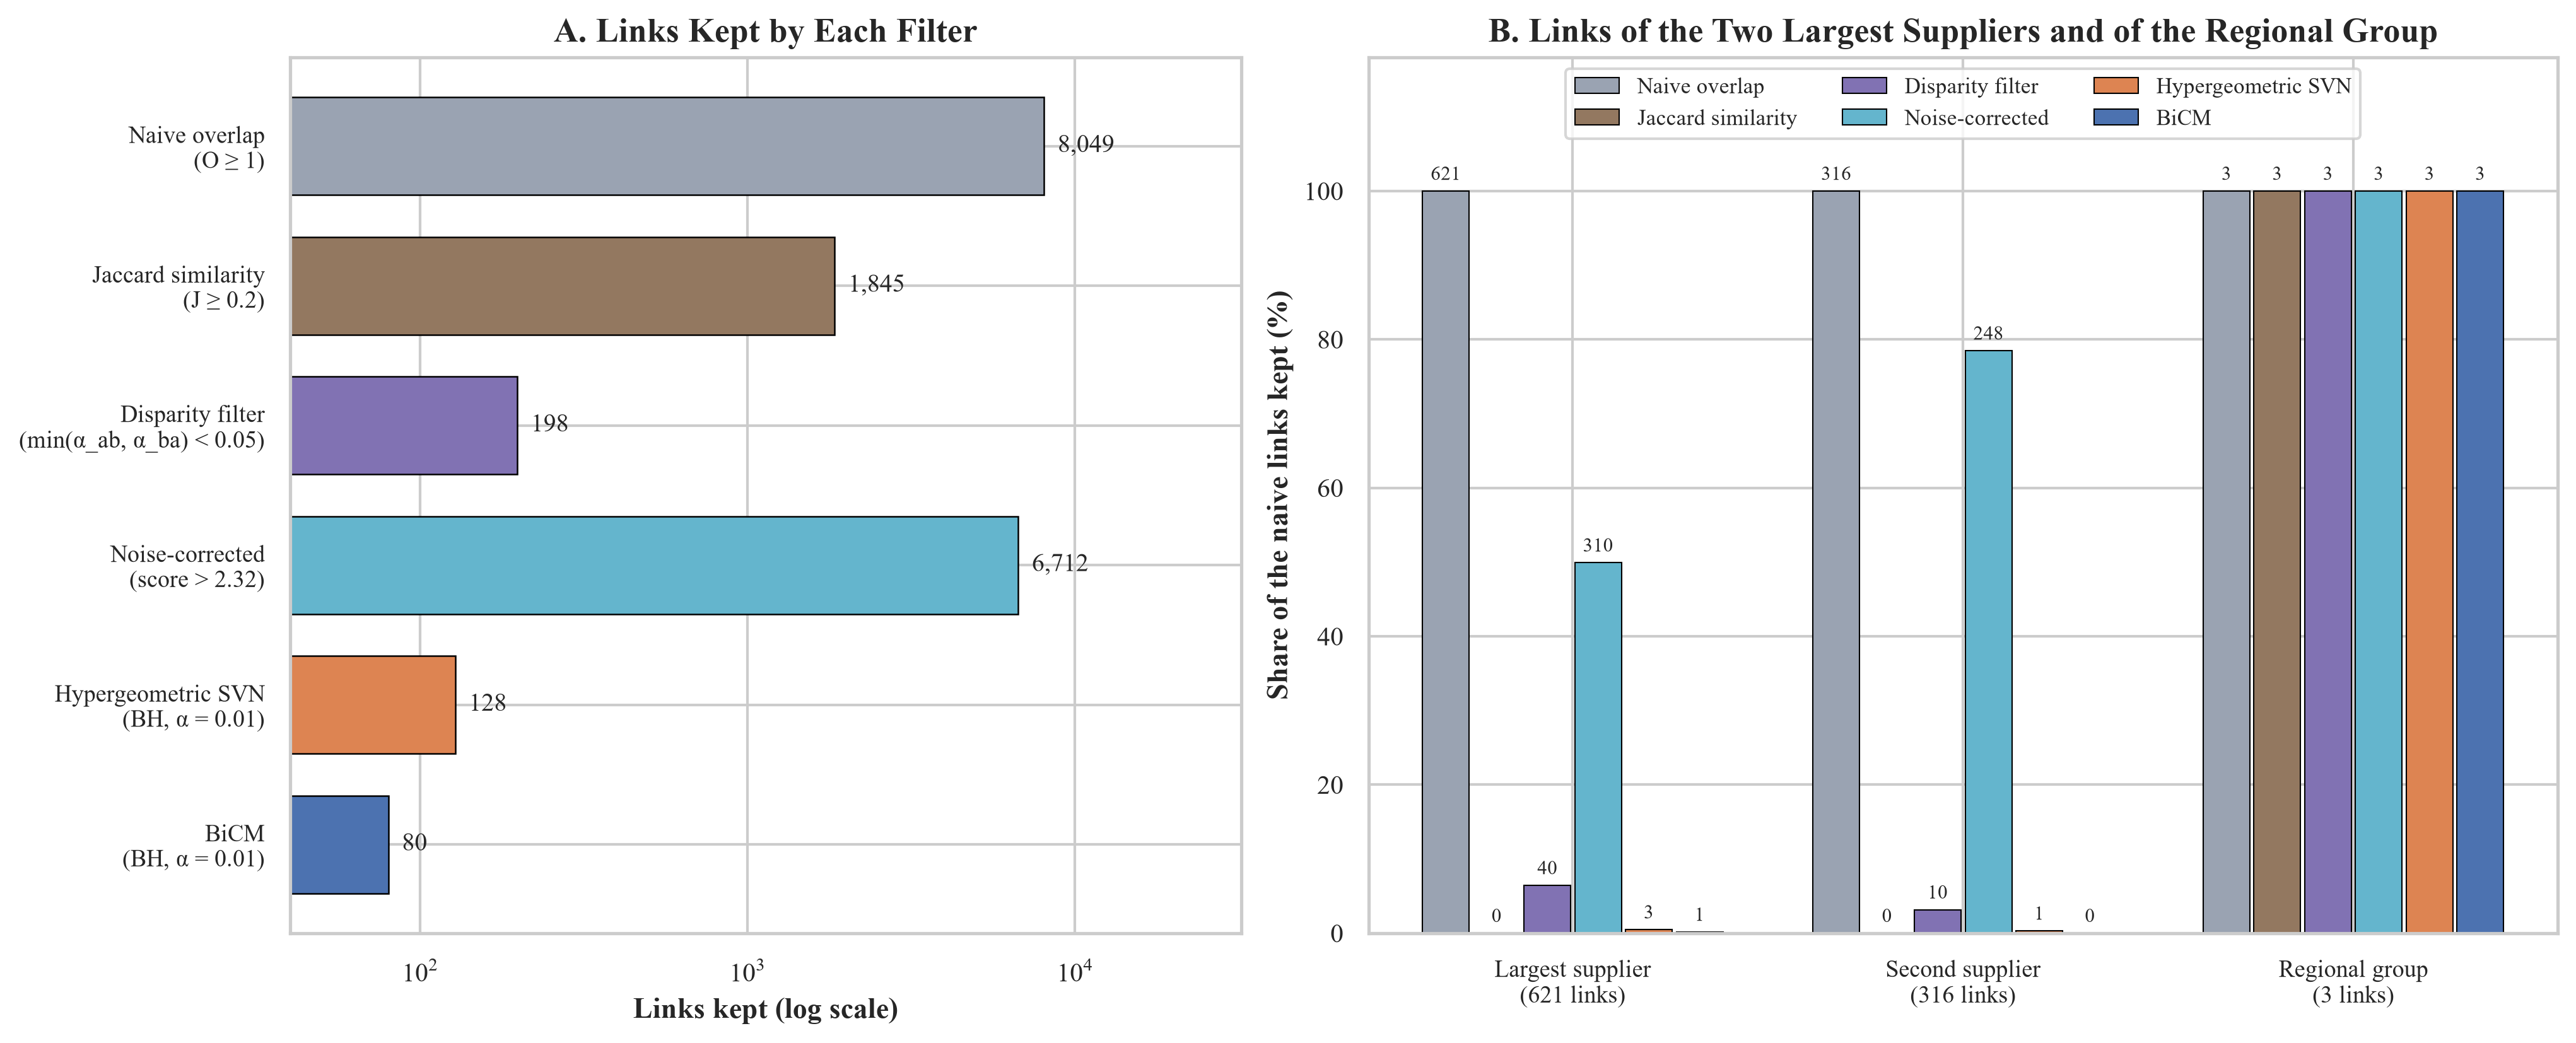

In [66]:
FILTER_COLORS: Final[dict[str, str]] = {
    "naive": "#9aa3b2", "jaccard": "#937860", "df": "#8172b3", "nc": "#64b5cd", "svn": "#dd8452", "bicm": "#4c72b0",
}
focus_sets = {
    f"Largest supplier\n({int(incident(panda_position).sum())} links)": incident(panda_position),
    f"Second supplier\n({int(incident(a1_position).sum())} links)": incident(a1_position),
    "Regional group\n(3 links)": inside_group,
}

fig_10_1, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(13.5, 5.4), constrained_layout=True, gridspec_kw={"width_ratios": [1, 1.25]})
positions = np.arange(len(filters))[::-1]
counts = np.array([int(kept.sum()) for kept in filters.values()])
ax_a.barh(positions, counts, color=[FILTER_COLORS[key] for key in filters], edgecolor="black", linewidth=0.6, height=0.7)
for position, count in zip(positions, counts):
    ax_a.text(count * 1.1, position, f"{count:,}", va="center", fontsize=9.5)
ax_a.set_xscale("log")
ax_a.set_xlim(40, counts.max() * 4)
ax_a.set_yticks(positions, [f"{FILTER_NAMES[key]}\n({FILTER_RULES[key]})" for key in filters], fontsize=9)
ax_a.set_xlabel("Links kept (log scale)")
ax_a.set_title("A. Links Kept by Each Filter")

width = 0.13
for offset, (key, kept) in enumerate(filters.items()):
    shares = np.array([100.0 * (kept & mask).sum() / mask.sum() for mask in focus_sets.values()])
    bars = ax_b.bar(np.arange(len(focus_sets)) + (offset - 2.5) * width, shares, width=width * 0.92, color=FILTER_COLORS[key],
                    edgecolor="black", linewidth=0.5, label=FILTER_NAMES[key])
    for bar, mask in zip(bars, focus_sets.values()):
        ax_b.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.5, f"{int((kept & mask).sum())}", ha="center", fontsize=7.5)
ax_b.set_xticks(np.arange(len(focus_sets)), list(focus_sets), fontsize=9)
ax_b.set_ylim(0, 118)
ax_b.set_ylabel("Share of the naive links kept (%)")
ax_b.set_title("B. Links of the Two Largest Suppliers and of the Regional Group")
ax_b.legend(ncol=3, loc="upper center", frameon=True, facecolor="white", edgecolor="#cccccc", fontsize=8.5)
plt.show()

**Figure 10.1.** Number of links kept by each of the six rules (panel A, logarithmic axis) and share of the naive links of the largest supplier, the second supplier and the regional group that each rule keeps (panel B).

*Source:* Calculation from ISUN 2020 (2026).

**Question.** For which pairs do the two null models disagree, and by how much?

**How to read.** Each point is a pair of suppliers with a shared school. The horizontal axis is $-\log_{10} p$ under the hypergeometric model, and the vertical axis is $-\log_{10} p$ under the BiCM. The dashed lines are the Benjamini–Hochberg critical values of the two tests, so that a point right of the vertical line is kept by the SVN and a point above the horizontal line is kept by the BiCM. The red rings are the three pairs of the regional group; two of them lie close together.

**What the figure is not.** The BiCM $p$-value of a pair cannot be smaller than what the degrees of the schools allow, so the points lie below the diagonal of equal $p$-values. The figure does not say which of the two models is closer to the truth, only where they differ.

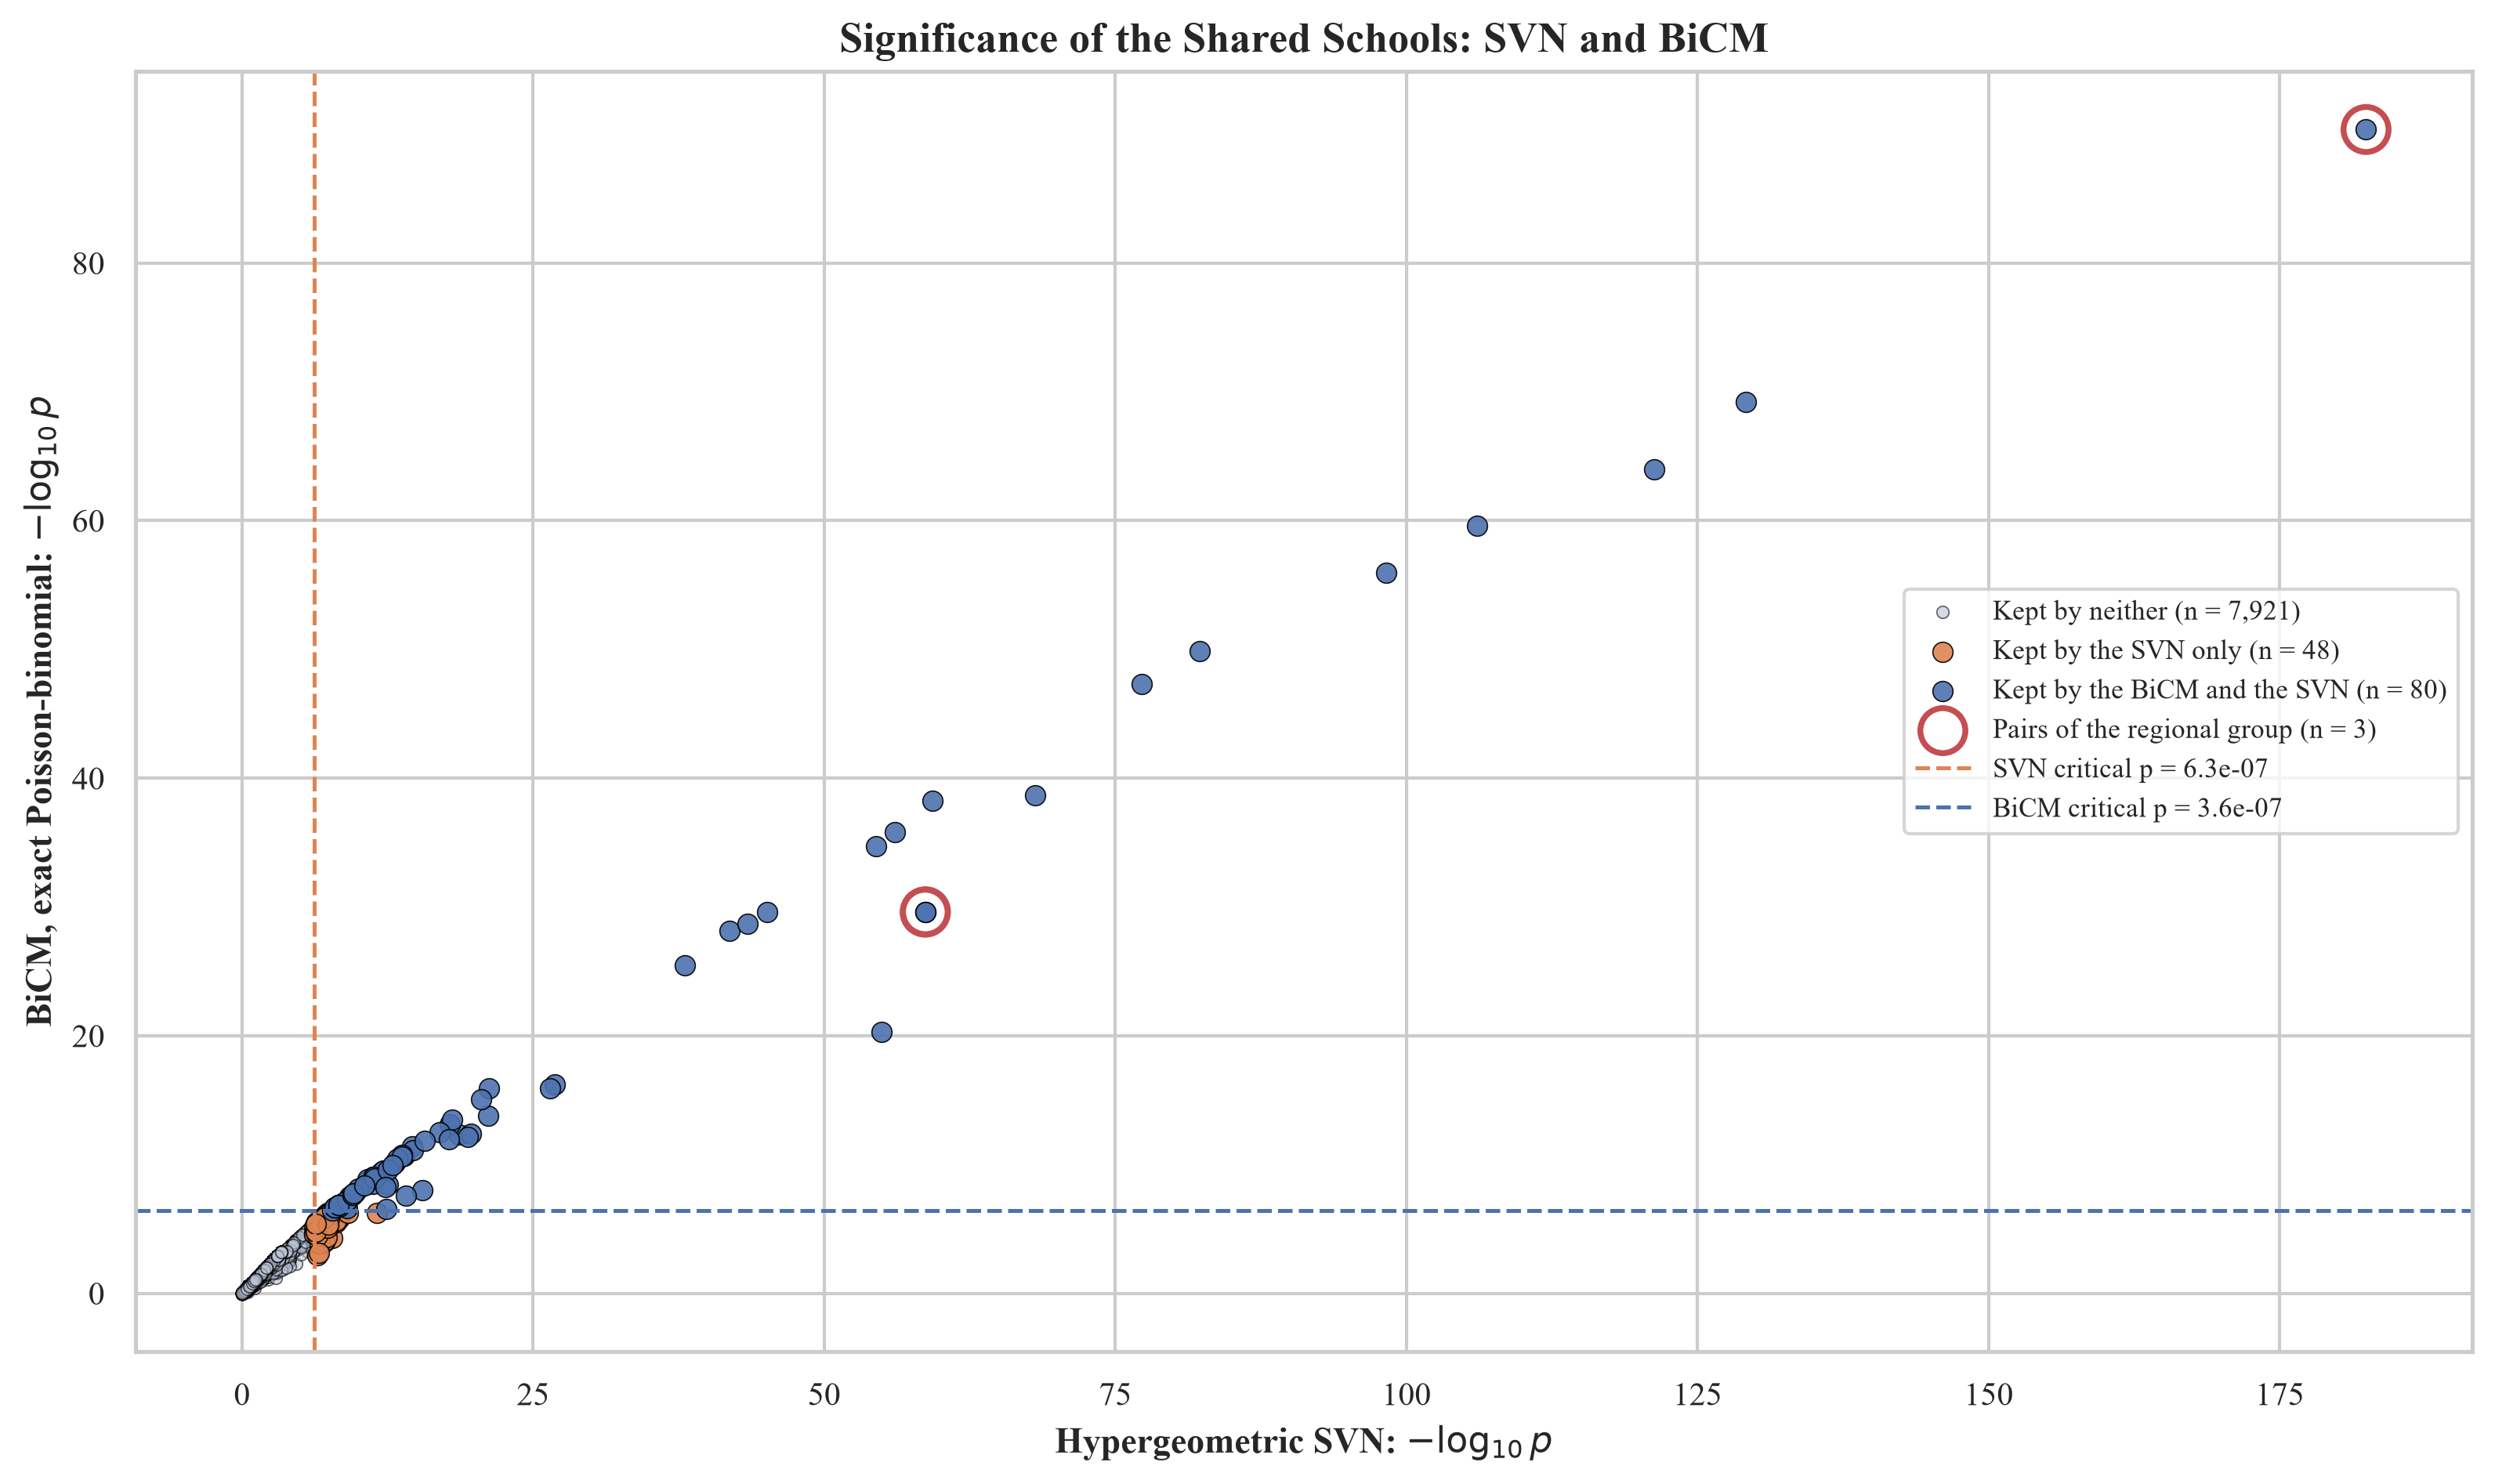

In [67]:
neg_log_hyp = -np.log10(np.maximum(p_hyp, 1e-300))
neg_log_bicm = -np.log10(p_bicm)
critical_hyp = float(p_hyp[svn_valid].max())
critical_bicm = float(p_bicm[bicm_valid].max())

fig_10_2, ax_10_2 = plt.subplots(figsize=(10.5, 6.2), constrained_layout=True)
tiers = (
    (~svn_valid & ~bicm_valid, "#b9c4d6", 14, 0.6, "Kept by neither"),
    (svn_valid & ~bicm_valid, "#dd8452", 38, 0.9, "Kept by the SVN only"),
    (bicm_valid, "#4c72b0", 38, 0.9, "Kept by the BiCM and the SVN"),
)
for mask, color, size, alpha, label in tiers:
    ax_10_2.scatter(neg_log_hyp[mask], neg_log_bicm[mask], color=color, s=size, alpha=alpha, edgecolor="black", linewidth=0.4,
                    label=f"{label} (n = {int(mask.sum()):,})")
ax_10_2.scatter(neg_log_hyp[inside_group], neg_log_bicm[inside_group], s=190, facecolor="none", edgecolor="#c44e52", linewidth=1.8,
                label="Pairs of the regional group (n = 3)")
ax_10_2.axvline(-np.log10(critical_hyp), color="#dd8452", linestyle="--", linewidth=1.2, label=f"SVN critical p = {critical_hyp:.1e}")
ax_10_2.axhline(-np.log10(critical_bicm), color="#4c72b0", linestyle="--", linewidth=1.2, label=f"BiCM critical p = {critical_bicm:.1e}")
ax_10_2.set_xlabel("Hypergeometric SVN: $-\\log_{10} p$")
ax_10_2.set_ylabel("BiCM, exact Poisson-binomial: $-\\log_{10} p$")
ax_10_2.set_title("Significance of the Shared Schools: SVN and BiCM")
ax_10_2.legend(loc="center right", frameon=True, facecolor="white", edgecolor="#cccccc", fontsize=8.5)
plt.show()

**Figure 10.2.** Significance of the shared schools of 8,049 pairs under the hypergeometric model and under the BiCM, with the Benjamini–Hochberg critical values at $\alpha = 0.01$.

*Source:* Calculation from ISUN 2020 (2026).

**Question.** What does each rule do to the neighbourhood of the two suppliers with most schools, and to the regional group?

**Why three panels.** The panels show the same nodes at the same places for the naive projection, the hypergeometric SVN and the BiCM. Each large supplier is drawn as a disc with its neighbours around it, and the neighbours with most shared schools are nearest to the centre.

**How to read.** A line joins a supplier to a neighbour whose link the rule keeps. A pale dot is a neighbour whose link is removed. The three nodes on the right are the regional group, and a red line is a link between two of them that the rule keeps.

**What the figure is not.** The layout carries no geography and no distance. The number of links that a large supplier keeps is a statement about the rule, not about the supplier.

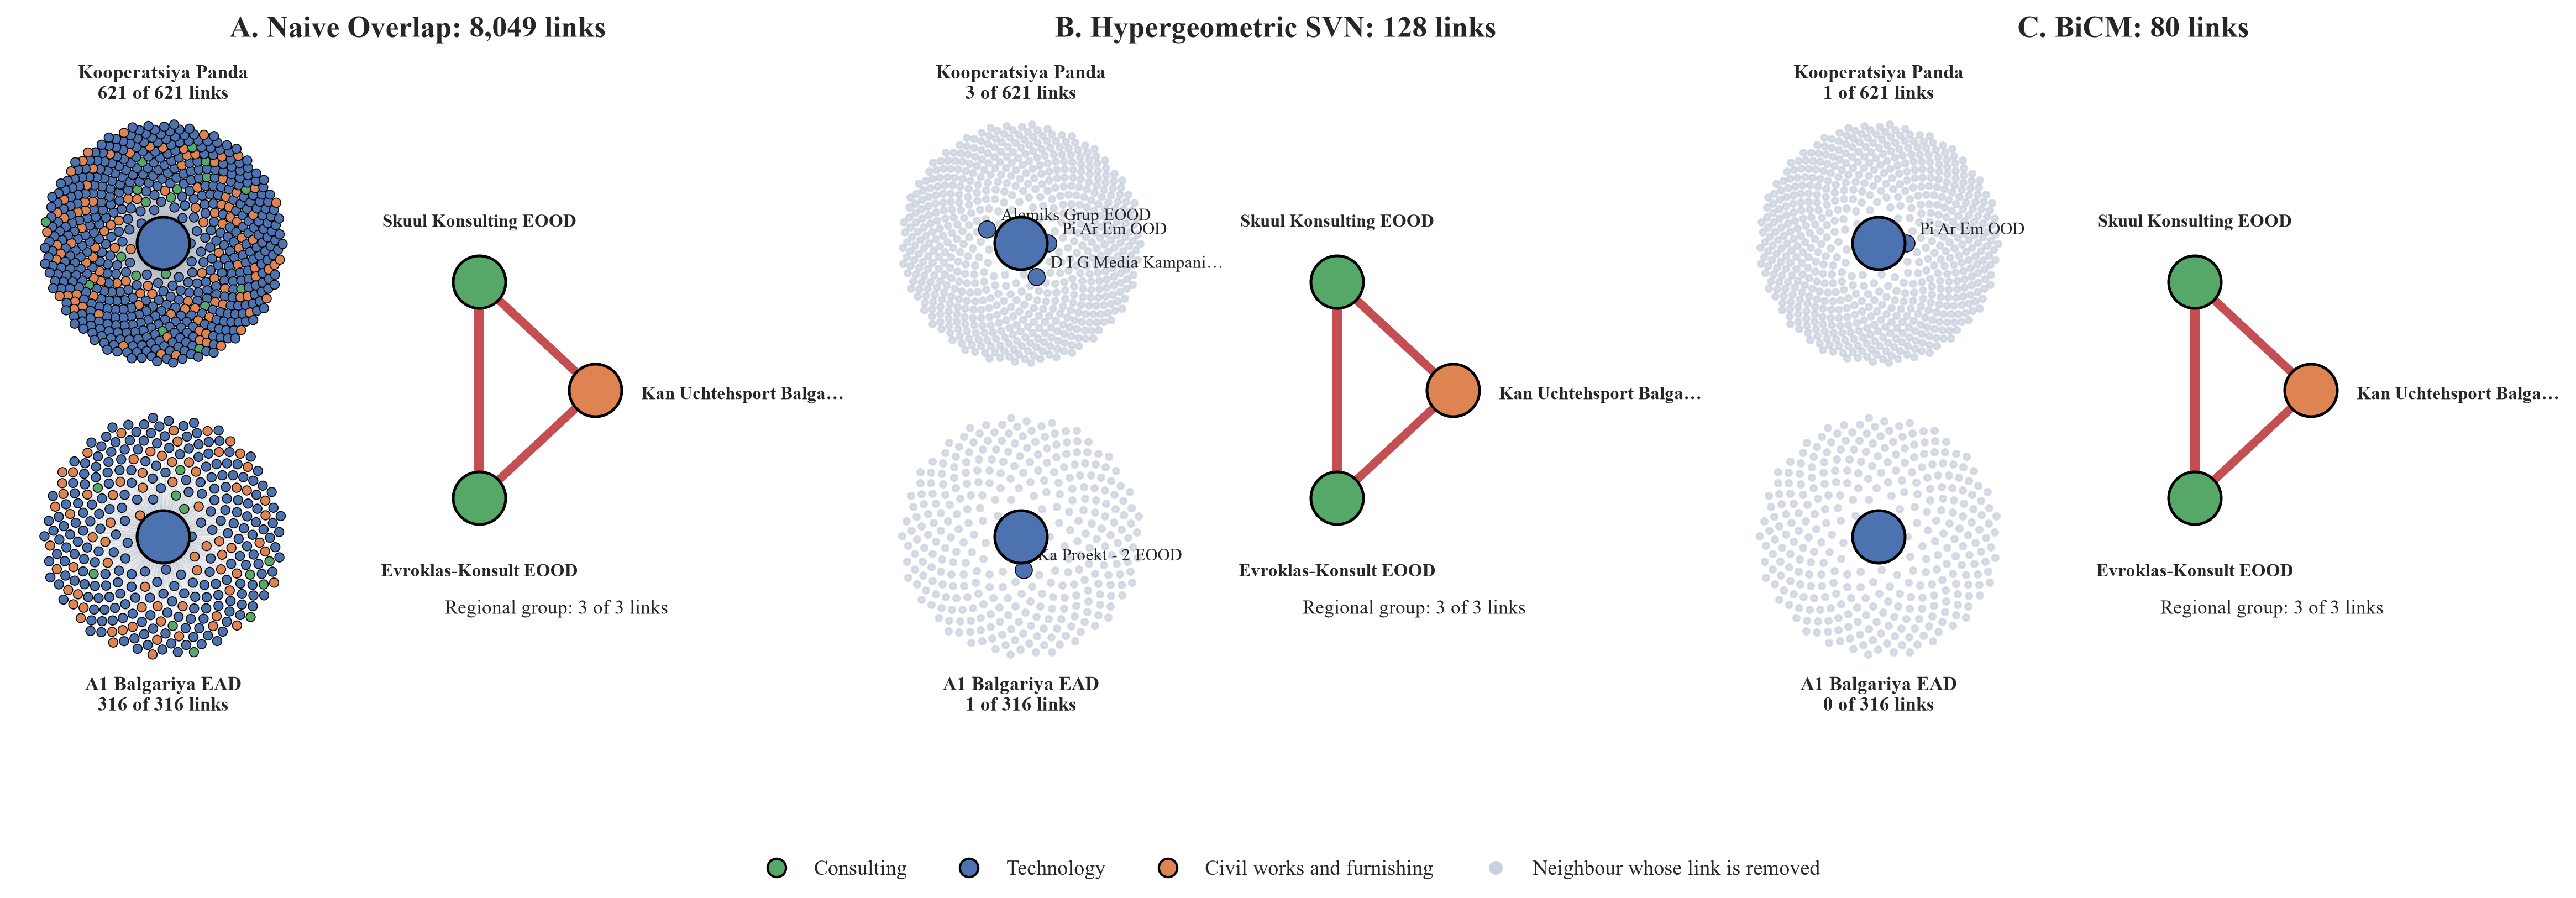

In [68]:
GOLDEN_ANGLE: Final[float] = np.pi * (3.0 - np.sqrt(5.0))
HUB_CENTRES: Final[dict[int, tuple[float, float]]] = {panda_position: (-1.05, 0.95), a1_position: (-1.05, -0.95)}
HUB_LABEL_SHIFT: Final[float] = 0.9
GROUP_CENTRES: Final[dict[int, tuple[float, float]]] = {group_a: (1.0, 0.7), group_b: (1.0, -0.7), group_c: (1.75, 0.0)}


def neighbourhood(position: int) -> tuple[np.ndarray, np.ndarray]:
    """The other suppliers of the pairs of a supplier, and the row of each pair in the pair table."""
    rows = np.flatnonzero(incident(position))
    return np.where(pair_a[rows] == position, pair_b[rows], pair_a[rows]), rows


def disc_positions(centre: tuple[float, float], count: int, radius: float = 0.78) -> np.ndarray:
    """Points of a sunflower spiral inside a disc around the supplier, so that every neighbour keeps its place in the three panels."""
    index = np.arange(count)
    distance = 0.16 + (radius - 0.16) * np.sqrt((index + 0.5) / max(count, 1))
    return np.column_stack([centre[0] + distance * np.cos(index * GOLDEN_ANGLE), centre[1] + distance * np.sin(index * GOLDEN_ANGLE)])


layouts = {}
for hub, centre in HUB_CENTRES.items():
    others, rows = neighbourhood(hub)
    order = np.argsort(-overlap[rows], kind="stable")  # the neighbours with most shared schools lie near the supplier
    layouts[hub] = (others[order], rows[order], disc_positions(centre, len(rows)))

fig_10_3, axes = plt.subplots(1, 3, figsize=(15.5, 5.8), constrained_layout=True)
panels = (("A. Naive Overlap", filters["naive"]), ("B. Hypergeometric SVN", svn_valid), ("C. BiCM", bicm_valid))
for ax, (title, kept) in zip(axes, panels):
    for hub, (others, rows, coordinates) in layouts.items():
        centre = np.array(HUB_CENTRES[hub])
        kept_here = kept[rows]
        for target, is_kept in ((coordinates[~kept_here], False), (coordinates[kept_here], True)):
            for end in target:
                if is_kept:
                    ax.plot([centre[0], end[0]], [centre[1], end[1]], color="#8c96a8", linewidth=0.9 if title[0] != "A" else 0.35,
                            alpha=0.9 if title[0] != "A" else 0.3, zorder=1)
        ax.scatter(*coordinates[~kept_here].T, s=7, color="#c9d1de", alpha=0.7, zorder=2)
        kept_roles = [ROLE_COLORS[vendor_table.at[int(n), "vendor_role"]] for n in others[kept_here]]
        ax.scatter(*coordinates[kept_here].T, s=16 if title[0] == "A" else 55, color=kept_roles, edgecolor="black", linewidth=0.4, zorder=3)
        if title[0] != "A":
            for other, end in zip(others[kept_here], coordinates[kept_here]):
                ax.annotate(short_label(int(other), 20), end, xytext=(6, 4), textcoords="offset points", fontsize=7.5)
        ax.scatter(*centre, s=520, color=ROLE_COLORS[vendor_table.at[hub, "vendor_role"]], edgecolor="black", linewidth=1.2, zorder=4)
        above = hub == panda_position
        ax.text(centre[0], centre[1] + (HUB_LABEL_SHIFT if above else -HUB_LABEL_SHIFT), f"{short_label(hub)}\n{int(kept_here.sum())} of {len(rows)} links",
                ha="center", va="bottom" if above else "top", fontsize=8.5, fontweight="bold", zorder=5)
    members = list(GROUP_CENTRES)
    for index, first in enumerate(members):
        for second in members[index + 1:]:
            row = pair_index(first, second)
            ax.plot(*zip(GROUP_CENTRES[first], GROUP_CENTRES[second]), color="#c44e52" if kept[row] else "#d9d9d9",
                    linestyle="-" if kept[row] else "--", linewidth=1.0 + overlap[row] / 40.0 if kept[row] else 1.0, zorder=1)
    for member, centre in GROUP_CENTRES.items():
        ax.scatter(*centre, s=520, color=ROLE_COLORS[vendor_table.at[member, "vendor_role"]], edgecolor="black", linewidth=1.2, zorder=4)
        ax.annotate(short_label(member, 22), centre, xytext=(20, -4) if centre[0] > 1.5 else (0, 24 if centre[1] >= 0 else -34),
                    textcoords="offset points", ha="left" if centre[0] > 1.5 else "center", fontsize=8, fontweight="bold", zorder=5,
                    bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.0))
    ax.text(1.5, -1.45, f"Regional group: {int((kept & inside_group).sum())} of 3 links", ha="center", fontsize=8.5)
    ax.set_title(f"{title}: {int(kept.sum()):,} links")
    ax.set_xlim(-2.0, 3.2)
    ax.set_ylim(-2.15, 2.2)
    ax.set_aspect("equal")
    ax.set_axis_off()
fig_10_3.legend(handles=[plt.Line2D([], [], marker="o", linestyle="", markerfacecolor=ROLE_COLORS[role], markeredgecolor="black", markersize=8,
                                   label=ROLE_NAMES[role]) for role in ROLE_COLORS]
               + [plt.Line2D([], [], marker="o", linestyle="", markerfacecolor="#c9d1de", markeredgecolor="#c9d1de", markersize=5,
                             label="Neighbour whose link is removed")], loc="outside lower center", ncol=4, frameon=False, fontsize=9)
plt.show()

**Figure 10.3.** Neighbourhood of the two suppliers with most schools and links of the regional group under the naive projection (panel A), the hypergeometric SVN (panel B) and the BiCM (panel C).

*Source:* Calculation from ISUN 2020 (2026).

**Question.** How selective is the noise-corrected backbone?

**How to read.** The histogram shows the score of every link, on a logarithmic count. The dashed line is the threshold $\delta = 2.32$; the links to its right are kept. The triangles mark the three links of the regional group.

**What the figure is not.** The score compares a link with the value that the strengths of its two ends predict. It does not account for the degrees of the schools, so a high score is not a $p$-value of the BiCM.

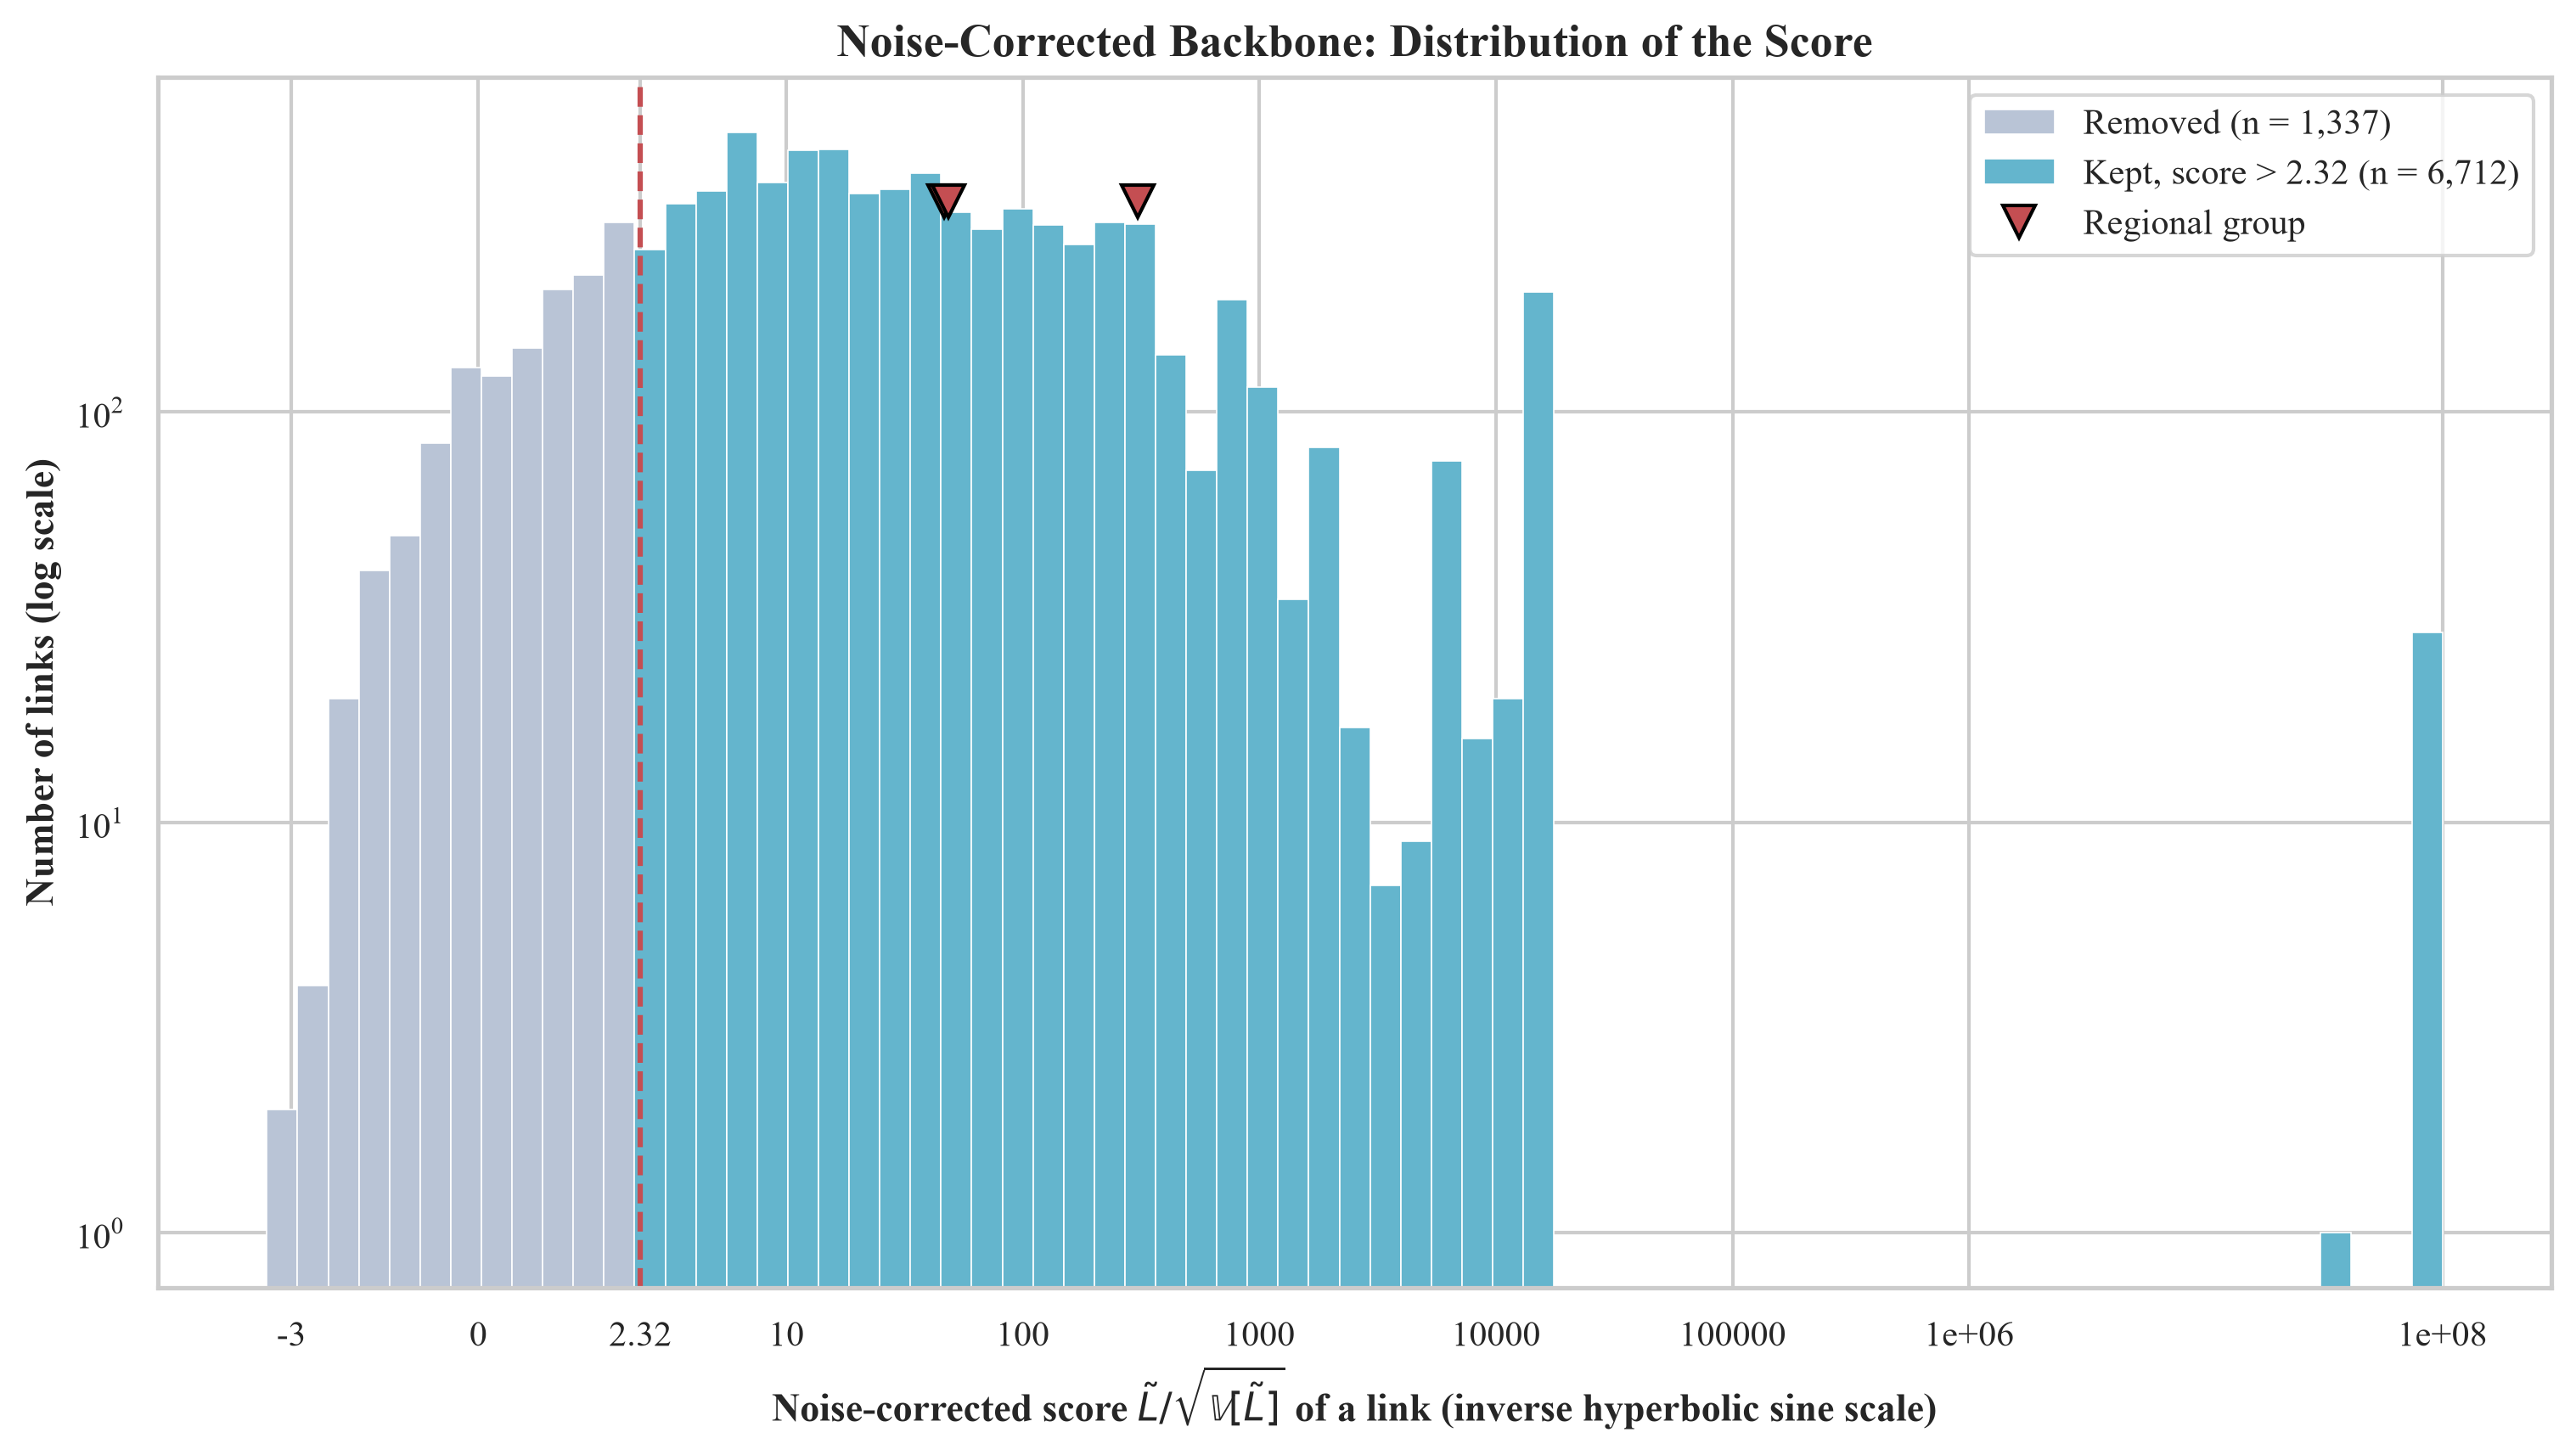

In [69]:
transformed = np.arcsinh(nc_score)  # roughly linear below 1 and logarithmic above, so that scores from -4 to 1e8 fit on one axis
bins = np.linspace(transformed.min(), transformed.max(), 72)

fig_10_4, ax_10_4 = plt.subplots(figsize=(10, 5.6), constrained_layout=True)
ax_10_4.hist(transformed[~nc_valid], bins=bins, color="#b9c4d6", edgecolor="white", linewidth=0.4, label=f"Removed (n = {int((~nc_valid).sum()):,})")
ax_10_4.hist(transformed[nc_valid], bins=bins, color=FILTER_COLORS["nc"], edgecolor="white", linewidth=0.4,
             label=f"Kept, score > {NC_DELTA} (n = {int(nc_valid.sum()):,})")
ax_10_4.axvline(np.arcsinh(NC_DELTA), color="#c44e52", linestyle="--", linewidth=1.5)
ax_10_4.set_yscale("log")
tick_values = np.array([-3, 0, NC_DELTA, 10, 100, 1e3, 1e4, 1e5, 1e6, 1e8])
tick_values = tick_values[(tick_values >= nc_score.min()) & (tick_values <= nc_score.max())]
ax_10_4.set_xticks(np.arcsinh(tick_values), [f"{value:g}" for value in tick_values])
ax_10_4.set_xlabel("Noise-corrected score $\\tilde{L} / \\sqrt{\\mathbb{V}[\\tilde{L}]}$ of a link (inverse hyperbolic sine scale)")
ax_10_4.set_ylabel("Number of links (log scale)")
ax_10_4.set_title("Noise-Corrected Backbone: Distribution of the Score")
top = ax_10_4.get_ylim()[1]
for index, (first, second) in enumerate(((group_a, group_b), (group_a, group_c), (group_b, group_c))):
    ax_10_4.plot([np.arcsinh(nc_score[pair_index(first, second)])], [top * 0.5], marker="v", color="#c44e52", markersize=9, markeredgecolor="black",
                 linestyle="", label="Regional group" if index == 0 else None)
ax_10_4.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="#cccccc")
plt.show()

**Figure 10.4.** Distribution of the noise-corrected score of the 8,049 links, with the threshold $\delta = 2.32$.

*Source:* Calculation from ISUN 2020 (2026).

### 10.9 Privacy and Summary of the Checks

The cell below checks the table of the validated links for personal data and repeats the main invariants of the section: the number of tests, the convergence of the BiCM and its degree constraints, the range of the $p$-values, the equivalence of the adjusted values and the decisions, the nesting of the thresholds and the agreement of the exact tail with the convolution. It fails if one of them is violated.

In [70]:
edge_table = read_work_csv(OUT_EDGES)
assert not FORBIDDEN_HEADERS.intersection(edge_table.columns), f"{OUT_EDGES} contains a personal data column"
for column in edge_table.columns:
    assert not edge_table[column].str.fullmatch(r"\d{10}").any(), f"{OUT_EDGES}: column {column!r} holds a ten-digit number"
assert not edge_table[["vendor_a_name", "vendor_b_name"]].stack().str.contains(r"(?<!\w)ЕТ(?!\w)|Адвокат").any()
assert list(edge_table.columns) == EDGE_COLUMNS and len(edge_table) == n_pairs
print(f"Privacy check passed for {OUT_EDGES.as_posix()}: no personal data columns, no ten-digit numbers, no sole trader names.")

# mathematical invariants of the tests
assert N_TESTS == 1_539_135 and n_pairs == 8049
assert bicm.converged and bicm.residual < 1e-4 and np.allclose(P.sum(axis=1), school_degree, atol=1e-3) and np.allclose(P.sum(axis=0), vendor_degree, atol=1e-3)
assert ((p_hyp >= 0) & (p_hyp <= 1)).all() and ((p_bicm > 0) & (p_bicm <= 1)).all() and ((p_df >= 0) & (p_df <= 1)).all()
assert np.array_equal(svn_valid, q_hyp <= ALPHA) and np.array_equal(bicm_valid, q_bicm <= ALPHA)
assert (bicm_bonferroni <= bicm_valid).all() and (svn_bonferroni <= svn_valid).all()  # Bonferroni keeps a subset of the Benjamini-Hochberg links
print(f"Tests: the BiCM reproduces the degrees of all {n_active_schools:,} schools and {N_V:,} suppliers (largest residual {bicm.residual:.1e}); "
      f"the Benjamini-Hochberg links are the pairs with q at most {ALPHA}, and the Bonferroni links are a subset of them.")

# the filters are nested as the theory says: a link kept at a stricter level is kept at a looser one
assert (nc_score > 3.0).sum() <= nc_valid.sum() and (p_df < 0.01).sum() <= df_valid.sum() and (jaccard >= 0.5).sum() <= jaccard_valid.sum()
assert (filters["naive"].sum() == n_pairs) and all(kept.sum() <= n_pairs for kept in filters.values())
print("Ablation: the six filters keep between "
      f"{int(min(kept.sum() for kept in filters.values())):,} and {n_pairs:,} of the {n_pairs:,} links; stricter thresholds keep fewer links.")

# the p-value of a pair agrees with the tail of the convolution of its Bernoulli distribution, also where the Fourier tail is unresolved
checked = [int(np.argmax(overlap)), int(np.argmin(p_bicm)), n_pairs // 3, int(np.flatnonzero(~refined & (p_bicm < 1e-5))[0]), int(np.flatnonzero(~refined)[-1])]
for row in checked:
    reference_tail = float(pb.convolution_pmf(pair_a[row], pair_b[row])[overlap[row]:].sum())
    assert abs(reference_tail - p_bicm[row]) <= 1e-6 * reference_tail + 1e-13, f"Exact p-value differs from the convolution for row {row}"
print(f"Exact Poisson-binomial p-values agree with the convolution for {len(checked)} pairs, among them the pair with the smallest p-value.")

Privacy check passed for data/derived/validated_edges.csv: no personal data columns, no ten-digit numbers, no sole trader names.
Tests: the BiCM reproduces the degrees of all 2,223 schools and 1,755 suppliers (largest residual 4.3e-11); the Benjamini-Hochberg links are the pairs with q at most 0.01, and the Bonferroni links are a subset of them.
Ablation: the six filters keep between 80 and 8,049 of the 8,049 links; stricter thresholds keep fewer links.
Exact Poisson-binomial p-values agree with the convolution for 5 pairs, among them the pair with the smallest p-value.


## 11. Neutrality Statement & Epistemic Disclaimer

The following principles apply to all results of this notebook:
1. **Risk Indicators vs. Judicial Findings:** Statistical anomalies, bunching below thresholds and clusters in the buyer-supplier network identified in this notebook are **diagnostic risk indicators**. They do not constitute formal judicial determinations of illegality, cartel operation, or statutory violations.
2. **Confidentiality & Privacy:** In accordance with the General Data Protection Regulation (European Union, 2016), all personal identifying details (such as Unified Civil Numbers / EGN, personal physical addresses, and personal contact numbers) are strictly excluded from all code, configurations, logs, and derived datasets. Public officials are referenced exclusively by their institutional role and institutional identifiers.


## References

1. **ADFI (2026)**. *Public Register of Reports from State Financial Inspections Conducted under Art. 17 of the State Financial Inspection Act*. Sofia: State Financial Inspection Agency. [online] Available at: https://www.adfi.minfin.bg/bg/34 [Accessed: 1 November 2026].

2. **Bulgaria (2016)**. *Public Procurement Act* (Закон за обществените поръчки). State Gazette, No. 13, 16 February 2016, Art. 20(4) in the wording in force until 31 December 2023.

3. **Bulgaria (2023)**. *Public Procurement Act* (Закон за обществените поръчки). State Gazette, No. 13, 16 February 2016, Art. 20(4) as amended by State Gazette, No. 88, 20 October 2023, in force from 1 January 2024.

4. **Coscia, M. and Neffke, F.M.H. (2017)**. 'Network backboning with noisy data', in *2017 IEEE International Conference on Big Data (Big Data)*. Boston, MA: IEEE, pp. 2848–2857. [online] Available at: https://arxiv.org/pdf/1701.07336.pdf [Accessed: 1 November 2026]. doi: [10.1109/BigData.2017.8258252](https://doi.org/10.1109/BigData.2017.8258252).

5. **European Union (2016)**. *Regulation (EU) 2016/679 of the European Parliament and of the Council of 27 April 2016 on the protection of natural persons with regard to the processing of personal data and on the free movement of such data (General Data Protection Regulation)*. Official Journal of the European Union, L 119, 4 May 2016, pp. 1–88.

6. **ISUN 2020 (2026)**. *Single Information Web Portal for General Information on the Management of EU Structural and Cohesion Funds in the Republic of Bulgaria: Open Data Module*. Sofia: Ministry of Finance. [online] Available at: https://2020.eufunds.bg/bg/0/0/OpenData [Accessed: 1 November 2026].

7. **Miller, S.J. and Nigrini, M.J. (2006)**. *Order Statistics and Benford's Law*. [online] arXiv:math/0601344v5 [math.PR]. Available at: https://arxiv.org/pdf/math/0601344.pdf [Accessed: 1 November 2026].

8. **OECD (2016)**. *Preventing Corruption in Public Procurement*. Paris: OECD Publishing. [online] Available at: https://www.oecd.org/content/dam/oecd/en/topics/policy-sub-issues/integrity-in-public-procurement/corruption-public-procurement-brochure.pdf [Accessed: 1 November 2026].

9. **Palguta, J. and Pertold, F. (2017)**. 'Manipulation of procurement contracts: Evidence from the introduction of discretionary thresholds', *American Economic Journal: Economic Policy*, 9(2), pp. 293–319. [online] Available at: https://www.cerge-ei.cz/pdf/wp/Wp501.pdf [Accessed: 1 November 2026]. doi: [10.1257/pol.20150511](https://doi.org/10.1257/pol.20150511).

10. **Saracco, F., Straka, M.J., Di Clemente, R., Gabrielli, A., Caldarelli, G. and Squartini, T. (2017)**. 'Inferring monopartite projections of bipartite networks: an entropy-based approach', *New Journal of Physics*, 19(5), p. 053022. [online] Available at: https://arxiv.org/pdf/1607.02481.pdf [Accessed: 1 November 2026]. doi: [10.1088/1367-2630/aa6b38](https://doi.org/10.1088/1367-2630/aa6b38).

11. **Szűcs, F. (2024)**. 'Discretion and favoritism in public procurement', *Journal of the European Economic Association*, 22(1), pp. 117–160. doi: [10.1093/jeea/jvad017](https://doi.org/10.1093/jeea/jvad017).

12. **Tumminello, M., Miccichè, S., Lillo, F., Piilo, J. and Mantegna, R.N. (2011)**. 'Statistically validated networks in bipartite complex systems', *PLoS ONE*, 6(3), p. e17994. [online] Available at: https://arxiv.org/pdf/1008.1414.pdf [Accessed: 1 November 2026]. doi: [10.1371/journal.pone.0017994](https://doi.org/10.1371/journal.pone.0017994).

13. **Wachs, J. and Kertész, J. (2019)**. 'A network approach to cartel detection in public auction markets', *Scientific Reports*, 9(1), p. 10818. [online] Available at: https://arxiv.org/pdf/1906.08667.pdf [Accessed: 1 November 2026]. doi: [10.1038/s41598-019-47198-1](https://doi.org/10.1038/s41598-019-47198-1).

14. **Wachs, J., Fazekas, M. and Kertész, J. (2021)**. 'Corruption risk in contracting markets: a network science perspective', *International Journal of Data Science and Analytics*, 12(1), pp. 45–60. [online] Available at: https://arxiv.org/pdf/1909.08664.pdf [Accessed: 1 November 2026]. doi: [10.1007/s41060-019-00204-1](https://doi.org/10.1007/s41060-019-00204-1).
